**Integrantes**: *Marco Antonio Aragon Vivas, Juan David Reyes Burbano, Maria Paula Pinillo Olave, María José Suárez Toro, Laura Daniela Astudillo Ortega.*

# Proyecto 2. Sistema de detección, segmentación y clasificación de fracturas pélvicas mediante tomografía computarizada

**Sistema PENGWIN 2.5D multitarea**
> Uso académico: el modelo no ha sido validado clínicamente y no debe utilizarse para tomar decisiones quirúrgicas reales.

Las fracturas pélvicas pueden generar varios fragmentos óseos, por lo que identificarlos y medir su separación es una tarea importante para el análisis de estas lesiones. En este proyecto trabajamos con el dataset PENGWIN Task 1 (CT), presentado en el challenge MICCAI 2024, para desarrollar un sistema que permita analizar tomografías computarizadas de la pelvis.

El objetivo es detectar las regiones óseas (sacro, coxal izquierdo y coxal derecho), segmentar los fragmentos de cada región, clasificarlos según el hueso al que pertenecen y calcular la distancia entre los fragmentos secundarios y el fragmento principal en milímetros.

Para esto desarrollamos un modelo multitarea con una entrada 2.5D, que utiliza varios cortes de la tomografía para incorporar información de los cortes vecinos. Los resultados se integran en una aplicación web que permite visualizar las predicciones por corte y la reconstrucción tridimensional de los fragmentos.

---

## 0. Preparación

En esta sección importamos las librerías que vamos a utilizar durante el proyecto y definimos las rutas de las imágenes, las etiquetas y el caché. También establecemos los nombres y colores de las tres regiones óseas: sacro, coxal izquierdo y coxal derecho. Estos colores se mantienen en las visualizaciones del notebook y en la aplicación.

Antes de continuar, comprobamos que las imágenes y sus etiquetas estén disponibles y que ambos conjuntos contengan los mismos casos. La verificación encontró **100 casos con imagen y etiqueta**, por lo que podemos continuar con la preparación de los datos.

In [ ]:
import json
import os
import subprocess
import sys
import time
from pathlib import Path

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk
from matplotlib.patches import Rectangle
from scipy import ndimage

RAIZ = Path.cwd()
IMAGES = RAIZ / "data" / "raw" / "images"
LABELS = RAIZ / "data" / "raw" / "labels"
CACHE = RAIZ / "data" / "cache"

HUESO = {1: "sacro", 2: "coxal izquierdo", 3: "coxal derecho"}
COLOR = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}
FRAG = {1: "n_frag_sa", 2: "n_frag_lh", 3: "n_frag_rh"}
NEUTRO, GRIS, TINTA = "#52514e", "#c3c2b7", "#0b0b0b"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
})

casos = sorted(p.stem for p in IMAGES.glob("*.mha"))
assert casos and casos == sorted(p.stem for p in LABELS.glob("*.mha")), "Faltan datos: ver data/README.md"
print(f"{len(casos)} casos con imagen y etiqueta en {IMAGES.parent}")

100 casos con imagen y etiqueta en C:\Users\usuario\Desktop\Analitica carlos\proyecto\entregas\entrega final\data\raw


---

# Capítulo 1 · Exploración y preparación de los datos

Antes de diseñar ningún modelo hay que saber qué hay en los datos y convertirlos en algo que una red pueda leer: 31 GB de volúmenes en formatos, escalas y orientaciones distintos tienen que acabar en cortes 256×256, todos en la misma escala física y la misma orientación, que se lean al azar en milisegundos. El capítulo lo hace en cuatro pasos:

1. **Explorar los archivos y sus características** (1.1–1.7): qué trae cada archivo, qué significa su etiqueta y qué problemas esconde (ejes invertidos, escalas distintas, pacientes girados, cortes sin pelvis). Cada problema termina en una regla para el preprocesado.
2. **Construir el caché** (1.8–1.11): el preprocesado vive en `build_cache.py`; aquí se prueba sobre una muestra con las funciones del propio script y se verifica sobre los 100 casos.
3. **Definir la entrada del modelo** (1.12): tres ventanas de Hounsfield por corte y una pila de cortes vecinos.
4. **Analizar los datos y establecer las decisiones de diseño** (1.13–1.14): ocho análisis, cada uno con la decisión que justifica, y la partición por paciente.

## 1.1. Revisión de los archivos y sus cabeceras

Antes de procesar las tomografías, revisamos las cabeceras de las imágenes y sus máscaras para conocer sus dimensiones, el espaciado de los vóxeles y la orientación. Esta información es necesaria para comprobar que ambas estén alineadas y para calcular distancias en milímetros más adelante.

Para hacerlo, leemos las cabeceras sin cargar los vóxeles completos, lo que permite revisar los 100 casos de forma rápida.

In [ ]:
def cabecera(ruta: Path) -> dict:
    r = sitk.ImageFileReader()
    r.SetFileName(str(ruta))
    r.ReadImageInformation()
    return {
        **dict(zip(("nz", "ny", "nx"), r.GetSize()[::-1])),
        **dict(zip(("sz", "sy", "sx"), r.GetSpacing()[::-1])),
        "direccion": tuple(int(round(v)) for v in r.GetDirection()),
        "tipo": sitk.GetPixelIDValueAsString(r.GetPixelID()),
    }

def gb(carpeta: Path) -> float:
    return sum(p.stat().st_size for p in carpeta.glob("*.mha")) / 1024**3

t0 = time.perf_counter()
cab = pd.DataFrame.from_dict({c: cabecera(IMAGES / f"{c}.mha") for c in casos}, orient="index")
cab_lab = pd.DataFrame.from_dict({c: cabecera(LABELS / f"{c}.mha") for c in casos}, orient="index")
cab.index.name = "case_id"
t_cab = time.perf_counter() - t0

geometria = ["nz", "ny", "nx", "sz", "sy", "sx"]
misma = (np.isclose(cab[geometria].to_numpy(float), cab_lab[geometria].to_numpy(float), atol=1e-4).all(axis=1)
         & (cab.direccion == cab_lab.direccion).to_numpy())

print(f"{2 * len(casos)} cabeceras leídas en {t_cab:.2f} s, sin cargar un solo vóxel")
print(f"Imagen y etiqueta con la misma geometría: {misma.sum()} de {len(casos)} casos")
print(f"Tipo de dato en disco: imágenes {', '.join(cab.tipo.unique())} · etiquetas {', '.join(cab_lab.tipo.unique())}")
print(f"Tamaño en disco: imágenes {gb(IMAGES):.1f} GB · etiquetas {gb(LABELS):.1f} GB")
cab.drop(columns="tipo").head()

200 cabeceras leídas en 0.68 s, sin cargar un solo vóxel
Imagen y etiqueta con la misma geometría: 100 de 100 casos
Tipo de dato en disco: imágenes 32-bit signed integer, 16-bit signed integer · etiquetas 16-bit signed integer, 8-bit unsigned integer
Tamaño en disco: imágenes 18.8 GB · etiquetas 12.6 GB


,nz,ny,nx,sz,sy,sx,direccion
case_id,,,,,,,
001,401,512,512,0.8,0.781250,0.781250,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"
002,337,276,413,0.8,0.824219,0.824219,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
003,285,381,512,1.0,0.759766,0.759766,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
004,224,254,386,1.0,0.843750,0.843750,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)"
005,312,512,512,1.0,0.896484,0.896484,"(1, 0, 0, 0, 1, 0, 0, 0, 1)"


Los resultados muestran que los 100 casos tienen la misma geometría entre la imagen y su máscara. Sin embargo, las dimensiones, el espaciado y la orientación varían entre pacientes, por lo que será necesario tenerlos en cuenta durante el preprocesamiento. También observamos que las imágenes y las etiquetas utilizan distintos tipos de dato y ocupan aproximadamente 18,8 GB y 12,6 GB, respectivamente.

Los archivos están en formato `.mha` (MetaImage), aunque el enunciado menciona NIfTI. Esto no impide obtener el espaciado físico desde la cabecera, que es el dato necesario para las mediciones. Además, la comprobación realizada en esta sección se limita a las dimensiones, el espaciado y la dirección; el código de lectura de cada caso vuelve a verificar la geometría, incluido el origen.

## 1.2. Revisión de un caso

Para entender cómo están almacenadas las imágenes y sus etiquetas, cargamos el caso `001` y revisamos sus dimensiones, tipos de dato y valores de la máscara. También convertimos la imagen a `int16` y la etiqueta a `uint8` para reducir el espacio de memoria sin perder la información necesaria.

In [ ]:
caso = "001"
t0 = time.perf_counter()
img_sitk = sitk.ReadImage(str(IMAGES / f"{caso}.mha"))
lab_sitk = sitk.ReadImage(str(LABELS / f"{caso}.mha"))
t_lectura = time.perf_counter() - t0
img = sitk.GetArrayFromImage(img_sitk)               
lab = sitk.GetArrayFromImage(lab_sitk)

print(f"Leer imagen y etiqueta: {t_lectura:.1f} s")
print(f"imagen  : {img.dtype}, forma {img.shape} (z, y, x), {img.nbytes / 1024**2:,.0f} MB · HU de {img.min()} a {img.max()}")
print(f"etiqueta: {lab.dtype}, forma {lab.shape}, {lab.nbytes / 1024**2:,.0f} MB · valores {np.unique(lab).tolist()}")
img, lab = img.astype(np.int16), lab.astype(np.uint8)
print(f"\nEn int16 la imagen cabe entera (±32.767) y ocupa {img.nbytes / 1024**2:,.0f} MB; "
      f"en uint8 la etiqueta (0–255) ocupa {lab.nbytes / 1024**2:,.0f} MB.")

Leer imagen y etiqueta: 0.5 s
imagen  : int32, forma (401, 512, 512) (z, y, x), 401 MB · HU de -1023 a 2775


etiqueta: int16, forma (401, 512, 512), 200 MB · valores [0, 1, 11, 12, 21]

En int16 la imagen cabe entera (±32.767) y ocupa 200 MB; en uint8 la etiqueta (0–255) ocupa 100 MB.


La máscara utiliza valores numéricos para identificar los fragmentos óseos. Las etiquetas se organizan de la siguiente manera:

- **0:** fondo, no corresponde a ningún fragmento óseo.
- **1–10:** fragmentos del sacro.
- **11–20:** fragmentos del coxal izquierdo.
- **21–30:** fragmentos del coxal derecho.

Cada etiqueta permite identificar el hueso y el fragmento al que pertenece cada vóxel. Para separar esta información, utilizamos dos funciones: `a_hueso()` y `a_fragmento()`.

Para una etiqueta \(L > 0\), el macro-hueso se obtiene con:

$$
\text{Macro-hueso} = \left\lfloor \frac{L-1}{10} \right\rfloor + 1
$$

El índice del fragmento se calcula mediante:

$$
\text{Índice del fragmento} = (L-1) \bmod 10
$$

El índice del fragmento comienza en 0. El fondo se trata por separado, ya que las fórmulas solo se aplican a etiquetas mayores que cero. Así podemos identificar cada región anatómica y sus fragmentos sin modificar las etiquetas originales.

In [ ]:
def a_hueso(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) // 10 + 1, 0).astype(np.uint8)

def a_fragmento(lab: np.ndarray) -> np.ndarray:
    lab = lab.astype(np.int16)
    return np.where(lab > 0, (lab - 1) % 10, 255).astype(np.uint8)

valores, voxeles = np.unique(lab, return_counts=True)
pd.DataFrame({"macro-hueso": [HUESO[h] for h in a_hueso(valores[1:])],
              "fragmento dentro del hueso": a_fragmento(valores[1:]),
              "vóxeles": voxeles[1:]},
             index=pd.Index(valores[1:], name="etiqueta"))

,macro-hueso,fragmento dentro del hueso,vóxeles
etiqueta,,,
1,sacro,0,458539
11,coxal izquierdo,0,762194
12,coxal izquierdo,1,63957
21,coxal derecho,0,844349


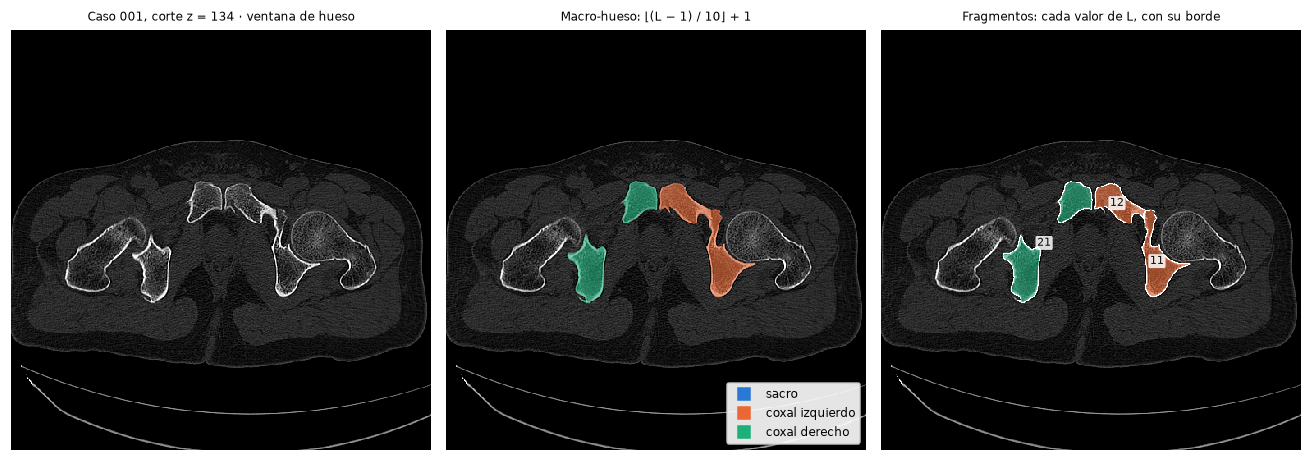

In [ ]:
def mostrar_corte(ax, hu2d, lab2d=None, titulo="", fragmentos=False):
    ax.imshow(np.clip(hu2d, -200, 1300), cmap="gray", interpolation="nearest")
    if lab2d is not None and lab2d.any():
        h = a_hueso(lab2d)
        capa = np.zeros((*lab2d.shape, 4))
        for k, c in COLOR.items():
            capa[h == k] = (*mcolors.to_rgb(c), 0.6)
        if fragmentos:
            borde = (ndimage.grey_dilation(lab2d, size=3) != ndimage.grey_erosion(lab2d, size=3)) & (lab2d > 0)
            capa[borde] = (1, 1, 1, 1)
            for v in np.unique(lab2d[lab2d > 0]):
                cy, cx = ndimage.center_of_mass(lab2d == v)
                ax.text(cx, cy, str(v), fontsize=7, ha="center", va="center", color=TINTA,
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
        ax.imshow(capa, interpolation="nearest")
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")


def leyenda_huesos(destino, **kw):
    marcas = [plt.Line2D([], [], marker="s", ls="", ms=8, color=COLOR[k], label=HUESO[k]) for k in COLOR]
    destino.legend(handles=marcas, fontsize=8, **kw)

z = int(np.argmax((lab == 12).sum(axis=(1, 2))))
fig, axs = plt.subplots(1, 3, figsize=(12, 4.4))
mostrar_corte(axs[0], img[z], titulo=f"Caso {caso}, corte z = {z} · ventana de hueso")
mostrar_corte(axs[1], img[z], lab[z], titulo="Macro-hueso: ⌊(L − 1) / 10⌋ + 1")
mostrar_corte(axs[2], img[z], lab[z], titulo="Fragmentos: cada valor de L, con su borde", fragmentos=True)
leyenda_huesos(axs[1], loc="lower right", framealpha=0.9)
fig.tight_layout()
plt.show()

En el corte seleccionado del caso `001` se observa que el sacro tiene la etiqueta `1`, el coxal izquierdo presenta los fragmentos `11` y `12`, y el coxal derecho tiene la etiqueta `21`. En la figura central, los colores permiten distinguir las tres regiones anatómicas; en la última, los bordes y números muestran los fragmentos por separado.

Este ejemplo también permite ver que los fragmentos `11` y `12` del coxal izquierdo están muy próximos entre sí. Por eso es importante conservar las etiquetas individuales durante la segmentación.

Para el caché, guardaremos las imágenes en `int16` y las etiquetas en `uint8`. Como los valores de la máscara están entre `0` y `30`, podemos reducir su uso de memoria sin necesidad de guardar por separado las etiquetas de los macro-huesos y los fragmentos.

## 1.3. Orden de los ejes

Al trabajar con SimpleITK y NumPy, debemos tener en cuenta que los ejes se organizan en órdenes diferentes. SimpleITK devuelve el espaciado como `(x, y, z)`, mientras que el arreglo obtenido con NumPy tiene el orden `(z, y, x)`. Si usamos el espaciado sin ajustarlo, las distancias calculadas pueden ser incorrectas.

In [ ]:
sint = sitk.Image(5, 5, 5, sitk.sitkUInt8)            
sint.SetSpacing((1.0, 2.0, 4.0))                      
arr = sitk.GetArrayFromImage(sint)                    

principal = np.zeros(arr.shape, bool)
principal[1, 2, 2] = True
vecino_en_z = np.zeros(arr.shape, bool)
vecino_en_z[2, 2, 2] = True                          

def distancia_sintetica(espaciado):
    return ndimage.distance_transform_edt(~principal, sampling=espaciado)[vecino_en_z].min()


print(f"GetSpacing() = {sint.GetSpacing()}   → orden (x, y, z)")
print(f"array.shape  = {arr.shape}         → orden (z, y, x)\n")
print(f"Distancia con el espaciado invertido a (z, y, x)   : {distancia_sintetica(sint.GetSpacing()[::-1]):.1f} mm  ← correcta")
print(f"Distancia con el espaciado tal como lo da SimpleITK: {distancia_sintetica(sint.GetSpacing()):.1f} mm  ← error silencioso")

error = (cab.sx - cab.sz).abs() / cab.sz
print(f"\nEn este dataset, el error a lo largo de z llegaría al {error.max():.0%} (caso {error.idxmax()}); mediana {error.median():.0%}")

GetSpacing() = (1.0, 2.0, 4.0)   → orden (x, y, z)
array.shape  = (5, 5, 5)         → orden (z, y, x)

Distancia con el espaciado invertido a (z, y, x)   : 4.0 mm  ← correcta
Distancia con el espaciado tal como lo da SimpleITK: 1.0 mm  ← error silencioso

En este dataset, el error a lo largo de z llegaría al 53% (caso 039); mediana 14%


La prueba muestra que utilizar el orden incorrecto puede cambiar una distancia de 4 mm a 1 mm sin generar un error en el código. En los datos de PENGWIN, la diferencia en el eje z podría llegar al 53 %, con una mediana del 14 %.

Por eso, cuando trabajamos con arreglos de NumPy, utilizamos el espaciado en orden `(z, y, x)`, invirtiendo el valor obtenido con `GetSpacing()`. Después del remuestreo isotrópico a 1,5 mm, los tres ejes tienen el mismo espaciado, pero esta precaución sigue siendo necesaria al trabajar con los volúmenes originales.

## 1.4. Espaciado físico de las tomografías

Los vóxeles no tienen necesariamente el mismo tamaño en todos los pacientes. Por eso, revisamos el espaciado en los ejes x, y y z para conocer las diferencias entre las tomografías y definir una resolución común para el modelo.

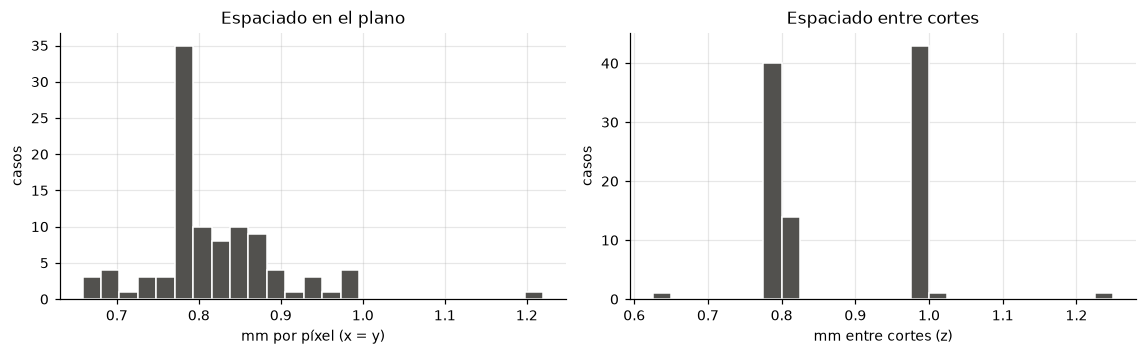

En el plano : 0.658 – 1.220 mm  (factor 1.85×)
Entre cortes: 0.625 – 1.250 mm  (factor 2.00×)
Volúmenes ya isotrópicos: 0 de 100
Cortes por volumen: 193 – 414 (mediana 326)


In [7]:
assert np.allclose(cab.sx, cab.sy), "se esperaban píxeles cuadrados"
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.3))
axs[0].hist(cab.sx, bins=25, color=NEUTRO, edgecolor="white")
axs[0].set(title="Espaciado en el plano", xlabel="mm por píxel (x = y)", ylabel="casos")
axs[1].hist(cab.sz, bins=25, color=NEUTRO, edgecolor="white")
axs[1].set(title="Espaciado entre cortes", xlabel="mm entre cortes (z)", ylabel="casos")
fig.tight_layout()
plt.show()

print(f"En el plano : {cab.sx.min():.3f} – {cab.sx.max():.3f} mm  (factor {cab.sx.max() / cab.sx.min():.2f}×)")
print(f"Entre cortes: {cab.sz.min():.3f} – {cab.sz.max():.3f} mm  (factor {cab.sz.max() / cab.sz.min():.2f}×)")
print(f"Volúmenes ya isotrópicos: {int(np.isclose(cab.sx, cab.sz, atol=1e-3).sum())} de {len(cab)}")
print(f"Cortes por volumen: {cab.nz.min()} – {cab.nz.max()} (mediana {int(cab.nz.median())})")

Los histogramas muestran que el espaciado varía entre pacientes, tanto dentro de cada corte como entre cortes. Ninguno de los volúmenes tiene el mismo espaciado en los tres ejes, por lo que necesitamos remuestrearlos a una resolución común.

Para elegir la resolución, comparamos cuánto espacio físico cubriría un recorte de 256 × 256 píxeles:

- **1,0 mm:** cubre 256 mm por lado, lo que puede dejar por fuera parte de la pelvis.
- **1,5 mm:** cubre 384 mm por lado y permite conservar la pelvis con margen.
- **2,0 mm:** cubre 512 mm por lado, pero reduce el detalle de los fragmentos pequeños.

Por estas razones, trabajamos con un espaciado de **1,5 mm en los tres ejes**, de modo que las imágenes tengan una escala física común y las distancias puedan calcularse correctamente.

In [8]:
sz, sy, sx = img_sitk.GetSpacing()[::-1]
hueso = lab > 0
ext = {e: (np.ptp(np.nonzero(hueso.any(axis=ejes))[0]) + 1) * s
       for e, ejes, s in (("z", (1, 2), sz), ("y", (0, 2), sy), ("x", (0, 1), sx))}
print(f"Hueso del caso {caso}: {ext['x']:.0f} mm de ancho (x) · {ext['y']:.0f} mm de fondo (y) · {ext['z']:.0f} mm de alto (z)")
print(f"Campo del recorte, 256 px × 1.5 mm = {256 * 1.5:.0f} mm → sobran {256 * 1.5 - max(ext['x'], ext['y']):.0f} mm en el eje más ancho")

Hueso del caso 001: 296 mm de ancho (x) · 162 mm de fondo (y) · 233 mm de alto (z)
Campo del recorte, 256 px × 1.5 mm = 384 mm → sobran 88 mm en el eje más ancho


En el caso 001, el hueso ocupa aproximadamente 296 mm de ancho, 162 mm de fondo y 233 mm de alto. El campo de 384 mm del recorte permite cubrir su ancho con un margen de 88 mm.

Sin embargo, este resultado corresponde a un solo paciente. Más adelante comprobaremos en otros casos si el recorte conserva todos los vóxeles de hueso.

## 1.5. Orientación de los volúmenes

Además del tamaño y el espaciado, las tomografías tienen una matriz de dirección que indica cómo están orientados sus ejes. Revisamos esta información para comprobar si todos los pacientes tienen la misma orientación antes de preparar los datos para el modelo.

In [9]:
identidad = (1, 0, 0, 0, 1, 0, 0, 0, 1)
for d, n in cab.direccion.value_counts().items():
    m = np.array(d, float).reshape(3, 3)
    print(f"{n:>3} casos · dirección {d} · diagonal {tuple(int(v) for v in np.diag(m))} · determinante {np.linalg.det(m):+.0f}")
girados = cab.index[cab.direccion.map(lambda d: d != identidad).to_numpy()]
girado = girados[0]

 66 casos · dirección (1, 0, 0, 0, 1, 0, 0, 0, 1) · diagonal (1, 1, 1) · determinante +1
 34 casos · dirección (-1, 0, 0, 0, -1, 0, 0, 0, 1) · diagonal (-1, -1, 1) · determinante +1


En el dataset encontramos dos orientaciones: 66 casos tienen la matriz identidad y 34 presentan los dos primeros ejes invertidos. Esto corresponde a una rotación de 180° en el plano, no a un reflejo, ya que el determinante sigue siendo +1.

Esta diferencia puede observarse en las imágenes de dos pacientes: aunque representan la misma anatomía, la pelvis aparece girada en uno de ellos. Por eso, es necesario revisar la orientación antes de preparar los datos para el modelo.

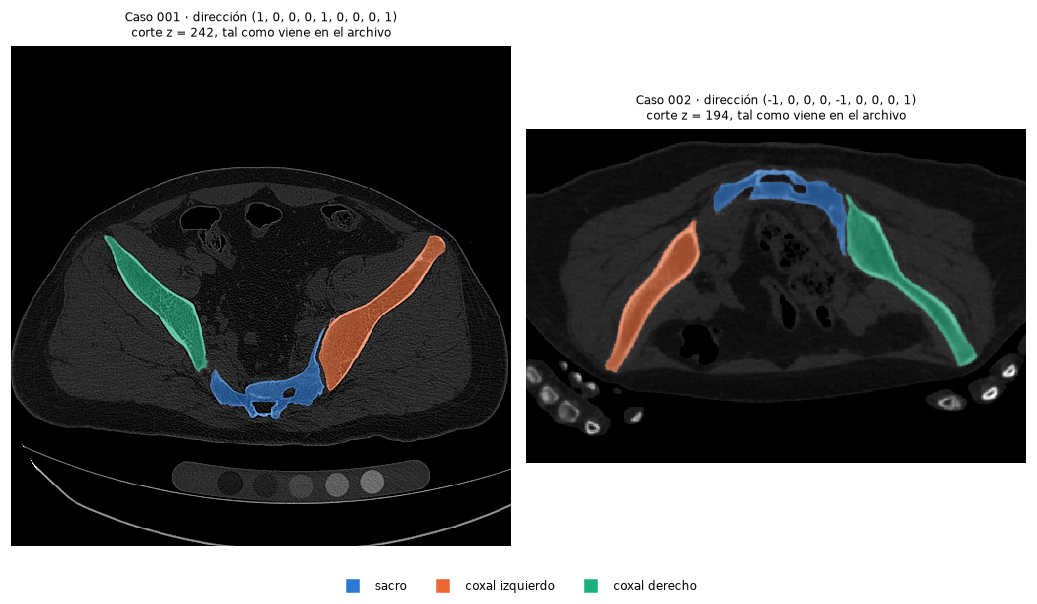

In [ ]:
def z_tres_huesos(lab3d: np.ndarray) -> int:
    presentes = [((lab3d >= 10 * k - 9) & (lab3d <= 10 * k)).any(axis=(1, 2)) for k in (1, 2, 3)]
    return int(np.median(np.nonzero(np.all(presentes, axis=0))[0]))

img_g = sitk.GetArrayFromImage(sitk.ReadImage(str(IMAGES / f"{girado}.mha")))
lab_g = sitk.GetArrayFromImage(sitk.ReadImage(str(LABELS / f"{girado}.mha")))

fig, axs = plt.subplots(1, 2, figsize=(9.5, 5.2))
for ax, (c, im, lb) in zip(axs, [(caso, img, lab), (girado, img_g, lab_g)]):
    zc = z_tres_huesos(lb)
    mostrar_corte(ax, im[zc], lb[zc], titulo=f"Caso {c} · dirección {cab.direccion[c]}\ncorte z = {zc}, tal como viene en el archivo")
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()
del img_g, lab_g

En el caso 001, el sacro aparece en la parte inferior de la imagen y el coxal izquierdo a la derecha. En el otro caso, la pelvis está girada 180°. Si no corregimos esta diferencia, el modelo tendría que aprender las mismas estructuras en dos orientaciones distintas, lo que podría dificultar la clasificación entre el coxal izquierdo y el derecho.

Por esta razón, orientamos los volúmenes a la convención LPS mediante `sitk.DICOMOrient` antes del remuestreo. Esta operación ajusta la orientación de los ejes sin interpolar los valores de las imágenes ni modificar las etiquetas de las máscaras.

## 1.6. Distribución del hueso a lo largo de los cortes

Las tomografías incluyen zonas por encima y por debajo de la pelvis donde no hay hueso anotado. Para entender qué parte del volumen contiene información útil, revisamos el área de hueso presente en cada corte del caso `001`.

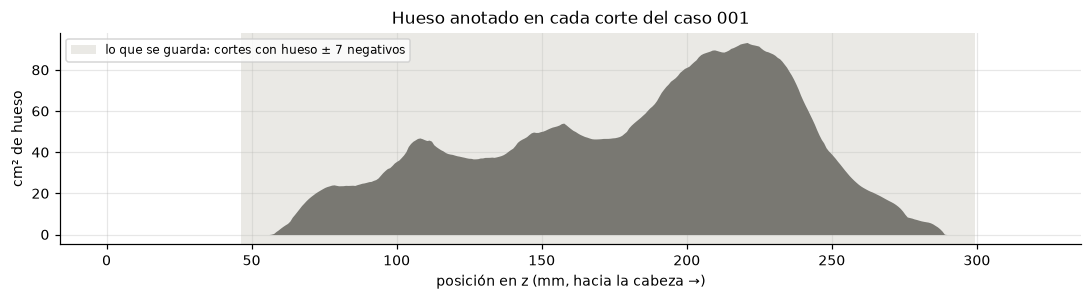

Cortes con hueso: 291 de 401 (73%), de z = 57 a 289 mm


In [ ]:
area = (lab > 0).sum(axis=(1, 2)) * sy * sx / 100      
z_mm = np.arange(len(area)) * sz
con = np.nonzero(area)[0]
margen = 7 * 1.5                                    

fig, ax = plt.subplots(figsize=(10, 2.8))
ax.fill_between(z_mm, area, color=NEUTRO, lw=0)
ax.axvspan(z_mm[con[0]] - margen, z_mm[con[-1]] + margen, color=GRIS, alpha=0.35, lw=0,
           label="lo que se guarda: cortes con hueso ± 7 negativos")
ax.set(title=f"Hueso anotado en cada corte del caso {caso}", xlabel="posición en z (mm, hacia la cabeza →)",
       ylabel="cm² de hueso")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"Cortes con hueso: {con.size} de {len(area)} ({con.size / len(area):.0%}), de z = {z_mm[con[0]]:.0f} a {z_mm[con[-1]]:.0f} mm")

En el caso `001`, encontramos hueso anotado en 291 de los 401 cortes (73 %), entre los 57 y 289 mm de posición en el eje z. Los cortes alejados de este rango no contienen hueso anotado, mientras que los que están cerca de sus extremos pueden servir como ejemplos negativos para que el modelo aprenda dónde termina la región ósea.

Por eso, conservamos los cortes que contienen hueso y siete cortes adicionales a cada lado como negativos. Con el espaciado de 1,5 mm, estos representan aproximadamente 10,5 mm por lado.

## 1.7. Preparación del caché

Como el entrenamiento utiliza muchos cortes de diferentes pacientes, leer y procesar los archivos originales en cada época aumentaría el tiempo de ejecución. Por eso, preparamos un caché que permite acceder a los datos más rápido y evita repetir el preprocesamiento.

Guardaremos las imágenes en formato `.npy` con intensidades HU en `int16` y las etiquetas en `uint8`, manteniendo sus valores originales. También crearemos un índice con información de cada corte y un informe por paciente para registrar la geometría y las verificaciones realizadas. Las ventanas HU se aplicarán durante la carga de los datos, sin necesidad de modificar el caché.

## 1.8. Construcción del caché

El script `build_cache.py` prepara los datos siguiendo los pasos definidos en las secciones anteriores:

| Paso | Proceso | Propósito |
|---|---|---|
| 1 | Comprobar la geometría de la imagen y su etiqueta | Verificar que estén alineadas. |
| 2 | Orientar los volúmenes a LPS | Unificar la orientación de los pacientes. |
| 3 | Remuestrear a 1,5 mm isotrópicos | Trabajar con una escala física común. |
| 4 | Recortar a 256 × 256 píxeles | Mantener la región de interés. |
| 5 | Seleccionar los cortes con hueso y siete cortes negativos a cada lado | Conservar la pelvis y ejemplos cercanos sin hueso. |
| 6 | Guardar las imágenes, etiquetas e índice | Facilitar el acceso durante el entrenamiento. |
| 7 | Verificar los datos procesados | Detectar pérdida de vóxeles óseos o cambios inesperados en las etiquetas. |

El recorte se centra en la mediana de las coordenadas de los vóxeles con intensidad superior a 200 HU. Utilizamos la mediana para reducir la influencia de valores aislados y el centro se calcula a partir de la imagen, sin consultar la máscara, para que el procedimiento también pueda utilizarse con tomografías sin etiquetas.

## 1.9. Prueba del preprocesamiento

Antes de procesar los 100 casos, probamos las funciones de `build_cache.py` con una muestra de seis pacientes. Seleccionamos casos con distintos espaciados, incluyendo los valores extremos, el caso 001 y un paciente con orientación diferente. Así podemos revisar cómo se comporta el preprocesamiento en distintas condiciones.

In [ ]:
sys.path.insert(0, str(RAIZ))
sys.dont_write_bytecode = True                        
import build_cache as bc                            
muestra = sorted({cab.sx.idxmin(), cab.sx.idxmax(), cab.sz.idxmin(), cab.sz.idxmax(), caso, girado})
cab.loc[muestra, ["nz", "ny", "nx", "sz", "sx", "direccion"]].assign(girado=lambda t: t.index.isin(girados))

,nz,ny,nx,sz,sx,direccion,girado
case_id,,,,,,,
001,401,512,512,0.800000,0.781250,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
002,337,276,413,0.800000,0.824219,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True
039,392,154,322,0.800000,1.220000,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
044,409,183,370,0.625000,0.873047,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True
047,193,512,512,1.250005,0.748047,"(1, 0, 0, 0, 1, 0, 0, 0, 1)",False
086,265,283,512,1.000000,0.658203,"(-1, 0, 0, 0, -1, 0, 0, 0, 1)",True


### Ejemplo de preprocesamiento

Tomamos el caso 002 para observar cómo cambia la tomografía durante las tres etapas principales del preprocesamiento: orientación a LPS, remuestreo a 1,5 mm y recorte a 256 × 256 píxeles. En cada etapa usamos el mismo nivel anatómico para comparar los cambios.

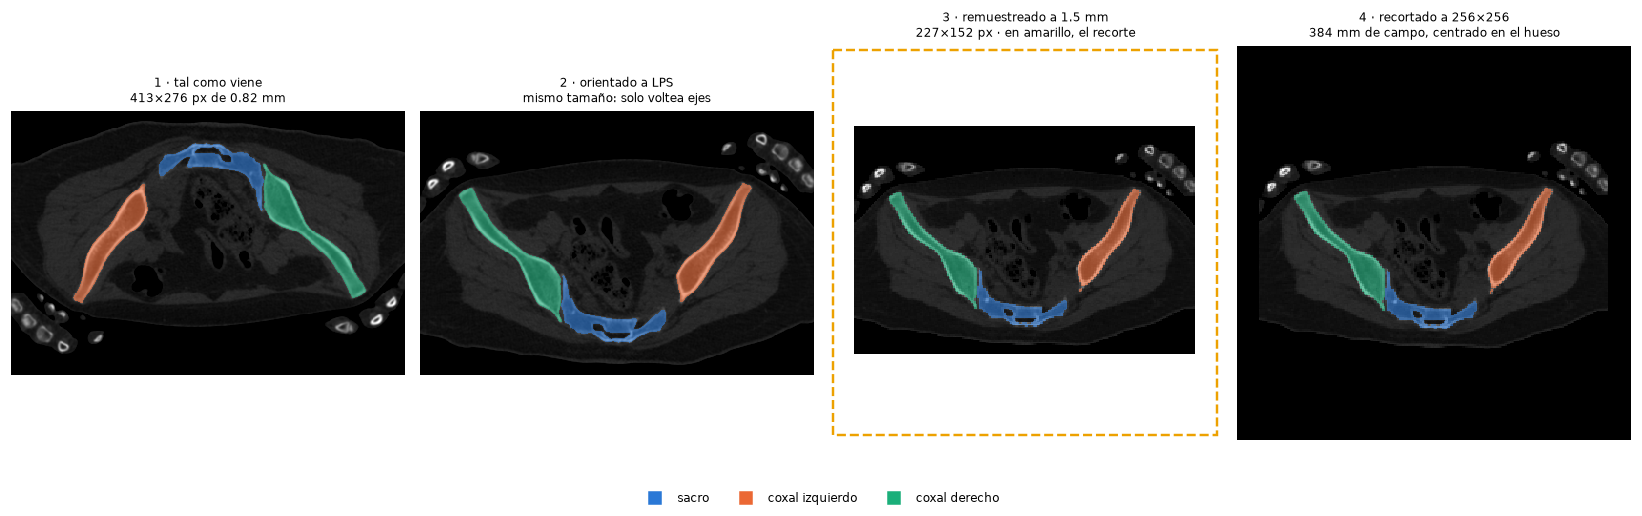

Caso 002: (337, 276, 413) vóxeles (z, y, x) → remuestreado (180, 152, 227) → recortado (180, 256, 256) · centro del hueso en (fila, columna) = (78, 114)


In [ ]:
img0 = sitk.ReadImage(str(IMAGES / f"{girado}.mha"))
lab0 = sitk.ReadImage(str(LABELS / f"{girado}.mha"))
img1, lab1 = bc.orientar(img0), bc.orientar(lab0)                                        
img2, lab2 = bc.remuestrear(img1, es_etiqueta=False), bc.remuestrear(lab1, es_etiqueta=True)  
hu2 = sitk.GetArrayFromImage(img2).astype(np.int16)
et2 = sitk.GetArrayFromImage(lab2).astype(np.uint8)
centro = bc.centro_hueso(hu2)                                                             
hu3, et3 = bc.recortar(hu2, centro, bc.AIR_HU), bc.recortar(et2, centro, 0)

z0 = z_tres_huesos(sitk.GetArrayViewFromImage(lab0))
z_iso = int(round(z0 * img0.GetSpacing()[2] / bc.ISO_MM))
corte = lambda imagen: np.array(sitk.GetArrayViewFromImage(imagen)[z0])

pasos = [
    (corte(img0), corte(lab0), f"1 · tal como viene\n{img0.GetSize()[0]}×{img0.GetSize()[1]} px de {img0.GetSpacing()[0]:.2f} mm"),
    (corte(img1), corte(lab1), "2 · orientado a LPS\nmismo tamaño: solo voltea ejes"),
    (hu2[z_iso], et2[z_iso], f"3 · remuestreado a 1.5 mm\n{hu2.shape[2]}×{hu2.shape[1]} px · en amarillo, el recorte"),
    (hu3[z_iso], et3[z_iso], "4 · recortado a 256×256\n384 mm de campo, centrado en el hueso"),
]
fig, axs = plt.subplots(1, 4, figsize=(15, 4.6))
for ax, (h, l, titulo) in zip(axs, pasos):
    mostrar_corte(ax, h, l, titulo=titulo)
cy, cx = centro
mitad = bc.CROP_PX // 2
axs[2].add_patch(Rectangle((cx - mitad - 0.5, cy - mitad - 0.5), bc.CROP_PX, bc.CROP_PX,
                           fill=False, ec="#eda100", lw=1.6, ls="--"))
axs[2].set_xlim(min(-0.5, cx - mitad - 0.5) - 3, max(hu2.shape[2], cx + mitad) + 3)
axs[2].set_ylim(max(hu2.shape[1], cy + mitad) + 3, min(-0.5, cy - mitad - 0.5) - 3)
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

print(f"Caso {girado}: {img0.GetSize()[::-1]} vóxeles (z, y, x) → remuestreado {hu2.shape} → recortado {hu3.shape}"
      f" · centro del hueso en (fila, columna) = {centro}")

La figura muestra el efecto de cada paso. Primero, la orientación a LPS corrige la posición de la pelvis sin cambiar el tamaño del volumen. Después, el remuestreo establece un espaciado de 1,5 mm por vóxel. Por último, el recorte fija las dimensiones en 256 × 256 píxeles y centra la imagen en el hueso.

En el caso 002, el volumen remuestreado es más estrecho que el campo de 384 mm del recorte, por lo que algunas zonas quedan fuera de la imagen original. Estas áreas se rellenan con −1024 HU en la imagen y con 0 en la máscara, sin introducir nuevas etiquetas óseas.

### Prueba con seis pacientes

Aplicamos `preparar_caso()` a los seis pacientes seleccionados para comprobar que el preprocesamiento funcione con distintas dimensiones, espaciados y orientaciones. También revisamos las dimensiones finales, los vóxeles de hueso perdidos, los cambios en las etiquetas y el tiempo de procesamiento.

In [14]:
procesados = {}
for c in muestra:
    t0 = time.perf_counter()
    hu_c, lab_c, info = bc.preparar_caso(c)
    info["segundos"] = time.perf_counter() - t0
    procesados[c] = (hu_c, lab_c, info)

inf_muestra = pd.DataFrame([p[2] for p in procesados.values()]).set_index("case_id")
inf_muestra[["sz", "sx", "nz_iso", "ny_iso", "nx_iso", "hueso_mm_y", "hueso_mm_x", "vox_perdidos",
             "etiquetas_perdidas", "etiquetas_inventadas", "cortes_hueso", "z0", "z1", "segundos"]].round(2)

,sz,sx,nz_iso,ny_iso,nx_iso,hueso_mm_y,hueso_mm_x,vox_perdidos,etiquetas_perdidas,etiquetas_inventadas,cortes_hueso,z0,z1,segundos
case_id,,,,,,,,,,,,,,
001,0.80,0.78,214,267,267,162.0,295.5,0,0,0,155,31,200,1.07
002,0.80,0.82,180,152,227,142.5,277.5,0,0,0,137,14,165,0.47
039,0.80,1.22,209,125,262,151.5,306.0,0,0,0,141,30,185,0.31
044,0.62,0.87,170,107,215,154.5,274.5,0,0,0,145,2,161,0.32
047,1.25,0.75,161,255,255,150.0,283.5,0,0,0,137,4,155,0.58
086,1.00,0.66,177,124,225,136.5,271.5,0,0,0,149,2,165,0.50


In [ ]:
def lado_coxal_izquierdo(lab3d: np.ndarray) -> tuple[int, int]:
    h = a_hueso(lab3d)
    izq, der = (h == 2).sum(axis=1), (h == 3).sum(axis=1)
    ambos = (izq.sum(axis=1) > 0) & (der.sum(axis=1) > 0)
    columnas = np.arange(lab3d.shape[2])
    x_izq = (izq[ambos] * columnas).sum(axis=1) / izq[ambos].sum(axis=1)
    x_der = (der[ambos] * columnas).sum(axis=1) / der[ambos].sum(axis=1)
    return int((x_izq > x_der).sum()), int(ambos.sum())

lados = []
for c in muestra:
    antes, n_antes = lado_coxal_izquierdo(sitk.GetArrayFromImage(sitk.ReadImage(str(LABELS / f"{c}.mha"))))
    despues, n_despues = lado_coxal_izquierdo(procesados[c][1])
    lados.append({"caso": c, "girado": c in girados,
                  "tal como viene": f"{antes / n_antes:.0%} de {n_antes} cortes",
                  "tras el script": f"{despues / n_despues:.0%} de {n_despues} cortes"})

print(f"Vóxeles de hueso perdidos en el recorte : {int(inf_muestra.vox_perdidos.sum())}")
print(f"Etiquetas perdidas / inventadas         : {int(inf_muestra.etiquetas_perdidas.sum())} / {int(inf_muestra.etiquetas_inventadas.sum())}")
print(f"Extensión ósea máxima en el plano       : {inf_muestra[['hueso_mm_y', 'hueso_mm_x']].max().max():.0f} mm de {bc.CROP_PX * bc.ISO_MM:.0f}")
print("\n¿Cae el coxal izquierdo a la derecha de la imagen, como manda la convención radiológica?")
pd.DataFrame(lados).set_index("caso")

Vóxeles de hueso perdidos en el recorte : 0
Etiquetas perdidas / inventadas         : 0 / 0
Extensión ósea máxima en el plano       : 306 mm de 384

¿Cae el coxal izquierdo a la derecha de la imagen, como manda la convención radiológica?


,girado,tal como viene,tras el script
caso,,,
001,False,100% de 266 cortes,100% de 142 cortes
002,True,0% de 233 cortes,100% de 124 cortes
039,False,100% de 230 cortes,100% de 123 cortes
044,True,0% de 338 cortes,100% de 141 cortes
047,False,100% de 154 cortes,100% de 129 cortes
086,True,0% de 211 cortes,100% de 141 cortes


En los seis casos no se perdieron vóxeles de hueso ni se encontraron etiquetas perdidas o inventadas. La extensión ósea máxima en el plano fue de 306 mm, dentro de los 384 mm disponibles en el recorte.

También comprobamos la orientación de los coxales. Antes del preprocesamiento, los tres casos que venían girados tenían el coxal izquierdo al lado contrario del esperado. Después de aplicar el proceso, el coxal izquierdo quedó a la derecha de la imagen en todos los cortes revisados.

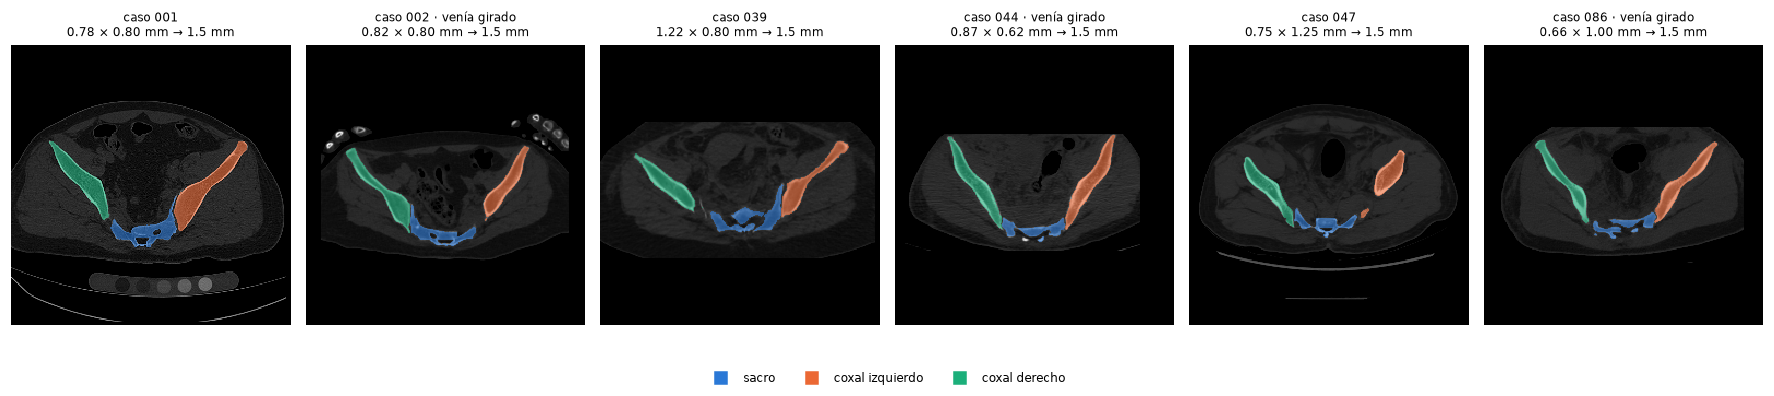

In [16]:
fig, axs = plt.subplots(1, len(muestra), figsize=(2.7 * len(muestra), 3.5))
for ax, c in zip(axs, muestra):
    hu_c, lab_c, info = procesados[c]
    zc = z_tres_huesos(lab_c)
    mostrar_corte(ax, hu_c[zc], lab_c[zc],
                  titulo=f"caso {c}{' · venía girado' if c in girados else ''}\n{info['sx']:.2f} × {info['sz']:.2f} mm → 1.5 mm")
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

Después del preprocesamiento, los seis pacientes tienen la misma orientación y un espaciado de 1,5 mm. Aunque las tomografías originales tenían dimensiones y resoluciones diferentes, las imágenes quedan centradas en la pelvis y con un tamaño común de 256 × 256 píxeles.

En la figura se puede comparar la anatomía de cada paciente después de aplicar los mismos pasos de procesamiento. Los colores permiten distinguir el sacro, el coxal izquierdo y el coxal derecho.

### Selección de cortes

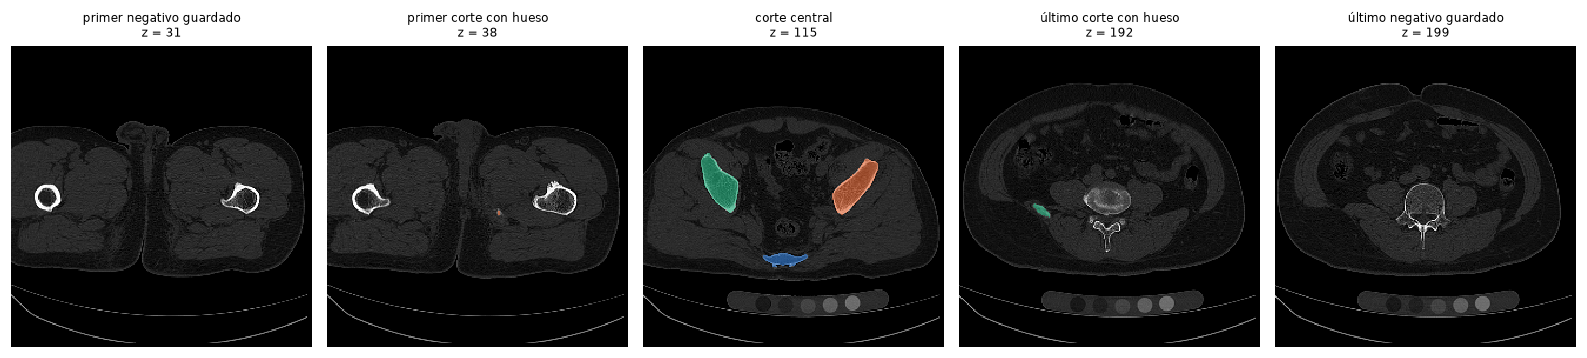

Caso 001: 214 cortes tras remuestrear · 155 con hueso · se guardan 169 (z = 31 … 199)


In [17]:
hu_c, lab_c, info = procesados[caso]
z_hueso = np.nonzero(lab_c.reshape(len(lab_c), -1).any(axis=1))[0]
seleccion = {"primer negativo guardado": info["z0"], "primer corte con hueso": z_hueso[0],
             "corte central": int(np.median(z_hueso)), "último corte con hueso": z_hueso[-1],
             "último negativo guardado": info["z1"] - 1}

fig, axs = plt.subplots(1, 5, figsize=(14.5, 3.4))
for ax, (rotulo, zc) in zip(axs, seleccion.items()):
    mostrar_corte(ax, hu_c[zc], lab_c[zc], titulo=f"{rotulo}\nz = {zc}")
fig.tight_layout()
plt.show()
print(f"Caso {caso}: {len(lab_c)} cortes tras remuestrear · {info['cortes_hueso']} con hueso · "
      f"se guardan {info['z1'] - info['z0']} (z = {info['z0']} … {info['z1'] - 1})")

Los primeros y últimos cortes muestran por qué conservamos algunos cortes sin hueso junto a los que sí lo contienen. En los extremos, el hueso aparece o desaparece gradualmente, por lo que estos cortes ayudan al modelo a reconocer dónde empieza y termina la región ósea.

En el caso 001, se guardan 169 de los 214 cortes remuestreados: los que contienen hueso y siete cortes adicionales a cada lado.

### Organización de los datos procesados

Después de preparar los casos, reunimos los cortes seleccionados en dos arreglos: uno para las imágenes y otro para las etiquetas. También construimos un índice con información de cada corte, como los huesos presentes y la cantidad de fragmentos, que utilizaremos más adelante durante el entrenamiento.

In [18]:
mini_hu = np.concatenate([p[0][p[2]["z0"]:p[2]["z1"]] for p in procesados.values()])
mini_lab = np.concatenate([p[1][p[2]["z0"]:p[2]["z1"]] for p in procesados.values()])
mini_indice = pd.DataFrame([{"case_id": c, "z": z, **bc.estadisticas_corte(p[1][z])}
                            for c, p in procesados.items() for z in range(p[2]["z0"], p[2]["z1"])])
assert len(mini_indice) == len(mini_hu) == len(mini_lab)
print(f"slices_hu: {mini_hu.shape} {mini_hu.dtype} · labels: {mini_lab.shape} {mini_lab.dtype} · índice: {len(mini_indice)} filas\n")
mini_indice.iloc[3:12]

slices_hu: (948, 256, 256) int16 · labels: (948, 256, 256) uint8 · índice: 948 filas



,case_id,z,n_frag_sa,n_frag_lh,n_frag_rh,bones_present,n_frag_total,n_regions,area_bone_px,has_bone
3,001,34,0,0,0,0,0,0,0,0
4,001,35,0,0,0,0,0,0,0,0
5,001,36,0,0,0,0,0,0,0,0
6,001,37,0,0,0,0,0,0,0,0
7,001,38,0,1,0,2,1,1,8,1
8,001,39,0,1,0,2,1,1,65,1
9,001,40,0,2,0,2,2,1,142,1
10,001,41,0,2,0,2,2,1,211,1
11,001,42,0,2,1,6,3,2,291,1


Cada fila del índice corresponde a un corte y mantiene el mismo orden que los arreglos de imágenes y etiquetas. Las columnas `n_frag_sa`, `n_frag_lh` y `n_frag_rh` indican cuántos fragmentos de cada hueso aparecen en el corte.

La columna `bones_present` codifica los huesos presentes mediante una máscara de bits: el bit 0 corresponde al sacro, el bit 1 al coxal izquierdo y el bit 2 al coxal derecho. Por su parte, `has_bone` permite distinguir los cortes que contienen hueso de los negativos.

En esta muestra se obtuvieron 948 cortes, con sus imágenes en `int16` y sus etiquetas en `uint8`. El índice también permite identificar la transición entre los cortes negativos y aquellos donde empiezan a aparecer fragmentos óseos.

### Estimación del procesamiento completo

Con los tiempos y el tamaño de los datos obtenidos en la muestra, estimamos cuánto tardaría el procesamiento de los 100 pacientes y cuánto espacio ocuparían los arreglos antes de guardarse en disco.

In [ ]:
s_caso = inf_muestra.segundos.mean()
mb_caso = (mini_hu.nbytes + mini_lab.nbytes) / len(muestra) / 1024**2
cortes_caso = len(mini_indice) / len(muestra)
print(f"Por caso, en la muestra: {s_caso:.1f} s · {cortes_caso:.0f} cortes · {mb_caso:.0f} MB")
print(f"Estimación para los {len(casos)}: ~{s_caso * len(casos) / 60:.1f} min · ~{cortes_caso * len(casos):,.0f} cortes · "
      f"~{mb_caso * len(casos) / 1024:.1f} GB que se acumulan en memoria antes de escribirse")
print(f"Volúmenes que hay que leer: {gb(IMAGES) + gb(LABELS):.1f} GB")

del img, lab, img_sitk, lab_sitk, hueso, img0, lab0, img1, lab1, img2, lab2, hu2, et2, hu3, et3
del procesados, mini_hu, mini_lab, hu_c, lab_c

Por caso, en la muestra: 0.5 s · 158 cortes · 30 MB
Estimación para los 100: ~0.9 min · ~15,800 cortes · ~2.9 GB que se acumulan en memoria antes de escribirse
Volúmenes que hay que leer: 31.4 GB


Según la muestra, el procesamiento tardaría aproximadamente 0,9 minutos para los 100 casos y generaría cerca de 15.800 cortes, con un tamaño acumulado de unos 2,9 GB para las imágenes y etiquetas. Los archivos originales ocupan 31,4 GB, por lo que preparar el caché permite trabajar después con datos organizados para acceder a los cortes sin tener que procesar nuevamente cada tomografía.

## 1.10. Ejecución del preprocesamiento

Después de comprobar las funciones con la muestra, ejecutamos el procesamiento completo de los 100 pacientes mediante `build_cache.py`. De esta forma, separamos la exploración y las pruebas del procesamiento por lotes.

Esta decisión tiene varias ventajas:

- **Memoria:** los arreglos de imágenes y etiquetas ocupan aproximadamente 3 GB, por lo que conviene liberar la memoria al terminar el proceso.
- **Tiempo de ejecución:** el caché se construye una sola vez y puede reutilizarse en las siguientes ejecuciones del notebook.
- **Reproducibilidad:** el procesamiento se ejecuta con el comando `python build_cache.py`, sin depender del orden en que se ejecuten las celdas.
- **Protección de los datos:** el script no reemplaza un caché existente, a menos que se utilice la opción `--force`.

Así, el notebook se utiliza para analizar los datos y comprobar las decisiones, mientras que el script se encarga de aplicar el preprocesamiento a todos los pacientes.

## 1.11 · El caché completo

Se construye una vez, desde una terminal en la carpeta del proyecto. Tarda alrededor de minuto y medio:

```
python build_cache.py            # no toca un caché que ya exista
python build_cache.py --force    # lo reconstruye
```

| Archivo | Contenido |
|---|---|
| `data/cache/slices_hu.npy` | `int16` · (N, 256, 256) · unidades Hounsfield crudas |
| `data/cache/labels.npy` | `uint8` · (N, 256, 256) · codificación PENGWIN 0–30 |
| `data/cache/index.parquet` | Una fila por corte, en el mismo orden que los `.npy` |
| `data/cache/casos.csv` | Una fila por caso: geometría original y verificaciones |

Si el caché no existe, la celda siguiente lanza el script, como proceso aparte, por las razones de la sección 1.10, para que el notebook pueda ejecutarse de principio a fin. Después lo abre **mapeado en memoria**: `mmap_mode="r"` no carga los 3 GB, el sistema operativo lee cada corte cuando se pide.

In [ ]:
if not (CACHE / "slices_hu.npy").exists():
    print("No hay caché: se construye con build_cache.py en un proceso aparte (unos minutos)…")
    r = subprocess.run([sys.executable, str(RAIZ / "build_cache.py")], capture_output=True, text=True,
                       encoding="utf-8", env={**os.environ, "PYTHONIOENCODING": "utf-8"})
    print(r.stdout[-1500:] + r.stderr[-1500:])
    r.check_returncode()

hu_cache = np.load(CACHE / "slices_hu.npy", mmap_mode="r")
lab_cache = np.load(CACHE / "labels.npy", mmap_mode="r")
indice = pd.read_parquet(CACHE / "index.parquet")
informe = pd.read_csv(CACHE / "casos.csv", dtype={"case_id": str}).set_index("case_id")
assert (indice.row == np.arange(len(indice))).all() and len(indice) == len(hu_cache) == len(lab_cache)

con_hueso = int(indice.has_bone.sum())
print(f"slices_hu.npy : {hu_cache.shape} {hu_cache.dtype} · {hu_cache.nbytes / 1024**3:.2f} GB")
print(f"labels.npy    : {lab_cache.shape} {lab_cache.dtype} · {lab_cache.nbytes / 1024**3:.2f} GB")
print(f"index.parquet : {len(indice):,} cortes de {indice.case_id.nunique()} casos · {con_hueso:,} con hueso "
      f"y {len(indice) - con_hueso:,} negativos ({1 - con_hueso / len(indice):.1%})")

slices_hu.npy : (15626, 256, 256) int16 · 1.91 GB
labels.npy    : (15626, 256, 256) uint8 · 0.95 GB
index.parquet : 15,626 cortes de 100 casos · 14,238 con hueso y 1,388 negativos (8.9%)


### Verificación de los 100 casos

Después de construir el caché, revisamos los resultados de los 100 pacientes para comprobar que el preprocesamiento no haya generado problemas. Verificamos que las imágenes y sus máscaras tengan la misma geometría, que no se hayan perdido vóxeles de hueso ni etiquetas y que el recorte sea suficiente para conservar toda la región ósea.

In [21]:
lado = bc.CROP_PX * bc.ISO_MM
extension = informe[["hueso_mm_y", "hueso_mm_x"]].max(axis=1)
guardados = informe.z1 - informe.z0
verificacion = pd.Series({
    "casos procesados": f"{len(informe)} de {len(casos)}",
    "imagen y etiqueta con la misma geometría": f"{int(informe.geometria_ok.sum())} de {len(informe)}",
    "vóxeles de hueso perdidos en el recorte": f"{int(informe.vox_perdidos.sum())} de {int(informe.vox_hueso.sum()):,}",
    "etiquetas perdidas / inventadas": f"{int(informe.etiquetas_perdidas.sum())} / {int(informe.etiquetas_inventadas.sum())}",
    "extensión ósea máxima en el plano": f"{extension.max():.0f} mm de {lado:.0f} mm (caso {extension.idxmax()})",
    "cortes guardados por caso": f"{guardados.min()} – {guardados.max()}",
}, name="resultado")

assert len(informe) == len(casos) and informe.geometria_ok.all() and informe.vox_perdidos.sum() == 0
assert (informe.etiquetas_perdidas + informe.etiquetas_inventadas).sum() == 0 and extension.max() < lado
assert guardados.sum() == len(indice)
verificacion.to_frame()

,resultado
casos procesados,100 de 100
imagen y etiqueta con la misma geometría,100 de 100
vóxeles de hueso perdidos en el recorte,"0 de 23,139,258"
etiquetas perdidas / inventadas,0 / 0
extensión ósea máxima en el plano,318 mm de 384 mm (caso 066)
cortes guardados por caso,136 – 186


### Verificación de la orientación

También comprobamos que la orientación de los coxales sea correcta en todo el caché, no solamente en los seis pacientes de la prueba inicial. Para esto, revisamos los cortes donde aparecen el coxal izquierdo y el derecho y verificamos que el izquierdo quede a la derecha de la imagen.

In [22]:
filas_2cox = indice.row.to_numpy()[(indice.bones_present.to_numpy() & 0b110) == 0b110]
a_la_derecha = total = 0
for i in range(0, len(filas_2cox), 2048):
    a, n = lado_coxal_izquierdo(np.asarray(lab_cache[filas_2cox[i:i + 2048]]))
    a_la_derecha, total = a_la_derecha + a, total + n

print(f"Casos que venían girados            : {int((informe.direccion != str(identidad)).sum())} de {len(informe)}")
print(f"Cortes del caché con los dos coxales: {total:,}")
print(f"Coxal izquierdo a la derecha        : {a_la_derecha:,} ({a_la_derecha / total:.1%})")
assert a_la_derecha == total

Casos que venían girados            : 34 de 100
Cortes del caché con los dos coxales: 13,088
Coxal izquierdo a la derecha        : 13,088 (100.0%)


### Tiempo de lectura del caché

Por último, comparamos el tiempo necesario para leer un lote de 32 cortes desde el caché con el tiempo que tarda en prepararse un caso desde los archivos originales. Esto nos permite comprobar si guardar los datos procesados facilita su uso durante el entrenamiento.

In [23]:
rng = np.random.default_rng(0)
lote = np.sort(rng.choice(len(indice), size=32, replace=False))
t0 = time.perf_counter()
x, y = np.asarray(hu_cache[lote]), np.asarray(lab_cache[lote])
t_lote = time.perf_counter() - t0
print(f"Un lote de 32 cortes al azar desde el caché: {1000 * t_lote:.1f} ms")
print(f"Un solo caso preparado desde los .mha      : {s_caso:.1f} s")

Un lote de 32 cortes al azar desde el caché: 2.5 ms
Un solo caso preparado desde los .mha      : 0.5 s


Los resultados muestran que los 100 casos se procesaron correctamente. Las imágenes y las máscaras tienen la misma geometría, no se perdieron vóxeles de hueso ni etiquetas y la extensión ósea máxima fue de 318 mm, dentro de los 384 mm disponibles en el recorte. Por tanto, el recorte fue suficiente para conservar el hueso en todos los casos.

En cuanto a la orientación, 34 pacientes venían girados y, después del preprocesamiento, los 13.088 cortes que contienen ambos coxales cumplen con la condición esperada: el coxal izquierdo queda a la derecha de la imagen.

Finalmente, leer un lote de 32 cortes desde el caché tardó 2,5 ms, mientras que preparar un caso desde los archivos originales tomó 0,5 segundos. Esto muestra que el caché permite acceder a los datos mucho más rápido y evita repetir el preprocesamiento durante las siguientes etapas del proyecto.

## 1.12. La entrada del modelo: tres ventanas y una pila de cortes

El caché guarda las tomografías con sus intensidades originales en unidades Hounsfield (HU). Antes de pasarlas al modelo, transformamos cada corte en tres canales, usando una ventana diferente para cada uno. Así podemos resaltar tanto el hueso como los tejidos blandos y el contorno general del cuerpo.

Cada ventana recorta los valores HU a un rango y los normaliza entre 0 y 1:

$$
x_k = \frac{\operatorname{clip}(HU, lo_k, hi_k)-lo_k}{hi_k-lo_k}
$$

| Canal | Ventana (HU) | Qué permite observar |
|---|---|---|
| 0 · Hueso | [-200, 1300] | Los bordes y la estructura ósea. |
| 1 · Tejido blando | [-150, 250] | Los músculos y los tejidos alrededor de los huesos. |
| 2 · Amplia | [-1000, 2000] | La pelvis y el contorno general del cuerpo. |

Usar tres canales también permite adaptar la entrada a las redes preentrenadas con ImageNet, que normalmente reciben imágenes RGB de tres canales.

### Entrada 2.5D

Además de los tres canales del corte central, utilizamos cortes vecinos del mismo paciente. Esto le da al modelo información sobre cómo cambia la anatomía entre cortes, sin tener que procesar el volumen completo con una red 3D.

Probamos tres opciones para seleccionar los vecinos:

- **Tres cortes:** z−1, z y z+1, separados 1,5 mm.
- **Tres cortes más distantes:** z−2, z y z+2, separados 3 mm respecto al central.
- **Cinco cortes:** z−4, z−2, z, z+2 y z+4, que abarcan 12 mm entre los extremos.

Cada corte aporta tres canales, por lo que la entrada con cinco cortes tiene 15 canales. Los objetivos de clasificación, detección y segmentación se calculan únicamente a partir de la etiqueta del corte central; los vecinos aportan contexto.

En los extremos de cada volumen, cuando no hay suficientes cortes vecinos, se repite el corte disponible más cercano. Además, los vecinos siempre pertenecen al mismo paciente para evitar mezclar anatomías diferentes.

La opción de cinco cortes, guardada en la configuración `DESP`, es la que utilizamos en el resto del notebook. En el análisis 1.13 se estudian las diferencias entre las opciones y en la sección 3.3 se comparan durante el entrenamiento.

Por último, `cargar_corte()` reúne la entrada y los objetivos que necesita el modelo: las clases de los huesos presentes, las cajas de detección y las máscaras de segmentación.

In [ ]:
VENTANAS = ((-200, 1300), (-150, 250), (-1000, 2000))
VARIANTES_25D = {"±1": (-1, 0, 1), "±2": (-2, 0, 2), "5 cortes": (-4, -2, 0, 2, 4)}
DESP = VARIANTES_25D["5 cortes"]

def ventanear(hu: np.ndarray) -> np.ndarray:
    return np.stack([(np.clip(hu, lo, hi).astype(np.float32) - lo) / (hi - lo) for lo, hi in VENTANAS], axis=-3)

def cajas_por_region(lab2d: np.ndarray) -> dict[int, tuple[int, int, int, int]]:
    h = a_hueso(lab2d)
    cajas = {}
    for k in (1, 2, 3):
        m = h == k
        filas, columnas = np.nonzero(m.any(axis=1))[0], np.nonzero(m.any(axis=0))[0]
        if filas.size:
            cajas[k] = (int(columnas[0]), int(filas[0]), int(columnas[-1]) + 1, int(filas[-1]) + 1)
    return cajas

assert all((np.diff(g.row) == 1).all() and (np.diff(g.z) == 1).all() for _, g in indice.groupby("case_id")), \
    "los cortes de cada paciente tienen que estar seguidos y en orden de z"
_ini = indice.groupby("case_id").row.transform("min").to_numpy()
_fin = indice.groupby("case_id").row.transform("max").to_numpy()

def orden_central(desplazamientos) -> tuple:
    return (0, *[d for d in desplazamientos if d != 0])

def filas_vecinas(fila: int, desplazamientos=DESP) -> np.ndarray:
    return np.clip(fila + np.array(orden_central(desplazamientos)), _ini[fila], _fin[fila])

def entrada_25d(fila: int, desplazamientos=DESP) -> np.ndarray:
    return ventanear(np.asarray(hu_cache[filas_vecinas(fila, desplazamientos)])).reshape(-1, bc.CROP_PX, bc.CROP_PX)

def cargar_corte(fila: int, desplazamientos=DESP) -> dict:
    hu, lab = np.asarray(hu_cache[fila]), np.asarray(lab_cache[fila])
    presentes = int(indice.bones_present.iat[fila])
    return {
        "entrada": entrada_25d(fila, desplazamientos),
        "huesos": np.array([(presentes >> i) & 1 for i in range(3)], np.float32),
        "cajas": cajas_por_region(lab),
        "hueso": a_hueso(lab), "fragmento": a_fragmento(lab),
        "hu": hu, "etiqueta": lab,
    }

candidatas = indice.row[(indice.n_regions == 3) & (indice.n_frag_total >= 5)]
fila = int(candidatas.iat[len(candidatas) // 2])
ej = cargar_corte(fila)
assert ej["entrada"].shape == (3 * len(DESP), 256, 256) and np.array_equal(ej["entrada"][:3], ventanear(ej["hu"]))
primera = int(_ini[fila])
assert (filas_vecinas(primera, (-2, 0, 2)) == [primera, primera, primera + 2]).all()
print(f"Fila {fila} del caché: caso {indice.case_id.iat[fila]}, z = {indice.z.iat[fila]} · pila {DESP}: filas "
      f"{filas_vecinas(fila).tolist()}")
print(f"  entrada   : {ej['entrada'].dtype} {ej['entrada'].shape} · rango [{ej['entrada'].min():.2f}, {ej['entrada'].max():.2f}]"
      f" · los canales 0–2 son las tres ventanas del corte central")
print(f"  huesos    : {ej['huesos']}  (sacro, coxal izquierdo, coxal derecho)")
print(f"  cajas     : {ej['cajas']}")
print(f"  hueso     : {ej['hueso'].dtype} {ej['hueso'].shape} · valores {np.unique(ej['hueso']).tolist()}")
print(f"  fragmento : {ej['fragmento'].dtype} {ej['fragmento'].shape} · valores {np.unique(ej['fragmento']).tolist()} (255 = fondo)")
print(f"  en la primera fila de su paciente, la pila ±2 es {filas_vecinas(primera, (-2, 0, 2)).tolist()}: el vecino de abajo "
      f"no existe y se repite el central")

Fila 6941 del caché: caso 045, z = 133 · pila (-4, -2, 0, 2, 4): filas [6941, 6937, 6939, 6943, 6945]
  entrada   : float32 (15, 256, 256) · rango [0.00, 1.00] · los canales 0–2 son las tres ventanas del corte central
  huesos    : [1. 1. 1.]  (sacro, coxal izquierdo, coxal derecho)
  cajas     : {1: (94, 127, 167, 164), 2: (158, 75, 206, 167), 3: (37, 122, 107, 176)}
  hueso     : uint8 (256, 256) · valores [0, 1, 2, 3]
  fragmento : uint8 (256, 256) · valores [0, 1, 2, 255] (255 = fondo)
  en la primera fila de su paciente, la pila ±2 es [6814, 6814, 6816]: el vecino de abajo no existe y se repite el central


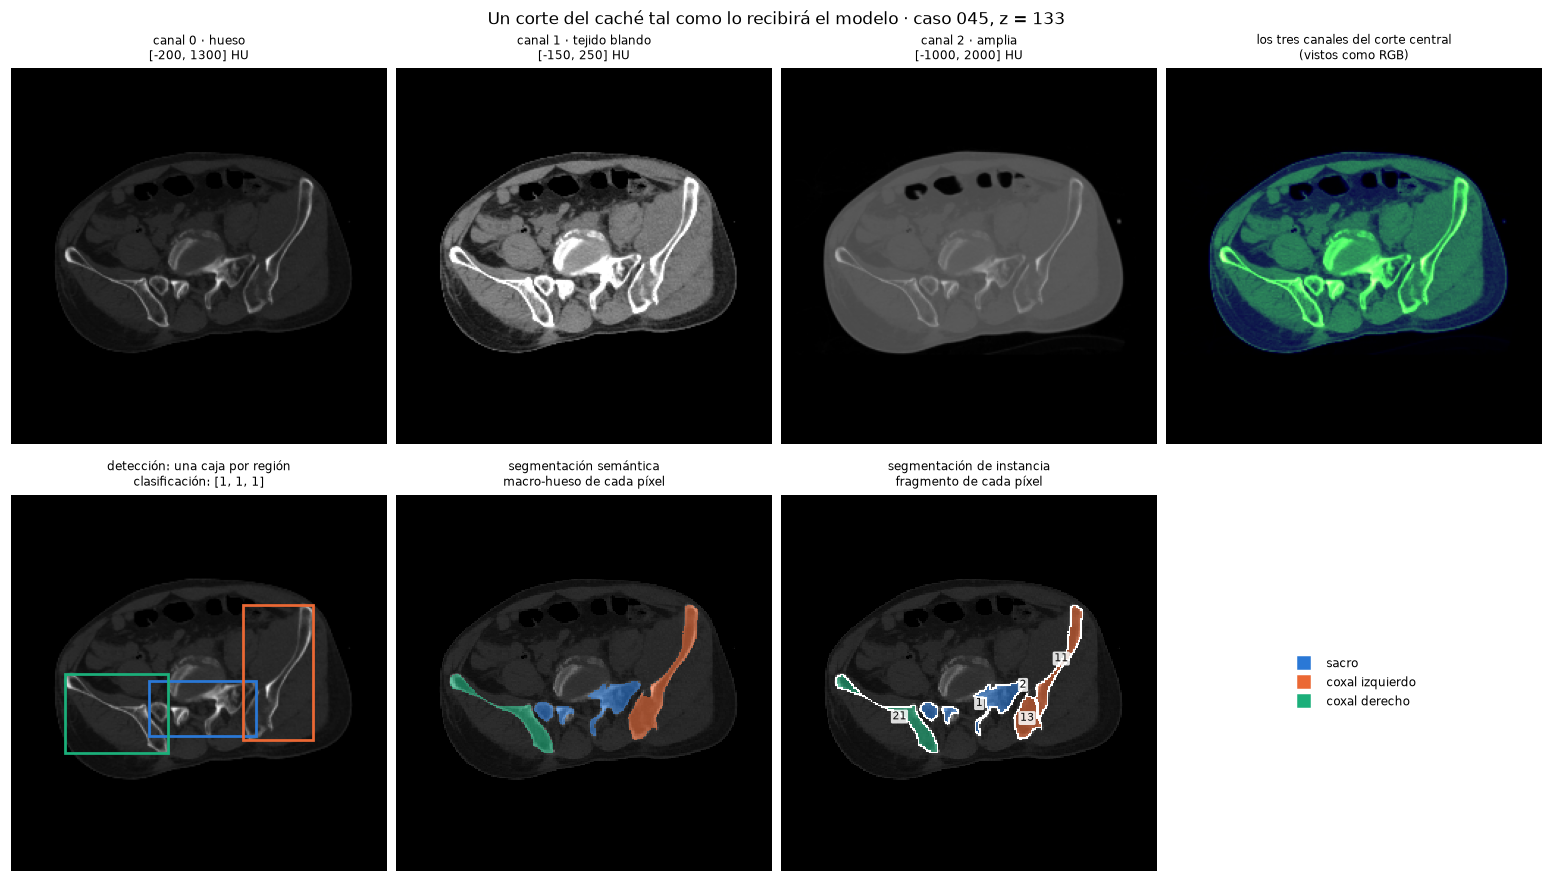

In [25]:
fig = plt.figure(figsize=(14, 8), layout="constrained")
for k, nombre in enumerate(("hueso", "tejido blando", "amplia")):
    ax = fig.add_subplot(2, 4, k + 1)
    ax.imshow(ej["entrada"][k], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"canal {k} · {nombre}\n[{VENTANAS[k][0]}, {VENTANAS[k][1]}] HU", fontsize=8)
    ax.axis("off")
ax = fig.add_subplot(2, 4, 4)
ax.imshow(np.moveaxis(ej["entrada"][:3], 0, -1))
ax.set_title("los tres canales del corte central\n(vistos como RGB)", fontsize=8)
ax.axis("off")

ax = fig.add_subplot(2, 4, 5)
ax.imshow(np.clip(ej["hu"], -200, 1300), cmap="gray")
for k, (x0, y0, x1, y1) in ej["cajas"].items():
    ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.8))
ax.set_title(f"detección: una caja por región\nclasificación: {ej['huesos'].astype(int).tolist()}", fontsize=8)
ax.axis("off")
mostrar_corte(fig.add_subplot(2, 4, 6), ej["hu"], ej["etiqueta"], titulo="segmentación semántica\nmacro-hueso de cada píxel")
mostrar_corte(fig.add_subplot(2, 4, 7), ej["hu"], ej["etiqueta"], titulo="segmentación de instancia\nfragmento de cada píxel",
              fragmentos=True)
ax = fig.add_subplot(2, 4, 8)
ax.axis("off")
leyenda_huesos(ax, loc="center", frameon=False)
fig.suptitle(f"Un corte del caché tal como lo recibirá el modelo · caso {indice.case_id.iat[fila]}, z = {indice.z.iat[fila]}")
plt.show()

En la figura se observa cómo cambia el contraste al utilizar las tres ventanas. La de hueso permite distinguir mejor las estructuras óseas, la de tejido blando muestra el contexto anatómico y la amplia conserva una vista general de la pelvis.

En la parte inferior aparecen los objetivos que se obtienen de la máscara original: la clasificación indica qué huesos están presentes, la detección marca una caja para cada región y la segmentación identifica los huesos y sus fragmentos píxel a píxel.

Para este ejemplo, la entrada tiene 15 canales y los tres huesos están presentes. Esto confirma que `cargar_corte()` prepara tanto la información de entrada como los objetivos del corte central.

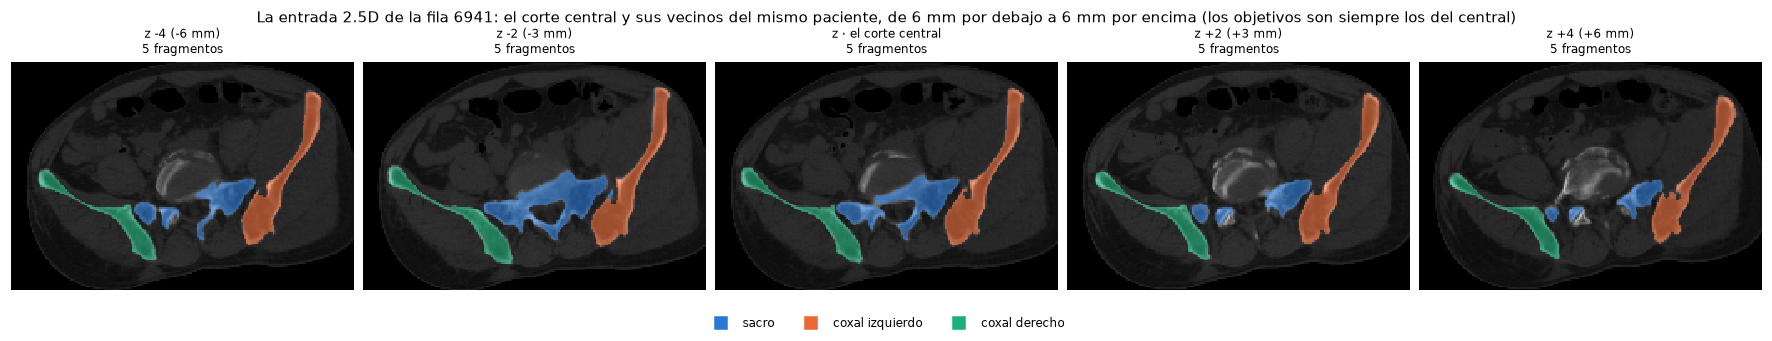

In [ ]:
filas_pila = filas_vecinas(fila, sorted(DESP))
ys, xs = np.nonzero(np.any([np.asarray(lab_cache[f]) > 0 for f in filas_pila], axis=0))
y0, y1, x0, x1 = max(ys.min() - 16, 0), min(ys.max() + 16, 255), max(xs.min() - 16, 0), min(xs.max() + 16, 255)
fig, axs = plt.subplots(1, len(DESP), figsize=(16, 3.0), layout="constrained")
for ax, d, f in zip(axs, sorted(DESP), filas_pila):
    lab_v = np.asarray(lab_cache[f])
    n_frag = len(np.unique(lab_v[lab_v > 0]))
    mostrar_corte(ax, np.asarray(hu_cache[f]), lab_v, titulo=("z · el corte central" if d == 0 else
                  f"z {d:+d} ({d * bc.ISO_MM:+.0f} mm)") + f"\n{n_frag} fragmento{'' if n_frag == 1 else 's'}")
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle(f"La entrada 2.5D de la fila {fila}: el corte central y sus vecinos del mismo paciente, de 6 mm por debajo a 6 mm "
             f"por encima (los objetivos son siempre los del central)", fontsize=10)
plt.show()

La figura muestra que la forma y la cantidad de fragmentos pueden cambiar entre cortes del mismo paciente. Algunas partes del hueso aparecen en varios cortes, mientras que otras empiezan o dejan de verse al avanzar por la tomografía.

Esta información es útil porque el modelo no analiza el corte central de forma aislada, sino que también recibe información de los cortes cercanos. Aun así, los objetivos que debe predecir corresponden solamente al corte central, mientras que los vecinos funcionan como contexto adicional.

## 1.13. EDA

En esta sección analizamos los datos del caché para entender mejor cómo son las fracturas y qué características debemos tener en cuenta al construir el modelo. Cada análisis busca responder una pregunta y comprobar alguna decisión del diseño.

Para estudiar los fragmentos, utilizamos las etiquetas originales de cada paciente. Para los análisis por corte, trabajamos con el índice y las máscaras 2D del caché.

### Fragmentos por paciente

Primero revisamos cuántos fragmentos tiene cada paciente y cómo se distribuyen entre el sacro y los dos coxales. Esto nos permite conocer qué tan fragmentadas están las estructuras óseas y qué diferencias hay entre ellas.

#### Análisis 1. ¿Cuántas regiones anatómicas hay en un mismo corte?

Primero comprobamos cuántos cortes contienen una, dos o las tres regiones anatómicas. Esto es importante para elegir cómo plantear la clasificación: si aparecen varios huesos en un mismo corte, el modelo debe poder predecirlos simultáneamente y no elegir solamente uno.

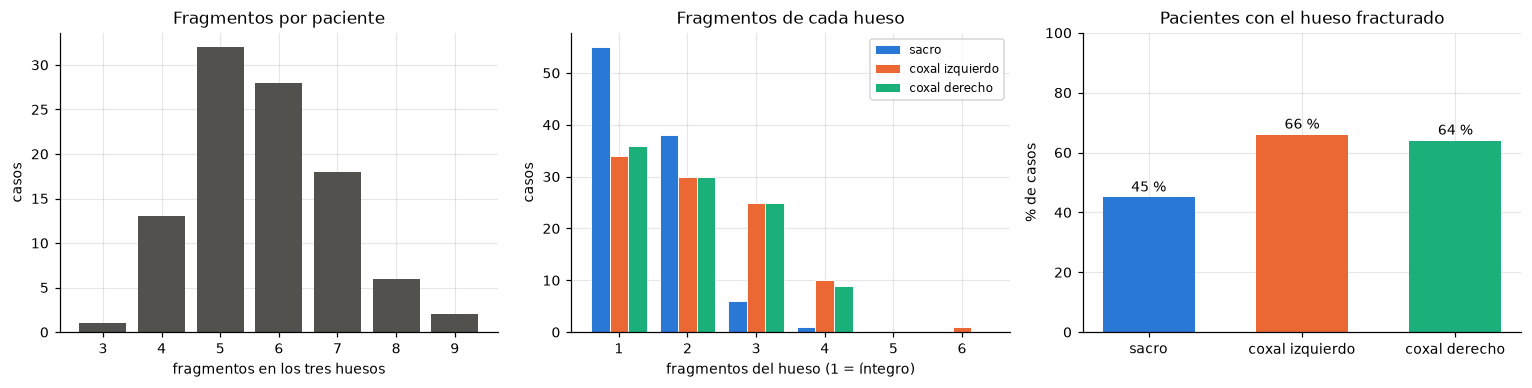

sacro           : íntegro en 55 casos · fracturado en el 45% · máximo 4 fragmentos
coxal izquierdo : íntegro en 34 casos · fracturado en el 66% · máximo 6 fragmentos
coxal derecho   : íntegro en 36 casos · fracturado en el 64% · máximo 4 fragmentos

Fragmentos por paciente: 3 – 9 (mediana 6) · 575 en total


In [ ]:
frag_caso = informe[list(FRAG.values())].set_axis(list(FRAG), axis=1)   
severidad = frag_caso.sum(axis=1)

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
v, n = np.unique(severidad, return_counts=True)
axs[0].bar(v, n, color=NEUTRO, width=0.8)
axs[0].set(title="Fragmentos por paciente", xlabel="fragmentos en los tres huesos", ylabel="casos", xticks=v)

x = np.arange(1, frag_caso.to_numpy().max() + 1)
for i, k in enumerate(COLOR):
    axs[1].bar(x + (i - 1) * 0.27, frag_caso[k].value_counts().reindex(x, fill_value=0), 0.27,
               color=COLOR[k], label=HUESO[k], edgecolor="white", linewidth=0.6)
axs[1].set(title="Fragmentos de cada hueso", xlabel="fragmentos del hueso (1 = íntegro)", ylabel="casos", xticks=x)
axs[1].legend(fontsize=8)

pct = [100 * (frag_caso[k] > 1).mean() for k in COLOR]
axs[2].bar([HUESO[k] for k in COLOR], pct, color=list(COLOR.values()), width=0.6)
for i, p in enumerate(pct):
    axs[2].text(i, p + 2, f"{p:.0f} %", ha="center", fontsize=9)
axs[2].set(title="Pacientes con el hueso fracturado", ylabel="% de casos", ylim=(0, 100))
fig.tight_layout()
plt.show()

for k in COLOR:
    col = frag_caso[k]
    print(f"{HUESO[k]:<16}: íntegro en {int((col == 1).sum()):>2} casos · fracturado en el {(col > 1).mean():.0%} · "
          f"máximo {col.max()} fragmentos")
print(f"\nFragmentos por paciente: {severidad.min()} – {severidad.max()} (mediana {int(severidad.median())}) · "
      f"{severidad.sum()} en total")

En la gráfica se observa que el número de fragmentos varía entre los pacientes. La mayoría tiene entre 5 y 7 fragmentos sumando los tres huesos, y la mediana es de 6.

Al revisar cada hueso por separado, encontramos que el sacro está íntegro en 55 pacientes y fracturado en el 45 %. En el coxal izquierdo, 34 pacientes lo tienen íntegro y el 66 % presenta fractura. Para el coxal derecho, 36 pacientes lo tienen íntegro y el 64 % presenta fractura.

El coxal izquierdo alcanza hasta 6 fragmentos, mientras que el sacro y el coxal derecho llegan a un máximo de 4. En total, los 100 pacientes reúnen 575 fragmentos. Estos resultados muestran que los coxales presentan fracturas con mayor frecuencia que el sacro.

#### Por corte: lo que verá el modelo

El modelo predice los resultados del corte central, aunque también recibe cortes vecinos como contexto. Por eso, vamos a revisar cuántas regiones anatómicas aparecen en cada corte y qué implica esto para la clasificación.

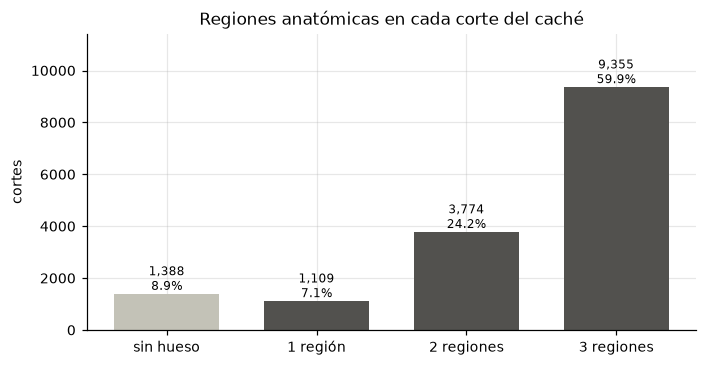

Cortes con más de una región: 84.0% · con las tres: 59.9%
Presencia de cada hueso en los cortes: sacro 60.1% · coxal izquierdo 87.7% · coxal derecho 87.1%
F1 macro de un predictor que responde siempre «las tres»: 0.872


In [ ]:
n = len(indice)
conteo = indice.n_regions.value_counts().reindex(range(4), fill_value=0)

fig, ax = plt.subplots(figsize=(6.5, 3.4))
barras = ax.bar(["sin hueso", "1 región", "2 regiones", "3 regiones"], conteo, color=[GRIS] + [NEUTRO] * 3, width=0.7)
for b, c in zip(barras, conteo):
    ax.text(b.get_x() + b.get_width() / 2, c + n * 0.01, f"{c:,}\n{c / n:.1%}", ha="center", fontsize=8)
ax.set(title="Regiones anatómicas en cada corte del caché", ylabel="cortes", ylim=(0, conteo.max() * 1.22))
fig.tight_layout()
plt.show()

prevalencia = np.array([((indice.bones_present.to_numpy() >> i) & 1).mean() for i in range(3)])
f1_constante = np.mean(2 * prevalencia / (1 + prevalencia))   
print(f"Cortes con más de una región: {(conteo[2] + conteo[3]) / n:.1%} · con las tres: {conteo[3] / n:.1%}")
print("Presencia de cada hueso en los cortes: " + " · ".join(f"{HUESO[k]} {p:.1%}" for k, p in zip(COLOR, prevalencia)))
print(f"F1 macro de un predictor que responde siempre «las tres»: {f1_constante:.3f}")

En la gráfica vemos que 9.355 cortes (59,9 %) contienen las tres regiones anatómicas y 3.774 (24,2 %) contienen dos. Además, 1.109 cortes (7,1 %) tienen una sola región y 1.388 (8,9 %) no contienen hueso.

En total, el 84 % de los cortes contiene dos o tres regiones. Esto significa que un mismo corte puede incluir varios huesos, por lo que el modelo debe poder identificarlos simultáneamente.

#### D1. Clasificación multietiqueta

Como en un mismo corte pueden aparecer varios huesos, utilizaremos tres sigmoides independientes, una para cada región anatómica, junto con entropía cruzada binaria. A diferencia de un softmax, este enfoque permite predecir que varios huesos están presentes al mismo tiempo.

Para evaluar la clasificación, utilizaremos F1 y AUC macro, además de una matriz de confusión para cada hueso frente al resto.

También debemos tener en cuenta que un predictor que siempre responde que los tres huesos están presentes obtiene un F1 macro de 0,872 en estos datos. Por eso, no basta con superar el F1 de 0,85 solicitado en el enunciado: debemos comparar el resultado con esta referencia y revisar también el AUC para evaluar mejor el desempeño del modelo.

#### Análisis 2. ¿Cuántos fragmentos hay en un corte?

Ahora revisamos cuántos fragmentos pueden aparecer en un mismo corte y cómo se distribuyen entre los tres huesos. Esto nos ayuda a definir cuántos fragmentos debe poder identificar el modelo durante la segmentación de instancias.

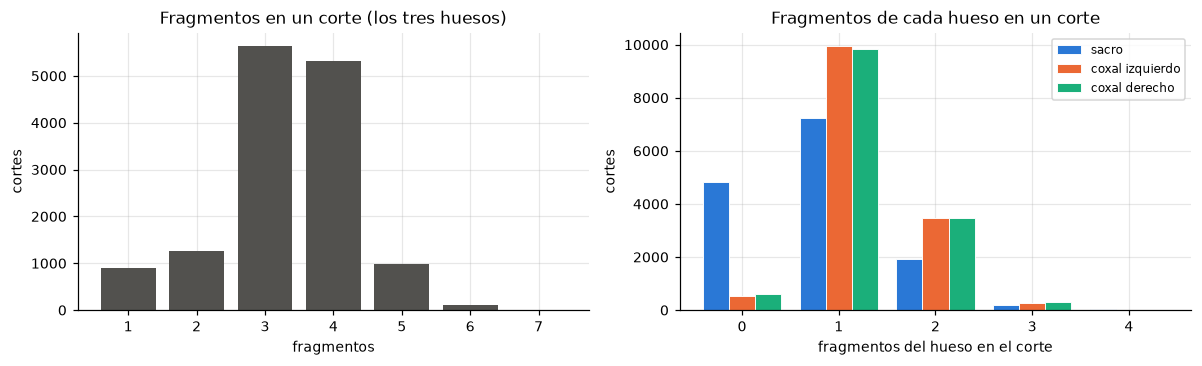

Fragmentos por corte con hueso: 1 – 7 (mediana 3)
  sacro           : hasta 4 fragmentos en un mismo corte
  coxal izquierdo : hasta 4 fragmentos en un mismo corte
  coxal derecho   : hasta 4 fragmentos en un mismo corte


In [29]:
ch = indice[indice.has_bone == 1]
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
v, c = np.unique(ch.n_frag_total, return_counts=True)
axs[0].bar(v, c, color=NEUTRO, width=0.8)
axs[0].set(title="Fragmentos en un corte (los tres huesos)", xlabel="fragmentos", ylabel="cortes", xticks=v)
x = np.arange(0, max(ch[col].max() for col in FRAG.values()) + 1)
for i, k in enumerate(COLOR):
    axs[1].bar(x + (i - 1) * 0.27, ch[FRAG[k]].value_counts().reindex(x, fill_value=0), 0.27,
               color=COLOR[k], label=HUESO[k], edgecolor="white", linewidth=0.6)
axs[1].set(title="Fragmentos de cada hueso en un corte", xlabel="fragmentos del hueso en el corte", ylabel="cortes", xticks=x)
axs[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Fragmentos por corte con hueso: {ch.n_frag_total.min()} – {ch.n_frag_total.max()} (mediana {int(ch.n_frag_total.median())})")
for k in COLOR:
    print(f"  {HUESO[k]:<16}: hasta {ch[FRAG[k]].max()} fragmentos en un mismo corte")

En los cortes que contienen hueso encontramos entre 1 y 7 fragmentos en total, con una mediana de 3. Sin embargo, al revisar cada hueso por separado, ninguno supera los 4 fragmentos en un mismo corte.

Esto significa que la cantidad de fragmentos varía según el corte y el hueso, por lo que debemos tener en cuenta el máximo observado para configurar el decodificador.

#### D2. Capacidad del decodificador

Con base en los resultados, configuraremos el decodificador para identificar hasta 4 fragmentos por hueso en cada corte, que es el máximo encontrado en los datos. Así ajustamos su capacidad a lo que realmente aparece en el conjunto, en lugar de reservar espacio para los 10 fragmentos que permite el formato de las etiquetas.

#### Análisis 3. ¿La ventana de hueso cubre el hueso?

Para comprobar si la ventana de hueso elegida es adecuada, revisamos las intensidades HU de los vóxeles que pertenecen a las máscaras óseas. Para esto, tomamos una muestra de 600 cortes y comparamos sus valores con el rango de la ventana del canal 0, que va de −200 a 1300 HU.

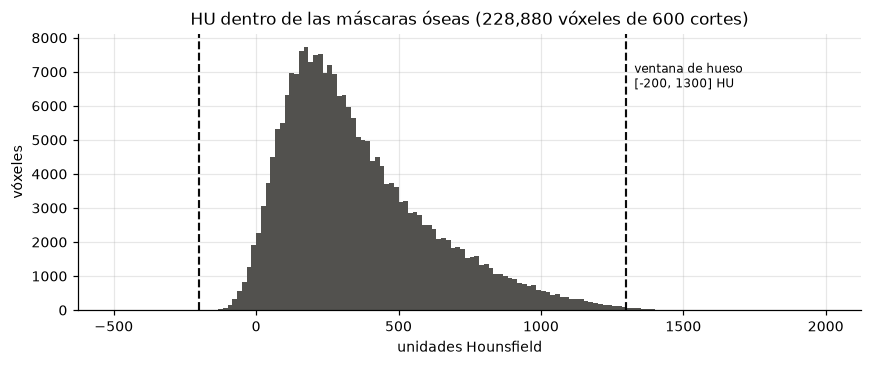

Percentiles: p1 -29 · p5 38 · p50 299 · p95 878 · p99 1,129 HU
La ventana [-200, 1300] cubre el 99.83% de los vóxeles óseos


Rango completo del caché: -5,526 … 24,496 HU


In [30]:
rng = np.random.default_rng(42)
filas_muestra = np.sort(rng.choice(ch.row.to_numpy(), size=600, replace=False))
valores = []
for f in filas_muestra:
    v = np.asarray(hu_cache[f])[np.asarray(lab_cache[f]) > 0]
    valores.append(rng.choice(v, size=min(400, v.size), replace=False))
hu_hueso = np.concatenate(valores)

lo, hi = VENTANAS[0]
cobertura = float(((hu_hueso >= lo) & (hu_hueso <= hi)).mean())
p = np.percentile(hu_hueso, [1, 5, 50, 95, 99])

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.hist(hu_hueso, bins=150, range=(-500, 2000), color=NEUTRO)
for lim in (lo, hi):
    ax.axvline(lim, color=TINTA, ls="--", lw=1.4)
ax.text(hi, ax.get_ylim()[1] * 0.9, f"  ventana de hueso\n  [{lo}, {hi}] HU", fontsize=8, va="top")
ax.set(title=f"HU dentro de las máscaras óseas ({len(hu_hueso):,} vóxeles de {len(filas_muestra)} cortes)",
       xlabel="unidades Hounsfield", ylabel="vóxeles")
fig.tight_layout()
plt.show()

print("Percentiles: " + " · ".join(f"p{q} {v:,.0f}" for q, v in zip((1, 5, 50, 95, 99), p)) + " HU")
print(f"La ventana [{lo}, {hi}] cubre el {cobertura:.2%} de los vóxeles óseos")
print(f"Rango completo del caché: {int(hu_cache.min()):,} … {int(hu_cache.max()):,} HU")

La ventana de hueso cubre el 99,83 % de los vóxeles óseos de la muestra. Además, la mediana es de 299 HU y el 95 % de los valores está por debajo de 878 HU. Esto indica que el rango seleccionado conserva la mayor parte de la información de las estructuras óseas, por lo que lo mantendremos para el canal 0.

También encontramos valores extremos en el caché, desde −5526 hasta 24.496 HU. Estos valores pueden estar relacionados con la presencia de material metálico y los artefactos que produce en la tomografía. Los tendremos en cuenta al documentar las limitaciones de los datos y el comportamiento del preprocesamiento.

#### D3. Ventana de hueso confirmada

Los resultados muestran que la ventana de [-200, 1300] HU cubre el 99,83 % de los vóxeles óseos analizados, por lo que mantendremos este rango para el canal 0.

Los valores que quedan fuera del rango se recortan durante la normalización. Esto también afecta a las intensidades extremas que pueden aparecer por la presencia de metal en algunas tomografías.

#### Análisis 4. ¿Tiene resolución suficiente la grilla de detección?

La cabeza de detección utiliza una grilla de 16 × 16 celdas, donde cada celda corresponde a 16 × 16 píxeles de la imagen. Para comprobar si esta resolución es adecuada, medimos el lado mayor de las cajas que delimitan cada región ósea en todos los cortes con hueso.

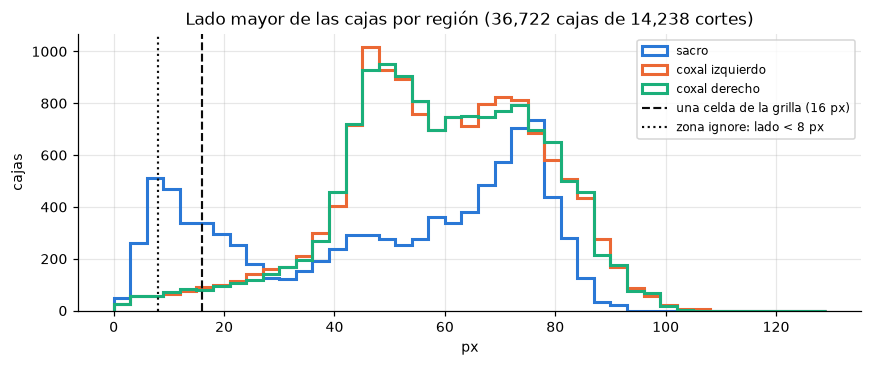

sacro           :   1 –  92 px · mediana 54 px = 3.4 celdas
coxal izquierdo :   1 – 106 px · mediana 59 px = 3.7 celdas
coxal derecho   :   1 – 102 px · mediana 59 px = 3.7 celdas

Cajas menores que una celda: 6.5% · menores de 8 px: 2.3%  (3 s)


In [31]:
t0 = time.perf_counter()
cajas_gt = pd.DataFrame([{"hueso": k, "ancho": x1 - x0, "alto": y1 - y0}
                         for f in ch.row.to_numpy()
                         for k, (x0, y0, x1, y1) in cajas_por_region(np.asarray(lab_cache[f])).items()])
cajas_gt["lado"] = cajas_gt[["ancho", "alto"]].max(axis=1)
CELDA = bc.CROP_PX // 16

fig, ax = plt.subplots(figsize=(8, 3.4))
for k in COLOR:
    ax.hist(cajas_gt.lado[cajas_gt.hueso == k], bins=np.arange(0, 130, 3), histtype="step", lw=2,
            color=COLOR[k], label=HUESO[k])
ax.axvline(CELDA, color=TINTA, ls="--", lw=1.4, label=f"una celda de la grilla ({CELDA} px)")
ax.axvline(8, color=TINTA, ls=":", lw=1.4, label="zona ignore: lado < 8 px")
ax.set(title=f"Lado mayor de las cajas por región ({len(cajas_gt):,} cajas de {len(ch):,} cortes)", xlabel="px", ylabel="cajas")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for k in COLOR:
    s = cajas_gt.lado[cajas_gt.hueso == k]
    print(f"{HUESO[k]:<16}: {s.min():>3} – {s.max():>3} px · mediana {int(s.median())} px = {s.median() / CELDA:.1f} celdas")
print(f"\nCajas menores que una celda: {(cajas_gt.lado < CELDA).mean():.1%} · menores de 8 px: {(cajas_gt.lado < 8).mean():.1%}"
      f"  ({time.perf_counter() - t0:.0f} s)")

La mediana del lado mayor de las cajas es de 54 píxeles para el sacro y de 59 para cada coxal. Esto equivale aproximadamente a entre 3 y 4 celdas de la grilla, por lo que la resolución parece suficiente para detectar las regiones en la mayoría de los casos.

Sin embargo, el 6,5 % de las cajas mide menos de 16 píxeles y el 2,3 % tiene un lado menor de 8 píxeles. Estas cajas tan pequeñas suelen aparecer cuando el hueso apenas se ve en los cortes extremos, lo que puede dificultar su detección.

#### D4. Resolución de la grilla

Mantendremos la grilla de 16 × 16 celdas, ya que la mayoría de las cajas ocupa varias celdas. En lugar de aumentar la resolución para detectar fragmentos muy pequeños, trataremos las cajas con un lado menor de 8 píxeles como regiones que se deben ignorar durante el entrenamiento, según la configuración del modelo.

#### En 3D: la geometría de los fragmentos

Hasta ahora hemos analizado los datos por corte, pero los fragmentos son estructuras tridimensionales. Por eso, para medir su volumen y la distancia entre ellos, necesitamos reconstruir el volumen completo de cada paciente a partir de sus cortes.

Para cada fragmento calculamos tres características:

- **Volumen:** cantidad de vóxeles que ocupa, convertida a mm³.
- **Piezas conexas:** número de partes separadas en las que aparece el fragmento.
- **Separación:** distancia mínima entre el fragmento y el fragmento principal de su hueso, definido como el de mayor volumen. La distancia se calcula en 3D con `scipy.ndimage.distance_transform_edt` y el espaciado físico de 1,5 mm.

Este análisis se realiza primero con las máscaras originales para conocer las características de los fragmentos y comprobar que el cálculo de distancias funcione correctamente. También servirá como referencia para definir el umbral de fragmentos pequeños que se utilizará en el postprocesamiento.

Más adelante, en la sección 4.6, aplicaremos la misma función a las máscaras predichas por el modelo para calcular la separación entre fragmentos.

In [ ]:
VOX_MM3 = bc.ISO_MM ** 3


def separacion_mm(lab3d, v, principal, cajas, espaciado=(bc.ISO_MM,) * 3, margen=2):
    caja = tuple(slice(max(min(a.start, b.start) - margen, 0), max(a.stop, b.stop) + margen)
                 for a, b in zip(cajas[v - 1], cajas[principal - 1]))
    trozo = lab3d[caja]
    distancia = ndimage.distance_transform_edt(trozo != principal, sampling=espaciado)
    return float(distancia[trozo == v].min())


def fragmentos_del_caso(lab3d: np.ndarray, caso: str) -> list[dict]:
    vox = np.bincount(lab3d.ravel(), minlength=31)
    cajas = ndimage.find_objects(lab3d)
    filas = []
    for k in (1, 2, 3):
        presentes = [v for v in range(10 * k - 9, 10 * k + 1) if vox[v]]
        if not presentes:
            continue
        principal = max(presentes, key=lambda v: vox[v])
        for v in presentes:
            piezas, n = ndimage.label(lab3d[cajas[v - 1]] == v, structure=np.ones((3, 3, 3)))
            tam = np.sort(np.bincount(piezas.ravel())[1:])[::-1] * VOX_MM3
            filas.append({"case_id": caso, "hueso": k, "etiqueta": v, "principal": v == principal,
                          "volumen_mm3": vox[v] * VOX_MM3, "piezas": n,
                          "pieza_mayor": tam[0] / tam.sum(), "segunda_pieza_mm3": tam[1] if n > 1 else 0.0,
                          "separacion_mm": 0.0 if v == principal else separacion_mm(lab3d, v, principal, cajas)})
    return filas


prueba = np.zeros((10, 10, 30), np.uint8)
prueba[2:8, 2:8, 0:10] = 11
prueba[3:6, 3:6, 10:13] = 12
prueba[3:6, 3:6, 16:19] = 13
cajas_prueba = ndimage.find_objects(prueba)
assert separacion_mm(prueba, 12, 11, cajas_prueba) == 1.5 and separacion_mm(prueba, 13, 11, cajas_prueba) == 10.5
print("separacion_mm() en el caso de solución conocida: 1.5 y 10.5 mm ✓\n")

t0 = time.perf_counter()
filas = []
for c, g in indice.groupby("case_id"):
    assert (np.diff(g.row) == 1).all() and (np.diff(g.z) == 1).all()
    filas += fragmentos_del_caso(np.asarray(lab_cache[g.row.iat[0]:g.row.iat[-1] + 1]), c)
frag = pd.DataFrame(filas)

assert (frag.groupby(["case_id", "hueso"]).size().unstack(fill_value=0).to_numpy() == frag_caso.to_numpy()).all()
print(f"{len(frag)} fragmentos de {frag.case_id.nunique()} pacientes en {time.perf_counter() - t0:.0f} s: "
      f"{int(frag.principal.sum())} principales y {int((~frag.principal).sum())} conminutos")

separacion_mm() en el caso de solución conocida: 1.5 y 10.5 mm ✓



575 fragmentos de 100 pacientes en 26 s: 300 principales y 275 conminutos


#### Análisis 5. ¿Cuánto se separan los fragmentos?

Después de calcular la distancia de cada fragmento al fragmento principal de su hueso, revisamos cómo se distribuyen esas distancias. Esto nos permite saber si los fragmentos están cerca del principal o si presentan una separación mayor.

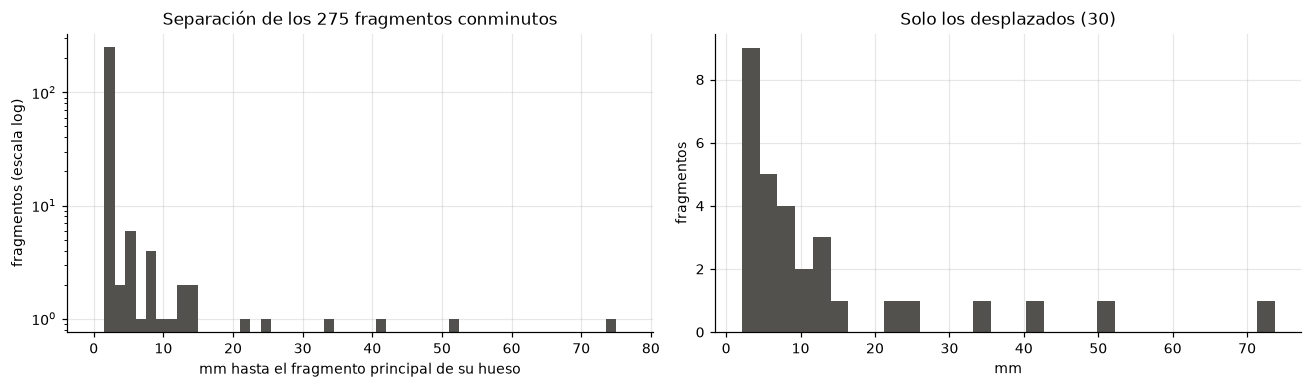

Percentiles: p5 1.50 · p25 1.50 · p50 1.50 · p75 1.50 · p95 7.65 · máximo 73.7 mm
En contacto con su principal (1.5 mm = un vóxel): 89.1% (245 de 275)


In [ ]:
conm = frag[~frag.principal]
d = conm.separacion_mm
en_contacto = d <= bc.ISO_MM + 1e-6             
q = np.percentile(d, [5, 25, 50, 75, 95])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(d, bins=np.arange(0, d.max() + 3, 1.5), color=NEUTRO)
axs[0].set_yscale("log")
axs[0].set(title=f"Separación de los {len(d)} fragmentos conminutos", xlabel="mm hasta el fragmento principal de su hueso",
           ylabel="fragmentos (escala log)")
axs[1].hist(d[~en_contacto], bins=30, color=NEUTRO)
axs[1].set(title=f"Solo los desplazados ({int((~en_contacto).sum())})", xlabel="mm", ylabel="fragmentos")
fig.tight_layout()
plt.show()

print("Percentiles: " + " · ".join(f"p{k} {v:.2f}" for k, v in zip((5, 25, 50, 75, 95), q)) + f" · máximo {d.max():.1f} mm")
print(f"En contacto con su principal (1.5 mm = un vóxel): {en_contacto.mean():.1%} ({int(en_contacto.sum())} de {len(d)})")

Los resultados muestran que 245 de los 275 fragmentos conminutos (89,1 %) están a una distancia de 1,5 mm del fragmento principal, equivalente a un vóxel. Esto indica que la mayoría están en contacto o muy cerca de la estructura principal. Sin embargo, algunos presentan separaciones mayores, y la distancia máxima registrada es de 73,7 mm.

Este resultado es importante para la arquitectura del modelo. Si intentáramos identificar cada fragmento únicamente buscando componentes conexas en la máscara de segmentación, los fragmentos que están en contacto podrían quedar agrupados como una sola pieza. Por eso, necesitaremos un método que permita distinguir los fragmentos incluso cuando están unidos en la máscara.

#### D5. Separación de instancias

Como muchos fragmentos están en contacto con el fragmento principal, no podemos distinguirlos únicamente mediante componentes conexas. Por eso, el modelo también utilizará un mapa de calor para localizar el centro de cada fragmento y un campo de desplazamientos que indique hacia dónde debe dirigirse cada píxel para llegar a su centro.

De esta manera, dos fragmentos que estén en contacto podrán identificarse como instancias diferentes. Sin embargo, la resolución del volumen limita la precisión de las distancias, por lo que esta limitación debe tenerse en cuenta al interpretar los resultados.

#### Análisis 6. ¿Qué tamaño tienen los fragmentos pequeños?

El postprocesamiento necesita un umbral para descartar posibles fragmentos pequeños generados por ruido. Para elegirlo, analizamos el volumen de los fragmentos conminutos reales y lo comparamos con el de los fragmentos principales.

La idea es establecer un umbral que permita eliminar algunas detecciones pequeñas sin descartar demasiados fragmentos reales.

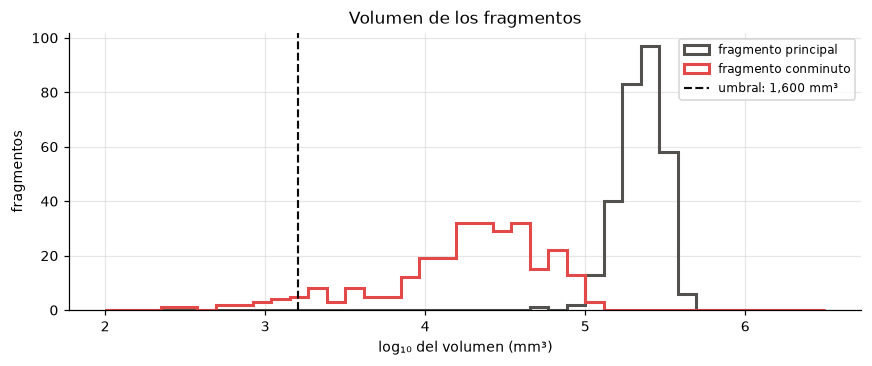

Principales: mediana 229,539 mm³
Conminutos : mínimo 287 · p1 603 · p5 1,554 · mediana 22,029 mm³

Conminutos reales por debajo de 1,600 mm³: 15 de 275 (5.5%), de ellos 8 desplazados (de 30 desplazados en total)
Volumen mediano: desplazados 6,286 mm³ · en contacto 24,374 mm³


In [ ]:
pv = np.percentile(conm.volumen_mm3, [1, 5, 50])
umbral_mm3 = max(round(pv[1] / 100) * 100, 100)      
desplazados = ~en_contacto
bajo = conm.volumen_mm3 < umbral_mm3

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(2, 6.5, 40)
ax.hist(np.log10(frag.volumen_mm3[frag.principal]), bins=bins, histtype="step", lw=2, color=NEUTRO, label="fragmento principal")
ax.hist(np.log10(conm.volumen_mm3), bins=bins, histtype="step", lw=2, color="#e34948", label="fragmento conminuto")
ax.axvline(np.log10(umbral_mm3), color=TINTA, ls="--", lw=1.4, label=f"umbral: {umbral_mm3:,.0f} mm³")
ax.set(title="Volumen de los fragmentos", xlabel="log₁₀ del volumen (mm³)", ylabel="fragmentos")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print(f"Principales: mediana {frag.volumen_mm3[frag.principal].median():,.0f} mm³")
print(f"Conminutos : mínimo {conm.volumen_mm3.min():,.0f} · p1 {pv[0]:,.0f} · p5 {pv[1]:,.0f} · mediana {pv[2]:,.0f} mm³")
print(f"\nConminutos reales por debajo de {umbral_mm3:,.0f} mm³: {int(bajo.sum())} de {len(conm)} ({bajo.mean():.1%}), "
      f"de ellos {int((bajo & desplazados).sum())} desplazados (de {int(desplazados.sum())} desplazados en total)")
print(f"Volumen mediano: desplazados {conm.volumen_mm3[desplazados].median():,.0f} mm³ · "
      f"en contacto {conm.volumen_mm3[~desplazados].median():,.0f} mm³")

Los fragmentos principales tienen un volumen mediano de 229.539 mm³, mientras que los fragmentos conminutos tienen una mediana de 22.029 mm³. Como se observa en la gráfica, los fragmentos conminutos suelen tener un volumen menor, aunque existe bastante variación entre ellos.

El percentil 5 del volumen de los fragmentos conminutos es de 1.554 mm³. A partir de este resultado, se establece un umbral de 1.600 mm³ para el postprocesamiento.

Con este umbral, 15 de los 275 fragmentos reales (5,5 %) quedan por debajo del límite. De ellos, 8 presentan una separación mayor de 1,5 mm respecto al fragmento principal. Por tanto, el umbral puede ayudar a eliminar detecciones pequeñas, pero también podría eliminar fragmentos reales.

Por esta razón, tendremos que comprobar su efecto durante la evaluación del modelo y ajustar el postprocesamiento según los resultados obtenidos.

#### D6. Umbral de fragmento espurio

Establecemos un umbral de 1.600 mm³ para descartar fragmentos pequeños que puedan aparecer como ruido en las predicciones. Este valor se basa en el percentil 5 de los fragmentos conminutos reales, que es de 1.554 mm³, redondeado a la centena.

Sin embargo, este umbral también podría eliminar fragmentos reales. En los datos analizados, 15 fragmentos están por debajo del límite, incluidos 8 de los 30 fragmentos desplazados. Por eso, durante la evaluación tendremos que revisar cómo afecta esta decisión a la medición de las distancias.

#### Análisis 7. ¿Es cada fragmento una sola pieza?

Antes de reconstruir los fragmentos en 3D a partir de las predicciones de cada corte, debemos comprobar si cada etiqueta representa una única pieza conectada o si algunos fragmentos aparecen divididos en varias partes separadas.

Esto nos permitirá saber si podemos asumir que cada fragmento es una estructura conexa durante la reconstrucción tridimensional.

In [35]:
partidos = frag[frag.piezas > 1]
motas = partidos[partidos.segunda_pieza_mm3 < umbral_mm3]
reales = partidos[partidos.segunda_pieza_mm3 >= umbral_mm3]

print(f"Fragmentos anotados en más de una pieza conexa: {len(partidos)} de {len(frag)} ({len(partidos) / len(frag):.1%})")
print(f"  hasta {partidos.piezas.max()} piezas · la pieza mayor concentra una mediana del {partidos.pieza_mayor.median():.2%} "
      f"del volumen (mínimo {partidos.pieza_mayor.min():.1%})")
print(f"  la segunda pieza mide una mediana de {partidos.segunda_pieza_mm3.median():.0f} mm³ "
      f"({partidos.segunda_pieza_mm3.median() / VOX_MM3:.0f} vóxeles); máximo {partidos.segunda_pieza_mm3.max():,.0f} mm³")
print(f"\n  → motas (segunda pieza < {umbral_mm3:,.0f} mm³): {len(motas)}")
print(f"  → divisiones reales                 : {len(reales)}  " +
      ", ".join(f"caso {r.case_id}, etiqueta {r.etiqueta}" for r in reales.itertuples()))

Fragmentos anotados en más de una pieza conexa: 100 de 575 (17.4%)
  hasta 5 piezas · la pieza mayor concentra una mediana del 99.96% del volumen (mínimo 69.4%)
  la segunda pieza mide una mediana de 34 mm³ (10 vóxeles); máximo 3,928 mm³

  → motas (segunda pieza < 1,600 mm³): 99
  → divisiones reales                 : 1  caso 039, etiqueta 12


Los resultados muestran que 100 de los 575 fragmentos (17,4 %) aparecen en más de una pieza conexa. Sin embargo, en 99 de esos casos, las piezas adicionales son muy pequeñas: la pieza mayor concentra una mediana del 99,96 % del volumen total.

Solo encontramos un caso con una segunda pieza de tamaño superior al umbral de 1.600 mm³: el caso 039, etiqueta 12. Esto indica que la mayoría de las divisiones corresponden a pequeñas partes aisladas, mientras que existe un caso en el que una misma etiqueta representa dos piezas separadas.

#### D7. Reconstrucción 3D y conectividad

Durante la reconstrucción tridimensional, utilizaremos el umbral de 1.600 mm³ para filtrar las piezas pequeñas que puedan aparecer separadas de su fragmento principal.

El caso 039, en el que una etiqueta corresponde a dos piezas de mayor tamaño, se documentará como una limitación conocida. Esto muestra que no siempre es posible recuperar la estructura original de un fragmento únicamente a partir de su conectividad.

#### Análisis 8. ¿Cuánto cambia la anatomía entre cortes vecinos?

Este análisis busca comprobar qué información aportan los cortes vecinos a la entrada 2.5D. Si dos cortes son demasiado parecidos, el segundo puede aportar poca información adicional; si están muy separados, la anatomía puede cambiar considerablemente.

Para estudiarlo, seleccionaremos 2.000 cortes con hueso y los compararemos con cortes del mismo paciente situados a distintas distancias: 1, 2, 3, 4, 6 y 8 cortes, equivalentes a 1,5, 3, 4,5, 6, 9 y 12 mm.

Mediremos tres aspectos: los cambios en los huesos presentes, los cambios en la cantidad de fragmentos y la similitud entre las máscaras de cada hueso mediante el coeficiente Dice.

In [ ]:
rng = np.random.default_rng(0)
base = rng.choice(ch.row.to_numpy(), 2000, replace=False)
cambio = []
for d in (1, 2, 3, 4, 6, 8):
    otra = np.clip(base + d, _ini[base], _fin[base])
    presentes = (indice.bones_present.to_numpy()[base] != indice.bones_present.to_numpy()[otra]).mean()
    n_frag = (indice[list(FRAG.values())].to_numpy()[base] != indice[list(FRAG.values())].to_numpy()[otra]).any(1).mean()
    dices = []
    for a, b in zip(base[:600], otra[:600]):
        ha, hb = a_hueso(np.asarray(lab_cache[a])), a_hueso(np.asarray(lab_cache[b]))
        dices += [2 * ((ha == k) & (hb == k)).sum() / ((ha == k).sum() + (hb == k).sum()) for k in (1, 2, 3) if (ha == k).any()]
    cambio.append({"d (cortes)": d, "mm": d * bc.ISO_MM, "cambia qué huesos hay": presentes,
                   "cambia el n.º de fragmentos": n_frag, "Dice de cada hueso entre z y z + d": float(np.mean(dices))})
cambio = pd.DataFrame(cambio).set_index("d (cortes)")
cambio.round(3)

,mm,cambia qué huesos hay,cambia el n.º de fragmentos,Dice de cada hueso entre z y z + d
d (cortes),,,,
1,1.5,0.038,0.074,0.904
2,3.0,0.069,0.135,0.829
3,4.5,0.098,0.187,0.763
4,6.0,0.126,0.232,0.703
6,9.0,0.180,0.328,0.601
8,12.0,0.226,0.408,0.513


Los resultados muestran que los cortes muy cercanos se parecen bastante entre sí. A una distancia de 1,5 mm, el Dice promedio es de 0,904 y solo en el 3,8 % de los casos cambia qué huesos están presentes.

Al aumentar la distancia, las diferencias son mayores. A 6 mm, el Dice baja a 0,703, en el 12,6 % de los casos cambia la presencia de algún hueso y en el 23,2 % cambia la cantidad de fragmentos. A 12 mm, el Dice llega a 0,513.

Esto indica que los cortes vecinos pueden aportar información sobre cómo cambia la anatomía, pero cuanto más lejos están del corte central, menos se parecen a él.

#### D8. Comparación de las pilas 2.5D

A partir de estos resultados, evaluaremos tres configuraciones: tres cortes separados por 1,5 mm, tres cortes separados por 3 mm y cinco cortes que abarcan desde 6 mm por debajo hasta 6 mm por encima del central.

La idea es comparar cuánto contexto aporta cada opción. Sin embargo, la decisión final no se toma únicamente con este análisis, sino que se compararán las tres configuraciones durante el entrenamiento y se elegirá la que obtenga mejores resultados en validación, como se explica en la sección 3.3.

## 1.14. La partición de los datos

Antes de entrenar el modelo, debemos separar los pacientes en conjuntos de entrenamiento, validación y prueba. Esta división es importante porque queremos comprobar si el modelo funciona con pacientes que no ha visto durante el entrenamiento.

La partición debe hacerse por paciente y no por corte. Si mezcláramos cortes del mismo paciente entre entrenamiento y prueba, el modelo podría encontrarse con imágenes casi iguales en ambos conjuntos y obtener métricas demasiado optimistas.

Esto es aún más importante con la entrada 2.5D, porque cada ejemplo incluye cortes vecinos del mismo paciente. Por eso, todos los cortes de un paciente deben permanecer en el mismo conjunto.

También debemos tener en cuenta que algunos pacientes tienen muchos más fragmentos que otros. Para evitar que los conjuntos queden con una distribución muy diferente de casos sencillos y complejos, utilizaremos una partición estratificada según el número total de fragmentos de cada paciente.

In [ ]:
SEMILLA, FRACCIONES, PARTICIONES = 42, (0.70, 0.15, 0.15), ("train", "val", "test")


def estratos(severidad: pd.Series, n: int = 3) -> pd.Series:
    g = pd.Series(pd.qcut(severidad, n, labels=False, duplicates="drop"), index=severidad.index).fillna(0).astype(int)
    for k, m in sorted(g.value_counts().items()):
        if m < 3 and k > 0:
            g = g.replace(k, k - 1)
    return g


def particionar(severidad: pd.Series) -> dict[str, list[str]]:
    rng = np.random.default_rng(SEMILLA)
    grupos = estratos(severidad)
    out = {p: [] for p in PARTICIONES}
    for k in sorted(grupos.unique()):
        ids = np.array(sorted(severidad.index[grupos == k]))
        rng.shuffle(ids)
        c1 = int(round(FRACCIONES[0] * len(ids)))
        c2 = c1 + int(round(FRACCIONES[1] * len(ids)))
        for p, trozo in zip(PARTICIONES, (ids[:c1], ids[c1:c2], ids[c2:])):
            out[p] += trozo.tolist()
    return {p: sorted(v) for p, v in out.items()}


splits = particionar(severidad)
assert sorted(sum(splits.values(), [])) == casos

ruta = RAIZ / "splits.json"
if ruta.exists():
    assert json.loads(ruta.read_text(encoding="utf-8"))["splits"] == splits, "¡la partición ha cambiado!"
ruta.write_text(json.dumps({
    "seed": SEMILLA, "fractions": dict(zip(PARTICIONES, FRACCIONES)), "level": "case_id",
    "n_cases": {p: len(v) for p, v in splits.items()}, "stratified_by": "n_fragmentos_por_caso",
    "note": "Particion POR PACIENTE (case_id). Ver pengwin_desarrollo.ipynb, seccion 1.14.", "splits": splits,
}, indent=2, ensure_ascii=False), encoding="utf-8")


def filas_de(particion: str) -> np.ndarray:
    return indice.row[indice.case_id.isin(splits[particion])].to_numpy()


pd.DataFrame({p: {
    "pacientes": len(splits[p]),
    "cortes": f"{len(filas_de(p)):,} ({len(filas_de(p)) / len(indice):.1%})",
    "fragmentos por paciente": f"{severidad[splits[p]].mean():.2f}",
    **{f"{HUESO[k]} fracturado": f"{(frag_caso.loc[splits[p], k] > 1).mean():.0%}" for k in COLOR},
} for p in PARTICIONES}).T

,pacientes,cortes,fragmentos por paciente,sacro fracturado,coxal izquierdo fracturado,coxal derecho fracturado
train,70,"10,969 (70.2%)",5.76,50%,66%,64%
val,15,"2,364 (15.1%)",5.67,20%,80%,60%
test,15,"2,293 (14.7%)",5.80,47%,53%,67%


La partición quedó distribuida en 70 pacientes para entrenamiento, 15 para validación y 15 para prueba. En cuanto a los cortes, cada grupo representa aproximadamente el 70 %, el 15 % y el 15 % del total.

La severidad media también es similar: 5,76 fragmentos por paciente en entrenamiento, 5,67 en validación y 5,80 en prueba. Esto indica que la distribución según el número total de fragmentos quedó bastante equilibrada.

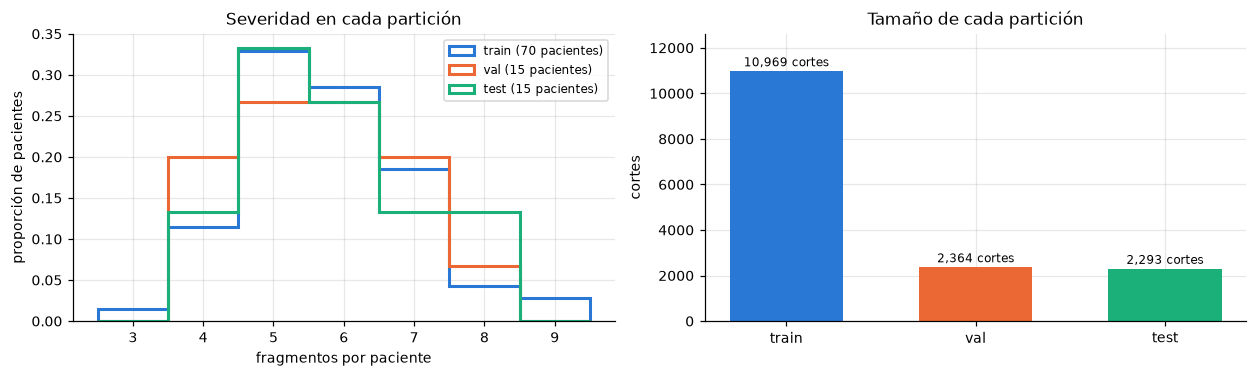

Pasos por época de entrenamiento: lote 8 → 1371 · lote 16 → 685 · lote 32 → 342


In [38]:
fig, axs = plt.subplots(1, 2, figsize=(11.5, 3.5))
bins = np.arange(severidad.min() - 0.5, severidad.max() + 1.5)
for p, color in zip(PARTICIONES, COLOR.values()):
    axs[0].hist(severidad[splits[p]], bins=bins, density=True, histtype="step", lw=2, color=color,
                label=f"{p} ({len(splits[p])} pacientes)")
axs[0].set(title="Severidad en cada partición", xlabel="fragmentos por paciente", ylabel="proporción de pacientes")
axs[0].legend(fontsize=8)
cortes = [len(filas_de(p)) for p in PARTICIONES]
axs[1].bar(PARTICIONES, cortes, color=list(COLOR.values()), width=0.6)
for i, c in enumerate(cortes):
    axs[1].text(i, c + max(cortes) * 0.02, f"{c:,} cortes", ha="center", fontsize=8)
axs[1].set(title="Tamaño de cada partición", ylabel="cortes", ylim=(0, max(cortes) * 1.15))
fig.tight_layout()
plt.show()

print("Pasos por época de entrenamiento: " + " · ".join(f"lote {b} → {len(filas_de('train')) // b}" for b in (8, 16, 32)))

En la gráfica se observa que la distribución de fragmentos por paciente es parecida entre los tres grupos. Sin embargo, las proporciones de pacientes con cada hueso fracturado varían más. Por ejemplo, en validación el 20 % tiene el sacro fracturado, frente al 50 % en entrenamiento.

Esto se debe a que la estratificación se realizó según el número total de fragmentos y no por separado para cada hueso. Además, como validación y prueba tienen solo 15 pacientes, cada caso representa aproximadamente el 6,7 % del grupo.

Por eso, al comparar las métricas por hueso, tendremos que considerar estas diferencias y evitar sacar conclusiones únicamente a partir de porcentajes pequeños.

#### D9. Partición por paciente y severidad

La partición final utiliza 70 pacientes para entrenamiento, 15 para validación y 15 para prueba, con la semilla 42 y una distribución basada en el número total de fragmentos por paciente. Los resultados se guardan en `splits.json` para mantener la misma división durante todo el proyecto.

Si al volver a ejecutar el código la partición es diferente, la comprobación detiene la ejecución en lugar de sobrescribir el archivo. Así evitamos cambiar los grupos sin darnos cuenta.

La partición de prueba se reservará para la evaluación final y no se utilizará para tomar decisiones durante el entrenamiento. También es importante guardar una copia de `splits.json`, porque necesitamos conservar la misma división para que los resultados sean comparables.

### Cierre del capítulo 1

En este capítulo revisamos los 100 pacientes y preparamos las tomografías para poder utilizarlas en el modelo. Después de corregir la orientación, ajustar el espaciado y recortar las imágenes, construimos un caché de 15.626 cortes de 256 × 256 píxeles. También comprobamos que el recorte no perdiera vóxeles de hueso y que las máscaras conservaran sus etiquetas.

Con el análisis exploratorio definimos varios aspectos del modelo: utilizar tres canales con diferentes ventanas HU, incluir cortes vecinos como entrada 2.5D, permitir que se detecten varios huesos en un mismo corte y separar los fragmentos mediante una estrategia que no dependa únicamente de que estén conectados.

También dejamos preparada la partición de los pacientes en entrenamiento, validación y prueba, manteniendo a cada paciente en un solo grupo.

Con esto tenemos los datos organizados y una primera configuración del modelo. En los siguientes capítulos probaremos estas decisiones durante el entrenamiento y revisaremos los resultados para determinar cuáles funcionan mejor.

---

# Capítulo 2 · El modelo

**Backbone compartido**, extensión propia de la `FundidoraPC` del curso, con **atención CBAM** antes de la bifurcación; **tres cabezas** sobre él (clasificación, detección con grilla y NMS propios, y segmentación de instancia); transfer learning solo en el backbone; y una **pérdida compuesta** con pesos justificados. Todo lo de este capítulo es código propio, y torchvision solo aporta los pesos de ImageNet y un oráculo con el que comprobar el NMS.

El capítulo construye el modelo pieza a pieza y comprueba cada una antes de pasar a la siguiente:

Secciones:

- 2.1.  CBAM con compuerta γ 
- 2.2.  Backbone 2.5D: la primera convolución, partida
- 2.3.  Clasificación y detección: cabezas, objetivos en la grilla, decodificación y NMS propio 
- 2.4.  Segmentación de instancia: objetivos, cabeza y decodificador en dos etapas 
- 2.5.  El modelo completo 
- 2.6.  La pérdida de siete términos 
- 2.7.  Lotes y augmentación 2.5D 
- 2.8.  Prueba de overfit de punta a punta 
- 2.9.  Métricas

## 2.0 · PyTorch y la GPU

Si hay una GPU, el modelo corre en ella; si no, en CPU. En GPU se usa **precisión mixta** con `torch.amp` en `bf16`, que reduce la memoria y acelera el entrenamiento; en CPU se trabaja en precisión normal. Se activa TF32 para algunas operaciones de la GPU y se fija la carpeta de los checkpoints.

In [39]:
import math
from concurrent.futures import ThreadPoolExecutor

import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import f1_score, roc_auc_score

DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True            
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
CHECKPOINTS = RAIZ / "checkpoints"


def precision_mixta():
    return torch.amp.autocast("cuda", dtype=torch.bfloat16, enabled=DISPOSITIVO.type == "cuda")

def fijar_semilla(semilla: int) -> None:
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    torch.cuda.manual_seed_all(semilla)

def contar(modulo: nn.Module) -> int:
    return sum(p.numel() for p in modulo.parameters())


print(f"PyTorch {torch.__version__} · torchvision {torchvision.__version__} · OpenCV {cv2.__version__}")
if DISPOSITIVO.type == "cuda":
    gpu = torch.cuda.get_device_properties(0)
    print(f"GPU: {gpu.name} · {gpu.total_memory / 1024**3:.1f} GB · bf16 {'sí' if torch.cuda.is_bf16_supported() else 'no'}")
else:
    print("Sin GPU: todo correrá en CPU, mucho más despacio")

PyTorch 2.14.0+cu130 · torchvision 0.29.0+cu130 · OpenCV 5.0.0
GPU: NVIDIA GeForce RTX 5060 Ti · 15.9 GB · bf16 sí


## 2.1 · CBAM: atención de canal y espacial, con compuerta γ

En el backbone agregamos un bloque CBAM para ayudar al modelo a darle más importancia a las características relevantes de la imagen.

CBAM trabaja en dos partes:

1. **Atención de canal:** analiza los diferentes canales del mapa de características y asigna un peso a cada uno. Para esto se calculan el promedio y el máximo de cada canal.

2. **Atención espacial:** después de la atención de canal, analiza en qué posiciones de la imagen se encuentran las características más importantes. Para esto se calculan el promedio y el máximo entre los canales y luego se aplica una convolución.

En ambos casos se utiliza una sigmoide para obtener valores entre 0 y 1. Estos valores se multiplican por el mapa de características original para darle más o menos importancia a cada característica.

El bloque se aplica primero sobre los canales y después sobre el espacio, antes de continuar con el resto del backbone.

### La compuerta γ: ¿la red usa el CBAM?

Un CBAM que solo multiplica está siempre activo, así que no permite saber si la red le saca provecho. Por eso cada una de sus dos atenciones pasa por una **compuerta aprendible γ que empieza en 0**, el mismo recurso que usan SAGAN (Zhang et al., 2019) y DANet (Fu et al., 2019) para sus bloques de atención:

$$x' = x \cdot \big(1 + \gamma_c\,(M_c(x) - 1)\big), \qquad y = x' \cdot \big(1 + \gamma_s\,(M_s(x') - 1)\big)$$

- **Con γ = 0 el bloque devuelve su entrada sin cambios.** La red empieza sin atención, y el tronco arranca exactamente como el ResNet-18 de ImageNet: un CBAM recién inicializado ya no altera esas características desde el primer paso.
- **Con γ = 1 es el CBAM original** (Woo et al., 2018).
- **El valor final lo decide la red.** Si la atención no le ayuda a bajar la pérdida, no tiene motivo para abrir la compuerta, y γ se queda cerca de 0.

Son dos números por bloque, ocho en total, y no llevan *weight decay* (3.1 lo quita a todos los parámetros de una dimensión), así que nada los empuja hacia 0 por fuera de la pérdida. Se registran en cada época del entrenamiento (3.2).

Que la red **use** la atención no demuestra que le **sirva**: eso solo lo dice un modelo entrenado sin CBAM. Las tres pruebas —usa, depende, sirve— están en 4.8.


#### D10 · CBAM con compuerta γ

Cada atención del CBAM se aplica a través de una compuerta aprendible que empieza en 0. La red parte de un tronco idéntico al de ImageNet y solo abre la atención si le ayuda; el valor final de γ dice si la usa (4.8).

In [40]:
class CBAM(nn.Module):
    #Bloque de atención de canal y espacial, cada una con su compuerta γ aprendible
    def __init__(self, canales: int, reduccion: int = 16, nucleo: int = 7):
        super().__init__()
        oculto = max(canales // reduccion, 8)
        self.mlp = nn.Sequential(nn.Conv2d(canales, oculto, 1), nn.ReLU(inplace=True),
                                 nn.Conv2d(oculto, canales, 1))          # el mismo para el promedio y el máximo
        self.conv = nn.Conv2d(2, 1, nucleo, padding=nucleo // 2, bias=False)
        self.gamma_canal = nn.Parameter(torch.zeros(1))                  # γ = 0: el bloque empieza siendo la identidad
        self.gamma_espacial = nn.Parameter(torch.zeros(1))

    def atencion_canal(self, x):
        #Calcula un peso para cada canal
        return torch.sigmoid(self.mlp(x.mean((2, 3), keepdim=True)) + self.mlp(x.amax((2, 3), keepdim=True)))

    def atencion_espacial(self, x):
        #Calcula un peso para cada posición
        return torch.sigmoid(self.conv(torch.cat([x.mean(1, keepdim=True), x.amax(1, keepdim=True)], 1)))

    def forward(self, x):
        x = x * (1 + self.gamma_canal * (self.atencion_canal(x) - 1))          # = x + γ·(x·M − x)
        return x * (1 + self.gamma_espacial * (self.atencion_espacial(x) - 1))


def leer_gammas(modelo: nn.Module) -> dict:
    # Las compuertas de cada CBAM del modelo: {"cbam1": (γ canal, γ espacial), ...}; vacío si no tiene CBAM
    return {n.split(".")[-1]: (m.gamma_canal.item(), m.gamma_espacial.item())
            for n, m in modelo.named_modules() if isinstance(m, CBAM)}


# Comprobaciones sobre un mapa aleatorio de 64 canales
cbam = CBAM(64)
x = torch.randn(2, 64, 32, 32)
assert torch.equal(cbam(x), x), "con γ = 0 el bloque tiene que devolver su entrada exacta"
with torch.no_grad():
    cbam.gamma_canal.fill_(1.0)
    cbam.gamma_espacial.fill_(1.0)
y = cbam(x)
original = x * cbam.atencion_canal(x)
original = original * cbam.atencion_espacial(original)
assert torch.allclose(y, original, atol=1e-6), "con γ = 1 tiene que ser el CBAM original"
assert y.shape == x.shape, "CBAM tiene que conservar la forma"
assert torch.equal(torch.sign(y), torch.sign(x)), "una puerta multiplicativa en (0, 1) no cambia el signo…"
assert (y.abs() <= x.abs()).all(), "…ni aumenta la magnitud"
# Control negativo: el error típico, sumar la atención en vez de multiplicarla, sí cambia signos
assert not torch.equal(torch.sign(x + cbam.atencion_canal(x)), torch.sign(x))
print(f"CBAM(64): con γ = 0 devuelve su entrada; con γ = 1 es el CBAM original, conserva la forma {tuple(y.shape)} "
      f"y el signo y nunca aumenta la magnitud · {contar(cbam):,} parámetros, 2 de ellos las compuertas")


CBAM(64): con γ = 0 devuelve su entrada; con γ = 1 es el CBAM original, conserva la forma (2, 64, 32, 32) y el signo y nunca aumenta la magnitud · 1,196 parámetros, 2 de ellos las compuertas


## 2.2 · El backbone: de `FundidoraPC` a `FundidoraPelvis` 2.5D

El enunciado pide **una extensión propia del backbone del curso (`FundidoraPC`) o una arquitectura equivalente diseñada por el equipo**. Conviene empezar por el original (`S6_Bloque1_Clasificar_a_Detectar.ipynb`, celda 3): cuatro bloques convolución 3×3 → BatchNorm → ReLU → MaxPool que duplican los canales (32 → 64 → 128 → 256) y reducen la resolución a la mitad, y un pooling global que deja un vector de 256 números. Escrito de forma compacta, con la misma arquitectura:

In [41]:
class FundidoraPC(nn.Module):
    """El backbone del curso (S6_Bloque1, celda 3): 4 bloques conv-BN-ReLU-MaxPool de 32 a 256 canales y pooling global."""

    def __init__(self, in_channels=3):
        super().__init__()
        canales = (in_channels, 32, 64, 128, 256)
        self.bloques = nn.Sequential(*[nn.Sequential(nn.Conv2d(a, b, 3, padding=1), nn.BatchNorm2d(b),
                                                     nn.ReLU(), nn.MaxPool2d(2))
                                       for a, b in zip(canales, canales[1:])])
        self.global_pool = nn.AdaptiveAvgPool2d(1)
        self.out_features = 256

    def forward(self, x):
        return self.global_pool(self.bloques(x)).flatten(1)


fundidora = FundidoraPC()
entrada = torch.randn(2, 3, 256, 256)
print(f"FundidoraPC: {contar(fundidora):,} parámetros")
print(f"  salida                       : {tuple(fundidora(entrada).shape)}            ← un vector por imagen")
print(f"  mapa antes del pooling global: {tuple(fundidora.bloques(entrada).shape)}  ← 16×16 posiciones a 1/16")

FundidoraPC: 389,376 parámetros
  salida                       : (2, 256)            ← un vector por imagen
  mapa antes del pooling global: (2, 256, 16, 16)  ← 16×16 posiciones a 1/16


Ese diseño sirve para clasificar una imagen entera, pero no para detectar: el *pooling* global final borra **dónde** está cada cosa, y a 1/16 de resolución no queda detalle para separar fragmentos. `FundidoraPelvis` lo extiende sin pooling final y con más profundidad:

- **Cuatro etapas residuales** (dos bloques de dos convoluciones 3×3 cada una) que duplican los canales (64, 128, 256 y 512) y reducen la resolución a la mitad, con un *stem* inicial (convolución 7×7 y *max-pooling*). Son las formas de una ResNet-18, lo que permite cargar sus pesos de ImageNet.
- **Un CBAM después de cada etapa**, antes de cualquier bifurcación hacia las cabezas ( 4.1).
- **Un FPN pequeño** (*neck*) que combina las cuatro escalas en mapas de 128 canales: `p2` (1/4) para la instancia, `p4` (1/16, la grilla de 16×16) para la detección y `p5` (1/32) para la clasificación.

**Transfer learning, solo en el tronco** ( 4.1): se cargan los pesos de ResNet-18 en ImageNet en las capas con la misma forma. CBAM, *neck* y las tres cabezas se entrenan desde cero.

### La entrada 2.5D: la primera convolución, en dos

Lo que la entrada 2.5D obliga a pensar es la **primera convolución**. Una ResNet-18 empieza con una convolución 7×7 que recibe 3 canales, y la pila trae 3·S (15 con 5 cortes). Había tres maneras de resolverlo:

1. **Una convolución nueva de 3·S canales, desde cero.** Se perderían los pesos de ImageNet de la primera capa, los filtros de bordes y texturas sobre los que se apoya todo lo demás.
2. **¨Inflar¨ los pesos de ImageNet**, repitiéndolos para cada corte y dividiéndolos por S, como hace I3D al pasar de imágenes a vídeo. El modelo empezaría promediando el corte central con sus vecinos: ya no vería el central nítido, sino una mezcla, y no habría forma de saber después cuánto usa cada uno.
3. **Partirla en dos**, la opción elegida: `conv1` recibe los tres canales del corte central y carga los pesos de ImageNet; `conv1_vecinos` recibe los de los vecinos y **empieza en cero**. Sus salidas se suman. Esta fue la opción elegida

La suma de las dos es matemáticamente una sola convolución sobre los 3·S canales: no hay nada raro en la arquitectura. Pero la inicialización tiene tres consecuencias. **Al empezar, el corte central entra exactamente como una imagen de ImageNet**: con los pesos de los vecinos a cero, lo que entra por ellos no cambia nada (2.5 lo comprueba con un `assert`). **Los vecinos solo pesan si sirven**: el gradiente aleja `conv1_vecinos` de cero solo si usar los vecinos reduce la pérdida. Y **su uso se puede medir**: la norma de los pesos de `conv1_vecinos` dividida por la de `conv1` dice cuánto pesan los vecinos frente al central; se registra en cada época (3.2). Es la misma idea que las *zero convolutions* de ControlNet (Zhang et al., 2023), que añaden una entrada nueva a un modelo preentrenado sin perturbarlo al empezar. Los pesos de los vecinos van al learning rate completo, como todo lo que no viene de ImageNet (3.1).

#### D11 · La primera convolución, partida

`conv1` para el corte central, con los pesos de ImageNet, y `conv1_vecinos` para los vecinos, empezando en cero. El modelo arranca sin perturbar lo preentrenado, aprende a usar los vecinos solo si le sirve y deja medir cuánto los usa.

 #### D12 · Transfer learning solo en el tronco

 Pesos de ResNet-18 en ImageNet en las capas del tronco con su misma forma; CBAM, `conv1_vecinos`, *neck* y cabezas, desde cero ( 4.1).

In [42]:
class BloqueResidual(nn.Module):
    #Bloque residual con dos convoluciones 3x3
    def __init__(self, c_in, c_out, paso=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, paso, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.downsample = (nn.Sequential(nn.Conv2d(c_in, c_out, 1, paso, bias=False), nn.BatchNorm2d(c_out))
                           if paso != 1 or c_in != c_out else nn.Identity())

    def forward(self, x):
        y = F.relu(self.bn1(self.conv1(x)))
        return F.relu(self.bn2(self.conv2(y)) + self.downsample(x))


class FundidoraPelvis(nn.Module):
    # Entrada 2.5D (`cortes` cortes, el central primero), cuatro etapas residuales con un CBAM cada una; devuelve c1…c5

    ANCHOS = (64, 128, 256, 512)

    def __init__(self, cbam=True, cortes=1):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, 7, 2, 3, bias=False)                  # el corte central (pesos de ImageNet)
        self.conv1_vecinos = nn.Conv2d(3 * (cortes - 1), 64, 7, 2, 3, bias=False) if cortes > 1 else None
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(3, 2, 1)
        c_prev = 64
        for i, c in enumerate(self.ANCHOS, 1):
            setattr(self, f"layer{i}", nn.Sequential(BloqueResidual(c_prev, c, 1 if i == 1 else 2),
                                                     BloqueResidual(c, c)))
            setattr(self, f"cbam{i}", CBAM(c) if cbam else nn.Identity())
            c_prev = c
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
            if isinstance(m, BloqueResidual):
                nn.init.zeros_(m.bn2.weight)
        if self.conv1_vecinos is not None:
            nn.init.zeros_(self.conv1_vecinos.weight)                       # los vecinos empiezan sin aportar nada

    def forward(self, x):
        y = self.conv1(x[:, :3])
        if self.conv1_vecinos is not None:
            y = y + self.conv1_vecinos(x[:, 3:])                            # sumadas: una convolución sobre 3·S canales
        c1 = F.relu(self.bn1(y))
        x = self.maxpool(c1)
        niveles = {"c1": c1}
        for i in range(1, 5):
            x = getattr(self, f"cbam{i}")(getattr(self, f"layer{i}")(x))
            niveles[f"c{i + 1}"] = x
        return niveles


class FPNLite(nn.Module):
    #FPN sencilla para combinar características de diferentes resoluciones
    def __init__(self, entradas=FundidoraPelvis.ANCHOS, canales=128):
        super().__init__()
        self.lateral = nn.ModuleList(nn.Conv2d(c, canales, 1, bias=False) for c in entradas)
        self.suavizado = nn.ModuleDict({n: nn.Sequential(nn.Conv2d(canales, canales, 3, padding=1, bias=False),
                                                          nn.BatchNorm2d(canales), nn.ReLU(inplace=True))
                                         for n in ("p2", "p4", "p5")})

    def forward(self, c):
        p = [conv(c[f"c{i}"]) for i, conv in zip(range(2, 6), self.lateral)]
        for i in (2, 1, 0):
            p[i] = p[i] + F.interpolate(p[i + 1], size=p[i].shape[-2:], mode="nearest")
        p = dict(zip(("p2", "p3", "p4", "p5"), p))
        return {n: capa(p[n]) for n, capa in self.suavizado.items()}


def cargar_imagenet(tronco: FundidoraPelvis) -> set:
    # Carga los pesos de ResNet-18 que son compatibles con el backbone: conv1 va al corte central
    origen = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1).state_dict()
    propio = tronco.state_dict()
    cargados = {k: v for k, v in origen.items() if k in propio and propio[k].shape == v.shape}
    tronco.load_state_dict(cargados, strict=False)
    return set(cargados)


class Backbone(nn.Module):
    #
    def __init__(self, cbam=True, imagenet=True, cortes=1):
        super().__init__()
        self.tronco = FundidoraPelvis(cbam, cortes)
        self.fpn = FPNLite()
        self.de_imagenet = cargar_imagenet(self.tronco) if imagenet else set()

    def forward(self, x):
        c = self.tronco(x)
        return {**self.fpn(c), "c1": c["c1"]}

In [43]:
backbone = Backbone(cortes=len(DESP))
sin_cargar = sorted(set(backbone.tronco.state_dict()) - backbone.de_imagenet)
print(f"Pesos de ImageNet cargados en el tronco: {len(backbone.de_imagenet)} de {len(backbone.tronco.state_dict())} "
      f"tensores; los {len(sin_cargar)} restantes son "
      f"{'los de CBAM y conv1_vecinos' if all('cbam' in k or 'conv1_vecinos' in k for k in sin_cargar) else sin_cargar}")
assert backbone.tronco.conv1_vecinos.weight.abs().sum() == 0, "los pesos de los vecinos tienen que empezar en cero"

entrada25 = torch.randn(2, 3 * len(DESP), 256, 256)
with torch.no_grad():
    niveles = backbone.tronco(entrada25)
    neck = backbone.fpn(niveles)
print(f"\nTronco, para una entrada 2.5D de {len(DESP)} cortes ({3 * len(DESP)} canales) de 256×256:")
for k, v in niveles.items():
    print(f"  {k}: {v.shape[1]:>3} canales × {v.shape[2]}×{v.shape[3]}  (1/{256 // v.shape[-1]})")
print("Neck: " + " · ".join(f"{k} {v.shape[1]} × {v.shape[2]}×{v.shape[3]}" for k, v in neck.items()))

n_cbam = sum(p.numel() for k, p in backbone.tronco.named_parameters() if "cbam" in k)
n_vecinos = contar(backbone.tronco.conv1_vecinos)
print(f"\nParámetros: tronco {contar(backbone.tronco) / 1e6:.2f} M (de ellos CBAM {n_cbam:,}, un "
      f"{n_cbam / contar(backbone.tronco):.1%}, y conv1_vecinos {n_vecinos:,}, un {n_vecinos / contar(backbone.tronco):.1%})"
      f" · neck {contar(backbone.fpn) / 1e6:.2f} M")

Pesos de ImageNet cargados en el tronco: 120 de 149 tensores; los 29 restantes son los de CBAM y conv1_vecinos

Tronco, para una entrada 2.5D de 5 cortes (15 canales) de 256×256:
  c1:  64 canales × 128×128  (1/2)
  c2:  64 canales × 64×64  (1/4)
  c3: 128 canales × 32×32  (1/8)
  c4: 256 canales × 16×16  (1/16)
  c5: 512 canales × 8×8  (1/32)
Neck: p2 128 × 64×64 · p4 128 × 16×16 · p5 128 × 8×8

Parámetros: tronco 11.26 M (de ellos CBAM 45,456, un 0.4%, y conv1_vecinos 37,632, un 0.3%) · neck 0.57 M


## 2.3 · Clasificación y detección

### Las dos cabezas

**Clasificación.** Recibe `p5`, el nivel de menor resolución: un *pooling* global resume la información espacial y dos capas lineales dan **tres salidas independientes**, una por región, porque un corte puede contener varias a la vez (D1).

**Detección.** Trabaja sobre `p4`, de 16×16: cada posición es una **celda** de 16 px de una grilla propia. Para cada celda predice tres cosas:

- `obj`: si la celda es responsable de alguna región;
- `cls`: qué región es;
- `ltrb`: las distancias desde el centro de la celda hasta los cuatro lados de la caja, en celdas.

Es una detección *anchor-free*, en la línea de FCOS (Tian et al., 2019): sin cajas ancla, cada celda propone directamente su caja. La cabeza son dos bloques convolucionales con `GroupNorm` y tres convoluciones 1×1, una por salida. El sesgo de `obj` arranca en una probabilidad del 1 %, porque casi ninguna celda contiene una región, y el de `ltrb` en una celda.

`PelvisNet` une el backbone con estas dos cabezas; en 2.4 se le añade la tercera. Guarda sus **desplazamientos** (`self.desplazamientos`): quien carga un checkpoint sabe qué pila darle.

In [44]:
class CabezaClasificacion(nn.Module):
    # Cabeza para clasificar las regiones anatómicas
    def __init__(self, canales=128, oculto=256):
        super().__init__()
        self.red = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(canales, oculto),
                                 nn.ReLU(inplace=True), nn.Dropout(0.1), nn.Linear(oculto, 3))

    def forward(self, p5):
        return self.red(p5)


class CabezaDeteccion(nn.Module):
    # Cabeza de detección sobre una grilla de 16x16
    def __init__(self, canales=128, prior=0.01):
        super().__init__()
        bloque = lambda: nn.Sequential(nn.Conv2d(canales, canales, 3, padding=1, bias=False),
                                       nn.GroupNorm(32, canales), nn.ReLU(inplace=True))
        self.convs = nn.Sequential(bloque(), bloque())
        self.obj, self.cls, self.ltrb = (nn.Conv2d(canales, n, 1) for n in (1, 3, 4))
        nn.init.constant_(self.obj.bias, -math.log((1 - prior) / prior))
        nn.init.ones_(self.ltrb.bias)

    def forward(self, p4):
        f = self.convs(p4)
        return {"obj": self.obj(f)[:, 0],
                "cls": self.cls(f).permute(0, 2, 3, 1),
                "ltrb": self.ltrb(f).permute(0, 2, 3, 1)}

class PelvisNet(nn.Module):
    # Modelo con backbone y cabezas de clasificación y detección; guarda la pila que espera (sus desplazamientos)
    def __init__(self, cbam=True, imagenet=True, desplazamientos=(0,)):
        super().__init__()
        self.desplazamientos = tuple(desplazamientos)
        self.backbone = Backbone(cbam, imagenet, len(self.desplazamientos))
        self.cabeza_cls = CabezaClasificacion()
        self.cabeza_det = CabezaDeteccion()

    def forward(self, x):
        f = self.backbone(x)
        return {"cls": self.cabeza_cls(f["p5"]),
                **{f"det_{k}": v for k, v in self.cabeza_det(f["p4"]).items()}}


modelo = PelvisNet(desplazamientos=DESP).to(DISPOSITIVO)
with torch.no_grad(), precision_mixta():
    salida = modelo(entrada25.to(DISPOSITIVO))
print("Salidas de las dos primeras cabezas para un lote de 2 cortes:")
for k, v in salida.items():
    print(f"  {k:<9}: {tuple(v.shape)}")
print(f"\nParámetros: clasificación {contar(modelo.cabeza_cls):,} · detección {contar(modelo.cabeza_det):,}")
del modelo, fundidora

Salidas de las dos primeras cabezas para un lote de 2 cortes:
  cls      : (2, 3)
  det_obj  : (2, 16, 16)
  det_cls  : (2, 16, 16, 3)
  det_ltrb : (2, 16, 16, 4)

Parámetros: clasificación 33,795 · detección 296,456


### Objetivos de detección: de la caja a la grilla

Para entrenar la cabeza de detección tenemos que convertir las cajas de cada corte en información para cada celda de la grilla.

La grilla tiene **16×16 celdas**, y cada celda puede indicar si hay un objeto, qué región es y cuáles son las distancias hasta los cuatro lados de la caja.

Las reglas que usamos son:

- **Celdas responsables:** una caja es asignada a las celdas cuyo centro está a menos de 1,5 celdas del centro de la caja. Esto genera normalmente un grupo de aproximadamente 3×3 celdas.

- **Distancias con signo:** las celdas responsables no necesariamente están dentro de la caja. Por eso alguna de las cuatro distancias puede ser negativa.

- **Desempate:** si una celda pertenece a más de una caja, se asigna a la caja de menor área.

- **Zona `ignore`:** las cajas cuyo lado mayor es menor de 8 píxeles no generan celdas positivas. Las celdas cercanas quedan marcadas como `ignore` y no participan en la pérdida de `objectness`.

Con estas reglas construimos cuatro objetivos para cada celda:

- `obj`: indica si la celda es positiva o negativa.
- `clase`: indica la región a la que pertenece.
- `ltrb`: contiene las cuatro distancias hasta los bordes de la caja.
- `ignore`: indica las celdas que no deben participar en la pérdida.

In [45]:
GRID, CELDA, RADIO, LADO_MIN = 16, 16, 1.5, 8         
CENTROS = (np.arange(GRID) + 0.5) * CELDA               

def objetivos_deteccion(cajas: dict) -> dict:
    # Convierte las cajas de un corte en objetivos para la grilla
    cy, cx = np.meshgrid(CENTROS, CENTROS, indexing="ij")          
    obj = np.zeros((GRID, GRID), np.float32)
    clase = np.full((GRID, GRID), -1, np.int64)
    ltrb = np.zeros((GRID, GRID, 4), np.float32)
    ignore = np.zeros((GRID, GRID), bool)
    area_asignada = np.full((GRID, GRID), np.inf)
    for k, (x0, y0, x1, y1) in cajas.items():
        ox, oy = (x0 + x1) / 2, (y0 + y1) / 2
        cerca = (np.abs(cx - ox) < RADIO * CELDA) & (np.abs(cy - oy) < RADIO * CELDA)
        if max(x1 - x0, y1 - y0) < LADO_MIN:                      
            ignore |= cerca
            continue
        area = (x1 - x0) * (y1 - y0)
        gana = cerca & (area < area_asignada)                     
        obj[gana], clase[gana], area_asignada[gana] = 1.0, k - 1, area
        ltrb[gana] = np.stack([cx - x0, cy - y0, x1 - cx, y1 - cy], axis=-1)[gana] / CELDA
    ignore &= obj == 0                                            
    return {"obj": obj, "clase": clase, "ltrb": ltrb, "ignore": ignore}


# Cómo quedan los objetivos sobre 3.000 cortes de entrenamiento con hueso
filas_train = filas_de("train")
muestra_t = np.random.default_rng(0).choice(filas_train[indice.has_bone.to_numpy()[filas_train] == 1], 3000, replace=False)
positivas, ocupadas, n_ignore, sin_centro, evaluables, ejemplos = [], [], 0, 0, 0, {}
for fila in muestra_t:
    cajas = cajas_por_region(np.asarray(lab_cache[fila]))
    o = objetivos_deteccion(cajas)
    ocupadas.append(o["obj"].mean())
    n_ignore += int(o["ignore"].sum())
    lados = []
    for k, (x0, y0, x1, y1) in cajas.items():
        lados.append(max(x1 - x0, y1 - y0))
        if lados[-1] < LADO_MIN:
            continue
        evaluables += 1
        positivas.append(int((o["clase"] == k - 1).sum()))
        sin_centro += not (((CENTROS >= x0) & (CENTROS < x1)).any() and ((CENTROS >= y0) & (CENTROS < y1)).any())
    if len(lados) == 3 and min(lados) > 40:
        ejemplos.setdefault("tres regiones", fila)
    if len(lados) == 3 and any(LADO_MIN <= l < CELDA for l in lados):
        ejemplos.setdefault("una caja menor que una celda", fila)
    if any(l < LADO_MIN for l in lados):
        ejemplos.setdefault("una astilla: zona ignore", fila)

print(f"{len(muestra_t):,} cortes de entrenamiento con hueso · {evaluables:,} cajas de lado ≥ {LADO_MIN} px:")
print(f"  celdas positivas por caja: mediana {np.median(positivas):.0f} (mínimo {min(positivas)}, máximo {max(positivas)})")
print(f"  celdas positivas en la grilla: {np.mean(ocupadas):.1%}; el resto son negativas o ignore")
print(f"  cajas que no contienen el centro de ninguna celda: {sin_centro / evaluables:.1%} → distancias con signo")
print(f"  celdas ignore: {n_ignore:,} en total")

3,000 cortes de entrenamiento con hueso · 7,529 cajas de lado ≥ 8 px:
  celdas positivas por caja: mediana 9 (mínimo 3, máximo 9)
  celdas positivas en la grilla: 8.6%; el resto son negativas o ignore
  cajas que no contienen el centro de ninguna celda: 6.1% → distancias con signo
  celdas ignore: 1,715 en total


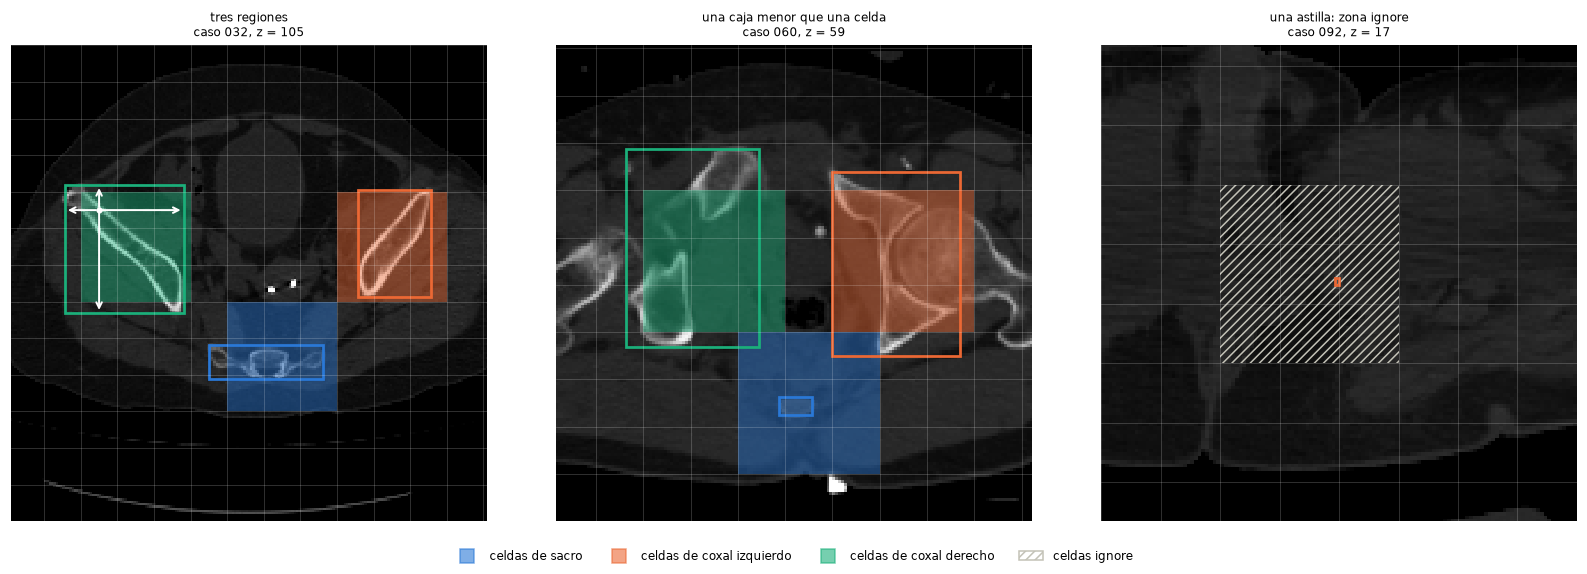

In [46]:
def encuadrar(ax, cajas, margen=24, minimo=64):
    #Ajusta la vista para mostrar las cajas
    xs = [v for c in cajas for v in (c[0], c[2])]
    ys = [v for c in cajas for v in (c[1], c[3])]
    cx, cy = (min(xs) + max(xs)) / 2, (min(ys) + max(ys)) / 2
    mitad = max((max(xs) - min(xs)) / 2 + margen, (max(ys) - min(ys)) / 2 + margen, minimo)
    ax.set_xlim(cx - mitad, cx + mitad)
    ax.set_ylim(cy + mitad, cy - mitad)


def dibujar_objetivos(ax, fila, titulo, flechas=False):
    # Muestra la grilla, las celdas positivas y las zonas ignore
    hu, lab = np.asarray(hu_cache[fila]), np.asarray(lab_cache[fila])
    cajas = cajas_por_region(lab)
    o = objetivos_deteccion(cajas)
    mostrar_corte(ax, hu, titulo=titulo)
    for j, i in np.argwhere(o["obj"] > 0):
        ax.add_patch(Rectangle((i * CELDA - 0.5, j * CELDA - 0.5), CELDA, CELDA,
                               fc=COLOR[o["clase"][j, i] + 1], alpha=0.45, ec="none"))
    for j, i in np.argwhere(o["ignore"]):
        ax.add_patch(Rectangle((i * CELDA - 0.5, j * CELDA - 0.5), CELDA, CELDA, fill=False, hatch="////",
                               ec=GRIS, lw=0))
    for g in range(GRID + 1):
        ax.axhline(g * CELDA - 0.5, color="white", lw=0.4, alpha=0.3)
        ax.axvline(g * CELDA - 0.5, color="white", lw=0.4, alpha=0.3)
    for k, (x0, y0, x1, y1) in cajas.items():
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.8))
    if flechas:                       
        k = max(cajas, key=lambda c: (cajas[c][2] - cajas[c][0]) * (cajas[c][3] - cajas[c][1]))
        j, i = np.argwhere(o["clase"] == k - 1)[0]
        cx, cy = CENTROS[i] - 0.5, CENTROS[j] - 0.5
        x0, y0, x1, y1 = (v - 0.5 for v in cajas[k])
        for destino in ((x0, cy), (x1, cy), (cx, y0), (cx, y1)):
            ax.annotate("", xy=destino, xytext=(cx, cy), arrowprops=dict(arrowstyle="->", color="white", lw=1.3))
        ax.plot(cx, cy, "o", color="white", ms=3)
    encuadrar(ax, cajas.values())


fig, axs = plt.subplots(1, 3, figsize=(15, 5))
for ax, nombre in zip(axs, ("tres regiones", "una caja menor que una celda", "una astilla: zona ignore")):
    dibujar_objetivos(ax, ejemplos[nombre], f"{nombre}\ncaso {indice.case_id.iat[ejemplos[nombre]]}, "
                      f"z = {indice.z.iat[ejemplos[nombre]]}", flechas=nombre == "tres regiones")
marcas = [plt.Line2D([], [], marker="s", ls="", ms=9, color=COLOR[k], alpha=0.6, label=f"celdas de {HUESO[k]}") for k in COLOR]
marcas.append(Rectangle((0, 0), 1, 1, fill=False, hatch="////", ec=GRIS, label="celdas ignore"))
fig.legend(handles=marcas, loc="lower center", ncol=4, fontsize=8, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

En la primera imagen, las flechas blancas representan las cuatro distancias que predice una celda hasta los bordes de la caja.

En la segunda, la caja pequeña del sacro no contiene el centro de ninguna celda. Aun así, algunas celdas cercanas son responsables de esa caja y pueden tener distancias negativas.

En la tercera, la caja es menor de 8 píxeles, por lo que no genera celdas positivas y su zona queda marcada como ignore.

### Decodificación y NMS propio

Ahora el proceso inverso al de los objetivos: pasamos de las predicciones de la grilla a las cajas finales.

El proceso es:

1. **Calcular la puntuación:** para cada celda calculamos `P(objeto) × P(clase)`. De esta forma, una clase solo tiene una puntuación alta cuando la celda también tiene una alta probabilidad de contener un objeto.

2. **Aplicar un umbral:** descartamos las predicciones cuya puntuación sea menor de `0.3`.

3. **Convertir las distancias en cajas:** usamos el centro de cada celda y las cuatro distancias `ltrb` para obtener las coordenadas `(x0, y0, x1, y1)` en píxeles.

4. **Aplicar NMS por clase:** varias celdas pueden detectar la misma región. NMS conserva la caja con mayor puntuación y elimina las cajas que tienen un IoU mayor de `0.5` con ella. Se hace por clase para no eliminar cajas de regiones diferentes.

5. **Limitar las detecciones:** opcionalmente podemos conservar solo la mejor caja de cada región.

La implementación de NMS es propia y está hecha en PyTorch. `torchvision.ops.nms` solamente se utiliza para comprobar que nuestra implementación funciona de la misma manera.

Antes de continuar con el entrenamiento hacemos varias comprobaciones: verificamos el cálculo del IoU, comparamos nuestro NMS con `torchvision` en 200 casos aleatorios y hacemos una prueba de ida y vuelta con cajas reales. En esta última prueba convertimos las cajas a objetivos de la grilla y después las volvemos a decodificar. Si todo está correcto, debemos recuperar las cajas originales.

In [47]:
def iou_cajas(a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    #Calcula el IoU entre pares de cajas
    area = lambda c: (c[:, 2] - c[:, 0]).clamp(min=0) * (c[:, 3] - c[:, 1]).clamp(min=0)  # noqa: E731
    esquina_sup = torch.max(a[:, None, :2], b[None, :, :2])
    esquina_inf = torch.min(a[:, None, 2:], b[None, :, 2:])
    inter = (esquina_inf - esquina_sup).clamp(min=0).prod(-1)
    return inter / (area(a)[:, None] + area(b)[None, :] - inter).clamp(min=1e-9)


def nms(cajas: torch.Tensor, puntuaciones: torch.Tensor, umbral: float = 0.5) -> torch.Tensor:
    #Aplica NMS y devuelve los índices de las cajas que se conservan
    orden = puntuaciones.argsort(descending=True)
    quedan = []
    while orden.numel():
        i, resto = orden[0], orden[1:]
        quedan.append(i)
        orden = resto[iou_cajas(cajas[i:i + 1], cajas[resto])[0] <= umbral]    
    return torch.stack(quedan) if quedan else orden


def decodificar(salida: dict, i: int, umbral: float = 0.3, umbral_nms: float = 0.5, max_det: int = 20,
                max_por_region: int | None = None):
    # Convierte las predicciones de la grilla en cajas, puntuaciones y clases.
    p = torch.sigmoid(salida["det_obj"][i].float())[..., None] * torch.softmax(salida["det_cls"][i].float(), -1)
    d = salida["det_ltrb"][i].float() * CELDA
    c = torch.as_tensor(CENTROS, dtype=torch.float32, device=p.device)
    cy, cx = torch.meshgrid(c, c, indexing="ij")
    cajas = torch.stack([cx - d[..., 0], cy - d[..., 1], cx + d[..., 2], cy + d[..., 3]], -1).clamp(0, bc.CROP_PX)
    por_clase = []
    for k in range(3):
        m = p[..., k] >= umbral
        ck, pk = cajas[m], p[..., k][m]
        q = nms(ck, pk, umbral_nms)[:max_por_region]
        por_clase.append((ck[q], pk[q], torch.full((len(q),), k, device=p.device)))
    cajas, puntuaciones, clases = (torch.cat(t) for t in zip(*por_clase))
    orden = puntuaciones.argsort(descending=True)[:max_det]
    return cajas[orden], puntuaciones[orden], clases[orden]

In [48]:
#Comprobación del IoU
a = torch.tensor([[0., 0., 10., 10.]])
assert float(iou_cajas(a, a)) == 1.0
assert float(iou_cajas(a, torch.tensor([[20., 20., 25., 25.]]))) == 0.0
assert abs(float(iou_cajas(a, torch.tensor([[5., 5., 15., 15.]]))) - 25 / 175) < 1e-6
print("IoU: idénticas 1, disjuntas 0, solapamiento parcial 25/175 ✓")

#Comprobación de NMS
cajas_toy = torch.tensor([[10, 10, 60, 60], [15, 15, 65, 65], [100, 100, 140, 140], [12, 12, 58, 58]], dtype=torch.float32)
assert set(nms(cajas_toy, torch.tensor([0.90, 0.75, 0.95, 0.60])).tolist()) == {0, 2}
g = torch.Generator().manual_seed(0)
for _ in range(200):
    k = int(torch.randint(1, 60, (1,), generator=g))
    esquinas = torch.rand(k, 2, generator=g) * 200
    aleatorias = torch.cat([esquinas, esquinas + torch.rand(k, 2, generator=g) * 60 + 2], 1)
    puntos, umbral_nms = torch.rand(k, generator=g), float(torch.rand(1, generator=g)) * 0.8 + 0.1
    assert set(nms(aleatorias, puntos, umbral_nms).tolist()) == set(torchvision.ops.nms(aleatorias, puntos, umbral_nms).tolist())
print("NMS: el ejemplo del curso conserva {0, 2} y coincide con torchvision.ops.nms en 200 casos aleatorios ✓")

# Prueba de ida y vuelta con cajas reales
error, n_cajas = 0.0, 0
for fila in muestra_t[:500]:
    cajas = cajas_por_region(np.asarray(lab_cache[fila]))
    o = objetivos_deteccion(cajas)
    perfecta = {"det_obj": torch.from_numpy(np.where(o["obj"] > 0, 12.0, -12.0))[None],
                "det_cls": torch.from_numpy(np.eye(3)[np.maximum(o["clase"], 0)] * 24 - 12)[None],
                "det_ltrb": torch.from_numpy(o["ltrb"])[None]}
    cj, _, cl = decodificar(perfecta, 0, umbral=0.5)
    evaluables = {k: c for k, c in cajas.items() if max(c[2] - c[0], c[3] - c[1]) >= LADO_MIN}
    assert sorted(int(c) + 1 for c in cl) == sorted(evaluables), f"fila {fila}: no sale una detección por caja"
    for caja, k in zip(cj, cl):
        error = max(error, float((caja - torch.tensor(evaluables[int(k) + 1], dtype=torch.float32)).abs().max()))
        n_cajas += 1
print(f"Ida y vuelta: {n_cajas} cajas de 500 cortes reales reconstruidas con un error máximo de {error:.2f} px ✓")

IoU: idénticas 1, disjuntas 0, solapamiento parcial 25/175 ✓


NMS: el ejemplo del curso conserva {0, 2} y coincide con torchvision.ops.nms en 200 casos aleatorios ✓


Ida y vuelta: 1246 cajas de 500 cortes reales reconstruidas con un error máximo de 0.00 px ✓


Las tres comprobaciones pasan: el IoU da lo que tiene que dar, el NMS propio conserva exactamente las mismas cajas que `torchvision.ops.nms` en 200 casos aleatorios, y codificar las cajas reales en la grilla y volver a decodificarlas las recupera sin un píxel de error.

 #### D13 · Detección *anchor-free* sobre una grilla propia de 16×16

 Las celdas cuyo centro está a menos de 1,5 celdas del centro de una caja son responsables de ella (unas 3×3); las distancias pueden ser negativas, el empate se resuelve por la caja de menor área y las cajas de menos de 8 px son zona *ignore* (D4).

 #### D14 · NMS propio, por clase

 Puntuación P(objeto)·P(clase), umbral 0,3, NMS con IoU 0,5 dentro de cada región. Implementado en PyTorch y comprobado contra torchvision, que no forma parte del pipeline.

## 2.4 · Segmentación de instancia

La tercera cabeza separa cada fragmento y lo colorea según su hueso. Combina una **salida semántica** (a qué hueso pertenece cada píxe) con una **salida de instancia** (a qué fragmento) y sigue una **lógica de dos etapas**: primero las regiones anatómicas, después los fragmentos dentro de cada una. Y el análisis exploratorio ya dejó cinco condiciones: hasta **4 fragmentos por hueso y corte** (D2), la **regla *ignore*** para lo que mide menos de 8 px (D4), **instancias por centro y desplazamiento** (D5), el **umbral de 1.600 mm³** para un fragmento real (D6) y el **enlace 3D** con ese filtro (D7).

### Qué hay que separar dentro de un corte

El análisis 5 midió la geometría de los fragmentos en 3D: el 89 % de los conminutos toca a su principal. Pero la cabeza trabaja corte a corte, y lo que fija sus parámetros es cómo se ven los fragmentos **en un corte**: cuánto miden, cuántos hay por hueso y a qué distancia quedan sus centros. Se mide sobre 3.000 cortes de entrenamiento con hueso.

In [49]:
# Geometría de los fragmentos tal como los verá la cabeza: corte a corte, en 3.000 cortes de entrenamiento con hueso
filas_geo = np.random.default_rng(0).choice(filas_train[indice.has_bone.to_numpy()[filas_train] == 1], 3000, replace=False)
areas, lados, separaciones, se_tocan, por_hueso = [], [], [], [], []
for fila in filas_geo:
    lab = np.asarray(lab_cache[fila])
    centros = {}
    for v in np.unique(lab[lab > 0]):
        ys, xs = np.nonzero(lab == v)
        areas.append(len(ys))
        lados.append(max(np.ptp(ys), np.ptp(xs)) + 1)
        centros[v] = (ys.mean(), xs.mean())
    for k in (1, 2, 3):
        vk = [v for v in centros if (v - 1) // 10 + 1 == k]
        if vk:
            por_hueso.append(len(vk))
        for i, a in enumerate(vk):
            for b in vk[i + 1:]:
                separaciones.append(np.hypot(*np.subtract(centros[a], centros[b])))
                se_tocan.append(bool((ndimage.binary_dilation(lab == a) & (lab == b)).any()))
areas, lados, separaciones = np.array(areas), np.array(lados), np.array(separaciones)

print(f"{len(areas):,} fragmentos en {len(filas_geo):,} cortes")
print("  área (px)            : " + " · ".join(f"p{p} {v:.0f}" for p, v in zip((5, 50, 95), np.percentile(areas, (5, 50, 95)))))
print("  lado mayor (px)      : " + " · ".join(f"p{p} {v:.0f}" for p, v in zip((5, 50, 95), np.percentile(lados, (5, 50, 95))))
      + f" · astillas (lado < {LADO_MIN} px): {(lados < LADO_MIN).mean():.1%}")
print(f"  fragmentos por hueso y corte: " + " · ".join(f"{n}: {c:,}" for n, c in enumerate(np.bincount(por_hueso)) if n))
print(f"\n{len(separaciones):,} pares de fragmentos del mismo hueso en un mismo corte:")
print("  distancia entre centros (px): " + " · ".join(
    f"p{p} {v:.1f}" for p, v in zip((1, 5, 50), np.percentile(separaciones, (1, 5, 50)))))
print(f"  se tocan en el corte: {np.mean(se_tocan):.0%}")

9,971 fragmentos en 3,000 cortes
  área (px)            : p5 27 · p50 435 · p95 1126
  lado mayor (px)      : p5 8 · p50 46 · p95 81 · astillas (lado < 8 px): 4.7%
  fragmentos por hueso y corte: 1: 5,664 · 2: 1,917 · 3: 143 · 4: 11

2,412 pares de fragmentos del mismo hueso en un mismo corte:
  distancia entre centros (px): p1 9.0 · p5 14.7 · p50 35.2
  se tocan en el corte: 47%


Cada cifra fija un parámetro de la cabeza o del decodificador:


El **4,7 %** de los fragmentos de un corte mide menos de 8 px de lado, por lo cual la **regla *ignore*** que se definió D4 vale también aquí: una astilla no tiene centro que aprender y no cuenta al evaluar, ni a favor ni en contra 

Nunca más de **4 fragmentos por hueso y corte**, asi que el decodificador busca como maximo 4 centros por hueso (D2) 

Dos centros del mismo hueso están a **14,7 px** o más en el 95 % de los pares, y a **9 px** o más en el 99 %. Un centro es el máximo de su vecindad de 9×9 px, así que dos picos a menos de 5 px en cada eje se funden en uno: ningún par real está tan cerca

El área va de **27 a 1.126 px** (percentiles 5 y 95), un factor 40. Para manejar esto la anchura del pico de cada centro se ajusta al fragmento: σ = máx(0,15·√área, 2) px

El **47 %** de los pares de fragmentos del mismo hueso se toca en el corte, etiquetar las piezas conexas los fundiría: hacen falta centros y desplazamientos (D5, ahora medida corte a corte)

### Los objetivos de la cabeza de instancia

La cabeza predice tres mapas a resolución completa, la receta de Panoptic-DeepLab (Cheng et al., 2020):

| Salida | Forma | Qué dice | Objetivo |
|---|---|---|---|
| `sem` | (4, 256, 256) | El macro-hueso de cada píxel: fondo, sacro, coxal izquierdo o coxal derecho | `a_hueso()` de la etiqueta |
| `ctr` | (3, 256, 256) | Un mapa de calor **por hueso**, con un pico en el centro de cada fragmento | Una gaussiana de altura 1 por fragmento, en el mapa de su hueso |
| `desp` | (2, 256, 256) | El vector (dy, dx) que lleva cada píxel de hueso al centro de su fragmento | Centroide menos posición, en celdas de 16 px |

Dos fragmentos que se tocan no tienen entre ellos ninguna frontera visible, pero sus píxeles apuntan a **centros distintos**: ahí está la separación. Y con un mapa de centros por hueso, en lugar de uno solo, un píxel del sacro nunca puede acabar en un fragmento del coxal.

Tres detalles del objetivo, cada uno con su razón:

- **El pico va al píxel más cercano al centroide y vale 1 exacto.** La pérdida de centros (2.6) reconoce los positivos por ese 1. Una primera versión del proyecto centraba la gaussiana en el centroide, que casi nunca cae en un píxel: el pico valía 0,994 de mediana, la pérdida apenas veía positivos y la cabeza aprendió a predecir cero en todas partes. Los desplazamientos sí apuntan al centroide exacto, así que no se pierde precisión.
- **Los picos se combinan con el máximo, no con la suma.** Dos gaussianas vecinas sumadas crearían un pico falso entre los dos fragmentos.
- **Las astillas no tienen pico** (regla *ignore*), aunque sus píxeles conservan su desplazamiento.

9,503 de 9,503 fragmentos (los que no son astillas) con su pico exactamente en 1 ✓
Desplazamientos: cada píxel de hueso + su vector = el centroide de su fragmento (error máximo 1.9e-06 px) ✓


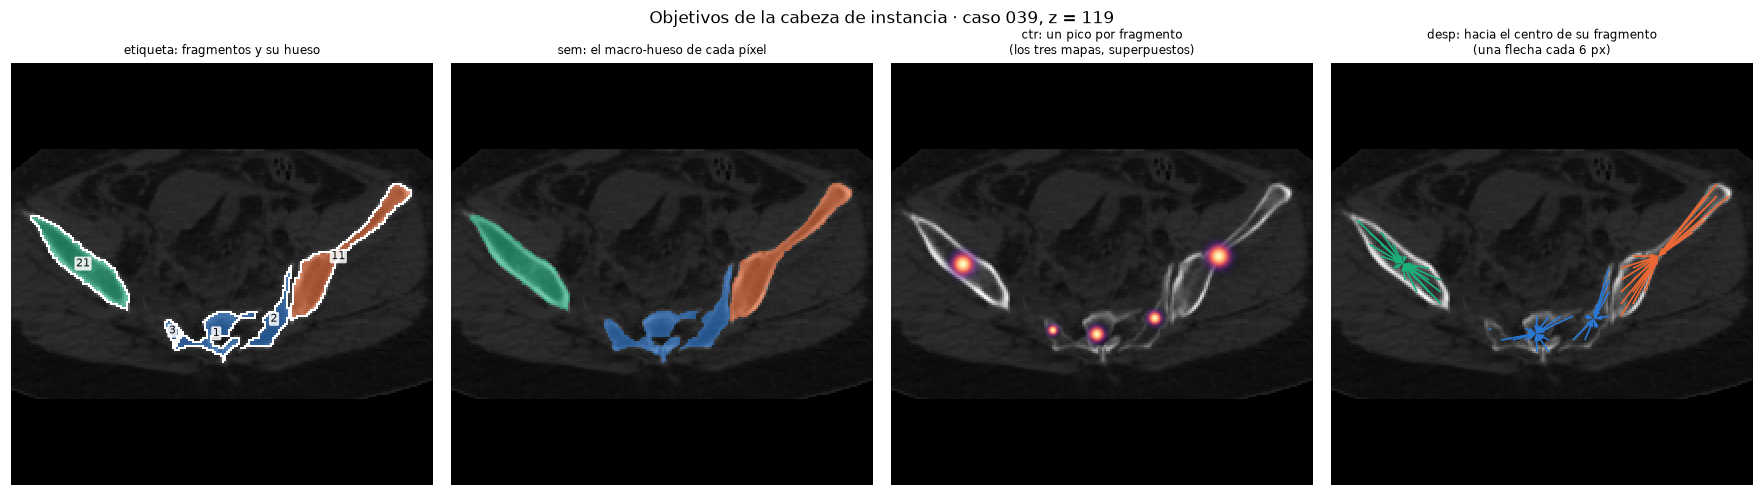

In [50]:
SIGMA_ESCALA, SIGMA_MIN = 0.15, 2.0      # anchura del pico de cada centro: σ = max(0,15·√área, 2) px


def es_astilla(ys, xs) -> bool:
    """Un fragmento de lado mayor < 8 px: la misma regla ignore que en la detección (decisión 4)."""
    return max(np.ptp(ys), np.ptp(xs)) + 1 < LADO_MIN


def pintar_gaussiana(mapa, cy, cx, sigma):
    """Gaussiana de pico 1 en el píxel (cy, cx), combinada con np.maximum: dos picos vecinos nunca se suman."""
    r = int(np.ceil(3 * sigma))
    y0, y1, x0, x1 = max(cy - r, 0), min(cy + r + 1, mapa.shape[0]), max(cx - r, 0), min(cx + r + 1, mapa.shape[1])
    yy, xx = np.ogrid[y0:y1, x0:x1]
    np.maximum(mapa[y0:y1, x0:x1], np.exp(-((yy - cy) ** 2 + (xx - cx) ** 2) / (2 * sigma ** 2)),
               out=mapa[y0:y1, x0:x1])


def objetivos_instancia(lab2d: np.ndarray) -> dict:
    """
    Etiqueta de un corte → objetivos de la cabeza de instancia: `sem` (H, W) con el macro-hueso de cada píxel,
    `ctr` (3, H, W) con un pico por fragmento en el mapa de su hueso y `desp` (2, H, W) con el vector (dy, dx), en
    celdas, que lleva cada píxel de hueso al centroide de su fragmento.
    """
    ctr = np.zeros((3, *lab2d.shape), np.float32)
    desp = np.zeros((2, *lab2d.shape), np.float32)
    for v in np.unique(lab2d[lab2d > 0]):
        ys, xs = np.nonzero(lab2d == v)
        cy, cx = ys.mean(), xs.mean()
        desp[0, ys, xs], desp[1, ys, xs] = (cy - ys) / CELDA, (cx - xs) / CELDA
        if not es_astilla(ys, xs):           # una astilla no tiene centro que aprender
            # El pico va al píxel más cercano al centroide, para que valga 1 exacto: la pérdida de centros
            # reconoce los positivos por ese 1 (con el centroide fraccionario casi no había ninguno)
            pintar_gaussiana(ctr[(v - 1) // 10], int(round(cy)), int(round(cx)),
                             max(SIGMA_ESCALA * np.sqrt(len(ys)), SIGMA_MIN))
    return {"sem": a_hueso(lab2d), "ctr": ctr, "desp": desp}


def encuadrar_corte(ax, cajas, **kw):
    """encuadrar (2.3) para un corte con números de fragmento: los que quedan fuera del encuadre no se dibujan."""
    encuadrar(ax, cajas, **kw)
    for t in ax.texts:
        t.set_clip_on(True)


# Comprobaciones sobre los 3.000 cortes del análisis anterior
picos_esperados = picos_exactos = 0
error_desp = 0.0
for fila in filas_geo:
    lab = np.asarray(lab_cache[fila])
    o = objetivos_instancia(lab)
    for v in np.unique(lab[lab > 0]):
        ys, xs = np.nonzero(lab == v)
        llega = np.stack([ys + o["desp"][0, ys, xs] * CELDA, xs + o["desp"][1, ys, xs] * CELDA])
        error_desp = max(error_desp, float(np.abs(llega - np.array([[ys.mean()], [xs.mean()]])).max()))
        if not es_astilla(ys, xs):
            picos_esperados += 1
            picos_exactos += o["ctr"][(v - 1) // 10, int(round(ys.mean())), int(round(xs.mean()))] == 1.0
assert picos_exactos == picos_esperados, "algún fragmento se queda sin un pico de valor exactamente 1"
assert error_desp < 1e-3, "los desplazamientos no llevan cada píxel al centroide de su fragmento"
print(f"{picos_exactos:,} de {picos_esperados:,} fragmentos (los que no son astillas) con su pico exactamente en 1 ✓")
print(f"Desplazamientos: cada píxel de hueso + su vector = el centroide de su fragmento (error máximo {error_desp:.1e} px) ✓")

# Un corte con un hueso en tres o más fragmentos, visto por dentro
tres = indice.loc[filas_geo, list(FRAG.values())].max(axis=1) >= 3
fila_i = int(filas_geo[tres.to_numpy()][0])
lab_i = np.asarray(lab_cache[fila_i])
o_i = objetivos_instancia(lab_i)
fig, axs = plt.subplots(1, 4, figsize=(16, 4.4), layout="constrained")
mostrar_corte(axs[0], np.asarray(hu_cache[fila_i]), lab_i, titulo="etiqueta: fragmentos y su hueso", fragmentos=True)
mostrar_corte(axs[1], np.asarray(hu_cache[fila_i]), np.where(lab_i > 0, (o_i["sem"].astype(int) - 1) * 10 + 1, 0),
              titulo="sem: el macro-hueso de cada píxel")
mostrar_corte(axs[2], np.asarray(hu_cache[fila_i]), titulo="ctr: un pico por fragmento\n(los tres mapas, superpuestos)")
calor = o_i["ctr"].max(0)
axs[2].imshow(calor, cmap="magma", vmin=0, vmax=1, alpha=np.clip(1.5 * calor, 0, 1))
mostrar_corte(axs[3], np.asarray(hu_cache[fila_i]), titulo="desp: hacia el centro de su fragmento\n(una flecha cada 6 px)")
yy, xx = np.mgrid[3:256:6, 3:256:6]
m = lab_i[yy, xx] > 0
axs[3].quiver(xx[m], yy[m], o_i["desp"][1][yy, xx][m] * CELDA, o_i["desp"][0][yy, xx][m] * CELDA,
              color=[COLOR[h] for h in o_i["sem"][yy, xx][m]], angles="xy", scale_units="xy", scale=1, width=0.004)
for ax in axs:
    encuadrar_corte(ax, cajas_por_region(lab_i).values(), margen=10)
fig.suptitle(f"Objetivos de la cabeza de instancia · caso {indice.case_id.iat[fila_i]}, z = {indice.z.iat[fila_i]}")
plt.show()

El primer `assert` es el que detecta el fallo del pico fraccionario: los 9.503 fragmentos que no son astillas tienen su pico exactamente en 1. En la figura, el sacro está roto en tres fragmentos que se tocan; la semántica los ve como una sola región, y son los picos del mapa de calor y las flechas, que convergen en tres puntos distintos, los que los separan.

### La cabeza de instancia

La cabeza cuelga de `p2`, el nivel de 1/4 que el *neck* calcula para ella, y sube hasta la resolución completa:

| Paso | Detalle | Por qué |
|---|---|---|
| `reducir` | conv 3×3 de `p2` (128 canales, 64×64) a 64 canales, GroupNorm y ReLU | Estrechar antes de subir: a 256×256 cada canal cuesta |
| `fundir` | ×2 bilineal, concatenación con `c1` —la salida del stem, 64 canales a 128×128— y conv 3×3 | El salto desde `c1` trae detalle de borde que `p2` ya no tiene; subir de 1/4 sin él solo interpola |
| `rama_sem` y `rama_inst` | ×2 hasta 256×256 y una conv 3×3 por rama: una para la semántica y otra, compartida, para centros y desplazamientos | Qué hueso es un píxel y a qué fragmento pertenece piden rasgos distintos: el decodificador doble de Panoptic-DeepLab separa las dos tareas por lo mismo. La calibración de 3.1 lo confirma con números |
| Salidas | conv 1×1: `sem` (4), `ctr` (3) y `desp` (2) | El sesgo de `ctr` arranca en una probabilidad del 1 %, como el de `obj` en la detección: casi ningún píxel es un centro |

**Por qué a resolución completa.** En un corte, el 5 % de los fragmentos mide 8 px de lado o menos, y dos centros pueden estar a 9 px (arriba). A 1/4 serían 2 px de lado y 2 px de separación: los fragmentos pequeños desaparecerían y los vecinos se fundirían.

Todo lo que sale de las cuatro etapas del tronco pasa por su CBAM (2.2); `c1` es la salida del stem, anterior a las etapas. `PelvisNetCompleta` hereda de `PelvisNet` el backbone y las dos cabezas de 2.3, sin cambiarlos, y añade la tercera.

In [51]:
class CabezaInstancia(nn.Module):
    """
    Segmentación de instancia a resolución completa, desde p2 (1/4) y la salida del stem c1 (1/2): `sem`, cuatro
    logits por píxel (fondo y los tres huesos); `ctr`, un mapa de calor de centros por hueso; y `desp`, el vector
    (dy, dx) hacia el centro del fragmento, en celdas. La última etapa se desdobla en una rama semántica y otra de
    instancia, como el decodificador doble de Panoptic-DeepLab (Cheng et al., 2020).
    """

    def __init__(self, canales=128, canales_c1=64, oculto=64, prior=0.01):
        super().__init__()
        bloque = lambda a, b: nn.Sequential(nn.Conv2d(a, b, 3, padding=1, bias=False),  # noqa: E731
                                            nn.GroupNorm(32, b), nn.ReLU(inplace=True))
        self.reducir = bloque(canales, oculto)                 # p2, a 1/4
        self.fundir = bloque(oculto + canales_c1, oculto)      # + c1, a 1/2: los bordes finos
        self.rama_sem = bloque(oculto, oculto)                 # a resolución completa: ¿de qué hueso es?
        self.rama_inst = bloque(oculto, oculto)                # ¿de qué fragmento?
        self.sem, self.ctr, self.desp = (nn.Conv2d(oculto, n, 1) for n in (4, 3, 2))
        nn.init.constant_(self.ctr.bias, -math.log((1 - prior) / prior))    # P(centro) inicial = 1 %, como obj

    def forward(self, p2, c1):
        x = F.interpolate(self.reducir(p2), size=c1.shape[-2:], mode="bilinear", align_corners=False)
        x = self.fundir(torch.cat([x, c1], 1))
        x = F.interpolate(x, scale_factor=2, mode="bilinear", align_corners=False)
        s, i = self.rama_sem(x), self.rama_inst(x)
        return {"sem": self.sem(s), "ctr": self.ctr(i), "desp": self.desp(i)}


class PelvisNetCompleta(PelvisNet):
    """PelvisNet con la tercera cabeza: clasificación, detección y segmentación de instancia sobre el mismo backbone."""

    def __init__(self, cbam=True, imagenet=True, desplazamientos=(0,)):
        super().__init__(cbam, imagenet, desplazamientos)
        self.cabeza_inst = CabezaInstancia()

    def forward(self, x):
        f = self.backbone(x)
        return {"cls": self.cabeza_cls(f["p5"]),
                **{f"det_{k}": v for k, v in self.cabeza_det(f["p4"]).items()},
                **{f"seg_{k}": v for k, v in self.cabeza_inst(f["p2"], f["c1"]).items()}}


modelo3 = PelvisNetCompleta(desplazamientos=DESP).to(DISPOSITIVO).to(memory_format=torch.channels_last)
with torch.no_grad(), precision_mixta():
    salida3 = modelo3(torch.randn(2, 3 * len(DESP), 256, 256, device=DISPOSITIVO))
print("Salidas para un lote de 2 cortes:")
for k, v in salida3.items():
    print(f"  {k:<9}: {tuple(v.shape)}")
print(f"\nParámetros: backbone {contar(modelo3.backbone) / 1e6:.2f} M · clasificación {contar(modelo3.cabeza_cls):,} · "
      f"detección {contar(modelo3.cabeza_det):,} · instancia {contar(modelo3.cabeza_inst):,} · total {contar(modelo3) / 1e6:.2f} M")
del modelo3, salida3

Salidas para un lote de 2 cortes:
  cls      : (2, 3)
  det_obj  : (2, 16, 16)
  det_cls  : (2, 16, 16, 3)
  det_ltrb : (2, 16, 16, 4)
  seg_sem  : (2, 4, 256, 256)
  seg_ctr  : (2, 3, 256, 256)
  seg_desp : (2, 2, 256, 256)

Parámetros: backbone 11.83 M · clasificación 33,795 · detección 296,456 · instancia 222,281 · total 12.38 M


La tercera cabeza añade 222.281 parámetros, un 1,8 % del modelo: el coste de la multitarea está en el backbone, que se comparte.

### El decodificador: de la región al fragmento

Es el eslabón que convierte los tres mapas en fragmentos coloreados por pertenencia, y donde se cumple la **lógica de dos etapas** del 3.2. Para cada hueso:

1. **La región.** Los píxeles que la semántica asigna a ese hueso. Con la **compuerta**, solo los que caen dentro de la caja que la detección encontró para él (ampliada 8 px, media celda); si la detección no lo vio y la clasificación dice que no está (probabilidad < 0,5), el hueso se descarta entero. Así el pipeline sigue el orden del  6: detección → NMS → segmentación de instancia → clasificación por pertenencia.
2. **Los centros.** Los máximos locales de su mapa de calor, en una vecindad de 9×9 px, por encima de 0,3; como mucho 4 (D2).
3. **Los fragmentos.** Cada píxel de la región se mueve según su vector y se asigna al centro más cercano **de ese hueso**. Si no hay ningún centro, el hueso entero es un fragmento.
4. **La pertenencia.** Cada fragmento se escribe en la codificación de PENGWIN, 10·(hueso − 1) + 1 + j, con j = 0 para el más grande del corte: se colorea con las mismas funciones que la etiqueta real, y la función de 1.13 podrá medir su separación. Los grupos de menos de 4 px de lado son ruido y vuelven al fondo; los de 4 a 7 px se conservan, porque un fragmento real de 8 o 9 px que el modelo dibuje un píxel más estrecho no debe perderse por una regla pensada para las astillas (la prueba de overfit de 2.8 se topó con uno así).

Y la métrica, que hay que fijar antes de mirar ningún número. El 5 pide **Dice e IoU de fragmento**. Los números que el modelo da a sus fragmentos son arbitrarios (su fragmento 1 puede ser el 2 de la etiqueta), así que primero se **emparejan**: dentro de cada hueso, con el algoritmo húngaro sobre el IoU, la asignación que maximiza el solapamiento total. Después:

- Cada fragmento real cuenta con el Dice de su pareja, o **0 si no la tiene**. Promediar solo los emparejados premiaría a un modelo que encontrase uno de cada diez.
- Un fragmento solo puede emparejarse con otro del mismo hueso: un error de hueso cuenta como no encontrado.
- **Regla *ignore* por los dos lados**, como en la detección: las astillas reales no cuentan, y un fragmento predicho que solo casa con una astilla no es un error.
- El Dice promedia sobre los fragmentos reales, así que no ve los que el modelo inventa: los **falsos positivos** se cuentan aparte.

La primera prueba es la de la detección (2.3): si la red predijera exactamente los objetivos, ¿saldrían los fragmentos reales? Al lado, la alternativa ingenua que descartó D5: cada pieza conexa de cada hueso, un fragmento.

In [ ]:
from scipy.optimize import linear_sum_assignment

UMBRAL_CENTRO, NUCLEO_PICOS, MAX_FRAG, MARGEN_CAJA, LADO_RUIDO = 0.3, 9, 4, 8, 4
COMPUERTA = True               # la decodificación de partida: la caja como compuerta y centros ≥ 0,3 (4.1 la elige)
YY, XX = np.indices((bc.CROP_PX, bc.CROP_PX), dtype=np.float32)


def picos(calor: np.ndarray, umbral: float = UMBRAL_CENTRO) -> np.ndarray:
    """Máximos locales (vecindad 9×9) de un mapa de calor por encima del umbral: (y, x) de los MAX_FRAG más altos."""
    pico = (calor == ndimage.maximum_filter(calor, NUCLEO_PICOS)) & (calor >= umbral)
    grupos, n = ndimage.label(pico)                    # una meseta de valores iguales es un solo pico
    if n == 0:
        return np.zeros((0, 2), int)
    yx = np.rint(ndimage.center_of_mass(pico, grupos, range(1, n + 1))).astype(int).reshape(-1, 2)
    return yx[np.argsort(-calor[yx[:, 0], yx[:, 1]])[:MAX_FRAG]]


def instancias(sem, calor, desp, compuerta=None, presencia=None, umbral=UMBRAL_CENTRO) -> np.ndarray:
    """
    Las dos etapas del  3.2. Primero, la región de cada hueso: los píxeles que la semántica le asigna y, con
    `compuerta` ({hueso: caja} de la detección), solo los que caen en su caja ampliada 8 px; un hueso sin caja y
    con presencia < 0,5 en la clasificación se descarta. Después, sus fragmentos: cada píxel vota, con su
    desplazamiento, por el centro más cercano de ESE hueso. Devuelve la etiqueta en la codificación de PENGWIN,
    10·(hueso − 1) + 1 + j, con j = 0 para el fragmento mayor del corte. Los grupos de menos de 4 px de lado son
    ruido y vuelven al fondo.
    """
    etiqueta = np.zeros(sem.shape, np.uint8)
    for k in (1, 2, 3):
        region = sem == k
        if compuerta is not None:
            if k in compuerta:
                x0, y0, x1, y1 = (int(round(v)) for v in compuerta[k])
                dentro = np.zeros_like(region)
                dentro[max(y0 - MARGEN_CAJA, 0):y1 + MARGEN_CAJA, max(x0 - MARGEN_CAJA, 0):x1 + MARGEN_CAJA] = True
                region &= dentro
            elif presencia is not None and presencia[k - 1] < 0.5:
                continue
        ys, xs = np.nonzero(region)
        if not len(ys):
            continue
        centros = picos(calor[k - 1], umbral)
        if len(centros):
            vy, vx = ys + desp[0, ys, xs] * CELDA, xs + desp[1, ys, xs] * CELDA
            grupo = ((vy[:, None] - centros[:, 0]) ** 2 + (vx[:, None] - centros[:, 1]) ** 2).argmin(1)
        else:
            grupo = np.zeros(len(ys), int)             # ningún centro: el hueso entero es un fragmento
        j = 0
        for g in np.argsort(-np.bincount(grupo)):      # del fragmento mayor al menor
            sel = grupo == g
            if sel.any() and max(np.ptp(ys[sel]), np.ptp(xs[sel])) + 1 >= LADO_RUIDO:
                etiqueta[ys[sel], xs[sel]] = 10 * (k - 1) + 1 + j
                j += 1
    return etiqueta


def emparejar(pred: np.ndarray, real: np.ndarray):
    """
    Fragmentos predichos frente a reales en un corte, emparejados DENTRO de cada hueso con el algoritmo húngaro
    sobre el IoU (una pareja necesita algún píxel en común). Devuelve una fila por fragmento real —hueso, etiqueta,
    si es astilla, área, su pareja (0 si no la tiene) y el Dice y el IoU con ella— y los predichos sin pareja. Un
    predicho emparejado con una astilla no es un falso positivo: la regla ignore va por los dos lados.
    """
    conjunta = np.bincount(pred.ravel().astype(np.int64) * 31 + real.ravel(), minlength=31 * 31).reshape(31, 31)
    area_p, area_r = conjunta.sum(1), conjunta.sum(0)
    trozos = ndimage.find_objects(real)
    filas, sin_pareja = [], []
    for k in (1, 2, 3):
        vr = [v for v in range(10 * k - 9, 10 * k + 1) if area_r[v]]
        vp = [v for v in range(10 * k - 9, 10 * k + 1) if area_p[v]]
        inter = conjunta[np.ix_(vp, vr)]
        iou = inter / (area_p[vp][:, None] + area_r[vr][None, :] - inter).clip(min=1)
        pareja = {}
        for a, b in zip(*linear_sum_assignment(-iou)):
            if inter[a, b] > 0:
                pareja[vr[b]] = vp[a]
        for v in vr:
            p = pareja.get(v)
            i = conjunta[p, v] if p else 0
            filas.append((k, v, max(s.stop - s.start for s in trozos[v - 1]) < LADO_MIN, int(area_r[v]), p or 0,
                          2 * i / (area_p[p] + area_r[v]) if p else 0.0, i / (area_p[p] + area_r[v] - i) if p else 0.0))
        sin_pareja += [(k, p) for p in vp if p not in pareja.values()]
    return filas, sin_pareja


COLUMNAS_FRAG = ["hueso", "etiqueta", "astilla", "area", "pareja", "dice", "iou"]


def resumen_fragmentos(resultados) -> dict:
    """
    Dice e IoU de fragmento sobre una lista de (filas, sin_pareja) por corte, con la regla ignore. El F1 de
    reconocimiento cuenta a la vez los no encontrados y los inventados, que el Dice no ve: 2·TP / (2·TP + FN + FP).
    """
    t = pd.DataFrame([f for filas, _ in resultados for f in filas], columns=COLUMNAS_FRAG)
    v = t[~t.astilla]
    no_encontrados, inventados = int((v.pareja == 0).sum()), sum(len(s) for _, s in resultados)
    tp = len(v) - no_encontrados
    return {"Dice": float(v.dice.mean()), "IoU": float(v.iou.mean()), "Dice de los encontrados": float(v.dice[v.pareja > 0].mean()),
            "fragmentos reales": len(v), "no encontrados": no_encontrados, "falsos positivos": inventados,
            "F1 de reconocimiento": 2 * tp / max(2 * tp + no_encontrados + inventados, 1),
            "Dice sin regla ignore": float(t.dice.mean()), "astillas": int(t.astilla.sum())}


def componentes_conexas(sem: np.ndarray) -> np.ndarray:
    """La alternativa ingenua: cada pieza conexa de cada hueso, un fragmento."""
    etiqueta = np.zeros(sem.shape, np.uint8)
    for k in (1, 2, 3):
        piezas, n = ndimage.label(sem == k)
        tam = np.bincount(piezas.ravel())[1:]
        for j, g in enumerate(np.argsort(-tam)[:10]):
            etiqueta[piezas == g + 1] = 10 * (k - 1) + 1 + j
    return etiqueta


# Ida y vuelta: si la red predijera exactamente los objetivos, ¿recuperaría el decodificador los fragmentos reales?
fracturados = indice.row[(indice.n_frag_total > indice.n_regions) & indice.row.isin(filas_train)].to_numpy()
muestra_d = np.random.default_rng(0).choice(fracturados, 500, replace=False)
por_centros, por_piezas = [], []
t0 = time.perf_counter()
for fila in muestra_d:
    lab = np.asarray(lab_cache[fila])
    o = objetivos_instancia(lab)
    por_centros.append(emparejar(instancias(o["sem"], o["ctr"], o["desp"]), lab))
    por_piezas.append(emparejar(componentes_conexas(o["sem"]), lab))
t_dec = (time.perf_counter() - t0) / len(muestra_d) / 2
ida_vuelta = pd.DataFrame({"centros + desplazamientos": resumen_fragmentos(por_centros),
                           "componentes conexas": resumen_fragmentos(por_piezas)}).T
assert ida_vuelta.loc["centros + desplazamientos", "Dice"] > 0.99, "el decodificador no invierte los objetivos"
print(f"{len(muestra_d)} cortes de entrenamiento con algún hueso fracturado, con objetivos perfectos "
      f"({1000 * t_dec:.1f} ms por corte, decodificar y emparejar)")
ida_vuelta.round(4).astype({c: int for c in ("fragmentos reales", "no encontrados", "falsos positivos", "astillas")})

500 cortes de entrenamiento con algún hueso fracturado, con objetivos perfectos (3.9 ms por corte, decodificar y emparejar)


,Dice,IoU,Dice de los encontrados,fragmentos reales,no encontrados,falsos positivos,F1 de reconocimiento,Dice sin regla ignore,astillas
centros + desplazamientos,0.9983,0.9974,0.9989,1802,1,0,0.9997,0.9635,93
componentes conexas,0.8202,0.7855,0.9249,1802,204,689,0.7816,0.8155,93


Con los objetivos perfectos, el decodificador recupera los fragmentos reales con un Dice de 0,998; lo que falta hasta 1 son los píxeles de las astillas, que no tienen centro propio y se van con el fragmento vecino. Las piezas conexas, con la **misma** semántica perfecta, se quedan en 0,820: no encuentran 204 de los 1.802 fragmentos (los que se tocan con otro del mismo hueso, fundidos en uno) e inventan 689, porque un fragmento cortado por el plano del corte puede aparecer en varias piezas. Esa diferencia es D5, medida.

La penúltima columna da la escala de la regla *ignore*: si las 93 astillas contasen, ni siquiera los objetivos perfectos pasarían de 0,964, porque una astilla no tiene centro propio y solo se recupera cuando es lo único que hay de su hueso en el corte. Sin la regla, ese hueco se confundiría con un fallo del modelo.

 #### D15 · Un mapa de centros por hueso, con el pico anclado al píxel

 Gaussiana de altura exactamente 1 en el píxel más cercano al centroide, σ = máx(0,15·√área, 2) px, combinada con el máximo; desplazamientos al centroide exacto, en celdas. Ningún píxel de un hueso puede acabar en un fragmento de otro.

 #### D16 · Decodificación en dos etapas, con la detección como compuerta

 Primero la región de cada hueso (la semántica, acotada por la caja que encontró la detección); después sus fragmentos, votando cada píxel por el centro más cercano de ese hueso. Es la lógica de dos etapas del  3.2 y el orden del  6: detección → NMS → instancia → pertenencia.

 #### D17 · Métrica de fragmento: emparejamiento por hueso y regla *ignore* por los dos lados

 Algoritmo húngaro sobre el IoU dentro de cada hueso; un fragmento real sin pareja cuenta 0; las astillas de menos de 8 px no cuentan ni a favor ni en contra; los inventados se cuentan aparte (F1 de reconocimiento).

## 2.5 · El modelo completo

Las tres cabezas sobre el mismo backbone: clasificación sobre `p5`, detección sobre `p4` e instancia sobre `p2` y `c1`. La celda cuenta los parámetros de cada pieza y comprueba la promesa de 2.2: recién creado, **el modelo da exactamente las mismas salidas con los vecinos reales que con ruido en su lugar**, porque los pesos de `conv1_vecinos` empiezan en cero.

In [53]:
fijar_semilla(0)
modelo3 = PelvisNetCompleta(desplazamientos=DESP).eval()
x25 = torch.from_numpy(entrada_25d(int(candidatas.iat[len(candidatas) // 2])))[None]
with torch.no_grad():
    a = modelo3(x25)
    b = modelo3(torch.cat([x25[:, :3], torch.rand_like(x25[:, 3:])], 1))
assert all(torch.equal(a[k], b[k]) for k in a), "al empezar, los vecinos no deberían cambiar nada"
print("Salidas para un corte:")
for k, v in a.items():
    print(f"  {k:<9}: {tuple(v.shape)}")
partes = {"tronco (con conv1_vecinos y CBAM)": modelo3.backbone.tronco, "neck FPN": modelo3.backbone.fpn,
          "cabeza de clasificación": modelo3.cabeza_cls, "cabeza de detección": modelo3.cabeza_det,
          "cabeza de instancia": modelo3.cabeza_inst}
print(f"\nParámetros: {contar(modelo3) / 1e6:.2f} M en total")
for nombre, m in partes.items():
    print(f"  {nombre:<34} {contar(m):>12,}  ({contar(m) / contar(modelo3):.1%})")
print("\nRecién creado, el modelo da lo mismo con los vecinos reales que con ruido en su lugar ✓")
del modelo3

Salidas para un corte:
  cls      : (1, 3)
  det_obj  : (1, 16, 16)
  det_cls  : (1, 16, 16, 3)
  det_ltrb : (1, 16, 16, 4)
  seg_sem  : (1, 4, 256, 256)
  seg_ctr  : (1, 3, 256, 256)
  seg_desp : (1, 2, 256, 256)

Parámetros: 12.38 M en total
  tronco (con conv1_vecinos y CBAM)    11,259,600  (91.0%)
  neck FPN                                566,016  (4.6%)
  cabeza de clasificación                  33,795  (0.3%)
  cabeza de detección                     296,456  (2.4%)
  cabeza de instancia                     222,281  (1.8%)

Recién creado, el modelo da lo mismo con los vecinos reales que con ruido en su lugar ✓


El modelo tiene 12,4 millones de parámetros, y el 95 % está en el backbone compartido: las tres cabezas juntas no llegan al 5 %. El coste de la multitarea está en el tronco, que las tres aprovechan.

## 2.6 · La pérdida compuesta: siete términos

Cada salida tiene su término, elegido para lo que mide:

| Término | Salida | Forma | Por qué |
|---|---|---|---|
| `cls` | clasificación del corte | entropía cruzada binaria | Tres sigmoides independientes (D1) |
| `obj` | *objectness* de cada celda | Focal Loss (Lin et al., 2017), sin las celdas *ignore* | Casi todas las celdas son negativas: la focal quita peso a las fáciles |
| `box` | caja de cada celda positiva | 1 − CIoU | Además del solapamiento, castiga la distancia entre centros y la diferencia de forma; funciona también con distancias negativas |
| `dcls` | región de cada celda positiva | entropía cruzada | Cada caja pertenece a una sola región |
| `sem` | el hueso de cada píxel | entropía cruzada + (1 − Dice blando) | La entropía aprende píxel a píxel; el Dice mide el solapamiento relativo a cada hueso y evita que el fondo, casi todo el corte, domine |
| `ctr` | los centros de los fragmentos | focal de CenterNet (Law y Deng, 2018), α = 2, β = 4 | Los negativos cerca de un centro se castigan menos, por (1 − y)^β: un píxel a dos de distancia casi acierta |
| `desp` | el desplazamiento hacia el centro | L1, solo sobre los píxeles de hueso | Fuera del hueso un desplazamiento no significa nada |

$$\mathcal{L} = \lambda_{cls}\mathcal{L}_{cls} + \lambda_{obj}\mathcal{L}_{obj} + \lambda_{box}\mathcal{L}_{box} + \lambda_{dcls}\mathcal{L}_{dcls} + \lambda_{sem}\mathcal{L}_{sem} + \lambda_{ctr}\mathcal{L}_{ctr} + \lambda_{desp}\mathcal{L}_{desp}$$

Los λ no se copian de ninguna implementación: se calibran con el propio modelo y los propios datos en 3.1 ( 4.1). Primero, los cuatro términos de la clasificación y la detección, con sus comprobaciones:

In [54]:
def focal(logits, objetivo, alfa=0.25, gamma=2.0):
    #Calcula la Focal Loss sin reducir
    p = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, objetivo, reduction="none")
    p_t = p * objetivo + (1 - p) * (1 - objetivo)
    return (alfa * objetivo + (1 - alfa) * (1 - objetivo)) * (1 - p_t) ** gamma * ce

def ciou(pred, obj, eps=1e-7):
    #Calcula 1 - CIoU entre las cajas predichas y las reales
    a = torch.stack([-pred[:, 0], -pred[:, 1], pred[:, 2], pred[:, 3]], -1)     
    b = torch.stack([-obj[:, 0], -obj[:, 1], obj[:, 2], obj[:, 3]], -1)
    wa, ha = (a[:, 2] - a[:, 0]).clamp(min=eps), (a[:, 3] - a[:, 1]).clamp(min=eps)
    wb, hb = (b[:, 2] - b[:, 0]).clamp(min=eps), (b[:, 3] - b[:, 1]).clamp(min=eps)
    inter = ((torch.min(a[:, 2], b[:, 2]) - torch.max(a[:, 0], b[:, 0])).clamp(min=0)
             * (torch.min(a[:, 3], b[:, 3]) - torch.max(a[:, 1], b[:, 1])).clamp(min=0))
    iou = inter / (wa * ha + wb * hb - inter + eps)
    diagonal2 = ((torch.max(a[:, 2], b[:, 2]) - torch.min(a[:, 0], b[:, 0])) ** 2          
                 + (torch.max(a[:, 3], b[:, 3]) - torch.min(a[:, 1], b[:, 1])) ** 2 + eps)
    centros2 = ((a[:, 0] + a[:, 2] - b[:, 0] - b[:, 2]) ** 2 + (a[:, 1] + a[:, 3] - b[:, 1] - b[:, 3]) ** 2) / 4
    v = (4 / math.pi ** 2) * (torch.atan(wb / hb) - torch.atan(wa / ha)) ** 2              
    with torch.no_grad():
        alfa = v / (1 - iou + v + eps)
    return 1 - iou + centros2 / diagonal2 + alfa * v


TERMINOS = ("cls", "obj", "box", "dcls")


def perdida(salida: dict, lote: dict, lambdas: dict):
    #Calcula la pérdida total y sus cuatro componentes
    pos = lote["obj"] > 0
    n_pos = pos.sum().clamp(min=1)
    partes = {
        "cls": F.binary_cross_entropy_with_logits(salida["cls"].float(), lote["huesos"]),
        "obj": (focal(salida["det_obj"].float(), lote["obj"]) * ~lote["ignore"]).sum() / n_pos,
        "box": ciou(salida["det_ltrb"].float()[pos], lote["ltrb"][pos]).sum() / n_pos,
        "dcls": (F.cross_entropy(salida["det_cls"].float()[pos], lote["clase"][pos]) if pos.any()
                 else salida["det_cls"].sum() * 0.0),
    }
    return sum(lambdas[k] * partes[k] for k in TERMINOS), partes

## Comprobaciones de CIoU
assert float(ciou(torch.tensor([[1., 2., 3., 4.]]), torch.tensor([[1., 2., 3., 4.]]))) < 1e-6
assert float(ciou(torch.tensor([[-0.5, 1., 2., 3.]]), torch.tensor([[-0.5, 1., 2., 3.]]))) < 1e-6
assert float(ciou(torch.tensor([[1., 1., -0.5, 1.]]), torch.tensor([[-2., 1., 3., 1.]]))) > 1
print("CIoU: 0 para cajas idénticas (también con distancias negativas) y > 1 para cajas disjuntas ✓")

CIoU: 0 para cajas idénticas (también con distancias negativas) y > 1 para cajas disjuntas ✓


Y los tres de la segmentación de instancia. La comprobación usa el corte de la figura de 2.4. La salida perfecta para la focal no es la gaussiana, sino un pico puntual en cada centro: la gaussiana solo rebaja el castigo de los negativos cercanos, y la pérdida sigue bajando cuanto más estrecho es el pico.

In [55]:
TERMINOS3 = TERMINOS + ("sem", "ctr", "desp")


def dice_blando(logits, objetivo):
    """1 − Dice medio de los huesos presentes en el lote, con las probabilidades del softmax (no con el argmax)."""
    p = torch.softmax(logits, 1)[:, 1:]
    y = F.one_hot(objetivo, 4).permute(0, 3, 1, 2)[:, 1:].float()
    inter, card = (p * y).sum((0, 2, 3)), (p + y).sum((0, 2, 3))
    presentes = y.sum((0, 2, 3)) > 0
    return 1 - (2 * inter / card.clamp(min=1e-6))[presentes].mean() if presentes.any() else logits.sum() * 0.0


def focal_centros(logits, objetivo, alfa=2.0, beta=4.0):
    """
    Focal de CenterNet (Law y Deng, 2018): positivos los píxeles donde el objetivo vale 1 exacto; el resto son
    negativos, menos castigados cuanto más cerca de un centro, por (1 − objetivo)^β. Normalizada por el n.º de centros.
    """
    p = torch.sigmoid(logits).clamp(1e-4, 1 - 1e-4)
    pos = objetivo == 1
    l = torch.where(pos, -(1 - p) ** alfa * torch.log(p), -(1 - objetivo) ** beta * p ** alfa * torch.log(1 - p))
    return l.sum() / pos.sum().clamp(min=1)


def perdida_completa(salida: dict, lote: dict, lambdas: dict):
    """Los cuatro términos de la clasificación y la detección y los tres de la instancia, cada uno por separado."""
    _, partes = perdida(salida, lote, dict.fromkeys(TERMINOS, 1.0))
    sem, hueso = salida["seg_sem"].float(), lote["fg"]
    partes["sem"] = F.cross_entropy(sem, lote["sem"]) + dice_blando(sem, lote["sem"])
    partes["ctr"] = focal_centros(salida["seg_ctr"].float(), lote["ctr"])
    partes["desp"] = ((salida["seg_desp"].float() - lote["desp"]).abs().sum(1) * hueso).sum() / hueso.sum().clamp(min=1)
    return sum(lambdas[k] * partes[k] for k in TERMINOS3), partes


# Comprobaciones con el corte fracturado de 2.4: la salida perfecta —un pico puntual en cada centro, la semántica
# exacta y los desplazamientos exactos— da pérdidas nulas, y la focal ve un positivo por fragmento
o = objetivos_instancia(lab_i)
sem_t, ctr_t, desp_t = (torch.from_numpy(o[k])[None] for k in ("sem", "ctr", "desp"))
sem_t = sem_t.long()
perfecta = {"seg_sem": F.one_hot(sem_t, 4).permute(0, 3, 1, 2).float() * 30,
            "seg_ctr": torch.where(ctr_t == 1, 30.0, -30.0), "seg_desp": desp_t}
l_sem = F.cross_entropy(perfecta["seg_sem"], sem_t) + dice_blando(perfecta["seg_sem"], sem_t)
l_ctr, l_ctr_ini = focal_centros(perfecta["seg_ctr"], ctr_t), focal_centros(torch.full_like(ctr_t, -4.6), ctr_t)
n_frag = sum(not es_astilla(*np.nonzero(lab_i == v)) for v in np.unique(lab_i[lab_i > 0]))
print(f"Salida perfecta: sem {float(l_sem):.1e} · ctr {float(l_ctr):.1e} · desp 0 por construcción "
      f"(ctr al inicio, con todo el mapa al 1 %: {float(l_ctr_ini):.2f})")
print(f"Positivos que ve la pérdida de centros: {int((ctr_t == 1).sum())}, uno por cada uno de los {n_frag} fragmentos del corte")
assert float(l_sem) < 1e-3 and float(l_ctr) < 1e-3 and int((ctr_t == 1).sum()) == n_frag

Salida perfecta: sem 0.0e+00 · ctr 3.9e-08 · desp 0 por construcción (ctr al inicio, con todo el mapa al 1 %: 4.56)
Positivos que ve la pérdida de centros: 5, uno por cada uno de los 5 fragmentos del corte


## 2.7 · Lotes de entrenamiento y augmentación 2.5D

`preparar_lote()` toma las imágenes y etiquetas del caché y las convierte en un lote que puede recibir el modelo.

Durante el entrenamiento aplicamos algunas transformaciones a las imágenes para aumentar la variedad de los datos. Estas transformaciones son moderadas porque las imágenes de una pelvis tienen una geometría bastante específica.

Las transformaciones utilizadas son:


- Volteo horizontal: Probabilidad de 0,5 e intercambio de las etiquetas izquierda y derecha
- Rotación, escala y traslación: Rotación de ±15°, escala de 0,9 a 1,1 y traslación de hasta ±10 %
- Ruido gaussiano: σ = 10 HU
- Jitter de ventana: Variación de ±5 % en los límites de las ventanas

En el volteo horizontal también se intercambian las etiquetas de los coxales izquierdo y derecho. Esto es necesario porque al voltear la imagen también cambia su posición.

Primero se transforma la imagen y su etiqueta y después se calculan las cajas y los objetivos de detección. De esta forma, las cajas corresponden a la nueva posición de los huesos.

Para preparar los lotes se utiliza un hilo que prepara el siguiente lote mientras la GPU procesa el actual.

**Con la entrada 2.5D, la transformación se sortea una vez por pila y se aplica igual a todos sus cortes**, como si se moviera al paciente entero: si cada vecino se girase por su cuenta, dejaría de estar alineado con el central y el contexto vertical se convertiría en ruido. La etiqueta que se transforma es solo la del corte central, la que da los objetivos. La celda lo comprueba: aumentar cada corte por separado con el generador en el mismo estado da exactamente lo mismo que aumentar la pila entera.


#### D18 · Una sola transformación por pila

 El volteo, el giro, la escala y la traslación se sortean una vez por pila y se aplican igual a sus cinco cortes; los objetivos se calculan después, sobre la etiqueta del corte central ya transformada.

In [56]:
INTERCAMBIO = np.arange(31, dtype=np.uint8)
INTERCAMBIO[11:21] += 10
INTERCAMBIO[21:31] -= 10
LO, HI = (np.array(v, np.float32) for v in zip(*VENTANAS))


def aumentar(hu, lab, rng):
    #Aplica la augmentación a la pila (S, H, W) y a la etiqueta del corte central: la MISMA transformación a todos los cortes
    if rng.random() < 0.5:
        hu, lab = hu[:, :, ::-1], INTERCAMBIO[lab[:, ::-1]]
    if rng.random() < 0.8:
        m = cv2.getRotationMatrix2D((128, 128), rng.uniform(-15, 15), rng.uniform(0.9, 1.1))
        m[:, 2] += rng.uniform(-0.1, 0.1, 2) * bc.CROP_PX
        lado = (bc.CROP_PX, bc.CROP_PX)
        hu = np.stack([cv2.warpAffine(np.ascontiguousarray(h, np.float32), m, lado, flags=cv2.INTER_LINEAR,
                                      borderValue=bc.AIR_HU) for h in hu])
        lab = cv2.warpAffine(np.ascontiguousarray(lab), m, lado, flags=cv2.INTER_NEAREST, borderValue=0)
    return hu, lab


def ventanear_pila(hu, lo=LO, hi=HI):
    # Pila en HU (S, H, W) → (3·S, H, W) en [0, 1]: las tres ventanas de cada corte, el central primero
    x = np.clip((np.asarray(hu, np.float32)[:, None] - lo[:, None, None]) / (hi - lo)[:, None, None], 0, 1)
    return x.reshape(-1, *x.shape[2:])


def preparar_lote(filas, rng=None, desplazamientos=DESP) -> dict:
    #Prepara un lote de pilas 2.5D, etiquetas del corte central y objetivos
    imagenes, huesos, cajas, objetivos = [], [], [], []
    for fila in filas:
        hu, lab = np.asarray(hu_cache[filas_vecinas(fila, desplazamientos)], np.float32), np.asarray(lab_cache[fila])
        lo, hi = LO, HI
        if rng is not None:
            hu, lab = aumentar(hu, lab, rng)
            hu = hu + 10 * rng.standard_normal(hu.shape, dtype=np.float32)
            lo = LO * rng.uniform(0.95, 1.05, 3).astype(np.float32)
            hi = HI * rng.uniform(0.95, 1.05, 3).astype(np.float32)
        imagenes.append(ventanear_pila(hu, lo, hi))     # (3·S, H, W)
        c = cajas_por_region(lab)                       # DESPUÉS de transformar la etiqueta
        cajas.append(c)
        huesos.append([float(k in c) for k in (1, 2, 3)])
        objetivos.append(objetivos_deteccion(c))
    lote = {k: torch.from_numpy(np.stack([o[k] for o in objetivos])) for k in objetivos[0]}
    lote["imagen"] = torch.from_numpy(np.stack(imagenes))
    lote["huesos"] = torch.tensor(huesos)
    lote = {k: v.to(DISPOSITIVO, non_blocking=True) for k, v in lote.items()}
    lote["imagen"] = lote["imagen"].contiguous(memory_format=torch.channels_last)
    lote["cajas"], lote["filas"] = cajas, np.asarray(filas)
    return lote


def lotes(filas, tam=16, rng=None, desplazamientos=DESP):
    #Genera los lotes de entrenamiento.
    if rng is not None:
        filas = rng.permutation(filas)
    trozos = [filas[i:i + tam] for i in range(0, len(filas), tam)]
    with ThreadPoolExecutor(1) as hilo:
        futuro = hilo.submit(preparar_lote, trozos[0], rng, desplazamientos)
        for siguiente in trozos[1:] + [None]:
            lote = futuro.result()
            if siguiente is not None:
                futuro = hilo.submit(preparar_lote, siguiente, rng, desplazamientos)
            yield lote

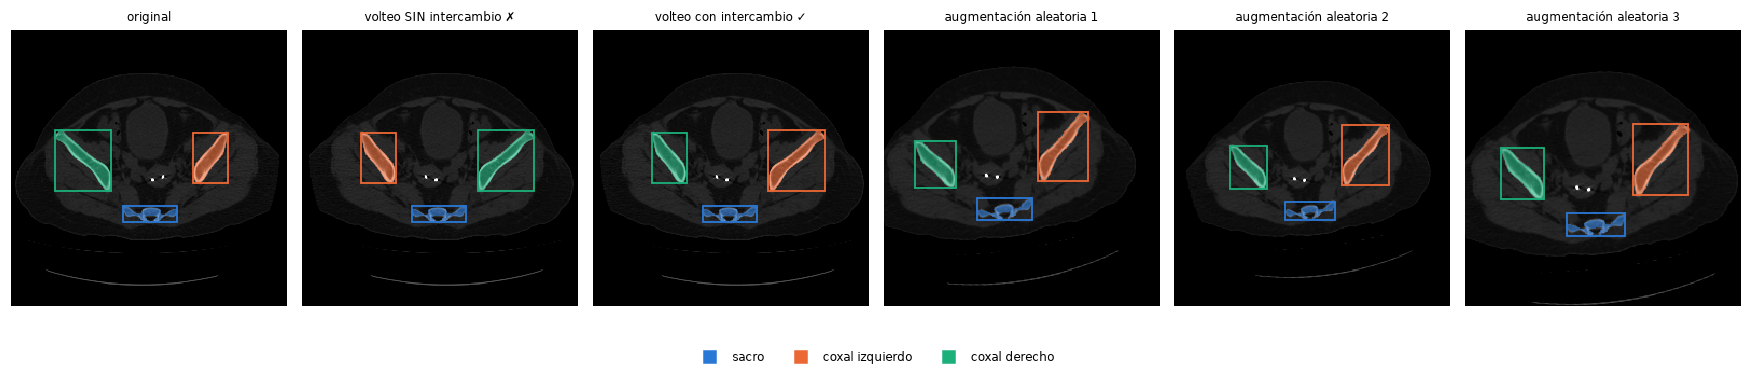

La augmentación transforma igual los 5 cortes de la pila ✓


Preparar un lote de 16 pilas sin augmentación: 62 ms


Preparar un lote de 16 pilas con augmentación: 117 ms
Contenido del lote: obj (16, 16, 16) · clase (16, 16, 16) · ltrb (16, 16, 16, 4) · ignore (16, 16, 16) · imagen (16, 15, 256, 256) · huesos (16, 3)


In [57]:
fila_a = ejemplos["tres regiones"]
pila0, lab0 = np.asarray(hu_cache[filas_vecinas(fila_a)], np.float32), np.asarray(lab_cache[fila_a])
hu0 = pila0[0]                                                  # el corte central de la pila
rng = np.random.default_rng(3)
vistas = [(hu0, lab0, "original"),
          (hu0[:, ::-1], lab0[:, ::-1], "volteo SIN intercambio ✗"),
          (hu0[:, ::-1], INTERCAMBIO[lab0[:, ::-1]], "volteo con intercambio ✓")]
for i in (1, 2, 3):
    pila_a, lab_a = aumentar(pila0, lab0, rng)
    vistas.append((pila_a[0], lab_a, f"augmentación aleatoria {i}"))

fig, axs = plt.subplots(1, 6, figsize=(16, 3.4))
for ax, (h, l, titulo) in zip(axs, vistas):
    mostrar_corte(ax, h, l, titulo=titulo)
    for k, (x0, y0, x1, y1) in cajas_por_region(l).items():
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.2))
leyenda_huesos(fig, loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

# La misma transformación para toda la pila: aumentar cada corte por separado, con el generador en el mismo estado,
# da exactamente el mismo resultado que aumentar la pila entera
g = np.random.default_rng(7)
estado = g.bit_generator.state
pila_aug, _ = aumentar(pila0, lab0, g)
for j in range(len(pila0)):
    g.bit_generator.state = estado
    assert np.array_equal(aumentar(pila0[j:j + 1], lab0, g)[0][0], pila_aug[j]), "un corte de la pila se transformó distinto"
print(f"La augmentación transforma igual los {len(pila0)} cortes de la pila ✓")

rng = np.random.default_rng(0)
for nombre, r in (("sin augmentación", None), ("con augmentación", rng)):
    t0 = time.perf_counter()
    for _ in range(10):
        lote = preparar_lote(rng.choice(filas_train, 16), r)
    torch.cuda.synchronize() if DISPOSITIVO.type == "cuda" else None
    print(f"Preparar un lote de 16 pilas {nombre}: {100 * (time.perf_counter() - t0):.0f} ms")
print("Contenido del lote: " + " · ".join(f"{k} {tuple(v.shape)}" for k, v in lote.items() if torch.is_tensor(v)))

### Lotes con los objetivos de las tres cabezas

La misma augmentación, sorteada una vez por pila (volteo con intercambio de lateralidad, transformación afín, ruido y variación de las ventanas), con los objetivos de instancia calculados **después** de transformar la etiqueta, igual que las cajas. `lotes_completos` prepara el lote siguiente en un hilo mientras la GPU procesa el actual. Se mide cuánto cuesta un lote con cada una de las tres pilas y un paso de entrenamiento del modelo completo, que es lo que decide la duración del entrenamiento.

In [58]:
def preparar_lote_completo(filas, rng=None, desplazamientos=DESP) -> dict:
    """preparar_lote con los objetivos de la cabeza de instancia, calculados sobre la etiqueta ya transformada."""
    imagenes, huesos, cajas, det, inst, etiquetas = [], [], [], [], [], []
    for fila in filas:
        hu, lab = np.asarray(hu_cache[filas_vecinas(fila, desplazamientos)], np.float32), np.asarray(lab_cache[fila])
        lo, hi = LO, HI
        if rng is not None:
            hu, lab = aumentar(hu, lab, rng)
            hu = hu + 10 * rng.standard_normal(hu.shape, dtype=np.float32)
            lo = LO * rng.uniform(0.95, 1.05, 3).astype(np.float32)
            hi = HI * rng.uniform(0.95, 1.05, 3).astype(np.float32)
        imagenes.append(ventanear_pila(hu, lo, hi))
        c = cajas_por_region(lab)
        cajas.append(c)
        huesos.append([float(k in c) for k in (1, 2, 3)])
        det.append(objetivos_deteccion(c))
        inst.append(objetivos_instancia(lab))
        etiquetas.append(lab)
    lote = {k: torch.from_numpy(np.stack([o[k] for o in det + inst if k in o])) for k in (*det[0], *inst[0])}
    lote["imagen"] = torch.from_numpy(np.stack(imagenes))
    lote["huesos"] = torch.tensor(huesos)
    lote = {k: v.to(DISPOSITIVO, non_blocking=True) for k, v in lote.items()}
    lote["imagen"] = lote["imagen"].contiguous(memory_format=torch.channels_last)
    lote["sem"] = lote["sem"].long()
    lote["fg"] = lote["sem"] > 0
    lote["cajas"], lote["filas"], lote["etiquetas"] = cajas, np.asarray(filas), np.stack(etiquetas)
    return lote


def lotes_completos(filas, tam=16, rng=None, desplazamientos=DESP):
    """lotes con preparar_lote_completo: un hilo prepara el lote siguiente mientras la GPU procesa el actual."""
    if rng is not None:
        filas = rng.permutation(filas)
    trozos = [filas[i:i + tam] for i in range(0, len(filas), tam)]
    with ThreadPoolExecutor(1) as hilo:
        futuro = hilo.submit(preparar_lote_completo, trozos[0], rng, desplazamientos)
        for siguiente in trozos[1:] + [None]:
            lote = futuro.result()
            if siguiente is not None:
                futuro = hilo.submit(preparar_lote_completo, siguiente, rng, desplazamientos)
            yield lote


rng = np.random.default_rng(0)
for nombre, d in VARIANTES_25D.items():
    t0 = time.perf_counter()
    for _ in range(10):
        lote = preparar_lote_completo(rng.choice(filas_train, 16), rng, d)
    print(f"Preparar un lote de 16 pilas {nombre} con augmentación y los objetivos de las tres cabezas: "
          f"{100 * (time.perf_counter() - t0):.0f} ms")
print("Contenido (5 cortes): " + " · ".join(f"{k} {tuple(v.shape)}" for k, v in lote.items() if torch.is_tensor(v)))

# Coste de un paso de entrenamiento del modelo completo, con los lotes preparados en paralelo
fijar_semilla(0)
modelo3 = PelvisNetCompleta(desplazamientos=DESP).to(DISPOSITIVO).to(memory_format=torch.channels_last).train()
opt = torch.optim.AdamW(modelo3.parameters(), lr=3e-4)       # el de 3.1 añade grupos por tipo de peso
torch.backends.cudnn.benchmark = True
n_pasos = 0
for i, lote in enumerate(lotes_completos(rng.choice(filas_train, 70 * 16, replace=False), 16, rng)):
    if i == 10:
        torch.cuda.synchronize() if DISPOSITIVO.type == "cuda" else None
        t0 = time.perf_counter()                  # los 10 primeros calientan cuDNN
    with precision_mixta():
        total, _ = perdida_completa(modelo3(lote["imagen"]), lote, dict.fromkeys(TERMINOS3, 1.0))
    opt.zero_grad(set_to_none=True)
    total.backward()
    opt.step()
    n_pasos += i >= 10
torch.cuda.synchronize() if DISPOSITIVO.type == "cuda" else None
ms_paso = 1000 * (time.perf_counter() - t0) / n_pasos
print(f"\nUn paso de entrenamiento (lote de 16, pila de {len(DESP)} cortes): {ms_paso:.0f} ms · una época de "
      f"{math.ceil(len(filas_train) / 16)} pasos: {ms_paso * math.ceil(len(filas_train) / 16) / 60000:.1f} min · memoria "
      f"máxima de la GPU {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB")
torch.backends.cudnn.benchmark = False
del modelo3, opt, lote
torch.cuda.empty_cache()

Preparar un lote de 16 pilas ±1 con augmentación y los objetivos de las tres cabezas: 88 ms


Preparar un lote de 16 pilas ±2 con augmentación y los objetivos de las tres cabezas: 86 ms


Preparar un lote de 16 pilas 5 cortes con augmentación y los objetivos de las tres cabezas: 140 ms
Contenido (5 cortes): obj (16, 16, 16) · clase (16, 16, 16) · ltrb (16, 16, 16, 4) · ignore (16, 16, 16) · sem (16, 256, 256) · ctr (16, 3, 256, 256) · desp (16, 2, 256, 256) · imagen (16, 15, 256, 256) · huesos (16, 3) · fg (16, 256, 256)



Un paso de entrenamiento (lote de 16, pila de 5 cortes): 163 ms · una época de 686 pasos: 1.9 min · memoria máxima de la GPU 3.8 GB


El hilo tiene el lote siguiente listo antes de que haga falta: prepararlo cuesta entre 80 y 150 ms según la pila (los tiempos cambian algo de una ejecución a otra), y un paso de entrenamiento del modelo completo, unos 160 ms con la de 5 cortes. Una época de 686 pasos, unos dos minutos.

## 2.8 · Prueba de correctitud: overfit intencional

Antes de entrenar con todo el dataset, el modelo tiene que ser capaz de **memorizar** un lote pequeño ( 6). Si no lo consigue, hay un error en los objetivos, la pérdida o el decodificador, y no tiene sentido entrenar. Se usan 8 cortes con las tres regiones y algún hueso roto —38 fragmentos, sin contar 3 astillas—, cada uno con su pila de 5 cortes, sin augmentación, sin regularización y con todos los λ = 1. `AdamW` con un lr de 3·10⁻³ y coseno, 1.200 pasos: la cabeza de instancia aprende contornos a resolución completa y necesita más pasos que una grilla de 16×16 (con 600 las pérdidas `sem` y `desp` seguían bajando).

Los criterios se miden con el **pipeline entero** —detección, NMS, compuerta e instancias— y con la métrica de fragmento de 2.4:

- IoU medio de detección > 0,95 y las tres regiones bien clasificadas en todos los cortes;
- Dice de fragmento > 0,95, todos los fragmentos encontrados y ninguno inventado.

Primero, las funciones que evalúan las cajas de un corte y las dibujan; después, la prueba.

In [59]:
def evaluar_corte(salida_cpu: dict, i: int, cajas_reales: dict, umbral: float = 0.3, max_por_region=None):
    # Calcula el IoU de las cajas reales con las detecciones y cuenta los falsos positivos
    cj, _, cl = decodificar(salida_cpu, i, umbral, max_por_region=max_por_region)
    usada = torch.zeros(len(cj), dtype=torch.bool)
    ious = {}
    for k, caja in cajas_reales.items():
        iou = iou_cajas(torch.tensor([caja], dtype=torch.float32), cj)[0] * (cl == k - 1)
        if max(caja[2] - caja[0], caja[3] - caja[1]) < LADO_MIN:
            usada |= iou >= 0.5
            continue
        ious[k] = float(iou.max()) if len(iou) else 0.0
        if len(iou) and iou.max() >= 0.5:
            usada[iou.argmax()] = True
    return ious, (cl[~usada] + 1).tolist()


def mostrar_detecciones(ax, fila, salida_cpu, i, titulo="", umbral=0.3, etiqueta=False, max_por_region=None):
    #Muestra las cajas reales y las cajas detectadas
    lab = np.asarray(lab_cache[fila])
    mostrar_corte(ax, np.asarray(hu_cache[fila]), lab if etiqueta else None, titulo=titulo)
    for k, (x0, y0, x1, y1) in cajas_por_region(lab).items():
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.3, ls="--"))
    cj, pu, cl = decodificar(salida_cpu, i, umbral, max_por_region=max_por_region)
    for (x0, y0, x1, y1), p, k in zip(cj.tolist(), pu.tolist(), cl.tolist()):
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k + 1], lw=1.7))
        ax.text(x0, y0 - 3, f"{p:.2f}", fontsize=6, color=TINTA, va="bottom", clip_on=True,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec=COLOR[k + 1], lw=0.8, alpha=0.9))


def leyenda_detecciones(destino, **kw):
    marcas = [plt.Line2D([], [], marker="s", ls="", ms=8, color=COLOR[k], label=HUESO[k]) for k in COLOR]
    marcas += [plt.Line2D([], [], color=NEUTRO, ls="--", lw=1.3, label="caja real"),
               plt.Line2D([], [], color=NEUTRO, lw=1.7, label="caja predicha (puntuación)")]
    destino.legend(handles=marcas, fontsize=8, **kw)

In [ ]:
def separar(crudo: dict):
    """
    Salida cruda del modelo → la detección y la clasificación en CPU, y la cabeza de instancia lista
    para decodificar: argmax de la semántica, sigmoide de los centros y desplazamientos.
    """
    seg = (crudo["seg_sem"].argmax(1).byte().cpu().numpy(), torch.sigmoid(crudo["seg_ctr"].float()).cpu().numpy(),
           crudo["seg_desp"].float().cpu().numpy())
    return {k: v.float().cpu() for k, v in crudo.items() if not k.startswith("seg_")}, seg


@torch.no_grad()
def predecir(modelo, imagen):
    """Un lote por el modelo, ya separado (ver `separar`)."""
    with precision_mixta():
        return separar(modelo(imagen))


def pipeline_corte(salida, seg, i, compuerta=True) -> np.ndarray:
    """El pipeline del  6 para el corte i: detección → NMS → segmentación de instancia → clasificación por pertenencia."""
    cajas = None
    if compuerta:
        cj, _, cl = decodificar(salida, i, max_por_region=1)
        cajas = {int(k) + 1: c for c, k in zip(cj.tolist(), cl.tolist())}
    return instancias(seg[0][i], seg[1][i], seg[2][i], cajas, torch.sigmoid(salida["cls"][i]).numpy())


fijar_semilla(0)
filas_ovf3 = np.sort(np.random.default_rng(0).choice(
    indice.row[(indice.n_regions == 3) & (indice.n_frag_total >= 5)].to_numpy(), 8, replace=False))
lote_ovf3 = preparar_lote_completo(filas_ovf3)                # sin augmentación: se trata de memorizar
modelo3 = PelvisNetCompleta(desplazamientos=DESP).to(DISPOSITIVO).to(memory_format=torch.channels_last)
opt = torch.optim.AdamW(modelo3.parameters(), lr=3e-3, weight_decay=0.0)
PASOS = 1200
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, PASOS)
historial_ovf3 = []
t0 = time.perf_counter()
for paso in range(PASOS):
    with precision_mixta():
        total, partes = perdida_completa(modelo3(lote_ovf3["imagen"]), lote_ovf3, dict.fromkeys(TERMINOS3, 1.0))
    opt.zero_grad(set_to_none=True)
    total.backward()
    torch.nn.utils.clip_grad_norm_(modelo3.parameters(), 10.0)
    opt.step()
    sched.step()
    historial_ovf3.append({k: float(v.detach()) for k, v in partes.items()})
t_ovf3 = time.perf_counter() - t0

modelo3.eval()
salida_ovf3, seg_ovf3 = predecir(modelo3, lote_ovf3["imagen"])
pred_ovf3 = [pipeline_corte(salida_ovf3, seg_ovf3, i) for i in range(len(filas_ovf3))]
frag_ovf3 = resumen_fragmentos([emparejar(p, r) for p, r in zip(pred_ovf3, lote_ovf3["etiquetas"])])
ious_ovf3 = np.array([v for i, c in enumerate(lote_ovf3["cajas"]) for v in evaluar_corte(salida_ovf3, i, c)[0].values()])
bien3 = float(((torch.sigmoid(salida_ovf3["cls"]) > 0.5).float() == lote_ovf3["huesos"].cpu()).all(1).float().mean())
final3 = historial_ovf3[-1]
criterios3 = pd.DataFrame([
    ("IoU medio de detección", f"{ious_ovf3.mean():.3f} (mínimo {ious_ovf3.min():.3f})", "> 0.95", ious_ovf3.mean() > 0.95),
    ("cortes con las 3 regiones bien clasificadas", f"{bien3:.0%}", "100 %", bien3 == 1.0),
    ("Dice de fragmento", f"{frag_ovf3['Dice']:.3f}", "> 0.95", frag_ovf3["Dice"] > 0.95),
    ("fragmentos encontrados", f"{frag_ovf3['fragmentos reales'] - frag_ovf3['no encontrados']} de "
     f"{frag_ovf3['fragmentos reales']}", "todos", frag_ovf3["no encontrados"] == 0),
    ("fragmentos inventados", f"{frag_ovf3['falsos positivos']}", "0", frag_ovf3["falsos positivos"] == 0),
], columns=["criterio", "resultado", "umbral", "superado"]).set_index("criterio")
print(f"{PASOS} pasos en {t_ovf3:.0f} s · pérdida total (λ = 1) {sum(historial_ovf3[0].values()):.3f} → "
      f"{sum(final3.values()):.4f} · al final: " + " · ".join(f"{k} {final3[k]:.4f}" for k in TERMINOS3))
assert criterios3.superado.all(), "La prueba de overfit no pasa: hay un error en objetivos, pérdida o decodificación"
criterios3

1200 pasos en 92 s · pérdida total (λ = 1) 12.224 → 0.0521 · al final: cls 0.0000 · obj 0.0003 · box 0.0003 · dcls 0.0001 · sem 0.0117 · ctr 0.0025 · desp 0.0373


,resultado,umbral,superado
criterio,,,
IoU medio de detección,0.999 (mínimo 0.991),> 0.95,True
cortes con las 3 regiones bien clasificadas,100%,100 %,True
Dice de fragmento,0.979,> 0.95,True
fragmentos encontrados,38 de 38,todos,True
fragmentos inventados,0,0,True


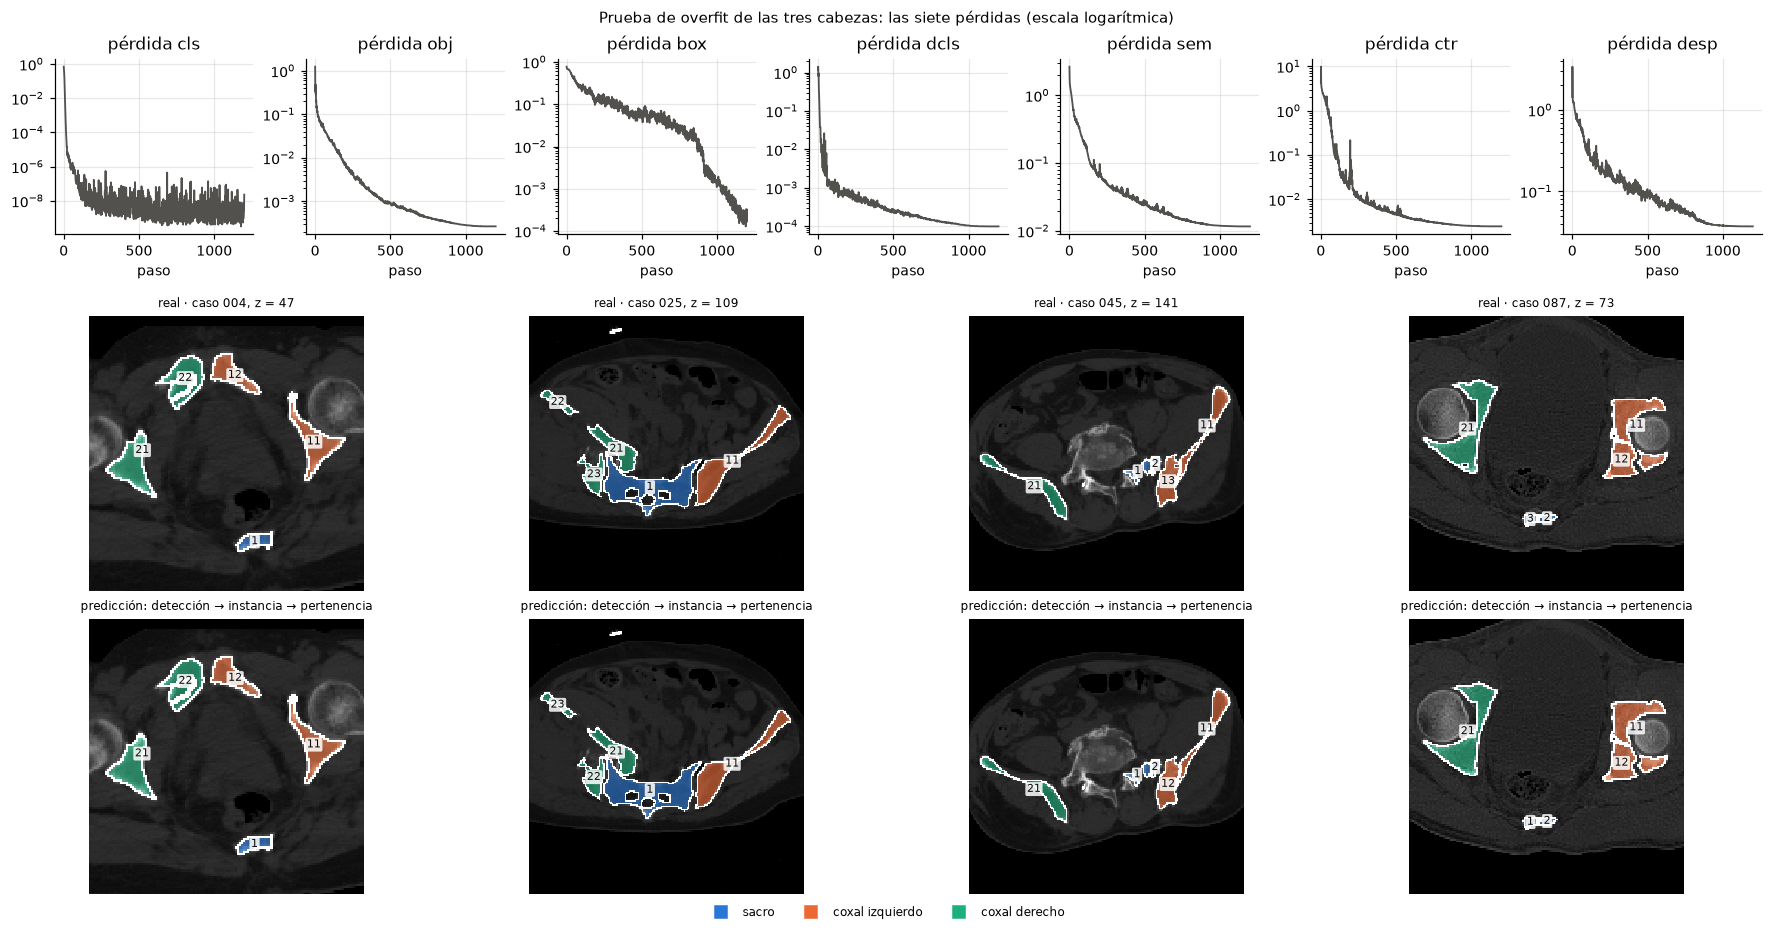

In [61]:
fig = plt.figure(figsize=(16, 8.4), layout="constrained")
arriba, abajo = fig.subfigures(2, 1, height_ratios=(1, 2.3))
for ax, k in zip(arriba.subplots(1, 7), TERMINOS3):
    ax.plot([h[k] for h in historial_ovf3], color=NEUTRO, lw=1.2)
    ax.set_yscale("log")
    ax.set(title=f"pérdida {k}", xlabel="paso")
arriba.suptitle("Prueba de overfit de las tres cabezas: las siete pérdidas (escala logarítmica)", fontsize=10)
axs = abajo.subplots(2, 4)
for j, i in enumerate((0, 3, 5, 7)):
    hu = np.asarray(hu_cache[filas_ovf3[i]])
    mostrar_corte(axs[0, j], hu, lote_ovf3["etiquetas"][i], fragmentos=True,
                  titulo=f"real · caso {indice.case_id.iat[filas_ovf3[i]]}, z = {indice.z.iat[filas_ovf3[i]]}")
    mostrar_corte(axs[1, j], hu, pred_ovf3[i], fragmentos=True, titulo="predicción: detección → instancia → pertenencia")
    for ax in axs[:, j]:
        encuadrar_corte(ax, lote_ovf3["cajas"][i].values(), margen=8)
leyenda_huesos(abajo, loc="outside lower center", ncol=3, frameon=False)
plt.show()
del modelo3, opt
torch.cuda.empty_cache()

Prueba superada. Las siete pérdidas bajan varios órdenes de magnitud y, abajo, los fragmentos predichos coinciden con los reales en número, forma y hueso. Los números escritos sobre cada fragmento no tienen por qué coincidir, porque el decodificador los numera por tamaño dentro del corte: lo que cuenta es la pareja que encuentra el emparejamiento y el color, que es el hueso. Objetivos, pérdida, decodificación y métrica funcionan de punta a punta.

## 2.9 · Cómo se mide: las métricas del  5

Las siete métricas del enunciado, con las definiciones que se usarán en validación y en prueba:

| Tarea | Métrica | Definición |
|---|---|---|
| Clasificación | F1 macro, AUC macro | Sobre las tres salidas binarias (D1), con umbral 0,5 para el F1 |
| Detección | IoU promedio | Para cada caja real evaluable (lado ≥ 8 px), el mejor IoU con una caja predicha de su región |
| Detección | mAP@0,50 y mAP@[0,50:0,95] | AP de cada región con la interpolación de 101 puntos de COCO, media de las tres; una detección duplicada es un falso positivo, una caja *ignore* no cuenta |
| Segmentación | Dice e IoU de fragmento | La métrica de 2.4: emparejamiento húngaro por hueso, 0 para los no encontrados, regla *ignore* por los dos lados |

El mAP se implementa aquí, y antes de usarlo se comprueba en tres casos de solución conocida: un ejemplo calculado a mano, un caso con una detección duplicada y otra sobre una caja *ignore*, y un detector perfecto que usa las cajas reales de validación como predicciones, que tiene que dar AP = 1 incluso con el umbral de IoU más exigente. `metricas_seccion5()` reúne las siete.

In [ ]:
filas_val = filas_de("val")
cajas_val = [cajas_por_region(np.asarray(lab_cache[f])) for f in filas_val]

UMBRALES_IOU = np.round(np.arange(0.50, 0.96, 0.05), 2)     
COLUMNAS = ["corte", "clase", "puntuacion", "iou", "astilla"]


def lado_mayor(caja) -> int:
    return max(caja[2] - caja[0], caja[3] - caja[1])


def ap_101(aciertos: np.ndarray, n_reales: int) -> float:
    #Calcula el AP usando 101 puntos de recall
    if len(aciertos) == 0:
        return 0.0
    tp = np.cumsum(aciertos)
    recall, precision = tp / n_reales, tp / np.arange(1, len(aciertos) + 1)
    precision = np.maximum.accumulate(precision[::-1])[::-1]         
    j = np.searchsorted(recall, np.linspace(0, 1, 101), side="left")  
    return float(np.where(j < len(precision), precision[np.minimum(j, len(precision) - 1)], 0.0).mean())

def todas_las_detecciones(salida, cajas_reales, umbral=0.05, max_por_region=None) -> pd.DataFrame:
    #Obtiene las detecciones y calcula su IoU con las cajas reales
    filas = []
    for i, cajas in enumerate(cajas_reales):
        cj, pu, cl = decodificar(salida, i, umbral, max_por_region=max_por_region)
        for caja, p, k in zip(cj, pu.tolist(), cl.tolist()):
            real = cajas.get(k + 1)
            iou = float(iou_cajas(caja[None], torch.tensor([real], dtype=torch.float32))[0, 0]) if real else 0.0
            filas.append((i, k, p, iou, real is not None and lado_mayor(real) < LADO_MIN))
    return pd.DataFrame(filas, columns=COLUMNAS)


def precision_media(det: pd.DataFrame, cajas_reales, k: int, umbral_iou: float) -> float:
    #Calcula el AP de una región para un umbral de IoU
    n_reales = sum(k + 1 in c and lado_mayor(c[k + 1]) >= LADO_MIN for c in cajas_reales)
    d = det[det.clase == k].sort_values("puntuacion", ascending=False, kind="stable")
    reclamadas, aciertos = set(), []
    for corte, iou, astilla in zip(d.corte, d.iou, d.astilla):
        if iou >= umbral_iou and astilla:
            continue                              
        acierto = iou >= umbral_iou and corte not in reclamadas
        if acierto:
            reclamadas.add(corte)
        aciertos.append(int(acierto))
    return ap_101(np.array(aciertos), n_reales)


# Control 1: ejemplo sencillo
assert abs(ap_101(np.array([1, 0, 1]), 2) - (51 * 1 + 50 * 2 / 3) / 101) < 1e-12

# Control 2: detección duplicada y caja ignore
reales = [{1: (0, 0, 20, 20)}, {1: (0, 0, 20, 20)}, {1: (0, 0, 4, 4)}]
det = pd.DataFrame([(2, 0, 0.95, 0.9, True), (0, 0, 0.9, 0.9, False), (0, 0, 0.8, 0.9, False), (1, 0, 0.7, 0.9, False)],
                   columns=COLUMNAS)
assert precision_media(det, reales, 0, 0.5) == ap_101(np.array([1, 0, 1]), 2)

# Control 3: detector perfecto
perfectas = pd.DataFrame([(i, k - 1, 1.0, 1.0, lado_mayor(c) < LADO_MIN) for i, cs in enumerate(cajas_val) for k, c in cs.items()],
                         columns=COLUMNAS)
assert all(precision_media(perfectas, cajas_val, k, 0.95) == 1.0 for k in range(3))

OBJETIVOS5 = {"F1 macro": 0.85, "AUC macro": 0.85, "IoU promedio": 0.65, "mAP@0,50": 0.65, "mAP@[0,50:0,95]": 0.40,
              "Dice de fragmento": 0.85, "IoU de fragmento": 0.70}


def metricas_seccion5(salida, etiquetas, filas) -> tuple[dict, list]:
    """Las siete métricas del  5 sobre unas filas: detección y clasificación con las cajas reales, fragmentos con la métrica de 2.4."""
    cajas = [cajas_por_region(np.asarray(lab_cache[f])) for f in filas]
    ious = [v for i, c in enumerate(cajas) for v in evaluar_corte(salida, i, c)[0].values()]
    det = todas_las_detecciones(salida, cajas)
    ap_ = pd.DataFrame({u: [precision_media(det, cajas, k, u) for k in range(3)] for u in UMBRALES_IOU})
    real = np.array([[k in c for k in COLOR] for c in cajas], dtype=int)
    prob = torch.sigmoid(salida["cls"]).numpy()
    frag = [emparejar(e, np.asarray(lab_cache[f])) for e, f in zip(etiquetas, filas)]
    r = resumen_fragmentos(frag)
    return {"F1 macro": f1_score(real, prob > 0.5, average="macro"), "AUC macro": roc_auc_score(real, prob, average="macro"),
            "IoU promedio": float(np.mean(ious)), "mAP@0,50": ap_[0.5].mean(), "mAP@[0,50:0,95]": ap_.to_numpy().mean(),
            "Dice de fragmento": r["Dice"], "IoU de fragmento": r["IoU"]}, frag


print("AP: el ejemplo a mano, el duplicado, la astilla y el detector perfecto dan lo esperado ✓")

AP: el ejemplo a mano, el duplicado, la astilla y el detector perfecto dan lo esperado ✓


### Lo que deja fijado el capítulo 2

El modelo, `PelvisNetCompleta`: 12,4 M de parámetros, con una entrada 2.5D de 15 canales, un tronco ResNet-18 con un CBAM por etapa, un FPN y tres cabezas. Cada pieza está comprobada por separado y el conjunto memoriza un lote de punta a punta. Y una forma de medirlo que da lo esperado en casos de solución conocida. Faltan los pesos de la pérdida y el entrenamiento.

- D10: CBAM con compuerta γ que empieza en 0 (2.1)
- D11: Primera convolución partida: central con ImageNet, vecinos desde cero (2.2)
- D12: Transfer learning solo en el tronco (2.2)
- D13: Detección *anchor-free* en una grilla propia de 16×16 (2.3)
- D14: NMS propio por clase, comprobado contra torchvision (2.3)
- D15: Un mapa de centros por hueso, con el pico anclado al píxel (2.4)
- D16: Decodificación en dos etapas, con la detección como compuerta (2.4)
- D17: Métrica de fragmento con emparejamiento por hueso y regla *ignore* (2.4)
- D18: Una sola transformación por pila (2.7)

---

# Capítulo 3. El entrenamiento

En los capítulos anteriores preparamos los datos y construimos el modelo. Ahora vamos a trabajar en su entrenamiento. Primero definiremos los pesos de las funciones de pérdida (3.1), después entrenaremos el modelo (3.2) y finalmente compararemos las tres entradas 2.5D para elegir la que funcione mejor con los datos de validación (3.3).

Durante este proceso utilizaremos los conjuntos de entrenamiento y validación. El conjunto de prueba se reservará para la evaluación final.


## 3.1. Calibración de los pesos de la pérdida

El modelo tiene siete términos de pérdida, pero cada uno puede tener una magnitud diferente. Si los sumáramos directamente, algunos podrían influir mucho más que otros durante el entrenamiento.

Para evitarlo, vamos a calcular un peso \(\lambda\) para cada término. La idea es que ninguno domine al resto por la magnitud de sus gradientes en el tronco compartido del modelo.

Los pesos se calculan de forma inversamente proporcional a la norma del gradiente de cada pérdida y después se normalizan para que su promedio sea 1:

$$
\lambda_i \propto \frac{1}{\lVert \nabla_{\text{tronco}}\,\mathcal{L}_i \rVert},
\qquad
\frac{1}{7}\sum_{i=1}^{7}\lambda_i=1
$$

Para hacer esta calibración tenemos en cuenta dos aspectos:

- **Medimos los gradientes, no solo el valor de la pérdida.** Una pérdida puede tener un valor pequeño y aun así generar gradientes importantes en el tronco compartido. Por eso, el valor de la pérdida por sí solo no permite saber cuánto influye en la actualización de los parámetros.
- **Medimos los gradientes después de un calentamiento inicial.** Primero dejamos que el modelo avance 600 pasos con todos los pesos en 1. Después calculamos los gradientes en 25 lotes y utilizamos su mediana para obtener una medida menos sensible a valores extremos.

Usamos AdamW, el mismo optimizador del entrenamiento, y una tasa de aprendizaje diez veces menor para los pesos preentrenados con ImageNet. Además, desactivamos el *weight decay* en los parámetros de una dimensión, como los sesgos y los parámetros de normalización.

Como los gradientes pueden cambiar según los cortes que recibe el modelo, repetimos la calibración para cada una de las tres entradas 2.5D. En esta sección mostraremos los resultados de la entrada de cinco cortes.

Si el modelo ya está entrenado, utilizaremos los pesos de calibración que quedaron guardados, sin repetir el proceso.

In [ ]:
def optimizador(modelo, lr=3e-4, weight_decay=1e-4):
    de_imagenet = {f"backbone.tronco.{k}" for k in modelo.backbone.de_imagenet}
    grupos = {}
    for nombre, p in modelo.named_parameters():
        grupos.setdefault((nombre in de_imagenet, p.ndim > 1), []).append(p)
    return torch.optim.AdamW([{"params": ps, "lr": lr / 10 if imagenet else lr,
                               "weight_decay": weight_decay if decay else 0.0}
                              for (imagenet, decay), ps in grupos.items()])


def medir_terminos_completo(modelo, rng, n_lotes=25):
    tronco = [p for p in modelo.backbone.tronco.parameters() if p.requires_grad]
    valores, normas = {k: [] for k in TERMINOS3}, {k: [] for k in TERMINOS3}
    for _ in range(n_lotes):
        lote = preparar_lote_completo(rng.choice(filas_train, 16, replace=False), rng, modelo.desplazamientos)
        with precision_mixta():
            _, partes = perdida_completa(modelo(lote["imagen"]), lote, dict.fromkeys(TERMINOS3, 1.0))
        for j, k in enumerate(TERMINOS3):
            g = torch.autograd.grad(partes[k], tronco, retain_graph=j < len(TERMINOS3) - 1, allow_unused=True)
            normas[k].append(float(sum(gi.pow(2).sum() for gi in g if gi is not None)) ** 0.5)
            valores[k].append(float(partes[k].detach()))
    return {k: float(np.median(v)) for k, v in valores.items()}, {k: float(np.median(v)) for k, v in normas.items()}


def calibrar_completo(desplazamientos, semilla=42) -> dict:
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = True, False
    fijar_semilla(semilla)
    rng = np.random.default_rng(semilla)
    modelo3 = PelvisNetCompleta(desplazamientos=desplazamientos).to(DISPOSITIVO).to(memory_format=torch.channels_last).train()
    valor_ini, norma_ini = medir_terminos_completo(modelo3, rng)
    opt = optimizador(modelo3)
    t0 = time.perf_counter()
    for lote in lotes_completos(rng.choice(filas_train, 600 * 16, replace=False), 16, rng, desplazamientos):
        with precision_mixta():
            total, _ = perdida_completa(modelo3(lote["imagen"]), lote, dict.fromkeys(TERMINOS3, 1.0))
        opt.zero_grad(set_to_none=True)
        total.backward()
        torch.nn.utils.clip_grad_norm_(modelo3.parameters(), 10.0)
        opt.step()
    ms_por_paso = 1000 * (time.perf_counter() - t0) / 600
    valor, norma = medir_terminos_completo(modelo3, rng)
    inversa = {k: 1 / norma[k] for k in TERMINOS3}
    por_valor = {k: 1 / valor[k] for k in TERMINOS3}
    lambdas = {k: round(float(v / np.mean(list(inversa.values()))), 3) for k, v in inversa.items()}
    del modelo3, opt
    torch.cuda.empty_cache()
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
    return {"lambdas": lambdas, "ms_por_paso": ms_por_paso, "tabla": pd.DataFrame({
        "‖∇‖ al inicio": norma_ini, "‖∇‖ tras calentar": norma,
        "‖∇‖ tras / al inicio": {k: norma[k] / norma_ini[k] for k in TERMINOS3},
        "λ por valor (descartado)": {k: v / np.mean(list(por_valor.values())) for k, v in por_valor.items()},
        "λ por gradiente": lambdas})}


RUTAS_25D = {"±1": CHECKPOINTS / "experimentos" / "entrada_pm1.pth", "±2": CHECKPOINTS / "experimentos" / "entrada_pm2.pth",
             "5 cortes": CHECKPOINTS / "modelo_final_25d.pth"}
CALIBRACIONES = {}
for nombre, ruta in RUTAS_25D.items():
    if ruta.exists():
        CALIBRACIONES[nombre] = torch.load(ruta, map_location="cpu", weights_only=False)["calibracion"]
    else:
        print(f"Calibrando los λ de la entrada {nombre}…")
        CALIBRACIONES[nombre] = calibrar_completo(VARIANTES_25D[nombre])
NOMBRE_DESP = next(n for n, d in VARIANTES_25D.items() if d == DESP)
LAMBDAS3 = CALIBRACIONES[NOMBRE_DESP]["lambdas"]
print("Los λ de cada entrada (calentamiento: " + " · ".join(f"{n} {c['ms_por_paso']:.0f} ms" for n, c in CALIBRACIONES.items())
      + " por paso):")
display(pd.DataFrame({n: c["lambdas"] for n, c in CALIBRACIONES.items()}).T)
print(f"\nLa tabla completa de la entrada {NOMBRE_DESP}:")
CALIBRACIONES[NOMBRE_DESP]["tabla"].round(3)

Los λ de cada entrada (calentamiento: ±1 161 ms · ±2 136 ms · 5 cortes 141 ms por paso):


,cls,obj,box,dcls,sem,ctr,desp
±1,0.481,2.387,0.686,1.228,1.532,0.186,0.501
±2,0.466,2.437,0.699,1.419,1.285,0.181,0.514
5 cortes,0.386,2.062,0.758,2.112,0.990,0.142,0.550



La tabla completa de la entrada 5 cortes:


,‖∇‖ al inicio,‖∇‖ tras calentar,‖∇‖ tras / al inicio,λ por valor (descartado),λ por gradiente
cls,0.414,2.478,5.983,0.982,0.386
obj,2.723,0.463,0.170,0.968,2.062
box,2.340,1.259,0.538,0.182,0.758
dcls,7.885,0.452,0.057,4.334,2.112
sem,1.183,0.965,0.816,0.374,0.990
ctr,14.881,6.706,0.451,0.049,0.142
desp,10.125,1.737,0.172,0.110,0.550


Los resultados muestran que los pesos cambian según el término de pérdida y la entrada utilizada. Para la configuración de cinco cortes, `ctr` tiene el gradiente de mayor magnitud después del calentamiento (6,706), por lo que recibe el peso más bajo (0,142). En cambio, `obj` y `dcls` tienen gradientes más pequeños y reciben los pesos más altos: 2,062 y 2,112.

También se observa que los gradientes cambian después de los 600 pasos iniciales. Por ejemplo, el de `cls` aumenta de 0,414 a 2,478, mientras que el de `dcls` disminuye de 7,885 a 0,452. Esto muestra por qué decidimos calcular los pesos después del calentamiento y no al inicio del entrenamiento.

Al comparar las tres entradas, los valores de los pesos son relativamente parecidos, aunque hay diferencias en algunos términos. Para la entrada de cinco cortes, `dcls` recibe más peso y `sem` menos que en las otras configuraciones.

Finalmente, estos pesos se mantienen fijos durante el entrenamiento. Aunque los gradientes pueden cambiar a medida que el modelo aprende, la calibración inicial permite comenzar con una ponderación basada en los resultados medidos.

#### D19. Calibración de los pesos de pérdida

Utilizamos los pesos calculados a partir de la norma de los gradientes después del calentamiento, normalizados para que su promedio sea 1. Cada configuración 2.5D tiene su propia calibración, que se guarda junto con el modelo para poder reproducir el entrenamiento.

## 3.2. Entrenamiento de las tres cabezas

Entrenamos las tres configuraciones de entrada 2.5D (cortes ±1, cortes ±2 y cinco cortes) durante 30 épocas, utilizando los mismos pacientes de entrenamiento y la misma semilla. Cada modelo aprende las tres tareas al mismo tiempo: clasificación de los huesos, detección de cajas y segmentación de fragmentos.

Partimos de los pesos de ImageNet para el tronco central y dejamos que los pesos de los cortes vecinos y las demás partes del modelo aprendan durante el entrenamiento. Utilizamos AdamW, un lote de 16 imágenes, una tasa de aprendizaje inicial de \(3 \times 10^{-4}\) y los pesos de pérdida calculados en la sección anterior.

Al terminar cada época, evaluamos el modelo con los pacientes de validación. Para escoger el checkpoint, calculamos el promedio entre el IoU de las cajas y el Dice de los fragmentos. También registramos el F1 de clasificación, las pérdidas de cada tarea y cuánto está utilizando el modelo los cortes vecinos.

Los tres modelos se entrenan por separado. El conjunto de prueba no se utiliza en esta etapa.

In [ ]:
REENTRENAR3 = False
EPOCAS3, LOTE3, LR3 = 30, 16, 3e-4
LOTE = LOTE3
CABECERA3 = (f"{'ép':>3} {'lr':>8} │ " + " ".join(f"{k:>6}" for k in TERMINOS3)
             + f" │ {'IoU':>5} {'F1':>5} {'Dice':>5} {'FP/c':>5} │ {'|γ_c|':>6} {'|γ_s|':>6} │ {'vec.':>5} │ {'s':>4}")


@torch.no_grad()
def validar_completo(modelo, filas, lambdas) -> dict:
    modelo.eval()
    sumas, n, ious, fp, prob, real, frag = dict.fromkeys(TERMINOS3, 0.0), 0, [], 0, [], [], []
    for lote in lotes_completos(filas, LOTE3, desplazamientos=modelo.desplazamientos):
        with precision_mixta():
            crudo = modelo(lote["imagen"])
            _, partes = perdida_completa(crudo, lote, lambdas)
        for k in TERMINOS3:
            sumas[k] += float(partes[k]) * len(lote["filas"])
        n += len(lote["filas"])
        salida, seg = separar(crudo)
        for i, cajas in enumerate(lote["cajas"]):
            iou_i, fp_i = evaluar_corte(salida, i, cajas)
            ious, fp = ious + list(iou_i.values()), fp + len(fp_i)
            frag.append(emparejar(pipeline_corte(salida, seg, i), lote["etiquetas"][i]))
        prob.append(torch.sigmoid(salida["cls"]).numpy())
        real.append(lote["huesos"].cpu().numpy())
    modelo.train()
    prob, real, ious, r = np.concatenate(prob), np.concatenate(real), np.array(ious), resumen_fragmentos(frag)
    return {**{f"val_{k}": v / n for k, v in sumas.items()},
            "iou": float(ious.mean()), "fp_por_corte": fp / n,
            "f1": float(f1_score(real, prob > 0.5, average="macro")),
            "auc": float(roc_auc_score(real, prob, average="macro")),
            "dice": float(r["Dice"]), "no_encontrados": r["no encontrados"] / r["fragmentos reales"],
            "fp_frag_por_corte": r["falsos positivos"] / n}


def medias_gamma(f: dict) -> str:
    g = list(f.get("gammas", {}).values())
    return f"{np.mean([abs(c) for c, _ in g]):>6.2f} {np.mean([abs(s) for _, s in g]):>6.2f}" if g else f"{'–':>6} {'–':>6}"


@torch.no_grad()
def uso_de_vecinos(modelo) -> float:
    t = modelo.backbone.tronco
    return float(t.conv1_vecinos.weight.norm() / t.conv1.weight.norm()) if t.conv1_vecinos is not None else 0.0


def imprimir_epoca3(f: dict) -> None:
    print(f"{f['epoca']:>3} {f['lr']:>8.1e} │ " + " ".join(f"{f[k]:>6.3f}" for k in TERMINOS3)
          + f" │ {f['iou']:>5.3f} {f['f1']:>5.3f} {f['dice']:>5.3f} {f['fp_frag_por_corte']:>5.2f} │ {medias_gamma(f)}"
          + f" │ {f.get('vecinos', 0):>5.3f} │ {f['segundos']:>4.0f}" + (" *" if f["mejor"] else ""))


def entrenar_completo(ruta, desplazamientos=DESP, semilla=42, calibracion=None, cbam=True, imagenet=True) -> list:
    calibracion = calibrar_completo(desplazamientos, semilla) if calibracion is None else calibracion
    lambdas = calibracion["lambdas"]
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = True, False
    fijar_semilla(semilla)
    rng = np.random.default_rng(semilla)
    modelo = PelvisNetCompleta(cbam, imagenet, desplazamientos).to(DISPOSITIVO).to(memory_format=torch.channels_last).train()
    opt = optimizador(modelo, LR3)
    pasos = math.ceil(len(filas_train) / LOTE3)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda p: (p + 1) / pasos if p < pasos else
                                              0.5 * (1 + math.cos(math.pi * (p - pasos) / max(EPOCAS3 * pasos - pasos, 1))))
    historial, mejor, inicio = [], -1.0, time.time()
    print(CABECERA3)
    for epoca in range(1, EPOCAS3 + 1):
        t0, sumas = time.time(), {k: 0.0 for k in TERMINOS3}
        for lote in lotes_completos(filas_train, LOTE3, rng, desplazamientos):
            with precision_mixta():
                total, partes = perdida_completa(modelo(lote["imagen"]), lote, lambdas)
            opt.zero_grad(set_to_none=True)
            total.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 10.0)
            opt.step()
            sched.step()
            for k in TERMINOS3:
                sumas[k] = sumas[k] + partes[k].detach()
        fila = {"epoca": epoca, "lr": max(g["lr"] for g in opt.param_groups),
                **{k: float(v) / pasos for k, v in sumas.items()}, **validar_completo(modelo, filas_val, lambdas),
                "gammas": leer_gammas(modelo), "vecinos": uso_de_vecinos(modelo)}
        fila["puntuacion"] = (fila["iou"] + fila["dice"]) / 2
        fila["segundos"], fila["mejor"] = time.time() - t0, fila["puntuacion"] > mejor
        historial.append(fila)
        imprimir_epoca3(fila)
        if fila["mejor"]:
            mejor = fila["puntuacion"]
            mejores_pesos = {k: v.detach().cpu().clone() for k, v in modelo.state_dict().items()}
        ruta.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"modelo": mejores_pesos, "historial": historial, "calibracion": calibracion,
                    "config": {"completo": True, "desplazamientos": list(desplazamientos), "epocas": EPOCAS3,
                               "lote": LOTE3, "lr": LR3, "semilla": semilla, "cbam": cbam, "imagenet": imagenet},
                    "minutos": (time.time() - inicio) / 60, "fecha": time.strftime("%Y-%m-%d %H:%M")}, ruta)
    torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
    return historial


print(f"{len(filas_train):,} cortes de entrenamiento ({math.ceil(len(filas_train) / LOTE3)} pasos de {LOTE3} por época) · "
      f"{len(filas_val):,} de validación · {EPOCAS3} épocas por entrada\n")
registros = {}
for nombre, ruta in RUTAS_25D.items():
    g = torch.load(ruta, map_location="cpu", weights_only=False) if ruta.exists() else None
    if g is None or len(g["historial"]) < EPOCAS3 or REENTRENAR3:
        print(f"\nEntrenando la entrada {nombre} {VARIANTES_25D[nombre]}…")
        entrenar_completo(ruta, VARIANTES_25D[nombre], calibracion=CALIBRACIONES[nombre])
        g = torch.load(ruta, map_location="cpu", weights_only=False)
    registros[nombre] = g
pd.DataFrame({n: {"checkpoint": RUTAS_25D[n].relative_to(CHECKPOINTS).as_posix(), "entrenado el": g["fecha"],
                  "minutos": round(g["minutos"], 1),
                  "época guardada": (m := max(g["historial"], key=lambda f: f["puntuacion"]))["epoca"],
                  "IoU": round(m["iou"], 4), "Dice": round(m["dice"], 4), "puntuación": round(m["puntuacion"], 4),
                  "uso de los vecinos": round(m["vecinos"], 3)} for n, g in registros.items()}).T

10,969 cortes de entrenamiento (686 pasos de 16 por época) · 2,364 de validación · 30 épocas por entrada



,checkpoint,entrenado el,minutos,época guardada,IoU,Dice,puntuación,uso de los vecinos
±1,experimentos/entrada_pm1.pth,2026-10-16 12:06,67.1,28,0.8817,0.8538,0.8677,0.2
±2,experimentos/entrada_pm2.pth,2026-10-16 13:19,61.2,29,0.8816,0.8527,0.8671,0.195
5 cortes,modelo_final_25d.pth,2026-10-16 14:34,63.6,27,0.8834,0.8556,0.8695,0.24


Los tres entrenamientos finalizaron con 30 épocas y tiempos de entre 61 y 67 minutos por modelo. La configuración de cinco cortes obtuvo la mejor puntuación de validación, con 0,8695, seguida de la entrada ±1 con 0,8677 y la entrada ±2 con 0,8671.

También obtuvo el IoU más alto (0,8834) y el mejor Dice de fragmentos (0,8556). La diferencia entre las tres configuraciones es pequeña, pero los resultados favorecen a la entrada de cinco cortes.

El indicador de uso de los vecinos fue de 0,240 para los cinco cortes, frente a 0,200 para ±1 y 0,195 para ±2. Esto indica que los pesos de la convolución asociada a los cortes vecinos tienen una norma relativa mayor en la configuración de cinco cortes. Por sí solo, este valor no demuestra que esa entrada sea mejor, pero permite revisar si el modelo está aprovechando la información adicional.

Por ahora, estos resultados sirven para comparar las configuraciones con el conjunto de validación. La elección se confirma en la sección 3.3, antes de evaluar el modelo con el conjunto de prueba.

#### D20. Selección del checkpoint

Guardamos el checkpoint con la mejor media entre el IoU de detección y el Dice de fragmentos en validación. Entre las tres entradas evaluadas, la de cinco cortes obtuvo la puntuación más alta (0,8695), por lo que queda como la principal candidata para la comparación de la sección 3.3.

## 3.3. La elección de la pila de cortes

En esta sección comparamos los tres modelos con los mismos 2.364 cortes de validación y utilizando el mismo procedimiento de inferencia. También comprobamos que las métricas de IoU y Dice coincidan con las registradas durante el entrenamiento, para verificar que la evaluación se está realizando de la misma manera.

La selección se hace con el mismo criterio de la sección anterior: el promedio entre el IoU de detección y el Dice de fragmentos. Además, revisamos otras métricas de clasificación, detección y segmentación para observar las diferencias entre las entradas.

In [ ]:
def cargar_modelo(ruta, dispositivo=DISPOSITIVO) -> nn.Module:
    g = torch.load(ruta, map_location="cpu", weights_only=False)
    modelo = PelvisNetCompleta(g["config"].get("cbam", True), False, tuple(g["config"]["desplazamientos"]))
    modelo.load_state_dict(g["modelo"])
    return modelo.to(dispositivo).to(memory_format=torch.channels_last).eval()


def cajas_del_corte(salida, i) -> dict:
    cj, _, cl = decodificar(salida, i, max_por_region=1)
    return {int(k) + 1: c for c, k in zip(cj.tolist(), cl.tolist())}


@torch.no_grad()
def inferir_completo(modelo, filas):
    trozos, etiquetas = [], []
    for lote in lotes(filas, LOTE3, desplazamientos=modelo.desplazamientos):
        salida, seg = predecir(modelo, lote["imagen"])
        trozos.append(salida)
        for i in range(len(lote["filas"])):
            etiquetas.append(instancias(seg[0][i], seg[1][i], seg[2][i], cajas_del_corte(salida, i) if COMPUERTA else None,
                                        torch.sigmoid(salida["cls"][i]).numpy(), UMBRAL_CENTRO))
    return {k: torch.cat([t[k] for t in trozos]) for k in trozos[0]}, np.stack(etiquetas)


torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True
t0 = time.perf_counter()
comparacion = {}
for nombre, ruta in RUTAS_25D.items():
    m_ = cargar_modelo(ruta)
    salida, etiquetas = inferir_completo(m_, filas_val)
    met, frag_ = metricas_seccion5(salida, etiquetas, filas_val)
    mejor_f = max(registros[nombre]["historial"], key=lambda f: f["puntuacion"])
    assert abs(met["IoU promedio"] - mejor_f["iou"]) < 2e-3 and abs(met["Dice de fragmento"] - mejor_f["dice"]) < 2e-3, \
        f"{nombre}: la evaluación no reproduce lo que midió el entrenamiento"
    comparacion[nombre] = {**met, "F1 de reconocimiento": resumen_fragmentos(frag_)["F1 de reconocimiento"],
                           "puntuación": (met["IoU promedio"] + met["Dice de fragmento"]) / 2,
                           "época": mejor_f["epoca"], "uso de los vecinos": uso_de_vecinos(m_)}
    del m_
    torch.cuda.empty_cache()
comparacion = pd.DataFrame(comparacion).T
GANADORA = comparacion["puntuación"].astype(float).idxmax()
RUTA_COMPLETO = RUTAS_25D[GANADORA]
print(f"{len(comparacion)} modelos evaluados en los {len(filas_val):,} cortes de validación en {time.perf_counter() - t0:.0f} s; "
      f"cada uno reproduce lo que midió su entrenamiento ✓")
print(f"Entrada elegida en validación: {GANADORA}, desplazamientos {VARIANTES_25D[GANADORA]}")
assert VARIANTES_25D[GANADORA] == DESP, "la ganadora no es la pila con la que trabaja el notebook (1.12): actualizar DESP"
comparacion.astype(float).round(4).astype({"época": int})

3 modelos evaluados en los 2,364 cortes de validación en 98 s; cada uno reproduce lo que midió su entrenamiento ✓
Entrada elegida en validación: 5 cortes, desplazamientos (-4, -2, 0, 2, 4)


,F1 macro,AUC macro,IoU promedio,"mAP@0,50","mAP@[0,50:0,95]",Dice de fragmento,IoU de fragmento,F1 de reconocimiento,puntuación,época,uso de los vecinos
±1,0.9910,0.9995,0.8816,0.9754,0.7608,0.8535,0.8070,0.9325,0.8675,28,0.2004
±2,0.9901,0.9995,0.8815,0.9788,0.7611,0.8525,0.8063,0.9327,0.8670,29,0.1950
5 cortes,0.9915,0.9994,0.8833,0.9788,0.7655,0.8553,0.8089,0.9349,0.8693,27,0.2395


La entrada de cinco cortes obtuvo la puntuación más alta, con 0,8693, frente a 0,8675 para ±1 y 0,8670 para ±2. También consiguió los mejores resultados en Dice de fragmentos (0,8553), IoU de fragmento (0,8089) y F1 de reconocimiento (0,9349).

En detección, los resultados son bastante parecidos: el IoU promedio se encuentra entre 0,8815 y 0,8833. La diferencia más clara aparece en la segmentación de fragmentos, aunque sigue siendo pequeña.

El indicador de uso de los vecinos también fue mayor con cinco cortes (0,2395), comparado con 0,2004 para ±1 y 0,1950 para ±2. Esto muestra una mayor norma relativa de los pesos asociados a los cortes vecinos, pero no significa por sí solo que su contribución a las predicciones sea mayor.

Aunque las diferencias entre los modelos son pequeñas, la entrada de cinco cortes es la mejor según el criterio definido. Por eso la seleccionamos para continuar con el resto del proyecto. La evaluación también confirmó que las métricas de IoU y Dice coinciden con las registradas durante el entrenamiento.

#### D21. Selección de la entrada 2.5D

Elegimos la pila de cinco cortes, correspondiente a las posiciones \(z-4\), \(z-2\), \(z\), \(z+2\) y \(z+4\). Como cada desplazamiento equivale a 1,5 mm, los cortes extremos están a 6 mm del corte central y cubren una distancia total de 12 mm.

Esta configuración obtuvo la mejor puntuación en validación (0,8693), por lo que la seleccionamos para continuar con el proyecto. Los desplazamientos quedan guardados en el checkpoint para mantener la misma entrada durante la inferencia.

## 3.4. Lo que contó el entrenamiento

Revisamos el historial del modelo de cinco cortes, desde la primera hasta la última época. Las gráficas muestran cómo cambian las siete pérdidas durante el entrenamiento y la validación, junto con las métricas principales, el uso de los cortes vecinos y las compuertas del CBAM.

La línea punteada marca la época 27, que fue la seleccionada por obtener la mejor media entre el IoU de detección y el Dice de fragmentos. Aunque el entrenamiento continúa hasta la época 30, el checkpoint conserva los pesos de esa época.

Entrada 5 cortes: registro del entrenamiento (* = mejor media de IoU y Dice de validación hasta entonces)

 ép       lr │    cls    obj    box   dcls    sem    ctr   desp │   IoU    F1  Dice  FP/c │  |γ_c|  |γ_s| │  vec. │    s
  1  3.0e-04 │  0.266  0.167  0.517  0.146  0.927  2.361  0.801 │ 0.674 0.975 0.692  0.09 │   0.05   0.07 │ 0.046 │  124 *
  2  3.0e-04 │  0.062  0.049  0.300  0.018  0.116  1.298  0.488 │ 0.752 0.982 0.738  0.13 │   0.10   0.15 │ 0.074 │  126 *
  3  3.0e-04 │  0.038  0.037  0.244  0.013  0.083  0.985  0.402 │ 0.776 0.973 0.769  0.17 │   0.13   0.19 │ 0.093 │  126 *
  4  2.9e-04 │  0.031  0.031  0.209  0.010  0.072  0.824  0.342 │ 0.794 0.982 0.777  0.15 │   0.15   0.22 │ 0.114 │  127 *
  5  2.9e-04 │  0.025  0.028  0.190  0.010  0.067  0.702  0.299 │ 0.818 0.990 0.810  0.16 │   0.16   0.24 │ 0.131 │  127 *
  6  2.8e-04 │  0.024  0.026  0.174  0.008  0.063  0.617  0.267 │ 0.828 0.993 0.817  0.15 │   0.17   0.26 │ 0.145 │  127 *
  7  2.7e-04 │  0.022  0.024  0.16

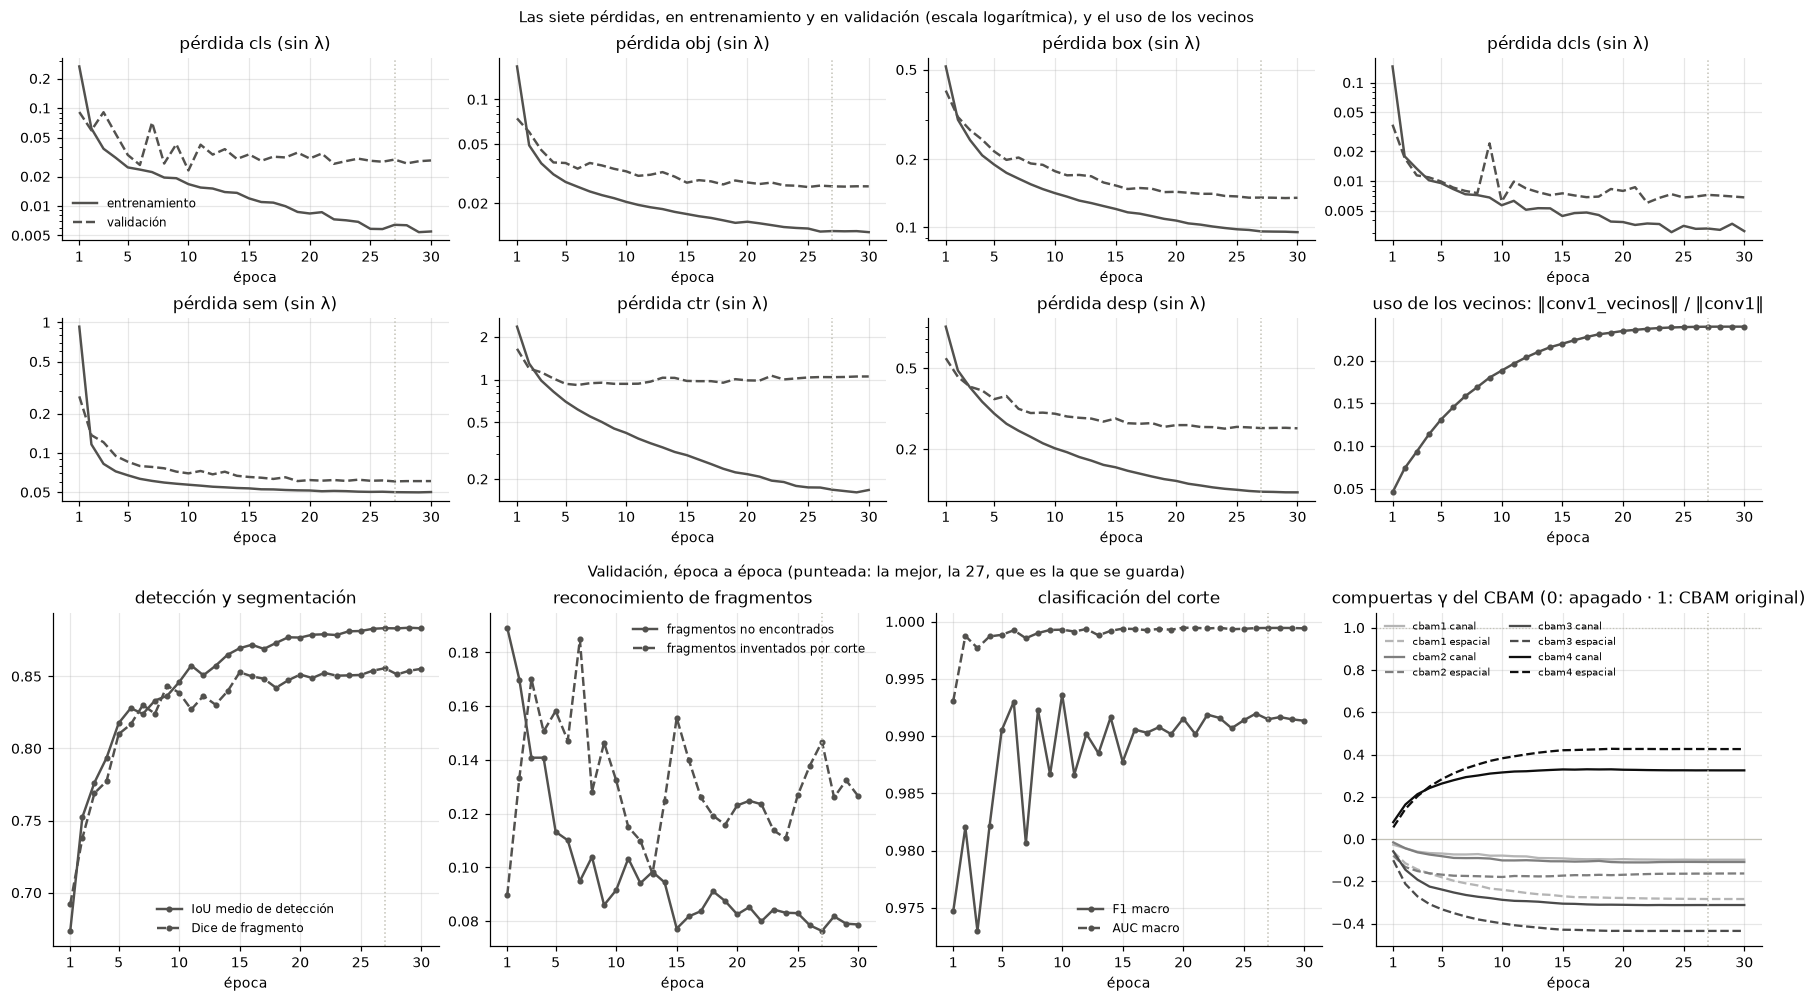

Compuertas γ del modelo guardado (época 27), canal / espacial: cbam1 -0.10 / -0.28 · cbam2 -0.11 / -0.16 · cbam3 -0.31 / -0.44 · cbam4 0.33 / 0.43
Pérdida de centros en validación: mínima en la época 6 (0.917); en la 27, 1.042. En entrenamiento, de 0.617 a 0.168 en el mismo tramo


In [ ]:
from matplotlib.ticker import FormatStrFormatter, LogLocator, NullFormatter

EPOCAS_EJE = (1, 5, 10, 15, 20)


def dibujar_gammas(ax, registro, mejor_epoca, ejes=None):
    for b, tono in zip(registro.gammas.iloc[0], plt.cm.Greys(np.linspace(0.4, 0.95, 4))):
        for j, (ls, nombre) in enumerate((("-", "canal"), ("--", "espacial"))):
            ax.plot(registro.index, [g[b][j] for g in registro.gammas], color=tono, lw=1.5, ls=ls, label=f"{b} {nombre}")
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.axhline(1, color=GRIS, lw=0.8, ls=":")
    ax.axvline(mejor_epoca, color=GRIS, lw=1, ls=":")
    ax.set(title="compuertas γ del CBAM (0: apagado · 1: CBAM original)", xlabel="época", xticks=ejes or EPOCAS_EJE)
    ax.legend(fontsize=6.5, frameon=False, ncol=2)


historial3 = registros[GANADORA]["historial"]
registro3 = pd.DataFrame(historial3).set_index("epoca")
mejor_epoca3 = int(registro3.puntuacion.idxmax())
EPOCAS_EJE3 = (1, 5, 10, 15, 20, 25, 30)
print(f"Entrada {GANADORA}: registro del entrenamiento (* = mejor media de IoU y Dice de validación hasta entonces)\n")
print(CABECERA3)
for fila_r in historial3:
    imprimir_epoca3(fila_r)

fig = plt.figure(figsize=(16, 9), layout="constrained")
arriba, abajo = fig.subfigures(2, 1, height_ratios=(1.25, 1))
for ax, k in zip(arriba.subplots(2, 4).flat, (*TERMINOS3, None)):
    if k is None:
        ax.plot(registro3.index, registro3.vecinos, color=NEUTRO, lw=1.6, marker="o", ms=3)
        ax.axvline(mejor_epoca3, color=GRIS, lw=1, ls=":")
        ax.set(title="uso de los vecinos: ‖conv1_vecinos‖ / ‖conv1‖", xlabel="época", xticks=EPOCAS_EJE3)
        continue
    ax.plot(registro3.index, registro3[k], color=NEUTRO, lw=1.6, label="entrenamiento")
    ax.plot(registro3.index, registro3[f"val_{k}"], color=NEUTRO, lw=1.6, ls="--", label="validación")
    ax.axvline(mejor_epoca3, color=GRIS, lw=1, ls=":")
    ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(FormatStrFormatter("%g"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set(title=f"pérdida {k} (sin λ)", xlabel="época", xticks=EPOCAS_EJE3)
arriba.axes[0].legend(fontsize=8, frameon=False)
arriba.suptitle("Las siete pérdidas, en entrenamiento y en validación (escala logarítmica), y el uso de los vecinos", fontsize=10)

ejes_abajo = abajo.subplots(1, 4)
for ax, series, titulo in zip(ejes_abajo[:3],
                              ({"iou": "IoU medio de detección", "dice": "Dice de fragmento"},
                               {"no_encontrados": "fragmentos no encontrados", "fp_frag_por_corte": "fragmentos inventados por corte"},
                               {"f1": "F1 macro", "auc": "AUC macro"}),
                              ("detección y segmentación", "reconocimiento de fragmentos", "clasificación del corte")):
    for (c, nombre), ls in zip(series.items(), ("-", "--")):
        ax.plot(registro3.index, registro3[c], color=NEUTRO, lw=1.6, ls=ls, marker="o", ms=3, label=nombre)
    ax.axvline(mejor_epoca3, color=GRIS, lw=1, ls=":")
    ax.set(title=titulo, xlabel="época", xticks=EPOCAS_EJE3)
    ax.legend(fontsize=8, frameon=False)
dibujar_gammas(ejes_abajo[3], registro3, mejor_epoca3, EPOCAS_EJE3)
abajo.suptitle(f"Validación, época a época (punteada: la mejor, la {mejor_epoca3}, que es la que se guarda)", fontsize=10)
plt.show()
print(f"Compuertas γ del modelo guardado (época {mejor_epoca3}), canal / espacial: " + " · ".join(
    f"{b} {c:.2f} / {s:.2f}" for b, (c, s) in registro3.gammas[mejor_epoca3].items()))

minimo_ctr = int(registro3.val_ctr.idxmin())
print(f"Pérdida de centros en validación: mínima en la época {minimo_ctr} ({registro3.val_ctr[minimo_ctr]:.3f}); "
      f"en la {mejor_epoca3}, {registro3.val_ctr[mejor_epoca3]:.3f}. En entrenamiento, de "
      f"{registro3.ctr[minimo_ctr]:.3f} a {registro3.ctr[mejor_epoca3]:.3f} en el mismo tramo")

Hay cuatro aspectos que vale la pena destacar:

- **Clasificación y detección:** el F1 y el AUC alcanzan valores altos desde las primeras épocas. El IoU de detección sigue mejorando y llega aproximadamente a 0,883 en la época 27.

- **Segmentación de fragmentos:** el Dice aumenta de 0,692 en la primera época a 0,856 en la época 27. Los fragmentos no encontrados también disminuyen durante el entrenamiento, aunque los fragmentos inventados por corte presentan algunas variaciones entre épocas.

- **Pérdida de centros:** aquí aparece una diferencia entre entrenamiento y validación. La pérdida de validación alcanza su mínimo en la época 6 (0,917) y después aumenta hasta 1,042 en la época guardada, mientras que la pérdida de entrenamiento sigue bajando. Esto sugiere un posible sobreajuste en esta parte del modelo y deja una oportunidad de mejora para futuros experimentos.

- **Uso de los vecinos y CBAM:** la norma relativa de los pesos de los cortes vecinos aumenta hasta aproximadamente 0,24. Las compuertas del CBAM también cambian durante el entrenamiento y terminan con valores positivos y negativos según el bloque y el tipo de atención. Esto muestra que los parámetros aprendidos se alejan de la inicialización, aunque sus valores por sí solos no permiten concluir si la atención mejora el resultado.

En general, el modelo mejora en detección y segmentación durante el entrenamiento, pero la pérdida de centros muestra un comportamiento distinto en validación. Por eso conviene conservar el checkpoint seleccionado por las métricas principales y revisar el efecto de esta cabeza en los experimentos posteriores.

### Lo que deja fijado el capítulo 3

El modelo seleccionado utiliza cinco cortes: \(z-4\), \(z-2\), \(z\), \(z+2\) y \(z+4\). Se conserva el checkpoint de la época 27, con un IoU de detección de 0,883 y un Dice de fragmentos de 0,855 en validación.

También quedan definidas tres decisiones: los pesos de las pérdidas calculados a partir de los gradientes (D19), la selección de la época según el promedio del IoU y el Dice (D20), y la elección de la pila de cinco cortes (D21). En el siguiente capítulo se revisarán las decisiones de diseño y las limitaciones identificadas durante los experimentos.

---

# Capítulo 4 · La evaluación

Con el modelo final elegido, el capítulo responde cuánto rinde, dónde falla y qué piezas le sirven. El orden protege el conjunto de prueba: todo lo que todavía se decide —cómo decodificar, cómo enlazar en 3D— se decide en **validación** (4.1–4.4 y la primera mitad de 4.6), y la prueba se abre **una sola vez**, con todo fijado (4.5).

Secciones: 

- 4.1. ¿Cómo convertir los mapas de la red en fragmentos? 
- 4.2. ¿Cumple las métricas del  5 en validación? 
- 4.3. ¿Dónde falla la detección? Las primeras predicciones de cajas y los cinco peores casos 
- 4.4. ¿Dónde falla la segmentación? 
- 4.5. ¿Y en el conjunto de prueba? Métricas, matrices de confusión y los cinco peores cortes 
- 4.6. ¿Mide bien la separación en milímetros? 
- 4.7. ¿Qué haría SAM, un modelo generalista, con las mismas cajas? 
- 4.8. ¿Sirve el CBAM? ¿Y el transfer learning? La ablación 
- 4.9. ¿Cuánto tarda en GPU y en CPU? 

## 4.1 · Cómo decodificar: la decisión que falta, en validación

Se carga el modelo guardado (el de la época 27) y desde aquí **la inferencia es determinista** (`cudnn.deterministic`), para que las cifras del texto se reproduzcan. Antes de abrir el conjunto de prueba queda una decisión que tomar con validación: cómo decodificar. La fijan dos parámetros:

- **La compuerta** (D16): segmentar cada hueso solo dentro de su caja, o en todo el corte.
- **El umbral de los centros**: más bajo encuentra más fragmentos, y también inventa más.

El criterio no puede ser el Dice de fragmento: promedia sobre los fragmentos reales y no ve los inventados, así que bajar el umbral lo subiría siempre. Se usa el **F1 de reconocimiento**, 2·TP / (2·TP + no encontrados + inventados), que cuenta los dos errores por igual.

In [67]:
torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True    # inferencia reproducible
guardado3 = registros[GANADORA]
modelo3 = cargar_modelo(RUTA_COMPLETO)
mejor3 = max(guardado3["historial"], key=lambda f: f["puntuacion"])


@torch.no_grad()
def comparar_decodificaciones(modelo, filas, variantes) -> dict:
    """Para cada variante (compuerta, umbral de centro), el emparejamiento de cada corte con su etiqueta real."""
    resultados = {v: [] for v in variantes}
    for lote in lotes(filas, LOTE, desplazamientos=modelo.desplazamientos):
        salida, seg = predecir(modelo, lote["imagen"])
        for i, fila in enumerate(lote["filas"]):
            real, cajas = np.asarray(lab_cache[fila]), cajas_del_corte(salida, i)
            presencia = torch.sigmoid(salida["cls"][i]).numpy()
            for compuerta, umbral in variantes:
                pred = instancias(seg[0][i], seg[1][i], seg[2][i], cajas if compuerta else None, presencia, umbral)
                resultados[(compuerta, umbral)].append(emparejar(pred, real))
    return resultados


VARIANTES = [(True, 0.2), (True, 0.3), (True, 0.4), (True, 0.5), (False, 0.3)]
t0 = time.perf_counter()
por_variante = comparar_decodificaciones(modelo3, filas_val, VARIANTES)
decodificaciones = pd.DataFrame({v: resumen_fragmentos(r) for v, r in por_variante.items()}).T
decodificaciones.index = pd.MultiIndex.from_tuples(VARIANTES, names=["compuerta", "umbral de centro"])
COMPUERTA, UMBRAL_CENTRO = decodificaciones["F1 de reconocimiento"].idxmax()
print(f"Modelo de la época {mejor3['epoca']} · {len(filas_val):,} cortes de validación · {len(VARIANTES)} decodificaciones "
      f"en {time.perf_counter() - t0:.0f} s")
print(f"Decodificación de trabajo, la de mayor F1 de reconocimiento: compuerta = {COMPUERTA}, umbral de centro = {UMBRAL_CENTRO}")
decodificaciones.drop(columns=["fragmentos reales", "astillas"]).round(4).astype({"no encontrados": int, "falsos positivos": int})

Modelo de la época 27 · 2,364 cortes de validación · 5 decodificaciones en 94 s
Decodificación de trabajo, la de mayor F1 de reconocimiento: compuerta = True, umbral de centro = 0.3


Dice     IoU  Dice de los encontrados  \
compuerta umbral de centro                                            
True      0.2               0.8650  0.8163                   0.9223   
          0.3               0.8553  0.8089                   0.9265   
          0.4               0.8440  0.8001                   0.9314   
          0.5               0.8329  0.7899                   0.9323   
False     0.3               0.8575  0.8108                   0.9267   

                            no encontrados  falsos positivos  \
compuerta umbral de centro                                     
True      0.2                          412               532   
          0.3                          510               343   
          0.4                          623               223   
          0.5                          708               186   
False     0.3                          496               368   

                            F1 de reconocimiento  Dice sin regla ignore  
compuerta umbral de centro                                               
True      0.2                             0.9295                 0.8446  
          0.3                             0.9349                 0.8342  
          0.4                             0.9343                 0.8223  
          0.5                             0.9299                 0.8109  
False     0.3                             0.9343                 0.8364

El F1 elige la compuerta y el umbral de 0,3: la decodificación que se había fijado de antemano en 2.4. La tabla enseña el compromiso. Con el umbral en 0,2, el Dice sube a 0,865, pero los fragmentos inventados crecen un 55 % (de 343 a 532); en 0,5, el Dice baja a 0,833 y los no encontrados pasan de 510 a 708. La compuerta apenas mueve el Dice (0,8553 con ella, 0,8575 sin ella) y ahorra un 7 % de los inventados (343 frente a 368).

 #### D22 · Decodificación de trabajo: la caja como compuerta y un umbral de centro de 0,3

 Elegida en validación por el F1 de reconocimiento, que ve a la vez los fragmentos no encontrados y los inventados.

## 4.2 · Las métricas del 5 en validación

Con esa decodificación, las siete métricas del enunciado sobre los 2.364 cortes de los 15 pacientes de validación:

In [ ]:
t0 = time.perf_counter()
salida_val3, etiquetas_val3 = inferir_completo(modelo3, filas_val)
s5_val, frag_val3 = metricas_seccion5(salida_val3, etiquetas_val3, filas_val)
real_val = np.array([[k in c for k in COLOR] for c in cajas_val], dtype=int)        # regiones presentes en cada corte
f1_constante = f1_score(real_val, np.ones_like(real_val), average="macro")          # siempre «las tres regiones»
print(f"{len(filas_val):,} cortes de validación inferidos y evaluados en {time.perf_counter() - t0:.0f} s con la "
      f"decodificación de trabajo")
print(f"Un clasificador constante que responde siempre «las tres regiones» ya obtiene F1 macro = {f1_constante:.3f}: "
      f"el {real_val.all(1).mean():.0%} de los cortes de validación contiene las tres")
validacion5 = pd.DataFrame({"objetivo ( 5)": OBJETIVOS5, "validación": s5_val}).loc[list(OBJETIVOS5)].astype(float)
validacion5["cumple"] = np.where(validacion5["validación"] >= validacion5["objetivo ( 5)"], "sí", "no")
validacion5.round(4)

2,364 cortes de validación inferidos y evaluados en 32 s con la decodificación de trabajo
Un clasificador constante que responde siempre «las tres regiones» ya obtiene F1 macro = 0.867: el 58% de los cortes de validación contiene las tres


,objetivo (§5),validación,cumple
F1 macro,0.85,0.9915,sí
AUC macro,0.85,0.9994,sí
IoU promedio,0.65,0.8833,sí
"mAP@0,50",0.65,0.9788,sí
"mAP@[0,50:0,95]",0.40,0.7655,sí
Dice de fragmento,0.85,0.8553,sí
IoU de fragmento,0.70,0.8089,sí


En validación se cumplen **los siete objetivos**. La clasificación y la detección, con margen: F1 0,992 y AUC 0,999 (con un aviso: un clasificador que respondiera siempre «las tres regiones» ya sacaría 0,867, porque el 58 % de los cortes las contiene, así que el F1 hay que leerlo junto al AUC, que un predictor constante no puede engañar, D1); IoU 0,883, mAP@0,50 0,979 y mAP@[0,50:0,95] 0,766. El Dice de fragmento, el más exigente, llega a 0,855 frente a 0,85, y el IoU de fragmento, con su objetivo más bajo, se cumple con holgura (0,809 frente a 0,70).

## 4.3 · La detección: por región, dónde falla y las primeras predicciones

La detección, mirada de cerca. Primero, el AP de cada región en cada umbral de IoU, de 0,50 a 0,95:

In [69]:
salida_val = salida_val3                       # la detección y la clasificación del modelo final en validación
prob_val = torch.sigmoid(salida_val["cls"]).numpy()
evaluacion = [evaluar_corte(salida_val, i, cajas) for i, cajas in enumerate(cajas_val)]
detecciones_val = todas_las_detecciones(salida_val, cajas_val)
ap = pd.DataFrame({u: [precision_media(detecciones_val, cajas_val, k, u) for k in range(3)] for u in UMBRALES_IOU},
                  index=pd.Index(list(HUESO.values()), name="AP por región y umbral de IoU"))
print(f"{len(detecciones_val):,} detecciones de validación con puntuación ≥ 0,05")
ap.round(3)

7,403 detecciones de validación con puntuación ≥ 0,05


,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95
AP por región y umbral de IoU,,,,,,,,,,
sacro,0.956,0.945,0.911,0.862,0.799,0.712,0.554,0.315,0.097,0.005
coxal izquierdo,0.990,0.990,0.980,0.979,0.969,0.949,0.926,0.858,0.609,0.117
coxal derecho,0.990,0.990,0.989,0.978,0.967,0.953,0.918,0.859,0.682,0.119


A IoU 0,50 las tres regiones pasan de 0,95 de AP (sacro 0,956, coxales 0,990). Al exigir más ajuste, los coxales aguantan —todavía 0,92 a IoU 0,80— y el sacro cae antes: 0,554 a 0,80 y 0,315 a 0,85. A 0,95 casi ninguna caja llega (0,005–0,119): es un ajuste al píxel.

Y región a región, la detección y la clasificación del corte:

In [70]:
por_region = {}
for k, nombre in HUESO.items():
    ious = np.array([e[0][k] for e in evaluacion if k in e[0]])
    pred, real = prob_val[:, k - 1] > 0.5, real_val[:, k - 1] == 1
    por_region[nombre] = {
        "cajas evaluables": len(ious),
        "IoU medio": ious.mean(),
        "cajas con IoU ≥ 0,5": (ious >= 0.5).mean(),
        "AP@0,50": ap.loc[nombre, 0.5],
        "AP@[0,50:0,95]": ap.loc[nombre].mean(),
        "falsos positivos de detección": sum(fp.count(k) for _, fp in evaluacion),
        "F1": f1_score(real, pred),
        "AUC": roc_auc_score(real, prob_val[:, k - 1]),
        "cortes: presente y no vista": int((real & ~pred).sum()),
        "cortes: ausente y vista": int((~real & pred).sum()),
    }
enteras = ["cajas evaluables", "falsos positivos de detección", "cortes: presente y no vista", "cortes: ausente y vista"]
pd.DataFrame(por_region).T.astype(float).round(3).astype(dict.fromkeys(enteras, int))

,cajas evaluables,IoU medio,"cajas con IoU ≥ 0,5","AP@0,50","AP@[0,50:0,95]",falsos positivos de detección,F1,AUC,cortes: presente y no vista,cortes: ausente y vista
sacro,1305,0.801,0.962,0.956,0.616,245,0.979,0.999,14,46
coxal izquierdo,2053,0.907,0.997,0.990,0.837,59,0.998,1.000,1,6
coxal derecho,2032,0.913,0.996,0.990,0.844,40,0.998,1.000,4,6


El sacro es la región difícil: IoU medio de 0,801 frente a 0,907 y 0,913 de los coxales, y AP@[0,50:0,95] de 0,616 frente a 0,837 y 0,844. Pero su AP@0,50 es 0,956: lo encuentra; lo que le cuesta es ajustar los bordes de la caja. Acumula además la mayoría de los falsos positivos de detección (245 de 344) y de los errores de clasificación: 46 cortes en los que lo ve sin estar y 14 en los que está y no lo ve, frente a 7 y 10 errores de los coxales.

### Dónde falla la detección

¿Se concentran los errores en los extremos de cada hueso? Cada corte se sitúa dentro de la extensión de su región en cada paciente, y esa extensión se divide en tres tramos: el 10 % caudal, el centro y el 10 % craneal; los cortes por debajo o por encima de la extensión de la región van aparte. El eje z crece hacia la cabeza, por la orientación LPS.

In [71]:
z_val, caso_val = indice.z.to_numpy()[filas_val], indice.case_id.to_numpy()[filas_val]
extension = {}                                  
for z, caso, cajas in zip(z_val, caso_val, cajas_val):
    for k in cajas:
        a, b = extension.get((caso, k), (z, z))
        extension[(caso, k)] = (min(a, z), max(b, z))
TRAMOS = ["por debajo", "10 % caudal", "centro", "10 % craneal", "por encima"]


def tramo(i: int, k: int) -> str:
    #Ubica el corte dentro de la extensión de la región
    a, b = extension[(caso_val[i], k)]
    pos = (z_val[i] - a) / max(b - a, 1)
    if not 0 <= pos <= 1:
        return TRAMOS[0] if pos < 0 else TRAMOS[-1]
    return TRAMOS[1 + int(np.searchsorted([0.1, 0.9], pos, side="right"))]


def por_caja(evaluacion) -> pd.DataFrame:
    #Organiza la información de cada caja real evaluable
    t = pd.DataFrame([(i, caso_val[i], k, HUESO[k], tramo(i, k), lado_mayor(cajas_val[i][k]), iou)
                      for i, (ious, _) in enumerate(evaluacion) for k, iou in ious.items()],
                     columns=["corte", "caso", "k", "región", "tramo", "lado", "iou"])
    return t.astype({"tramo": pd.CategoricalDtype(TRAMOS, ordered=True),
                     "región": pd.CategoricalDtype(HUESO.values(), ordered=True)})


def por_falso_positivo(evaluacion) -> pd.DataFrame:
    #Organiza los falsos positivos por región y tramo
    t = pd.DataFrame([(HUESO[k], tramo(i, k)) for i, (_, fp) in enumerate(evaluacion) for k in fp],
                     columns=["región", "tramo"])
    return t.astype({"tramo": pd.CategoricalDtype(TRAMOS, ordered=True),
                     "región": pd.CategoricalDtype(HUESO.values(), ordered=True)})


cajas_t, fps_t = por_caja(evaluacion), por_falso_positivo(evaluacion)
extremos = cajas_t.tramo.isin(["10 % caudal", "10 % craneal"])
fallidas = cajas_t.iou < 0.5
print(f"Los dos extremos de cada hueso reúnen el {extremos.mean():.0%} de las cajas, pero el {fallidas[extremos].sum() / fallidas.sum():.0%} "
      f"de las fallidas (IoU < 0,5); y el {(fps_t.tramo != 'centro').mean():.0%} de los falsos positivos cae en ellos o más allá")
lados = pd.cut(cajas_t.lado, [LADO_MIN, 32, 64, 257], right=False, labels=["8–31 px", "32–63 px", "≥ 64 px"])
print("IoU medio por lado mayor de la caja: " + " · ".join(
    f"{n} {g.mean():.3f} ({len(g):,} cajas)" for n, g in cajas_t.iou.groupby(lados, observed=True)))
pd.concat({"IoU medio": cajas_t.pivot_table("iou", "tramo", "región", "mean", observed=False),
           "cajas con IoU < 0,5": cajas_t.assign(f=fallidas).pivot_table("f", "tramo", "región", "sum", observed=False),
           "falsos positivos": pd.crosstab(fps_t.tramo, fps_t["región"], dropna=False)}, axis=1).round(3).fillna("–")

Los dos extremos de cada hueso reúnen el 19% de las cajas, pero el 91% de las fallidas (IoU < 0,5); y el 80% de los falsos positivos cae en ellos o más allá
IoU medio por lado mayor de la caja: 8–31 px 0.729 (579 cajas) · 32–63 px 0.892 (2,584 cajas) · ≥ 64 px 0.913 (2,227 cajas)


IoU medio                               cajas con IoU < 0,5  \
región           sacro coxal izquierdo coxal derecho               sacro   
tramo                                                                      
10 % caudal      0.631           0.843         0.868                  14   
centro           0.838           0.918         0.921                   4   
10 % craneal       0.6           0.876         0.891                  32   
por debajo           –               –             –                   0   
por encima           –               –             –                   0   

                                           falsos positivos                  \
región       coxal izquierdo coxal derecho            sacro coxal izquierdo   
tramo                                                                         
10 % caudal                4             2              100              33   
centro                     0             2               44              14   
10 % craneal               3             4               69               9   
por debajo                 0             0                3               1   
por encima                 0             0               29               2   

                            
región       coxal derecho  
tramo                       
10 % caudal              9  
centro                  12  
10 % craneal            11  
por debajo               1  
por encima               7

Los dos extremos de cada hueso reúnen el 19 % de las cajas, pero el **91 % de las fallidas** (IoU < 0,5) y el 80 % de los falsos positivos. El tamaño pesa: las cajas de 8 a 31 px tienen un IoU medio de 0,729, frente a 0,892 y 0,913 de las de 32–63 y de 64 px o más, porque un error de pocos píxeles se nota más en una caja pequeña. En el sacro la diferencia es más marcada —0,838 en el centro, 0,631 en el extremo caudal y 0,600 en el craneal—, y las dos zonas tienen explicación anatómica:

- **Extremo caudal: el cóccix**, una región pequeña y estrecha. Es el tramo con más falsos positivos del sacro (100).
- **Extremo craneal: L5**, la última vértebra lumbar. PENGWIN no la anota, está pegada al sacro y se le parece: 29 falsos positivos del sacro caen por encima de su extensión real.

### Cajas repetidas

Algunos cortes tienen, después del NMS, más de una caja de la misma región: pasan el NMS cuando se solapan menos de 0,5. Pero en estos datos hay como mucho una caja real por región y corte, así que una segunda caja de la misma región es siempre un falso positivo. Se repite la evaluación conservando solo la caja de mayor puntuación de cada región:

In [72]:
evaluacion_1 = [evaluar_corte(salida_val, i, cajas, max_por_region=1) for i, cajas in enumerate(cajas_val)]
detecciones_1 = todas_las_detecciones(salida_val, cajas_val, max_por_region=1)
ap_1 = pd.DataFrame({u: [precision_media(detecciones_1, cajas_val, k, u) for k in range(3)] for u in UMBRALES_IOU})


def resumen(evaluacion, ap) -> dict:
    fp = [k for _, f in evaluacion for k in f]
    return {"IoU medio": np.mean([v for ious, _ in evaluacion for v in ious.values()]),
            "mAP@0,50": ap[0.5].mean(), "mAP@[0,50:0,95]": ap.to_numpy().mean(),
            "falsos positivos por corte": len(fp) / len(evaluacion),
            **{f"falsos positivos: {HUESO[k]}": fp.count(k) for k in HUESO}}


repetidas = sum(bool((np.bincount(decodificar(salida_val, i)[2].numpy(), minlength=3) > 1).any()) for i in range(len(filas_val)))
print(f"{repetidas} de {len(filas_val):,} cortes tienen, tras el NMS, más de una caja de una misma región")
comparacion = pd.DataFrame({"todas las cajas que deja el NMS": resumen(evaluacion, ap),
                            "solo la mejor de cada región": resumen(evaluacion_1, ap_1)}).T
comparacion.round(4).astype({f"falsos positivos: {HUESO[k]}": int for k in HUESO})

151 de 2,364 cortes tienen, tras el NMS, más de una caja de una misma región


,IoU medio,"mAP@0,50","mAP@[0,50:0,95]",falsos positivos por corte,falsos positivos: sacro,falsos positivos: coxal izquierdo,falsos positivos: coxal derecho
todas las cajas que deja el NMS,0.8833,0.9788,0.7655,0.1455,245,59,40
solo la mejor de cada región,0.8833,0.9790,0.7653,0.0664,109,22,26


151 de los 2.364 cortes tienen, tras el NMS, dos cajas de una misma región. Quedarse con la mejor de cada región reduce los falsos positivos de 0,146 a 0,066 por corte (un 54 % menos; en el sacro, de 245 a 109) sin tocar nada más: el IoU se queda en 0,8833 y el mAP@[0,50:0,95] pasa de 0,7655 a 0,7653.

 #### D23 · La mejor caja de cada región

 Después del NMS se conserva solo la caja de mayor puntuación de cada región: es la que dibuja la app y la que actúa de compuerta en la segmentación (D16).

### Las primeras predicciones de cajas

Tres miradas a las cajas predichas en validación: un paciente entero de craneal a caudal, un corte de cada paciente y los cinco peores casos. En las figuras, las cajas discontinuas son las reales y las continuas, las predichas, con su puntuación; el color es la región.

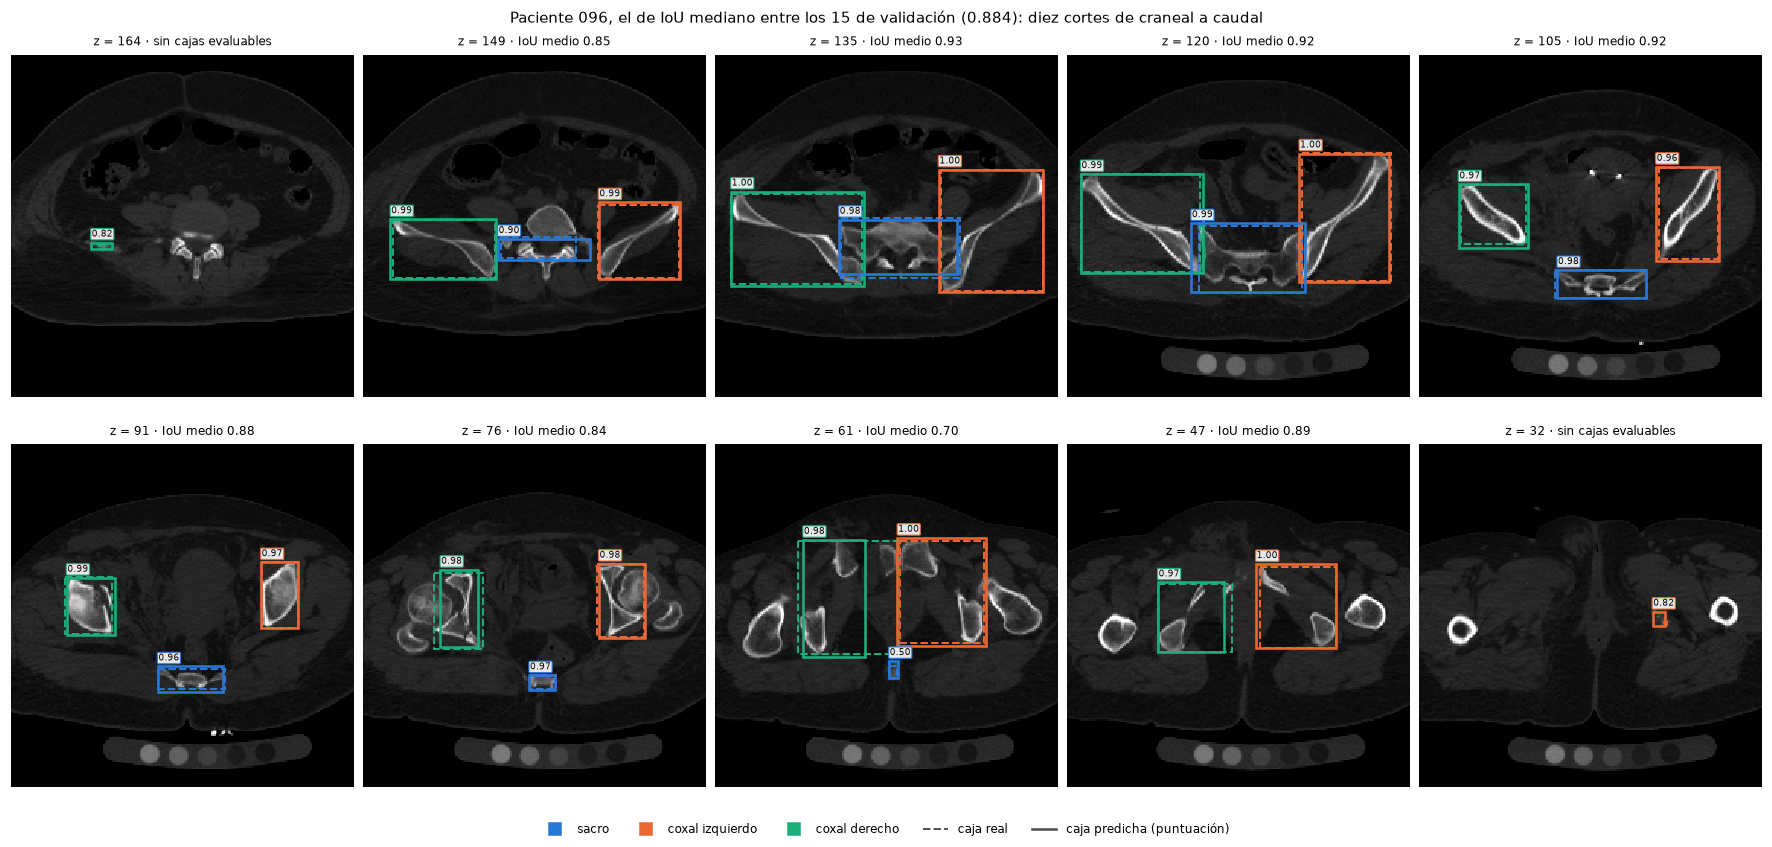

In [73]:
cajas_1 = por_caja(evaluacion_1)                                        
iou_paciente = cajas_1.groupby("caso").iou.mean().sort_values()
tipico = iou_paciente.index[len(iou_paciente) // 2]                     
idx = np.nonzero((caso_val == tipico) & (real_val.sum(1) > 0))[0]          
idx = idx[np.argsort(-z_val[idx])]                                         
elegidos = idx[np.linspace(0, len(idx) - 1, 10).round().astype(int)]

fig, axs = plt.subplots(2, 5, figsize=(16, 7.6), layout="constrained")
for ax, i in zip(axs.flat, elegidos):
    ious = evaluacion_1[i][0]
    mostrar_detecciones(ax, filas_val[i], salida_val, i, max_por_region=1, titulo=f"z = {z_val[i]}" + (
        f" · IoU medio {np.mean(list(ious.values())):.2f}" if ious else " · sin cajas evaluables"))
    encuadrar(ax, [c for j in idx for c in cajas_val[j].values()], margen=8)
fig.suptitle(f"Paciente {tipico}, el de IoU mediano entre los 15 de validación ({iou_paciente[tipico]:.3f}): diez cortes "
             f"de craneal a caudal", fontsize=10)
leyenda_detecciones(fig, loc="outside lower center", ncol=5, frameon=False)
plt.show()

El paciente de IoU mediano, el 096 (0,884), de craneal a caudal. Las cajas siguen a cada hueso a lo largo de toda la pelvis, con puntuaciones de 0,96 a 1,00 en la zona central. Los problemas están en los extremos. En el primer corte (z = 164) solo asoma la punta de la cresta ilíaca derecha, de menos de 8 px: no cuenta para la métrica, y el modelo le pone una caja pequeña (0,82). El corte con peor IoU, z = 61 (0,70), es el de la sínfisis: la caja real del coxal derecho llega hasta la rama del pubis, más hacia el centro de lo que cubre la predicha, y el cóccix sale con una caja diminuta de puntuación 0,50.

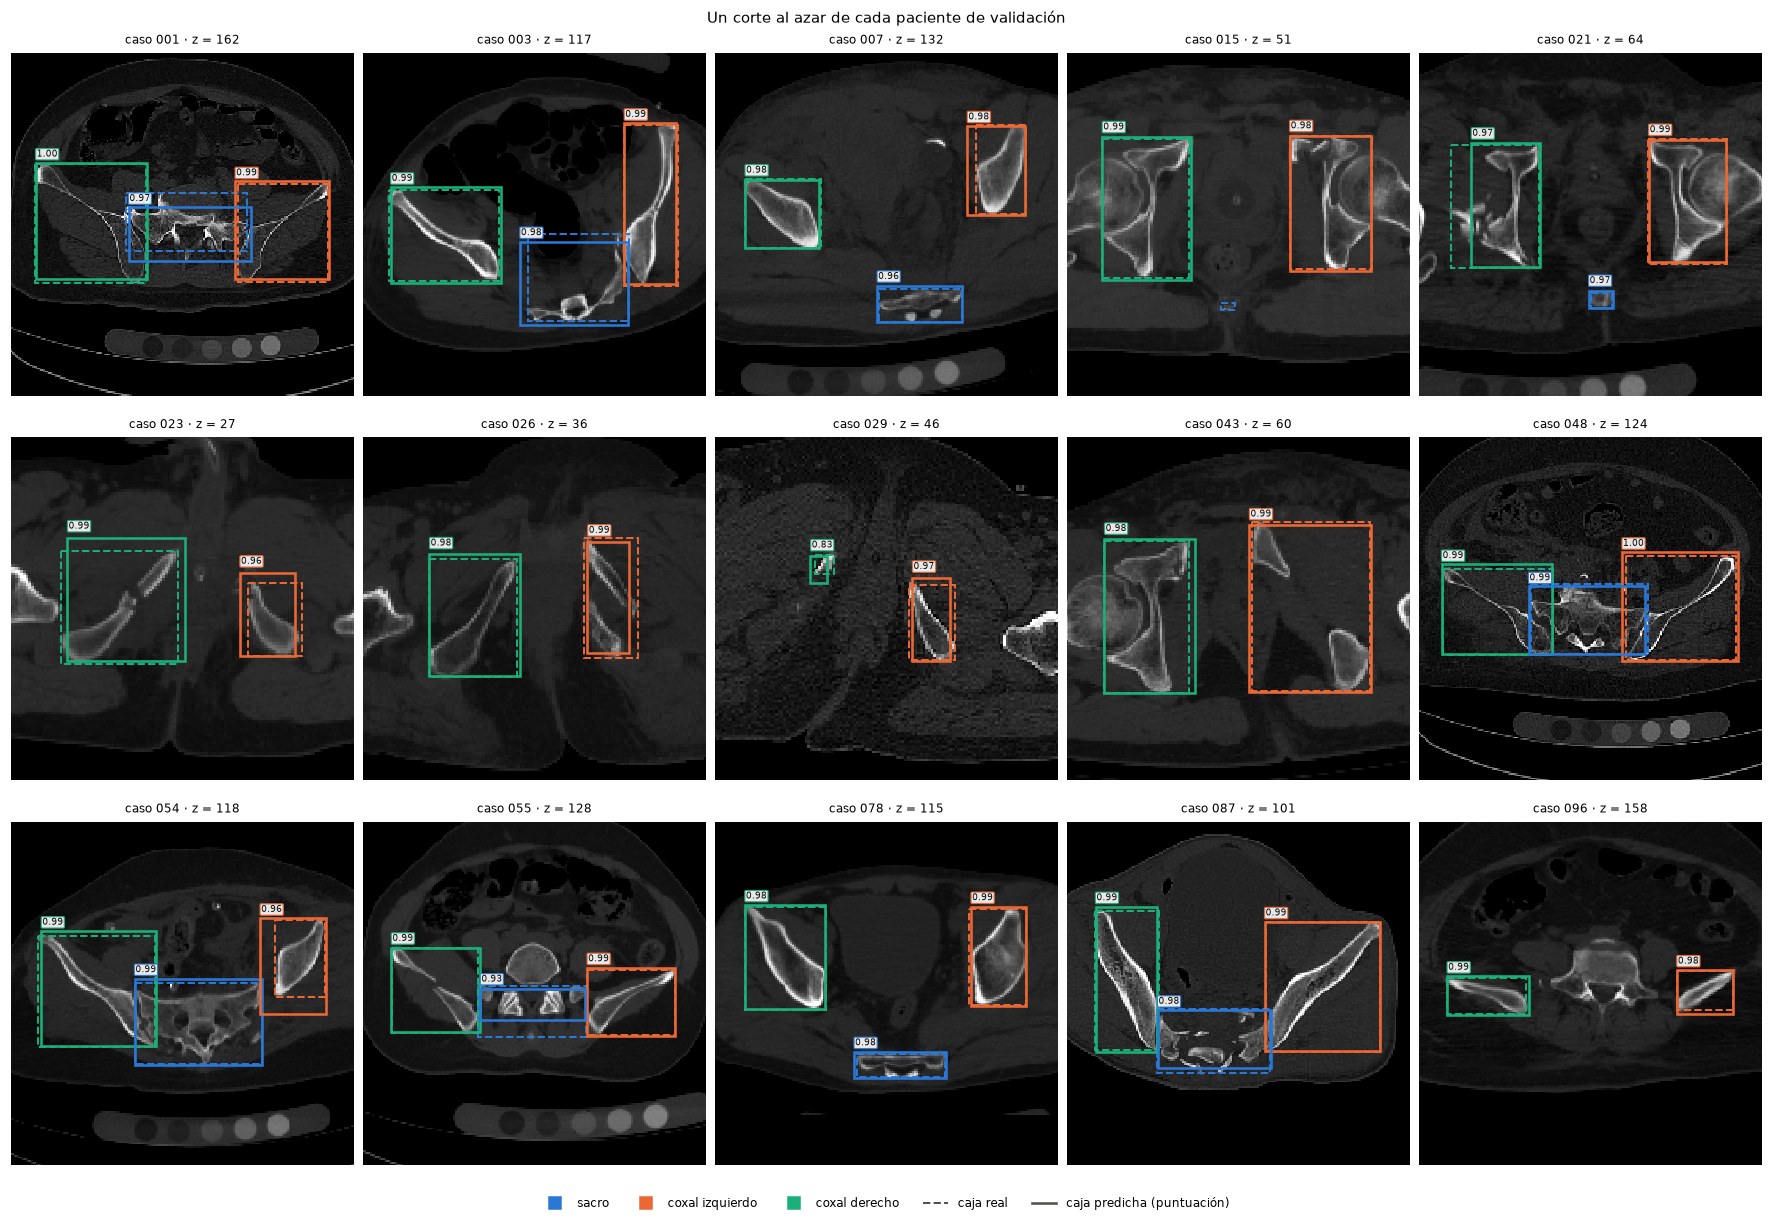

In [74]:
rng = np.random.default_rng(0)
fig, axs = plt.subplots(3, 5, figsize=(16, 11), layout="constrained")
for ax, caso in zip(axs.flat, splits["val"]):
    i = rng.choice(np.nonzero((caso_val == caso) & (real_val.sum(1) >= 2))[0])   # un corte al azar con 2–3 regiones
    mostrar_detecciones(ax, filas_val[i], salida_val, i, max_por_region=1, titulo=f"caso {caso} · z = {z_val[i]}")
    encuadrar(ax, cajas_val[i].values(), margen=16)
fig.suptitle("Un corte al azar de cada paciente de validación", fontsize=10)
leyenda_detecciones(fig, loc="outside lower center", ncol=5, frameon=False)
plt.show()

En los 15 pacientes las cajas caen sobre su región, también en un corte con mucho ruido (caso 029) o con poca pelvis (caso 096, z = 158, donde el modelo no confunde la vértebra lumbar del centro con el sacro y no le pone caja). Las diferencias están en los bordes: el sacro del 001 y el del 055 salen con una caja desplazada o más estrecha que la real, el coxal derecho del 021 queda más estrecho que su caja real, y la caja diminuta del cóccix del 015 no se encuentra.

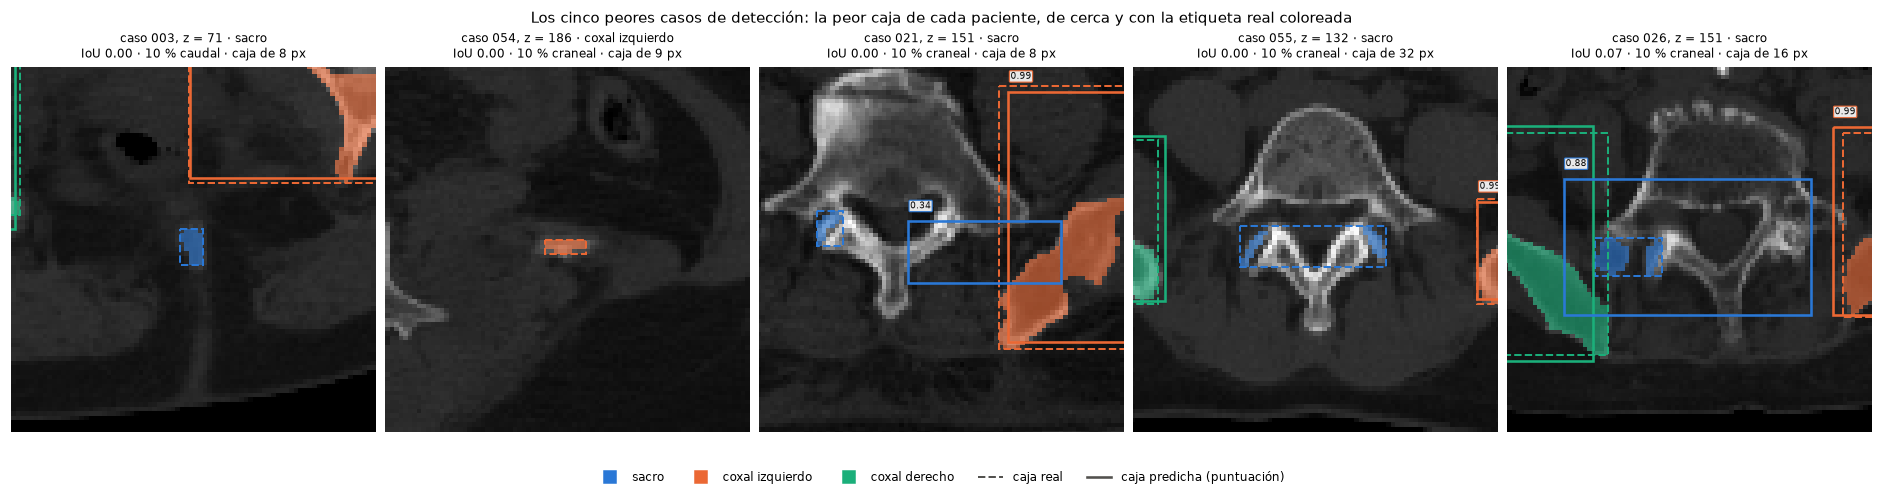

In [75]:
peores = cajas_1.sort_values("iou").drop_duplicates("caso").head(5)      # la peor caja de cada paciente, y de esas las 5 peores
fig, axs = plt.subplots(1, 5, figsize=(17, 4.4), layout="constrained")
for ax, (_, r) in zip(axs, peores.iterrows()):
    i = r.corte
    mostrar_detecciones(ax, filas_val[i], salida_val, i, etiqueta=True, max_por_region=1,
                        titulo=f"caso {r.caso}, z = {z_val[i]} · {r['región']}\nIoU {r.iou:.2f} · {r.tramo} · caja de {r.lado} px")
    cj, _, cl = decodificar(salida_val, i, max_por_region=1)
    encuadrar(ax, [cajas_val[i][r.k], *cj[cl == r.k - 1].tolist()], margen=14, minimo=40)   # de cerca, la región que falla
fig.suptitle("Los cinco peores casos de detección: la peor caja de cada paciente, de cerca y con la etiqueta real coloreada", fontsize=10)
leyenda_detecciones(fig, loc="outside lower center", ncol=5, frameon=False)
plt.show()

### Los cinco peores casos de detección

La peor caja de cada paciente de validación y, de ellas, las cinco peores, de cerca y con la etiqueta real coloreada:

| Caso | Corte | Qué se ve | Hipótesis |
|---|---|---|---|
| 003 | z = 71 · sacro · 10 % caudal · caja de 8 px | El cóccix, una mancha de 8 px; ninguna detección supera 0,3 | Al límite de la regla *ignore*: una región de media celda apenas tiene rasgos propios |
| 054 | z = 186 · coxal izquierdo · 10 % craneal · 9 px | La punta de la cresta ilíaca, una lámina de pocos píxeles; sin detección | Volumen parcial: en el último corte el hueso apenas se distingue del tejido blando |
| 021 | z = 151 · sacro · 10 % craneal · 8 px | Un trozo de sacro de 8 px junto a una vértebra; la predicción (0,34) cae sobre el arco vertebral | La unión con L5, que no está anotada y está pegada al sacro |
| 055 | z = 132 · sacro · 10 % craneal · 32 px | Las dos alas del sacro asoman a los lados del cuerpo vertebral; ninguna caja de sacro | En ese corte, el sacro se parece más a una vértebra lumbar que a un sacro |
| 026 | z = 151 · sacro · 10 % craneal · 16 px | Un trozo de sacro de 16 px; la predicción (0,88) cubre el cuerpo vertebral entero | Confunde L5 con el sacro |

Los cinco están en un extremo de su hueso —cuatro en el craneal— y miden entre 8 y 32 px. Cuatro son del sacro, y tres de esos cuatro tienen que ver con L5, la vértebra lumbar que PENGWIN no anota: el modelo la confunde con el sacro o no sabe separarlo de ella. Los vecinos de la pila no ayudan aquí: la vértebra se ve igual en los cortes de arriba y de abajo.

## 4.4 · Dónde falla la segmentación

Antes de abrir la prueba conviene saber dónde se pierde el Dice de fragmento. Se desglosan los fragmentos de validación por su papel ,el mayor de su hueso en el corte o uno secundario, por cuántos fragmentos tiene su hueso en ese corte y por su tamaño. Y de los no encontrados se mira si la semántica los cubría y cuánto valía el mapa de centros en su centroide.

In [76]:
# Una fila por fragmento real evaluable de validación, con lo que puede explicar que no se encuentre
diag = []
for fila, (filas_i, _) in zip(filas_val, frag_val3):
    lab = np.asarray(lab_cache[fila])
    area_hueso = {}
    for k, v, astilla, area, pareja, dice, iou in filas_i:
        area_hueso.setdefault(k, []).append(area)
    for k, v, astilla, area, pareja, dice, iou in filas_i:
        if not astilla:
            diag.append({"fila": fila, "hueso": k, "etiqueta": v, "area": area, "encontrado": pareja > 0, "dice": dice,
                         "papel": "el mayor de su hueso" if area == max(area_hueso[k]) else "secundario",
                         "fragmentos del hueso": len(area_hueso[k])})
diag = pd.DataFrame(diag)

# Para los no encontrados: ¿cubría la semántica el fragmento? ¿Había un pico de centro en él?
perdidos = diag[~diag.encontrado]
cubierto, altura = [], []
for fila, g in perdidos.groupby("fila"):
    salida_f, seg_f = predecir(modelo3, preparar_lote_completo([fila])["imagen"])
    lab = np.asarray(lab_cache[fila])
    for r in g.itertuples():
        ys, xs = np.nonzero(lab == r.etiqueta)
        cy, cx = int(round(ys.mean())), int(round(xs.mean()))
        cubierto.append(float((seg_f[0][0][ys, xs] == r.hueso).mean()))
        altura.append(float(seg_f[1][0, r.hueso - 1, max(cy - 4, 0):cy + 5, max(cx - 4, 0):cx + 5].max()))
perdidos = perdidos.assign(cubierto=cubierto, altura=altura)

def tabla(por):
    return diag.groupby(por, observed=True).agg(fragmentos=("dice", "size"), encontrados=("encontrado", "mean"),
                                                 Dice=("dice", "mean")).round(3)

print(f"{len(diag):,} fragmentos reales evaluables en validación · {len(perdidos)} no encontrados")
print(f"  de ellos, con la semántica correcta en más de la mitad de sus píxeles: {(perdidos.cubierto > 0.5).mean():.0%}")
print(f"  con un pico de centro ≥ {UMBRAL_CENTRO} a menos de 4 px de su centroide: {(perdidos.altura >= UMBRAL_CENTRO).mean():.0%} · "
      f"altura del mapa de calor en su centro: mediana {perdidos.altura.median():.2f}")
display(tabla("papel"))
display(tabla("fragmentos del hueso"))
tabla(pd.cut(diag.area, [0, 100, 200, 500, 1000, np.inf], labels=["< 100 px", "100–199", "200–499", "500–999", "≥ 1.000 px"]))

6,639 fragmentos reales evaluables en validación · 510 no encontrados
  de ellos, con la semántica correcta en más de la mitad de sus píxeles: 95%
  con un pico de centro ≥ 0.3 a menos de 4 px de su centroide: 12% · altura del mapa de calor en su centro: mediana 0.09


,fragmentos,encontrados,Dice
papel,,,
el mayor de su hueso,5390,0.996,0.935
secundario,1249,0.607,0.512


,fragmentos,encontrados,Dice
fragmentos del hueso,,,
1,4139,0.998,0.952
2,2088,0.853,0.754
3,410,0.522,0.399
4,2,1.000,0.965


,fragmentos,encontrados,Dice
area,,,
< 100 px,805,0.733,0.625
100–199,640,0.775,0.688
200–499,1997,0.928,0.844
500–999,2501,0.997,0.952
≥ 1.000 px,696,1.000,0.963


El diagnóstico es nítido:

- **El fragmento mayor de cada hueso casi nunca se pierde** (99,6 %, Dice 0,935). Los **secundarios**, el 19 % de los fragmentos, solo se encuentran en el 61 % de los casos (Dice 0,512). Un hueso entero en el corte da un Dice de 0,952; uno roto en dos, 0,754; en tres, 0,399.
- **Lo que falta no es la región, es el centro.** La semántica cubre el 95 % de los fragmentos perdidos, pero solo el 12 % tiene un pico por encima del umbral cerca de su centroide: allí el mapa de calor vale 0,09 de mediana. Sin pico propio, sus píxeles votan por el centro del fragmento vecino y se funden con él.
- **El tamaño pesa, pero no lo explica todo.** Por debajo de 200 px se encuentra el 73–78 %; por encima de 500 px, casi todo.

El cuello de botella es la cabeza de centros, y encaja con lo que contaron las curvas de 3.4: es justo la pérdida que sobreajusta. Cuatro ejemplos:


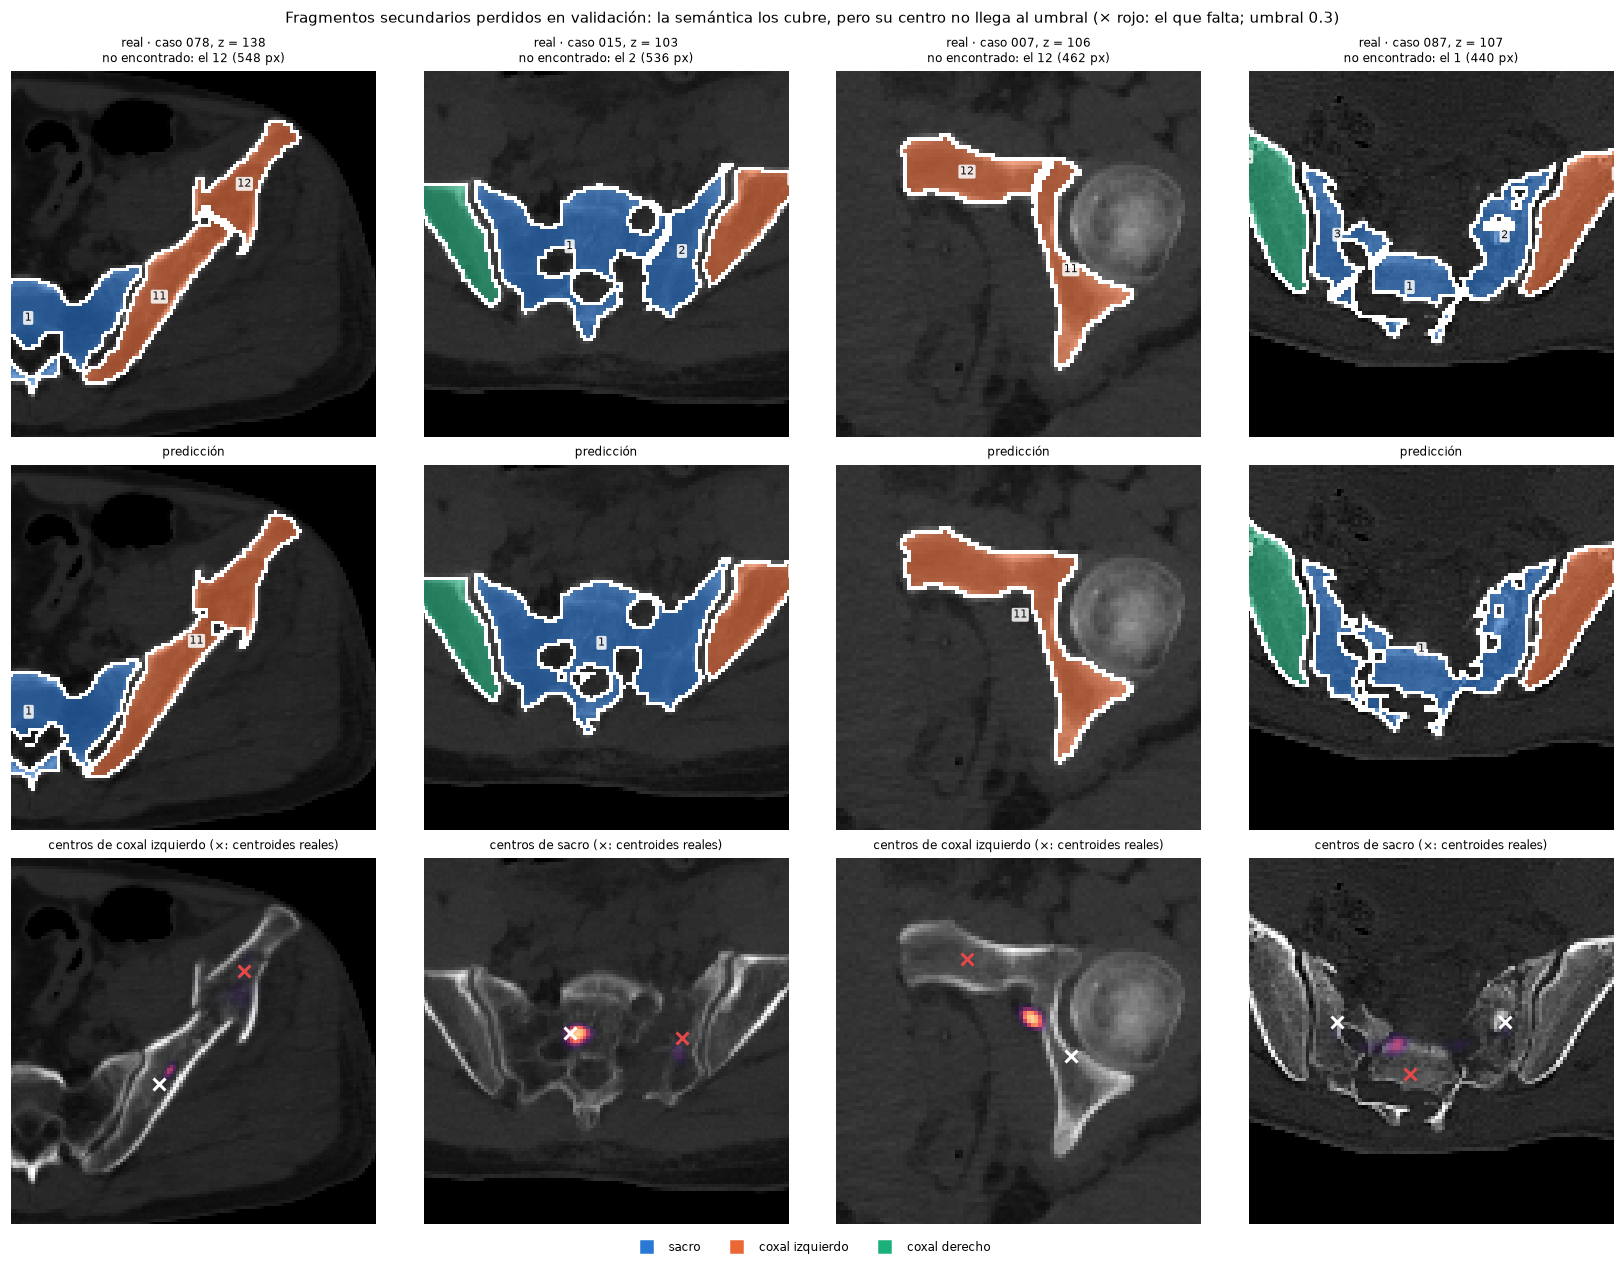

In [77]:
# Cuatro cortes de validación con un fragmento secundario perdido: la etiqueta real, la predicción y el mapa de centros
ejemplos_p = perdidos[perdidos.cubierto > 0.5].sort_values("area", ascending=False).drop_duplicates("fila")
ejemplos_p = ejemplos_p.groupby(caso_val[np.searchsorted(filas_val, ejemplos_p.fila)]).head(1).head(4)
fig, axs = plt.subplots(3, 4, figsize=(15, 11.4), layout="constrained")
for j, r in enumerate(ejemplos_p.itertuples()):
    hu, lab = np.asarray(hu_cache[r.fila]), np.asarray(lab_cache[r.fila])
    i = int(np.searchsorted(filas_val, r.fila))
    salida_f, seg_f = predecir(modelo3, preparar_lote_completo([r.fila])["imagen"])
    mostrar_corte(axs[0, j], hu, lab, fragmentos=True, titulo=f"real · caso {caso_val[i]}, z = {z_val[i]}\n"
                  f"no encontrado: el {r.etiqueta} ({r.area} px)")
    mostrar_corte(axs[1, j], hu, etiquetas_val3[i], fragmentos=True, titulo="predicción")
    mostrar_corte(axs[2, j], hu, titulo=f"centros de {HUESO[r.hueso]} (×: centroides reales)")
    calor = seg_f[1][0, r.hueso - 1]
    axs[2, j].imshow(calor, cmap="magma", vmin=0, vmax=1, alpha=np.clip(1.5 * calor, 0, 1))
    for v in np.unique(lab[lab > 0]):
        if (v - 1) // 10 + 1 == r.hueso:
            ys, xs = np.nonzero(lab == v)
            axs[2, j].plot(xs.mean(), ys.mean(), "x", color="white" if v != r.etiqueta else "#e34948", ms=8, mew=2)
    for ax in axs[:, j]:
        encuadrar_corte(ax, [cajas_por_region(lab)[r.hueso]], margen=16, minimo=40)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("Fragmentos secundarios perdidos en validación: la semántica los cubre, pero su centro no llega al umbral "
             f"(× rojo: el que falta; umbral {UMBRAL_CENTRO})", fontsize=10)
plt.show()

En los cuatro, el modelo pone un único pico ,junto al principal o entre los dos fragmentos, o uno tan débil que no llega al umbral, y el secundario acaba dentro del principal. En el caso 087, el fragmento que se pierde es el del centro del sacro, entre dos laterales, y los tres salen como uno. Es la limitación que el model card declara, como pide el  7: **dos fragmentos que se tocan en la superficie de fractura pueden fundirse en uno**.

## 4.5 · El conjunto de prueba: las métricas del  5

Con la entrada, el modelo y la decodificación fijados en validación, el conjunto de prueba se abre **una sola vez**: los 2.293 cortes de los 15 pacientes que no se han usado ni para entrenar ni para elegir nada. Las definiciones son las de validación y, como extra opcional del  5, se añaden el HD95 y el ASSD de cada fragmento encontrado, en mm, medidos en el plano del corte. Además, el Dice de fragmento de cada paciente, con el intervalo de confianza de su media por *bootstrap* (10.000 remuestreos de los 15 pacientes): con tan pocos pacientes, conviene saber cuánto podría moverse la cifra con otros.

In [ ]:
def borde(m: np.ndarray) -> np.ndarray:
    return m & ~ndimage.binary_erosion(m)


def distancias_superficie(a: np.ndarray, b: np.ndarray) -> tuple[float, float]:
    """HD95 y ASSD, en mm, entre dos máscaras de un corte: distancias de cada punto del borde de una al borde de la otra."""
    ba, bb = borde(a), borde(b)
    da = ndimage.distance_transform_edt(~bb, sampling=bc.ISO_MM)[ba]
    db = ndimage.distance_transform_edt(~ba, sampling=bc.ISO_MM)[bb]
    return max(np.percentile(da, 95), np.percentile(db, 95)), (da.sum() + db.sum()) / (len(da) + len(db))


def dice_por_paciente(frag_, filas) -> pd.Series:
    """Dice de fragmento medio de cada paciente."""
    caso_f = indice.case_id.to_numpy()[filas]
    return pd.DataFrame([(caso_f[i], dice) for i, (filas_i, _) in enumerate(frag_) for k, v, astilla, area, p, dice, iou in filas_i
                         if not astilla], columns=["caso", "dice"]).groupby("caso").dice.mean()


def ic_bootstrap(a: pd.Series, b: pd.Series, n: int = 10_000, semilla: int = 0) -> tuple[float, float, float]:
    # Diferencia media por paciente entre dos modelos (a − b) y su intervalo del 95 %, remuestreando pacientes
    d = (a - b.reindex(a.index)).to_numpy()
    medias = d[np.random.default_rng(semilla).integers(0, len(d), (n, len(d)))].mean(1)
    return float(d.mean()), *np.percentile(medias, [2.5, 97.5])


# El conjunto de prueba, abierto una sola vez: la entrada, el modelo y la decodificación ya están fijados
filas_test = filas_de("test")
t0 = time.perf_counter()
salida_test, etiquetas_test = inferir_completo(modelo3, filas_test)
s5_test, frag_test = metricas_seccion5(salida_test, etiquetas_test, filas_test)
superficie = [distancias_superficie(etiquetas_test[i] == p, np.asarray(lab_cache[filas_test[i]]) == v)
              for i, (filas_i, _) in enumerate(frag_test) for k, v, astilla, area, p, dice, iou in filas_i
              if p and not astilla]
hd95, assd = np.array(superficie).T
print(f"{len(filas_test):,} cortes de los {len(splits['test'])} pacientes de prueba, inferidos y evaluados en "
      f"{time.perf_counter() - t0:.0f} s")
print(f"Extra ( 5, opcional), sobre los {len(hd95):,} fragmentos encontrados: HD95 mediana {np.median(hd95):.1f} mm "
      f"(media {hd95.mean():.1f}) · ASSD mediana {np.median(assd):.2f} mm (media {assd.mean():.2f})")

# El Dice de fragmento de cada paciente de prueba, y el intervalo del 95 % de su media (bootstrap de los 15 pacientes)
dpp = dice_por_paciente(frag_test, filas_test)
media_p, lo_p, hi_p = ic_bootstrap(dpp, pd.Series(0.0, index=dpp.index))
print(f"Dice de fragmento por paciente: mediana {dpp.median():.3f}, de {dpp.min():.3f} (caso {dpp.idxmin()}) a "
      f"{dpp.max():.3f} (caso {dpp.idxmax()}) · media {media_p:.3f} [IC 95 %: {lo_p:.3f}, {hi_p:.3f}]")
prueba5 = pd.DataFrame({"objetivo ( 5)": OBJETIVOS5, "validación": s5_val, "prueba": s5_test}).loc[list(OBJETIVOS5)]
prueba5["cumple en prueba"] = np.where(prueba5["prueba"] >= prueba5["objetivo ( 5)"], "sí", "no")
prueba5.round(4)

2,293 cortes de los 15 pacientes de prueba, inferidos y evaluados en 50 s
Extra (§5, opcional), sobre los 6,186 fragmentos encontrados: HD95 mediana 1.5 mm (media 6.9) · ASSD mediana 0.40 mm (media 1.33)
Dice de fragmento por paciente: mediana 0.849, de 0.769 (caso 025) a 0.929 (caso 019) · media 0.849 [IC 95 %: 0.823, 0.874]


,objetivo (§5),validación,prueba,cumple en prueba
F1 macro,0.85,0.9915,0.9940,sí
AUC macro,0.85,0.9994,0.9990,sí
IoU promedio,0.65,0.8833,0.8835,sí
"mAP@0,50",0.65,0.9788,0.9775,sí
"mAP@[0,50:0,95]",0.40,0.7655,0.7670,sí
Dice de fragmento,0.85,0.8553,0.8475,no
IoU de fragmento,0.70,0.8089,0.7970,sí


**En prueba se cumplen seis de los siete objetivos**, con margen: F1 0,994, AUC 0,999, IoU 0,884, mAP@0,50 0,978, mAP@[0,50:0,95] 0,767 e IoU de fragmento 0,797. **El Dice de fragmento queda en 0,8475, 0,0025 por debajo del 0,85**; en validación era 0,855. Por paciente, el Dice de fragmento va de 0,769 (caso 025) a 0,929 (caso 019), y el intervalo del 95 % de su media es [0,823, 0,874]: con 15 pacientes, la cifra podría moverse unas dos centésimas hacia cualquier lado con otro grupo, ocho veces lo que falta para el objetivo. No se ha cambiado nada para corregirlo: un ajuste hecho mirando la prueba la invalidaría como prueba.

En los extras, la mitad de los fragmentos encontrados tiene un HD95 de 1,5 mm o menos —un vóxel— y un ASSD de 0,40 mm o menos. Las medias, 6,9 y 1,33 mm, las arrastra una cola de fragmentos mal delimitados.

Por hueso:

In [79]:
cajas_test = [cajas_por_region(np.asarray(lab_cache[f])) for f in filas_test]
evaluacion_test = [evaluar_corte(salida_test, i, c) for i, c in enumerate(cajas_test)]
detecciones_test = todas_las_detecciones(salida_test, cajas_test)
prob_test = torch.sigmoid(salida_test["cls"]).numpy()
real_test = np.array([[k in c for k in COLOR] for c in cajas_test], dtype=int)
frag_t = pd.DataFrame([(*f, ) for filas_i, _ in frag_test for f in filas_i], columns=COLUMNAS_FRAG)
frag_t = frag_t[~frag_t.astilla]
inventados_t = [k for _, s in frag_test for k, _ in s]

por_hueso_test = {}
for k, nombre in HUESO.items():
    ious = np.array([e[0][k] for e in evaluacion_test if k in e[0]])
    f = frag_t[frag_t.hueso == k]
    por_hueso_test[nombre] = {
        "F1": f1_score(real_test[:, k - 1], prob_test[:, k - 1] > 0.5), "AUC": roc_auc_score(real_test[:, k - 1], prob_test[:, k - 1]),
        "IoU de detección": ious.mean(), "AP@0,50": precision_media(detecciones_test, cajas_test, k - 1, 0.5),
        "AP@[0,50:0,95]": np.mean([precision_media(detecciones_test, cajas_test, k - 1, u) for u in UMBRALES_IOU]),
        "Dice de fragmento": f.dice.mean(), "IoU de fragmento": f.iou.mean(), "fragmentos reales": len(f),
        "no encontrados": int((f.pareja == 0).sum()), "inventados": inventados_t.count(k)}
enteras = ["fragmentos reales", "no encontrados", "inventados"]
pd.DataFrame(por_hueso_test).T.astype(float).round(3).astype(dict.fromkeys(enteras, int))

,F1,AUC,IoU de detección,"AP@0,50","AP@[0,50:0,95]",Dice de fragmento,IoU de fragmento,fragmentos reales,no encontrados,inventados
sacro,0.985,0.998,0.797,0.952,0.613,0.811,0.748,1571,148,35
coxal izquierdo,0.998,0.999,0.917,0.990,0.857,0.869,0.825,2481,167,126
coxal derecho,1.000,1.000,0.905,0.990,0.831,0.849,0.800,2660,211,134


El sacro vuelve a ser el más difícil: tiene el peor IoU de detección (0,797) y el peor Dice de fragmento (0,811). El coxal izquierdo es el mejor segmentado (0,869), y los dos coxales son los que más fragmentos inventan (126 y 134, frente a 35 del sacro).

### Matrices de confusión

La clasificación es multi-etiqueta (decisión 1), así que su matriz de confusión son tres matrices 2×2, una por región:


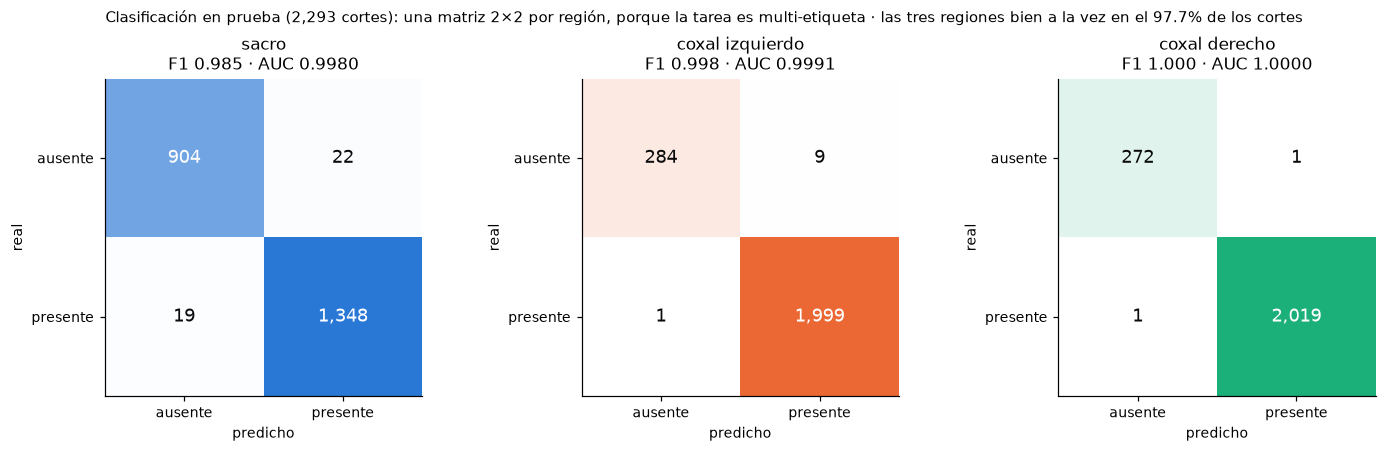

In [80]:
fig, axs = plt.subplots(1, 3, figsize=(13, 4), layout="constrained")
for ax, (k, nombre) in zip(axs, HUESO.items()):
    real, pred = real_test[:, k - 1].astype(bool), prob_test[:, k - 1] > 0.5
    matriz = np.array([[(~real & ~pred).sum(), (~real & pred).sum()], [(real & ~pred).sum(), (real & pred).sum()]])
    ax.imshow(matriz, cmap=mcolors.LinearSegmentedColormap.from_list("", ["white", COLOR[k]]), vmin=0)
    for (i, j), v in np.ndenumerate(matriz):
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=12, color="white" if v > matriz.max() / 2 else TINTA)
    ax.set_xticks([0, 1], ["ausente", "presente"])
    ax.set_yticks([0, 1], ["ausente", "presente"])
    ax.set(xlabel="predicho", ylabel="real", title=f"{nombre}\nF1 {por_hueso_test[nombre]['F1']:.3f} · "
                                                  f"AUC {por_hueso_test[nombre]['AUC']:.4f}")
    ax.grid(False)
todas = (real_test.astype(bool) == (prob_test > 0.5)).all(1)
fig.suptitle(f"Clasificación en prueba ({len(filas_test):,} cortes): una matriz 2×2 por región, porque la tarea es "
             f"multi-etiqueta · las tres regiones bien a la vez en el {todas.mean():.1%} de los cortes", fontsize=10)
plt.show()

Casi todos los errores son del sacro: 22 cortes en los que lo ve sin estar y 19 en los que está y no lo ve. Los dos coxales suman 12 errores en 2.293 cortes, y las tres regiones salen bien a la vez en el 97,7 % de los cortes.

### El pipeline, visto

Seis pacientes de prueba, un corte al azar de cada uno con algún hueso fracturado: arriba, la etiqueta real; abajo, lo que devuelve el pipeline, con la caja de cada región y los fragmentos coloreados según su hueso. El número de cada fragmento sigue la codificación de PENGWIN: del 1 al 10 los del sacro, del 11 al 20 los del coxal izquierdo y del 21 al 30 los del coxal derecho.


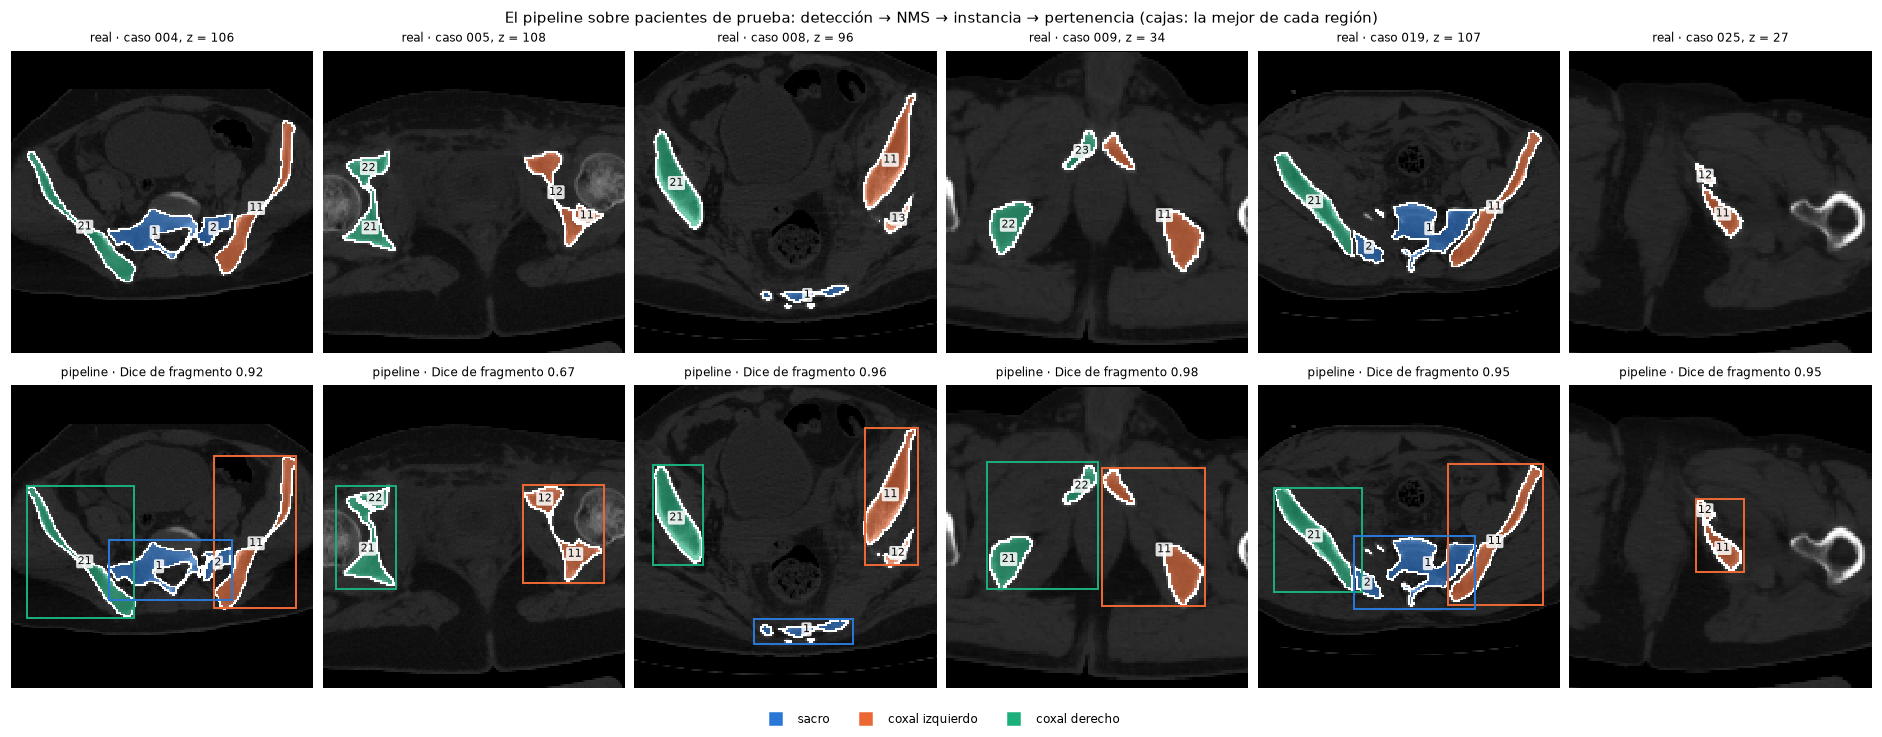

In [81]:
caso_test, z_test = indice.case_id.to_numpy()[filas_test], indice.z.to_numpy()[filas_test]


def mostrar_pipeline(ax, i, titulo=""):
    """Un corte de prueba con lo que devuelve el pipeline: fragmentos coloreados por su hueso y la caja de cada región."""
    mostrar_corte(ax, np.asarray(hu_cache[filas_test[i]]), etiquetas_test[i], fragmentos=True, titulo=titulo)
    for k, (x0, y0, x1, y1) in cajas_del_corte(salida_test, i).items():
        ax.add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.3))


def dice_del_corte(i) -> float:
    d = [dice for k, v, astilla, area, p, dice, iou in frag_test[i][0] if not astilla]
    return float(np.mean(d)) if d else np.nan


# Seis pacientes de prueba, un corte al azar de cada uno con algún hueso fracturado
rng = np.random.default_rng(0)
fracturado_test = (indice.n_frag_total.to_numpy() > indice.n_regions.to_numpy())[filas_test]
fig, axs = plt.subplots(2, 6, figsize=(17, 6.6), layout="constrained")
for j, caso in enumerate(splits["test"][:6]):
    i = int(rng.choice(np.nonzero((caso_test == caso) & fracturado_test)[0]))
    mostrar_corte(axs[0, j], np.asarray(hu_cache[filas_test[i]]), np.asarray(lab_cache[filas_test[i]]), fragmentos=True,
                  titulo=f"real · caso {caso}, z = {z_test[i]}")
    mostrar_pipeline(axs[1, j], i, titulo=f"pipeline · Dice de fragmento {dice_del_corte(i):.2f}")
    for ax in axs[:, j]:
        encuadrar_corte(ax, cajas_test[i].values(), margen=10)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("El pipeline sobre pacientes de prueba: detección → NMS → instancia → pertenencia (cajas: la mejor de cada región)",
             fontsize=10)
plt.show()

El pipeline acierta los huesos y la mayoría de los fragmentos, con contornos que siguen al hueso: cinco de los seis cortes tienen un Dice de fragmento de 0,92 o más. El más bajo, el del caso 005 (0,67), tiene los dos coxales rotos en dos fragmentos que se tocan: el pipeline encuentra los cuatro, pero traza la frontera entre ellos en otro sitio, y buena parte de cada fragmento secundario se la queda su vecino. Es el patrón de 4.4: los píxeles votan por el centro equivocado.

### Los cinco peores cortes de segmentación

El peor corte de cada paciente de prueba por Dice de fragmento, y de ellos los cinco peores, ampliados sobre el hueso que falla: la etiqueta real, lo que devuelve el pipeline y el mapa de centros de ese hueso, con los centroides reales marcados (en rojo, los no encontrados).


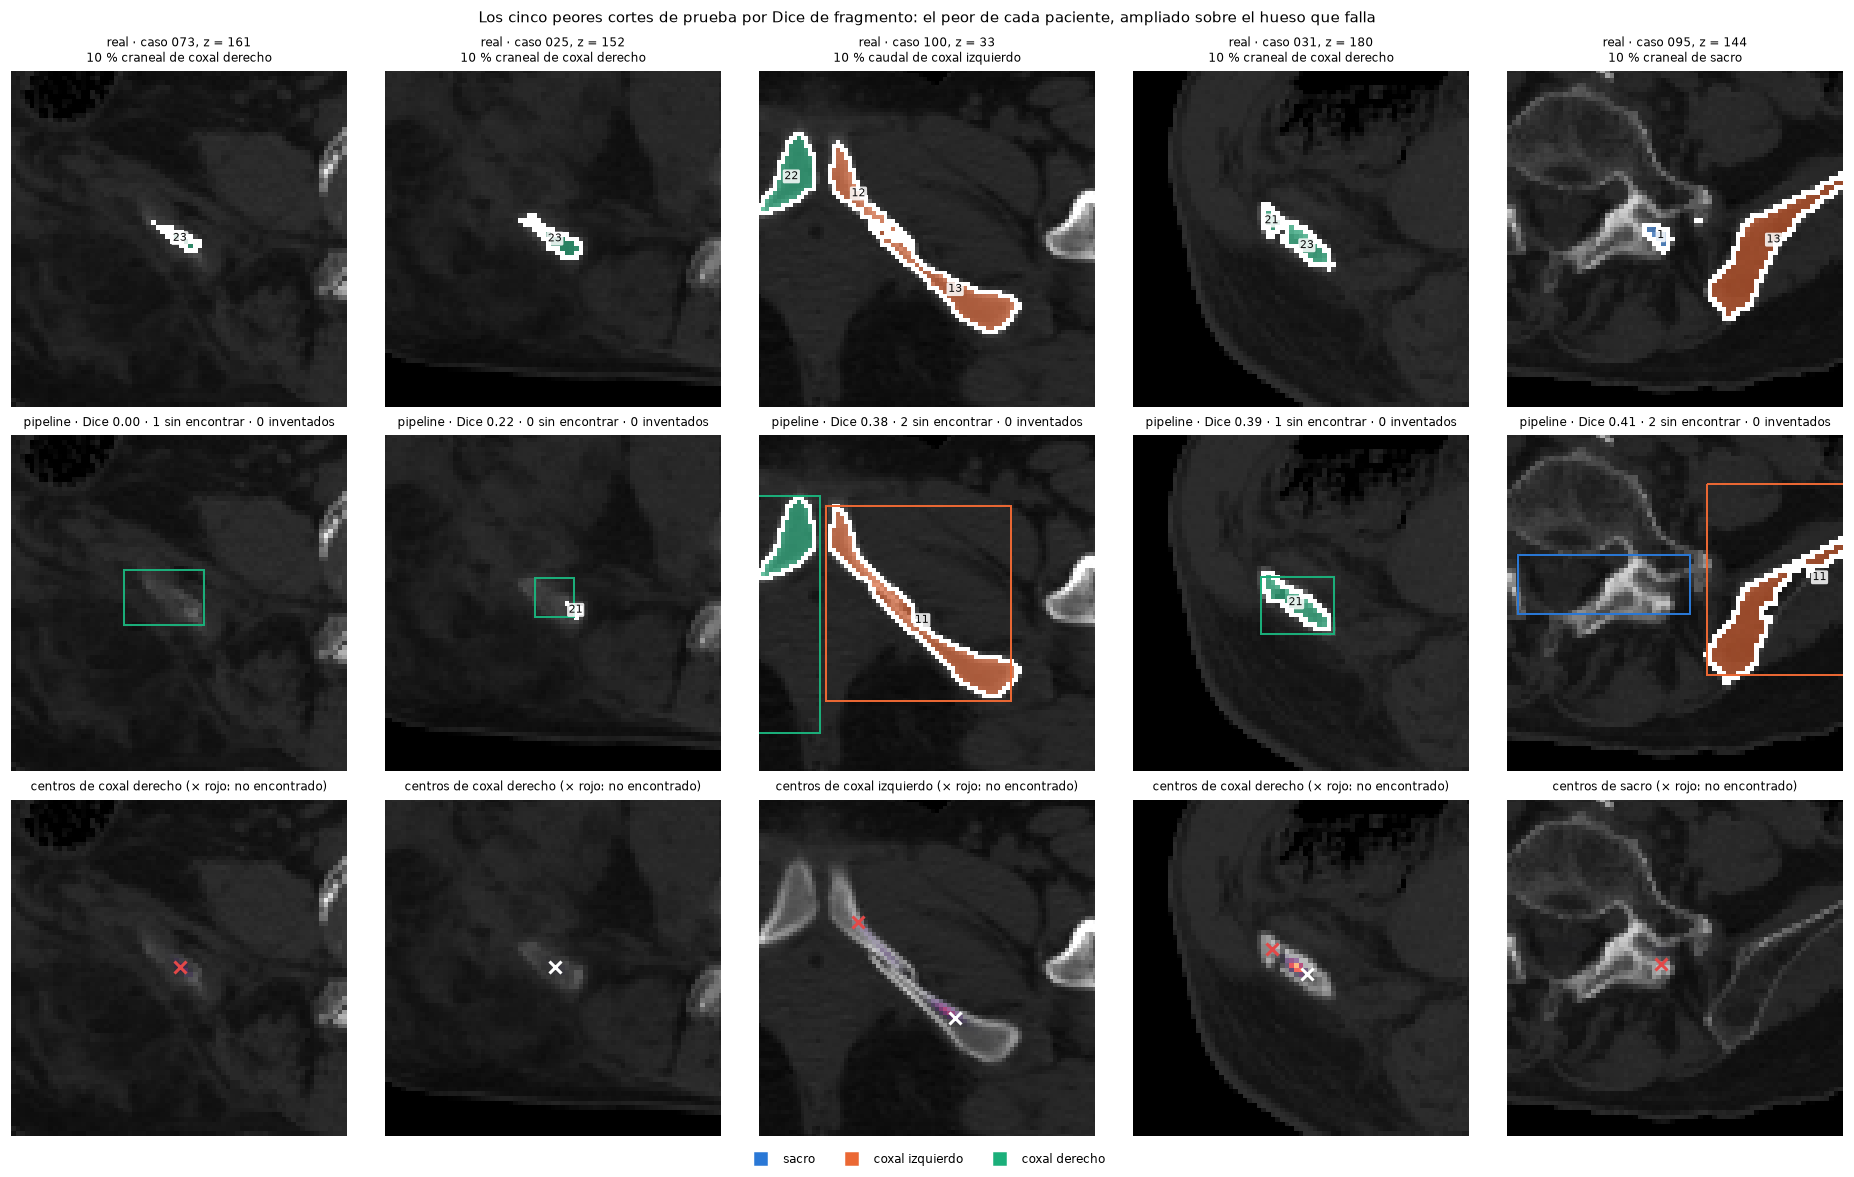

,corte,caso,z,Dice,fragmentos reales,no encontrados,inventados,fragmento que falla,tramo
0,1817,073,161,0.000,1,1,0,coxal derecho · 23 (31 px),10 % craneal
1,878,025,152,0.215,1,0,0,coxal derecho · 23 (58 px),10 % craneal
2,2165,100,33,0.379,4,2,0,coxal izquierdo · 12 (152 px),10 % caudal
3,1185,031,180,0.391,2,1,0,coxal derecho · 21 (29 px),10 % craneal
4,2122,095,144,0.406,4,2,0,sacro · 1 (32 px),10 % craneal


In [82]:
extension_test = {}                                  # (paciente, región) → primer y último z en que aparece
for z, caso, cajas in zip(z_test, caso_test, cajas_test):
    for k in cajas:
        a, b = extension_test.get((caso, k), (z, z))
        extension_test[(caso, k)] = (min(a, z), max(b, z))


def tramo_test(i: int, k: int) -> str:
    """Como tramo (4.3), para los cortes de prueba."""
    a, b = extension_test[(caso_test[i], k)]
    pos = (z_test[i] - a) / max(b - a, 1)
    return TRAMOS[1 + int(np.searchsorted([0.1, 0.9], pos, side="right"))] if 0 <= pos <= 1 else TRAMOS[0 if pos < 0 else -1]


cortes_test = pd.DataFrame([{"corte": i, "caso": caso_test[i], "z": z_test[i], "Dice": dice_del_corte(i),
                             "fragmentos reales": sum(not f[2] for f in frag_test[i][0]),
                             "no encontrados": sum(not f[2] and not f[4] for f in frag_test[i][0]),
                             "inventados": len(frag_test[i][1])} for i in range(len(filas_test))]).dropna()
peores3 = (cortes_test.sort_values(["Dice", "fragmentos reales"], ascending=[True, False])
           .drop_duplicates("caso").head(5).reset_index(drop=True))   # el peor corte de cada paciente, y de esos los 5 peores
# Para cada uno, el fragmento real que peor sale: su hueso, tamaño y tramo del hueso en que cae
peor_frag = [min((f for f in frag_test[r.corte][0] if not f[2]), key=lambda f: (f[5], f[3])) for r in peores3.itertuples()]
peores3["fragmento que falla"] = [f"{HUESO[f[0]]} · {f[1]} ({f[3]} px)" for f in peor_frag]
peores3["tramo"] = [tramo_test(r.corte, f[0]) for r, f in zip(peores3.itertuples(), peor_frag)]

fig, axs = plt.subplots(3, 5, figsize=(17, 10.6), layout="constrained")
for j, (r, f) in enumerate(zip(peores3.itertuples(), peor_frag)):
    i, k = r.corte, f[0]
    hu, lab = np.asarray(hu_cache[filas_test[i]]), np.asarray(lab_cache[filas_test[i]])
    mostrar_corte(axs[0, j], hu, lab, fragmentos=True, titulo=f"real · caso {r.caso}, z = {r.z}\n{r.tramo} de {HUESO[k]}")
    mostrar_pipeline(axs[1, j], i, titulo=f"pipeline · Dice {r.Dice:.2f} · {r._6} sin encontrar · {r.inventados} inventados")
    _, seg_i = predecir(modelo3, preparar_lote_completo([filas_test[i]])["imagen"])
    mostrar_corte(axs[2, j], hu, titulo=f"centros de {HUESO[k]} (× rojo: no encontrado)")
    calor = seg_i[1][0, k - 1]
    axs[2, j].imshow(calor, cmap="magma", vmin=0, vmax=1, alpha=np.clip(1.5 * calor, 0, 1))
    for fk, v, astilla, area, p, dice, iou in frag_test[i][0]:
        if fk == k and not astilla:
            ys, xs = np.nonzero(lab == v)
            axs[2, j].plot(xs.mean(), ys.mean(), "x", color="#e34948" if not p else "white", ms=8, mew=2)
    for ax in axs[:, j]:
        encuadrar_corte(ax, [cajas_test[i][k]], margen=18, minimo=36)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("Los cinco peores cortes de prueba por Dice de fragmento: el peor de cada paciente, ampliado sobre el hueso que falla",
             fontsize=10)
plt.show()
peores3.round(3)

| Caso | Corte | Qué se ve | Hipótesis |
|---|---|---|---|
| 073 | z = 161 · 10 % craneal del coxal derecho | Un único fragmento de 31 px en la punta de la cresta ilíaca. La detección le pone su caja, pero la semántica no pinta nada dentro | Una lámina fina en el extremo del hueso, con poco contraste por el volumen parcial |
| 025 | z = 152 · 10 % craneal del coxal derecho | Lo mismo con 58 px: solo una parte del fragmento sale como hueso, y con la etiqueta del principal | La misma |
| 100 | z = 33 · 10 % caudal del coxal izquierdo | Dos fragmentos que se tocan a lo largo de la rama del pubis; el pipeline los funde en uno | El fallo de 4.4: los secundarios no tienen su propio pico |
| 031 | z = 180 · 10 % craneal del coxal derecho | Dos fragmentos pequeños y pegados en la cresta ilíaca; se encuentra uno | Los dos anteriores a la vez: pequeños y en el extremo del hueso |
| 095 | z = 144 · 10 % craneal del sacro | La unión con L5: un trozo de sacro de 32 px pegado a la vértebra, que la semántica no marca | La unión con L5, que no está anotada: el contexto vertical no basta para separarla |

Los cinco caen en el extremo de su hueso (cuatro en el craneal), como los peores casos de la detección (4.3). Y en tres de ellos (073, 025 y 095) la detección acierta la caja y es la segmentación la que no responde: con la compuerta, una caja vacía no fabrica fragmentos. Una explicación plausible de que los vecinos no basten ahí: justo en la punta de un hueso, los cortes de un lado ya no tienen hueso que aportar.

## 4.6 · La separación en milímetros

El tercer pilar del enunciado ( 3.3): para cada fragmento conminuto, la distancia mínima borde a borde al fragmento principal de su hueso, en milímetros, con `distance_transform_edt` y el espaciado físico, **sobre las máscaras segmentadas** y comparada con la misma distancia sobre el ground truth.

El modelo predice corte a corte, pero un fragmento es un objeto 3D, así que primero hay que **enlazar** los fragmentos de cortes consecutivos:

1. Dentro de cada hueso, cada fragmento de un corte se une con su pareja del corte siguiente, el algoritmo húngaro sobre el IoU, pareja si el IoU llega a 0,2, y las uniones se encadenan de corte en corte (union-find).
2. **D7**: un fragmento es una pieza conexa. Si un grupo enlazado tiene piezas que no se tocan en 3D, cada una cuenta por separado.
3. **D6**: lo que mide menos de 1.600 mm³ es una mota y se descarta.
4. En cada hueso, el fragmento de mayor volumen es el **principal**.

La medida es la misma función de 1.13, `fragmentos_del_caso()`, ahora sobre el volumen predicho. Para el ground truth no hace falta medir de nuevo: es la tabla `frag` de 1.13. Los fragmentos predichos se emparejan con los reales mediante el algoritmo húngaro sobre el IoU 3D.

El enlace también se elige en validación. Se comparan tres variantes: las parejas sin D7, las parejas con ella y una más permisiva, que une todo par de fragmentos en el que el menor queda cubierto al menos a la mitad.

In [83]:
def enlazar_3d(etiquetas: np.ndarray, modo: str = "parejas", conexos: bool = True) -> np.ndarray:
    """
    Fragmentos 2D de los cortes consecutivos de un paciente (Z, H, W) → fragmentos 3D en la codificación de PENGWIN.
    Dentro de cada hueso se unen fragmentos de cortes vecinos: con `modo="parejas"`, cada uno con su pareja del corte
    siguiente (algoritmo húngaro sobre el IoU, pareja si IoU ≥ 0,2); con `modo="solape"`, todos los pares en los que
    el menor queda cubierto al menos a la mitad. Las uniones se encadenan (union-find). Con `conexos`, la decisión 7:
    un fragmento es una pieza conexa (26-conectividad), así que cada pieza de un grupo cuenta por separado. Después,
    el filtro de 1.600 mm³ (decisión 6) y, por hueso, la numeración por volumen: el mayor es el principal.
    """
    padre = {}

    def raiz(n):
        while padre.setdefault(n, n) != n:
            padre[n] = padre[padre[n]]
            n = padre[n]
        return n

    for z in range(len(etiquetas)):
        for v in np.unique(etiquetas[z][etiquetas[z] > 0]):
            raiz((z, int(v)))
        if z + 1 == len(etiquetas):
            break
        conjunta = np.bincount(etiquetas[z].ravel().astype(np.int64) * 31 + etiquetas[z + 1].ravel(),
                               minlength=31 * 31).reshape(31, 31)
        area_a, area_b = conjunta.sum(1), conjunta.sum(0)
        for k in (1, 2, 3):
            va = [v for v in range(10 * k - 9, 10 * k + 1) if area_a[v]]
            vb = [v for v in range(10 * k - 9, 10 * k + 1) if area_b[v]]
            if not (va and vb):
                continue
            inter = conjunta[np.ix_(va, vb)]
            if modo == "parejas":
                iou = inter / (area_a[va][:, None] + area_b[vb][None, :] - inter)
                uniones = [(a, b) for a, b in zip(*linear_sum_assignment(-iou)) if iou[a, b] >= 0.2]
            else:
                uniones = zip(*np.nonzero(inter / np.minimum(area_a[va][:, None], area_b[vb][None, :]) >= 0.5))
            for a, b in uniones:
                padre[raiz((z, va[a]))] = raiz((z + 1, vb[b]))
    grupo = {n: raiz(n) for n in padre}
    ids = {r: j + 1 for j, r in enumerate(sorted(set(grupo.values())))}
    componentes = np.zeros(etiquetas.shape, np.int32)
    for (z, v), r in grupo.items():
        componentes[z][etiquetas[z] == v] = ids[r]
    hueso_de = {ids[r]: (r[1] - 1) // 10 + 1 for r in ids}
    piezas = {k: [] for k in (1, 2, 3)}                          # (vóxeles, caja, máscara) de cada fragmento candidato
    for c, caja in enumerate(ndimage.find_objects(componentes), 1):
        if caja is None:
            continue
        m = componentes[caja] == c
        if conexos:
            lab, n = ndimage.label(m, structure=np.ones((3, 3, 3)))
            piezas[hueso_de[c]] += [(int(t), caja, lab == g + 1) for g, t in enumerate(np.bincount(lab.ravel())[1:])]
        else:
            piezas[hueso_de[c]].append((int(m.sum()), caja, m))
    salida = np.zeros(etiquetas.shape, np.uint8)
    for k, lista in piezas.items():
        lista = sorted((p for p in lista if p[0] * VOX_MM3 >= umbral_mm3), key=lambda p: -p[0])[:10]
        for j, (_, caja, m) in enumerate(lista):
            salida[caja][m] = 10 * (k - 1) + 1 + j
    return salida


def emparejar_3d(pred: np.ndarray, real: np.ndarray) -> dict:
    """Fragmentos 3D predichos frente a reales, emparejados dentro de cada hueso (húngaro sobre el IoU 3D): {real: (predicho, IoU, Dice)}."""
    conjunta = np.bincount(pred.ravel().astype(np.int64) * 31 + real.ravel(), minlength=31 * 31).reshape(31, 31)
    area_p, area_r = conjunta.sum(1), conjunta.sum(0)
    parejas = {}
    for k in (1, 2, 3):
        vr = [v for v in range(10 * k - 9, 10 * k + 1) if area_r[v]]
        vp = [v for v in range(10 * k - 9, 10 * k + 1) if area_p[v]]
        if vr and vp:
            inter = conjunta[np.ix_(vp, vr)]
            iou = inter / (area_p[vp][:, None] + area_r[vr][None, :] - inter)
            for a, b in zip(*linear_sum_assignment(-iou)):
                if inter[a, b] > 0:
                    parejas[vr[b]] = (vp[a], float(iou[a, b]), float(2 * inter[a, b] / (area_p[vp[a]] + area_r[vr[b]])))
    return parejas


def fragmentos_3d_de(casos, filas, etiquetas, modo="parejas", conexos=True):
    """
    Enlaza en 3D los cortes de cada paciente y empareja sus fragmentos con los reales. Devuelve una fila por fragmento
    real —con su Dice 3D y su separación real (1.13) y predicha—, el conteo por hueso y los volúmenes predichos.
    """
    caso_f = indice.case_id.to_numpy()[filas]
    volumenes, filas_3d = {}, []
    for caso in casos:
        trozo = caso_f == caso                                 # sus cortes, contiguos y en orden de z (1.13)
        pred3d = enlazar_3d(etiquetas[trozo], modo, conexos)
        volumenes[caso] = pred3d
        sep_pred = {f["etiqueta"]: f for f in fragmentos_del_caso(pred3d, caso)}
        parejas = emparejar_3d(pred3d, np.asarray(lab_cache[filas[trozo]]))
        for f in frag[frag.case_id == caso].itertuples():       # los fragmentos reales, medidos en 1.13
            p, iou3, dice3 = parejas.get(f.etiqueta, (0, 0.0, 0.0))
            fp_ = sep_pred.get(p)
            filas_3d.append({"caso": caso, "hueso": f.hueso, "etiqueta": f.etiqueta, "principal": f.principal,
                             "volumen_mm3": f.volumen_mm3, "pareja": p, "dice_3d": dice3, "iou_3d": iou3,
                             "pareja_principal": bool(fp_ and fp_["principal"]),
                             "sep_real_mm": f.separacion_mm, "sep_pred_mm": fp_["separacion_mm"] if fp_ else np.nan})
    conteo = pd.DataFrame([{"caso": c, "hueso": k, "reales": int(((frag.case_id == c) & (frag.hueso == k)).sum()),
                            "predichos": len({v for v in np.unique(volumenes[c]) if v and (v - 1) // 10 + 1 == k})}
                           for c in casos for k in HUESO])
    return pd.DataFrame(filas_3d), conteo, volumenes


def resumen_3d(t, conteo) -> dict:
    """Dice 3D, conteo por hueso y, para los conminutos con un conminuto predicho como pareja, el error de la separación."""
    m = t[~t.principal & (t.pareja > 0) & ~t.pareja_principal]
    pegado_real, pegado_pred = m.sep_real_mm <= bc.ISO_MM + 1e-6, m.sep_pred_mm <= bc.ISO_MM + 1e-6
    return {"Dice de fragmento 3D": t.dice_3d.mean(), "principales": t.dice_3d[t.principal].mean(),
            "conminutos": t.dice_3d[~t.principal].mean(), "huesos con el n.º exacto": (conteo.reales == conteo.predichos).mean(),
            "con fragmentos de más": (conteo.predichos > conteo.reales).mean(),
            "con fragmentos de menos": (conteo.predichos < conteo.reales).mean(),
            "conminutos medidos": f"{len(m)} de {int((~t.principal).sum())}",
            "error absoluto medio (mm)": (m.sep_pred_mm - m.sep_real_mm).abs().mean(),
            "pegado o desplazado, bien": (pegado_real == pegado_pred).mean(),
            "desplazados bien": f"{int((~pegado_real & ~pegado_pred).sum())} de {int((~pegado_real).sum())}"}


# El enlace se elige en validación, como la decodificación
ENLACES = {"parejas": ("parejas", False), "solape": ("solape", False), "parejas + una pieza conexa": ("parejas", True)}
enlaces = pd.DataFrame({nombre: resumen_3d(*fragmentos_3d_de(splits["val"], filas_val, etiquetas_val3, *v)[:2])
                        for nombre, v in ENLACES.items()}).T
ENLACE = enlaces["Dice de fragmento 3D"].idxmax()
print(f"Enlace 3D en los 15 pacientes de validación (elegido: {ENLACE}):")
display(enlaces.T.map(lambda v: f"{v:.3f}" if isinstance(v, float) else v))

t0 = time.perf_counter()
fragmentos_3d, conteo_3d, volumenes_pred = fragmentos_3d_de(splits["test"], filas_test, etiquetas_test, *ENLACES[ENLACE])
conm3 = fragmentos_3d[~fragmentos_3d.principal]
medidos = conm3[(conm3.pareja > 0) & ~conm3.pareja_principal]          # conminutos con un conminuto predicho como pareja
error = medidos.sep_pred_mm - medidos.sep_real_mm
contacto_real, contacto_pred = medidos.sep_real_mm <= bc.ISO_MM + 1e-6, medidos.sep_pred_mm <= bc.ISO_MM + 1e-6
print(f"{len(splits['test'])} pacientes de prueba enlazados en 3D en {time.perf_counter() - t0:.0f} s: "
      f"{len(fragmentos_3d)} fragmentos reales, {int(fragmentos_3d.principal.sum())} principales y {len(conm3)} conminutos")
r3 = resumen_3d(fragmentos_3d, conteo_3d)
print(f"\nDice de fragmento en 3D (la lectura del challenge; no encontrados = 0): {r3['Dice de fragmento 3D']:.3f} · "
      f"principales {r3['principales']:.3f} · conminutos {r3['conminutos']:.3f}")
print(f"Huesos con el n.º exacto de fragmentos: {r3['huesos con el n.º exacto']:.0%} · con alguno de más: "
      f"{r3['con fragmentos de más']:.0%} · con alguno de menos: {r3['con fragmentos de menos']:.0%}")
print(f"\nConminutos con su separación medida en la predicción: {len(medidos)} de {len(conm3)} "
      f"({len(conm3) - len(medidos)} se fundieron con su principal o no se encontraron)")
print(f"  error de la separación (predicha − real): mediana {error.median():+.2f} mm · error absoluto medio {error.abs().mean():.2f} mm "
      f"· dentro de un vóxel (±1,5 mm): {(error.abs() <= bc.ISO_MM + 1e-6).mean():.0%}")
print(f"  ¿pegado o desplazado? de acuerdo en el {(contacto_real == contacto_pred).mean():.0%}: "
      f"{int((contacto_real & contacto_pred).sum())} pegados y {int((~contacto_real & ~contacto_pred).sum())} desplazados "
      f"bien leídos, de {int(contacto_real.sum())} y {int((~contacto_real).sum())}")
pd.crosstab(conteo_3d.reales.rename("fragmentos reales por hueso y paciente"),
            conteo_3d.predichos.rename("predichos"))

Enlace 3D en los 15 pacientes de validación (elegido: parejas + una pieza conexa):


,parejas,solape,parejas + una pieza conexa
Dice de fragmento 3D,0.715,0.527,0.729
principales,0.933,0.920,0.934
conminutos,0.470,0.085,0.500
huesos con el n.º exacto,0.489,0.489,0.511
con fragmentos de más,0.378,0.000,0.356
con fragmentos de menos,0.133,0.511,0.133
conminutos medidos,31 de 40,4 de 40,31 de 40
error absoluto medio (mm),2.688,13.847,3.160
"pegado o desplazado, bien",0.839,1.000,0.871
desplazados bien,2 de 6,1 de 1,3 de 5


15 pacientes de prueba enlazados en 3D en 9 s: 87 fragmentos reales, 45 principales y 42 conminutos

Dice de fragmento en 3D (la lectura del challenge; no encontrados = 0): 0.733 · principales 0.921 · conminutos 0.531
Huesos con el n.º exacto de fragmentos: 42% · con alguno de más: 40% · con alguno de menos: 18%

Conminutos con su separación medida en la predicción: 33 de 42 (9 se fundieron con su principal o no se encontraron)
  error de la separación (predicha − real): mediana +0.00 mm · error absoluto medio 3.44 mm · dentro de un vóxel (±1,5 mm): 88%
  ¿pegado o desplazado? de acuerdo en el 94%: 28 pegados y 3 desplazados bien leídos, de 30 y 3


predichos,1,2,3,4,5,6,7
fragmentos reales por hueso y paciente,,,,,,,
1,13,4,2,1,0,0,0
2,4,3,3,1,0,0,0
3,0,3,3,0,1,2,2
4,0,0,1,0,1,1,0


**En validación** gana el enlace por parejas con D7, y no solo por el Dice 3D (0,729 frente a 0,715): con ella se leen bien 3 de 5 desplazados, frente a 2 de 6, y el acuerdo pegado/desplazado sube del 84 % al 87 %. La variante permisiva funde casi todos los conminutos con su principal (Dice 0,085 en los conminutos).

**En prueba**, el Dice de fragmento 3D (la lectura del challenge, sobre volúmenes enlazados) es 0,733: 0,921 en los principales y 0,531 en los conminutos. Es más bajo que el de corte a corte (0,848) por dos razones que se suman: un fragmento no encontrado en 3D cuenta como un cero entero, y los errores de enlace parten fragmentos. La tabla de conteo lo muestra: el 42 % de los huesos sale con el número exacto de fragmentos, en el 40 % sobra alguno y en el 18 % falta alguno.

Y la separación, sobre los 42 conminutos reales:

- **33 tienen su medida en la predicción**. Los otros 9 se fundieron con su principal o no se encontraron.
- **El 94 % se lee bien como pegado o desplazado**: 28 de los 30 pegados y los 3 desplazados medidos. La mediana del error es 0 mm y el 88 % cae dentro de un vóxel.
- **Cuando falla, exagera.** Los errores grandes son de exceso: tres conminutos pegados o casi (1,5–5 mm) salen a 33–45 mm, porque el modelo los delimita en un trozo que no llega a tocar al principal. La distancia se calcula bien, pero sobre un fragmento mal delimitado; son ellos los que llevan el sesgo a +3,4 mm.


 #### D24 · Enlace 3D por parejas, con una pieza conexa por fragmento

 Elegido en validación entre tres variantes: es el que mejor reconstruye los fragmentos 3D y el que mejor lee los desplazados.

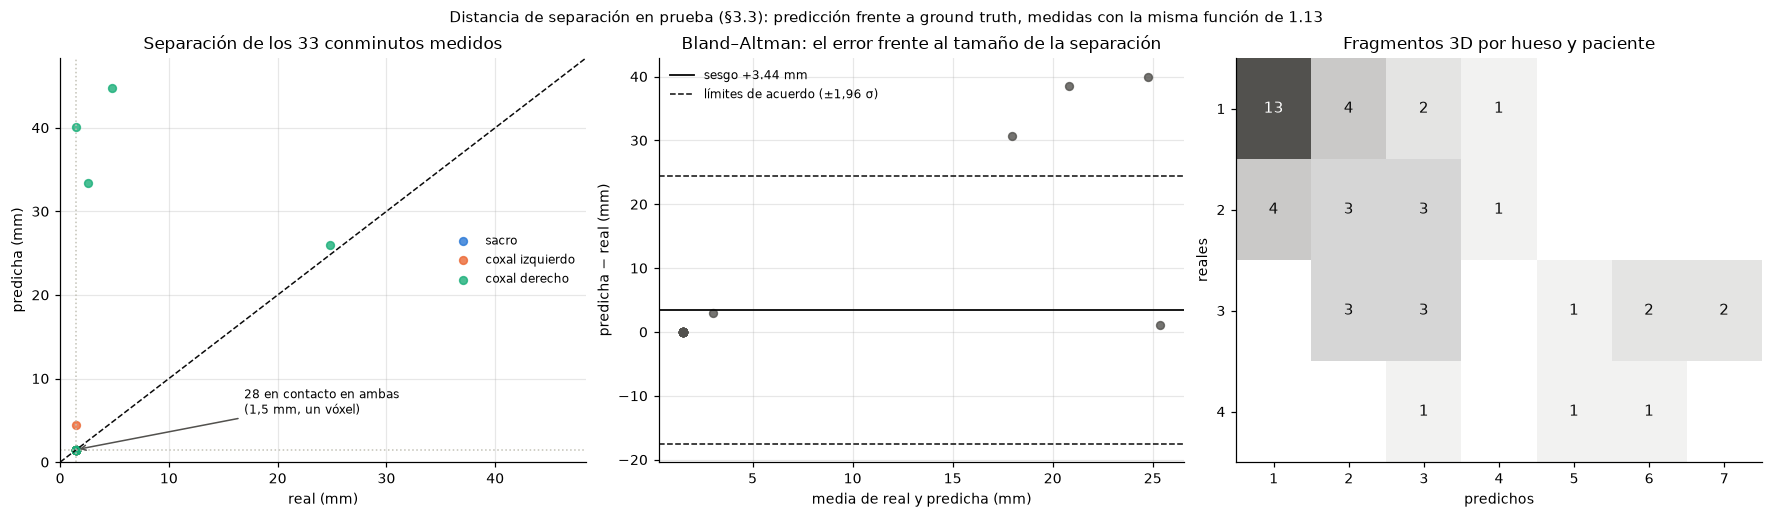

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.6), layout="constrained")
tope = max(medidos.sep_real_mm.max(), medidos.sep_pred_mm.max()) * 1.08
for k in HUESO:
    m = medidos.hueso == k
    axs[0].scatter(medidos.sep_real_mm[m], medidos.sep_pred_mm[m], s=26, color=COLOR[k], alpha=0.8, label=HUESO[k])
axs[0].plot([0, tope], [0, tope], color=TINTA, lw=1, ls="--")
en_contacto = int(((medidos.sep_real_mm <= bc.ISO_MM + 1e-6) & (medidos.sep_pred_mm <= bc.ISO_MM + 1e-6)).sum())
axs[0].annotate(f"{en_contacto} en contacto en ambas\n(1,5 mm, un vóxel)", (bc.ISO_MM, bc.ISO_MM), xytext=(0.35 * tope, 0.12 * tope),
                fontsize=8, arrowprops=dict(arrowstyle="->", color=NEUTRO, lw=1))
for f in (axs[0].axhline, axs[0].axvline):
    f(bc.ISO_MM, color=GRIS, lw=1, ls=":")
axs[0].set(title=f"Separación de los {len(medidos)} conminutos medidos", xlabel="real (mm)", ylabel="predicha (mm)",
           xlim=(0, tope), ylim=(0, tope))
axs[0].legend(fontsize=8, frameon=False)

media = (medidos.sep_pred_mm + medidos.sep_real_mm) / 2
axs[1].scatter(media, error, s=26, color=NEUTRO, alpha=0.8)
sesgo, de = error.mean(), error.std()
axs[1].axhline(sesgo, color=TINTA, lw=1.2, label=f"sesgo {sesgo:+.2f} mm")
for s_ in (-1.96, 1.96):
    axs[1].axhline(sesgo + s_ * de, color=TINTA, lw=1, ls="--", label="límites de acuerdo (±1,96 σ)" if s_ > 0 else None)
axs[1].set(title="Bland–Altman: el error frente al tamaño de la separación", xlabel="media de real y predicha (mm)",
           ylabel="predicha − real (mm)")
axs[1].legend(fontsize=8, frameon=False)

tabla_conteo = pd.crosstab(conteo_3d.reales, conteo_3d.predichos)
axs[2].imshow(tabla_conteo.to_numpy(), cmap=mcolors.LinearSegmentedColormap.from_list("", ["white", NEUTRO]), vmin=0,
              aspect="auto")
for (i, j), v in np.ndenumerate(tabla_conteo.to_numpy()):
    if v:
        axs[2].text(j, i, v, ha="center", va="center", fontsize=10, color="white" if v > tabla_conteo.to_numpy().max() / 2 else TINTA)
axs[2].set_xticks(range(tabla_conteo.shape[1]), tabla_conteo.columns)
axs[2].set_yticks(range(tabla_conteo.shape[0]), tabla_conteo.index)
axs[2].set(title="Fragmentos 3D por hueso y paciente", xlabel="predichos", ylabel="reales")
axs[2].grid(False)
fig.suptitle("Distancia de separación en prueba ( 3.3): predicción frente a ground truth, medidas con la misma función de 1.13",
             fontsize=10)
plt.show()

### La separación, sobre la imagen

El  3.4 exige que la separación se vea **junto a cada fragmento**, no solo en una tabla. Así la escribe el visualizador 2 de la app, aquí con el conminuto más desplazado del conjunto de prueba, a 24,8 mm:

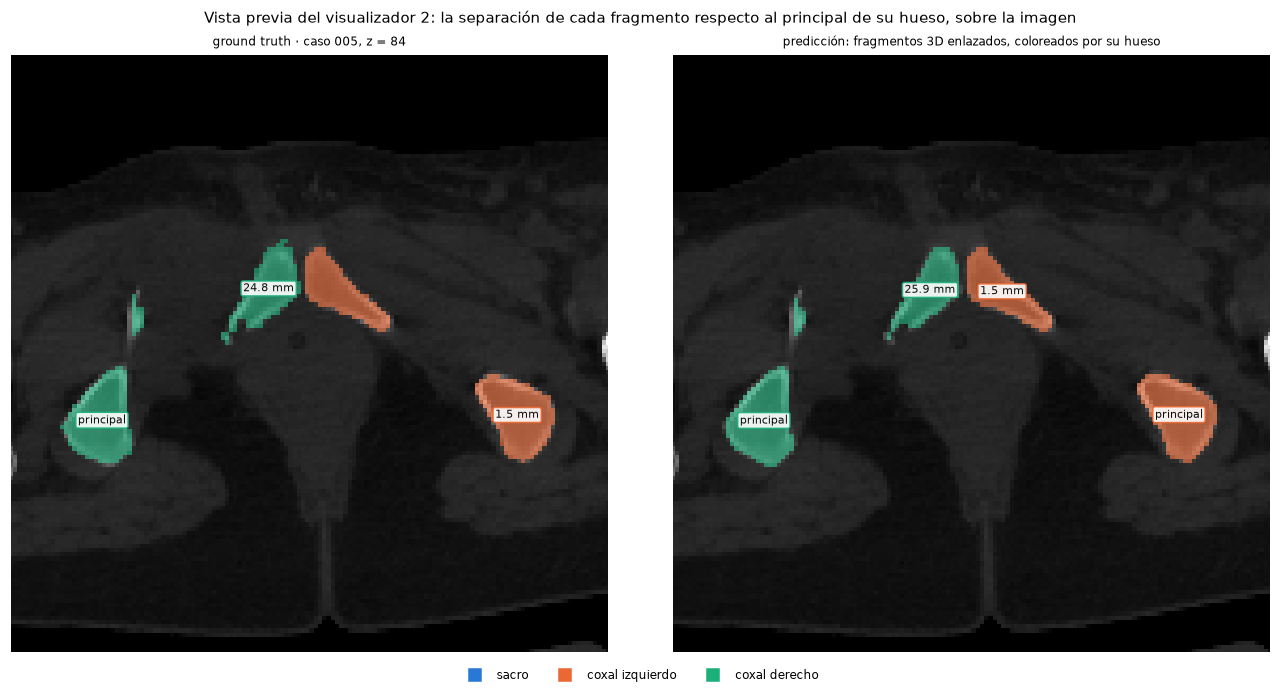

Fragmento 23 del caso 005: separación real 24.8 mm, predicha 25.9 mm


In [85]:
def rotular_separaciones(ax, lab2d, separaciones):
    """Escribe sobre cada fragmento del corte su separación en mm (o «principal»), en el centro de su mayor pieza."""
    for v in np.unique(lab2d[lab2d > 0]):
        piezas, n = ndimage.label(lab2d == v)
        mayor = np.argmax(np.bincount(piezas.ravel())[1:]) + 1
        cy, cx = ndimage.center_of_mass(piezas == mayor)
        texto = "principal" if separaciones.get(v) == 0.0 else f"{separaciones[v]:.1f} mm"
        ax.text(cx, cy, texto, fontsize=7, ha="center", va="center", color=TINTA, clip_on=True,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=COLOR[(v - 1) // 10 + 1], lw=1, alpha=0.9))


# El conminuto real más desplazado de los que el pipeline midió, en el corte donde su fragmento predicho es mayor
f_ = medidos.loc[medidos.sep_real_mm.idxmax()]
trozo = caso_test == f_.caso
pred3d, real3d = volumenes_pred[f_.caso], np.asarray(lab_cache[filas_test[trozo]])
z_ = int(np.argmax((pred3d == f_.pareja).sum(axis=(1, 2))))
sep_p = {f["etiqueta"]: f["separacion_mm"] for f in fragmentos_del_caso(pred3d, f_.caso)}
sep_r = dict(zip(frag.etiqueta[frag.case_id == f_.caso], frag.separacion_mm[frag.case_id == f_.caso]))
hu = np.asarray(hu_cache[filas_test[trozo][z_]])
fig, axs = plt.subplots(1, 2, figsize=(12, 6.2), layout="constrained")
mostrar_corte(axs[0], hu, real3d[z_], titulo=f"ground truth · caso {f_.caso}, z = {z_test[trozo][z_]}")
rotular_separaciones(axs[0], real3d[z_], sep_r)
mostrar_corte(axs[1], hu, pred3d[z_], titulo="predicción: fragmentos 3D enlazados, coloreados por su hueso")
rotular_separaciones(axs[1], pred3d[z_], sep_p)
for ax in axs:
    encuadrar(ax, cajas_por_region(real3d[z_]).values(), margen=12)
leyenda_huesos(fig, loc="outside lower center", ncol=3, frameon=False)
fig.suptitle("Vista previa del visualizador 2: la separación de cada fragmento respecto al principal de su hueso, sobre la imagen",
             fontsize=10)
plt.show()
print(f"Fragmento {f_.etiqueta} del caso {f_.caso}: separación real {f_.sep_real_mm:.1f} mm, predicha {f_.sep_pred_mm:.1f} mm")

La predicción lo mide casi igual que el ground truth: 25,9 mm frente a 24,8. Con una distancia **mínima** basta un vóxel suelto para que la medida diga «pegado», y por eso importa D7: cada pieza conexa cuenta por separado. Al lado, el coxal izquierdo: su fragmento 12 tiene en este corte dos piezas que se unen en otros. El modelo mide la pieza del pubis a 1,5 mm, la separación real, pero la otra pieza se la queda el fragmento principal.

## 4.7 · SAM como referencia *zero-shot*

El  4.2 fija el papel de SAM (Kirillov et al., 2023): **solo referencia de comparación**, sobre el conjunto de prueba y con el *prompt* de **la caja que predijo nuestra detección**. No forma parte del pipeline ni genera etiquetas. La pregunta es qué hace un modelo generalista, entrenado con imágenes naturales y sin haber visto una tomografía, frente a uno pequeño entrenado para la tarea.

La comparación es justa por construcción: **la misma caja, la misma región y la misma referencia**. Se mide en dos niveles, porque SAM devuelve una máscara por caja y nuestras cajas son por región:

- **Silueta**: ¿recupera el contorno del hueso? Cada región, con la máscara de SAM frente a la del modelo propio.
- **Fragmento**: ¿separa los pedazos? La métrica de 2.4; SAM, por construcción, encuentra como mucho uno por hueso.

Se usa ViT-B, el SAM del material del curso (sesión S2 de segmentación), con sus pesos en `checkpoints/`. SAM recibe un solo corte, el central, en la ventana de hueso: no sabe nada de pilas. Tarda unos 160 ms por corte, así que la comparación se hace sobre una muestra fija de 40 cortes por paciente de prueba, 600 en total, los mismos para los dos modelos.

In [86]:
from segment_anything import SamPredictor, sam_model_registry

RUTA_SAM = CHECKPOINTS / "sam_vit_b_01ec64.pth"     # ViT-B, el del material del curso (S2 de segmentación)
sam = sam_model_registry["vit_b"](checkpoint=str(RUTA_SAM)).to(DISPOSITIVO).eval()
predictor_sam = SamPredictor(sam)


def imagen_sam(hu: np.ndarray) -> np.ndarray:
    """Un corte para SAM: la ventana de hueso en gris, repetida en los tres canales RGB, en uint8."""
    gris = (np.clip((hu - VENTANAS[0][0]) / (VENTANAS[0][1] - VENTANAS[0][0]), 0, 1) * 255).astype(np.uint8)
    return np.repeat(gris[..., None], 3, axis=-1)


# Una muestra fija de 40 cortes por paciente de prueba, entre los que tienen alguna caja: SAM tarda unos 160 ms por
# corte, y así la comparación cabe en minuto y medio. Recibe las mismas cajas que el pipeline: la mejor de cada región
rng = np.random.default_rng(0)
con_caja = np.array([bool(cajas_del_corte(salida_test, i)) for i in range(len(filas_test))])
muestra_sam = np.sort(np.concatenate([rng.choice(np.nonzero((caso_test == c) & con_caja)[0], 40, replace=False)
                                      for c in splits["test"]]))
regiones_sam, etiquetas_sam, cortes_sam, t_sam = [], [], [], 0.0
for i in muestra_sam:
    fila, cajas = filas_test[i], cajas_del_corte(salida_test, i)
    real, propia = a_hueso(np.asarray(lab_cache[fila])), a_hueso(etiquetas_test[i])
    t0 = time.perf_counter()
    with torch.no_grad():
        predictor_sam.set_image(imagen_sam(np.asarray(hu_cache[fila])))
        mascaras = {k: predictor_sam.predict(box=np.array(c), multimask_output=False)[0][0] for k, c in cajas.items()}
    t_sam += time.perf_counter() - t0
    etiqueta_sam = np.zeros(real.shape, np.uint8)
    for k, m in sorted(mascaras.items(), key=lambda t: t[1].sum()):     # si dos se pisan, gana la región menor
        etiqueta_sam[m & (etiqueta_sam == 0)] = 10 * (k - 1) + 1          # SAM: un único fragmento por región
    for k in cajas:
        if (real == k).any():
            d_sam, i_sam = (2 * (mascaras[k] & (real == k)).sum() / (mascaras[k].sum() + (real == k).sum()),
                            (mascaras[k] & (real == k)).sum() / (mascaras[k] | (real == k)).sum())
            d_pro, i_pro = (2 * ((propia == k) & (real == k)).sum() / ((propia == k).sum() + (real == k).sum()),
                            ((propia == k) & (real == k)).sum() / ((propia == k) | (real == k)).sum())
            regiones_sam.append({"corte": i, "hueso": k, "Dice SAM": d_sam, "Dice propio": d_pro,
                                 "IoU SAM": i_sam, "IoU propio": i_pro})
    etiquetas_sam.append(etiqueta_sam)
    cortes_sam.append(i)
regiones_sam = pd.DataFrame(regiones_sam)

# Nivel de fragmento: SAM devuelve una máscara por caja, así que como mucho encuentra un fragmento por hueso
frag_sam = [emparejar(e, np.asarray(lab_cache[filas_test[i]])) for e, i in zip(etiquetas_sam, cortes_sam)]
fragmentos_sam = pd.DataFrame({"SAM": resumen_fragmentos(frag_sam),
                               "modelo propio": resumen_fragmentos([frag_test[i] for i in cortes_sam])}).T
colapsos = {q: (regiones_sam[f"Dice {q}"] < 0.5).mean() for q in ("SAM", "propio")}
print(f"SAM ViT-B en {len(cortes_sam):,} cortes de prueba (40 por paciente): {1000 * t_sam / len(cortes_sam):.0f} ms por corte "
      f"(codificar la imagen y una máscara por caja)")
print(f"\nNivel de silueta — {len(regiones_sam):,} regiones, cada una con su caja como prompt:")
print(f"  Dice  SAM {regiones_sam['Dice SAM'].mean():.3f} (mediana {regiones_sam['Dice SAM'].median():.3f}) · "
      f"propio {regiones_sam['Dice propio'].mean():.3f} (mediana {regiones_sam['Dice propio'].median():.3f})")
print(f"  IoU   SAM {regiones_sam['IoU SAM'].mean():.3f} · propio {regiones_sam['IoU propio'].mean():.3f}")
print(f"  regiones con Dice < 0,5: SAM {colapsos['SAM']:.1%} · propio {colapsos['propio']:.1%}")
print("\nNivel de fragmento, con la métrica de 2.4 sobre los mismos cortes:")
fragmentos_sam.drop(columns=["astillas"]).round(4).astype({"fragmentos reales": int, "no encontrados": int, "falsos positivos": int})

SAM ViT-B en 600 cortes de prueba (40 por paciente): 151 ms por corte (codificar la imagen y una máscara por caja)

Nivel de silueta — 1,538 regiones, cada una con su caja como prompt:
  Dice  SAM 0.865 (mediana 0.911) · propio 0.946 (mediana 0.969)
  IoU   SAM 0.783 · propio 0.908
  regiones con Dice < 0,5: SAM 3.0% · propio 1.2%

Nivel de fragmento, con la métrica de 2.4 sobre los mismos cortes:


,Dice,IoU,Dice de los encontrados,fragmentos reales,no encontrados,falsos positivos,F1 de reconocimiento,Dice sin regla ignore
SAM,0.6577,0.5838,0.8416,1922,420,17,0.8730,0.6322
modelo propio,0.8467,0.7962,0.9183,1922,150,79,0.9393,0.8159


**Silueta.** SAM compite: Dice medio de 0,865 y mediana de 0,911, frente a 0,946 y 0,969 del modelo propio. El borde del hueso contra el tejido blando es un contraste fuerte, justo lo que sabe seguir. Pero se equivoca más a menudo: el 3,0 % de sus regiones queda por debajo de 0,5, frente al 1,2 %.

**Fragmento.** Aquí se separan de verdad: 0,658 frente a 0,847. SAM deja sin encontrar 420 de los 1.922 fragmentos, frente a 150, porque con una caja por región solo puede devolver un fragmento por hueso: es su techo estructural, no un fallo de ajuste. Por la misma razón inventa tan pocos (17 frente a 79), y no es una virtud: no puede proponer más. Y tarda unos 160 ms por corte con el más pequeño de sus tres modelos.

Es la evidencia que pide el  4.2: un generalista fuera de dominio dibuja contornos razonables, pero no sabe nada de fragmentos; un modelo de 12 M de parámetros entrenado con diez mil cortes de pelvis le gana en los dos niveles.


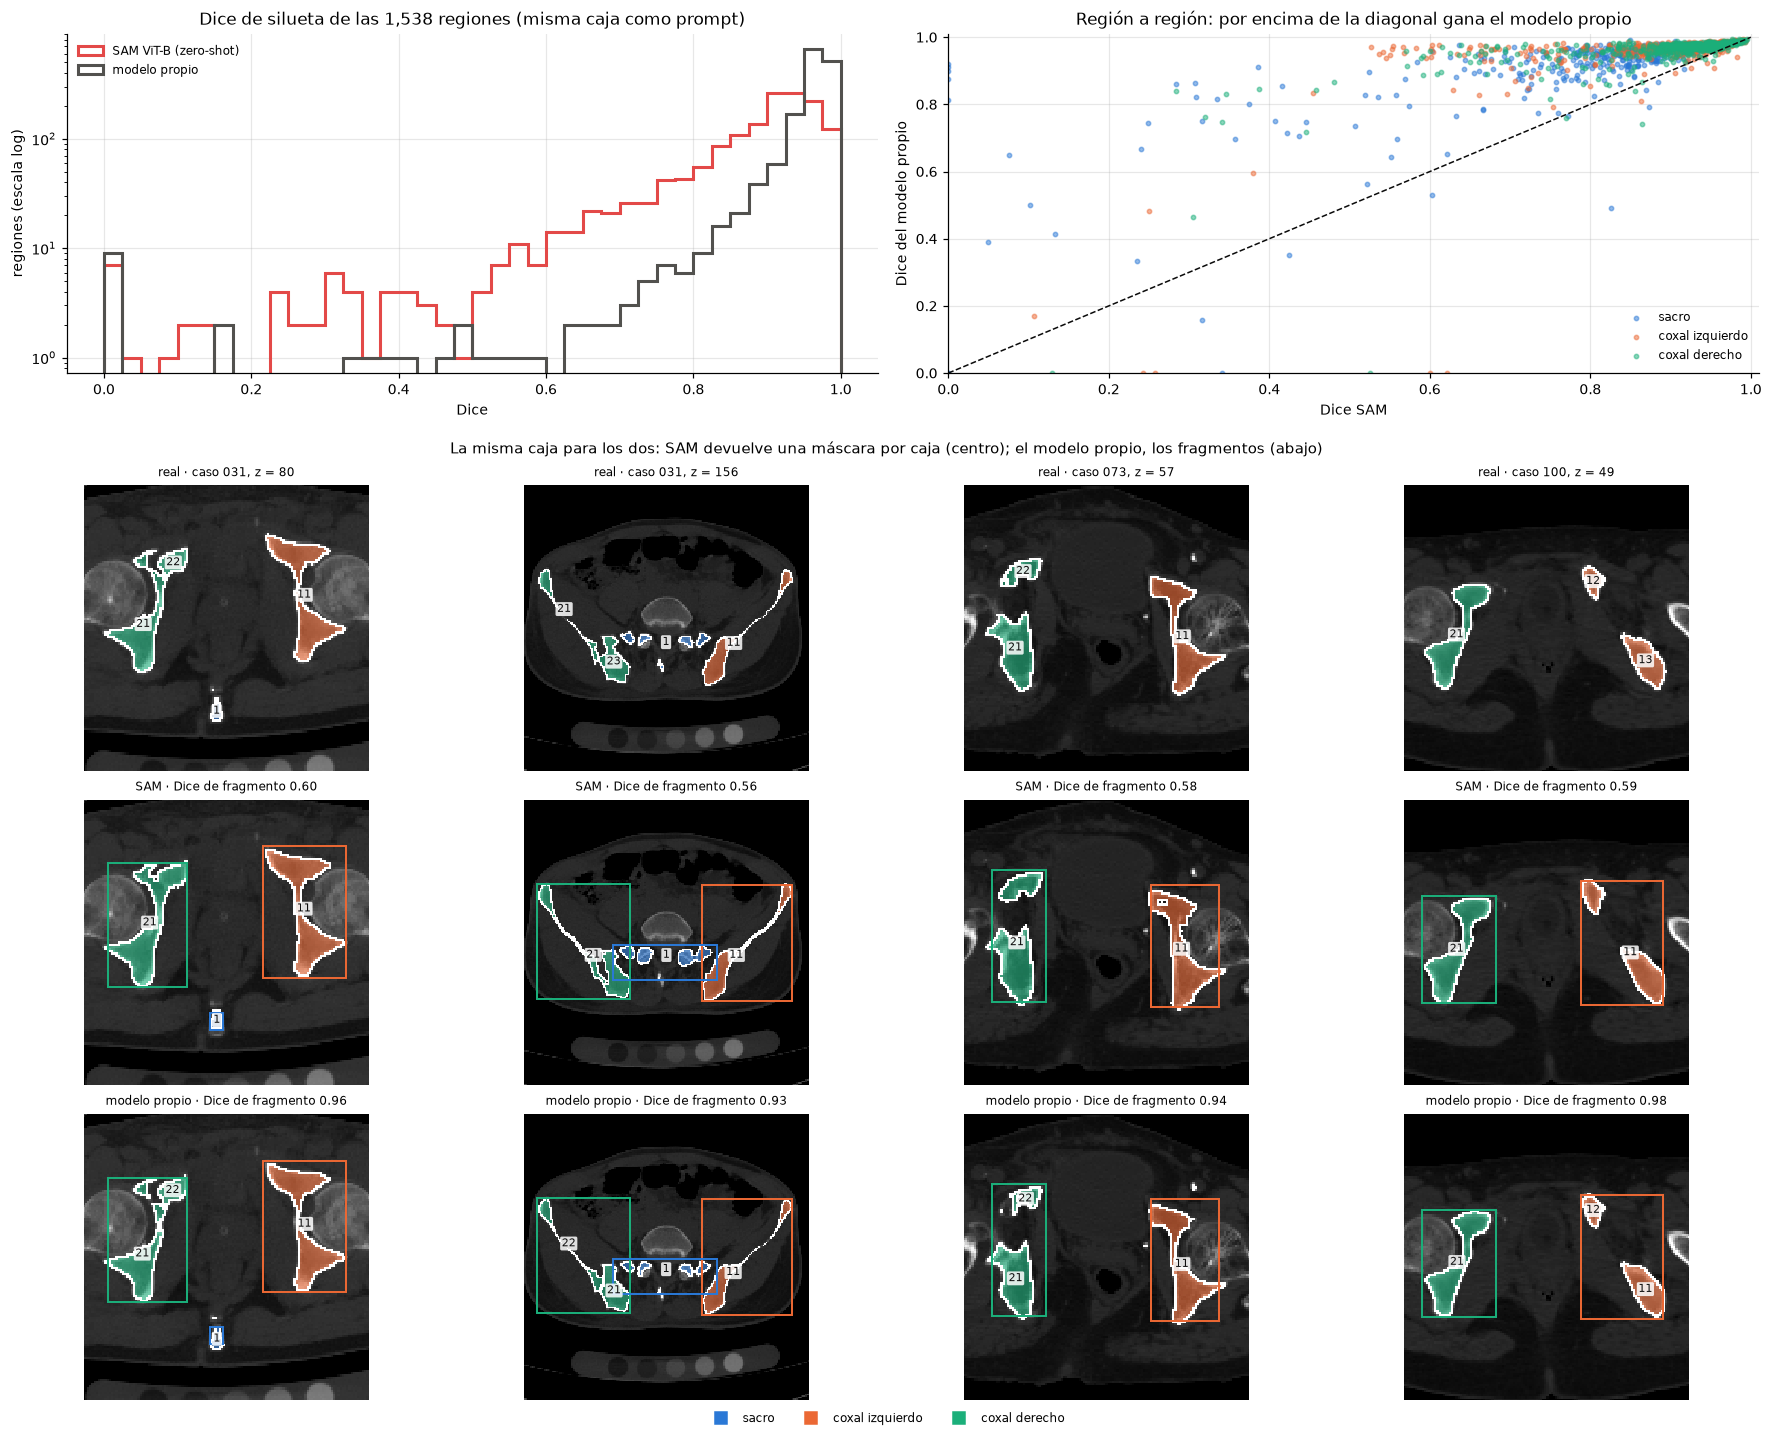

In [87]:
fig = plt.figure(figsize=(16, 13), layout="constrained")
arriba, abajo = fig.subfigures(2, 1, height_ratios=(1, 2.4))
ax1, ax2 = arriba.subplots(1, 2)
bins = np.linspace(0, 1, 41)
ax1.hist(regiones_sam["Dice SAM"], bins=bins, histtype="step", lw=2, color="#e34948", label="SAM ViT-B (zero-shot)")
ax1.hist(regiones_sam["Dice propio"], bins=bins, histtype="step", lw=2, color=NEUTRO, label="modelo propio")
ax1.set_yscale("log")
ax1.set(title=f"Dice de silueta de las {len(regiones_sam):,} regiones (misma caja como prompt)", xlabel="Dice",
        ylabel="regiones (escala log)")
ax1.legend(fontsize=8, frameon=False)
for k in HUESO:
    m = regiones_sam.hueso == k
    ax2.scatter(regiones_sam["Dice SAM"][m], regiones_sam["Dice propio"][m], s=8, alpha=0.5, color=COLOR[k], label=HUESO[k])
ax2.plot([0, 1], [0, 1], color=TINTA, lw=1, ls="--")
ax2.set(title="Región a región: por encima de la diagonal gana el modelo propio", xlabel="Dice SAM",
        ylabel="Dice del modelo propio", xlim=(0, 1.01), ylim=(0, 1.01))
ax2.legend(fontsize=8, frameon=False, loc="lower right")

# Cuatro cortes de la muestra con algún hueso fracturado, al azar
rng = np.random.default_rng(1)
fracturados_sam = [j for j, i in enumerate(cortes_sam) if fracturado_test[i]]
axs = abajo.subplots(3, 4)
for col, j in enumerate(np.sort(rng.choice(fracturados_sam, 4, replace=False))):
    i = cortes_sam[j]
    hu, lab = np.asarray(hu_cache[filas_test[i]]), np.asarray(lab_cache[filas_test[i]])
    d_sam = np.mean([f[5] for f in frag_sam[j][0] if not f[2]])
    d_pro = dice_del_corte(i)
    mostrar_corte(axs[0, col], hu, lab, fragmentos=True, titulo=f"real · caso {caso_test[i]}, z = {z_test[i]}")
    mostrar_corte(axs[1, col], hu, etiquetas_sam[j], fragmentos=True, titulo=f"SAM · Dice de fragmento {d_sam:.2f}")
    mostrar_pipeline(axs[2, col], i, titulo=f"modelo propio · Dice de fragmento {d_pro:.2f}")
    for k, (x0, y0, x1, y1) in cajas_del_corte(salida_test, i).items():
        axs[1, col].add_patch(Rectangle((x0 - 0.5, y0 - 0.5), x1 - x0, y1 - y0, fill=False, ec=COLOR[k], lw=1.3))
    for ax in axs[:, col]:
        encuadrar_corte(ax, cajas_test[i].values(), margen=10)
leyenda_huesos(abajo, loc="outside lower center", ncol=3, frameon=False)
abajo.suptitle("La misma caja para los dos: SAM devuelve una máscara por caja (centro); el modelo propio, los fragmentos (abajo)",
               fontsize=10)
plt.show()

La distribución muestra cómo falla SAM: casi todas sus regiones están, como las del modelo propio, entre 0,8 y 1, pero con una cola larga hasta 0. A la derecha, casi todos los puntos quedan por encima de la diagonal. Abajo, el caso 100 resume la diferencia: SAM devuelve el coxal izquierdo como una sola máscara (Dice de fragmento 0,59), y el modelo propio lo separa en sus dos fragmentos (0,98).

## 4.8 · ¿Sirve el CBAM? Usar, depender, servir; y la ablación

El enunciado pide atención CBAM ( 4.1) y una ablación con y sin CBAM y con y sin transfer learning ( 7). La pregunta de fondo **¿le sirve de algo el CBAM al modelo?** son en realidad tres preguntas distintas:

- ¿La red **usa** la atención?
- ¿El modelo **depende** de ella?
- ¿Le **sirve**?

Que el CBAM **afecte** al modelo y que le **sirva** son cosas distintas. A una red ya entrenada se le puede quitar casi cualquier pieza y empeorará, porque las capas siguientes se adaptaron a ella; eso no demuestra que una red entrenada desde el principio sin esa pieza hubiera salido peor. Solo la tercera prueba responde a lo segundo.

### ¿La red usa la atención? Las compuertas γ

Las compuertas empiezan en 0, es decir, con el CBAM apagado. Lo que valen al final del entrenamiento es lo que la red decidió hacer con él:

In [88]:
BLOQUES = {"cbam1": "tras la etapa 1 · 64 canales · 64×64", "cbam2": "tras la etapa 2 · 128 canales · 32×32",
           "cbam3": "tras la etapa 3 · 256 canales · 16×16", "cbam4": "tras la etapa 4 · 512 canales · 8×8"}
tabla_gammas = pd.DataFrame({"γ canal": {b: g[0] for b, g in registro3.gammas[mejor_epoca3].items()},
                             "γ espacial": {b: g[1] for b, g in registro3.gammas[mejor_epoca3].items()}})
tabla_gammas.index = [f"{b} · {BLOQUES[b]}" for b in tabla_gammas.index]
tabla_gammas.round(3)

,γ canal,γ espacial
cbam1 · tras la etapa 1 · 64 canales · 64×64,-0.098,-0.284
cbam2 · tras la etapa 2 · 128 canales · 32×32,-0.109,-0.164
cbam3 · tras la etapa 3 · 256 canales · 16×16,-0.312,-0.435
cbam4 · tras la etapa 4 · 512 canales · 8×8,0.325,0.426


Una γ lejos de 0 dice que la red abrió la compuerta, pero no cuánto cambia de verdad la señal: si la atención $M$ fuera casi constante, el bloque solo multiplicaría todo por un mismo número, y la BatchNorm de la capa siguiente lo desharía. Lo que importa es **cuánto varía la compuerta efectiva** $g = 1 + \gamma\,(M - 1)$ entre canales y entre posiciones. Se mide con un lote de 64 cortes de validación y se compara con la atención $M$ que calcula el propio bloque, que es lo que aplicaría un CBAM sin compuerta (γ = 1):

In [89]:
from contextlib import contextmanager


@torch.no_grad()
def compuertas_efectivas(modelo, imagen) -> dict:
    # Lo que cada CBAM aplica de verdad a un lote —g = 1 + γ·(M − 1)— y la atención M que calcula:
    # {"cbam1": (g de canal (B, C), g espacial (B, H, W), M de canal (B, C), M espacial (B, H, W))}
    capturas, ganchos = {}, []
    for nombre, m in modelo.named_modules():
        if isinstance(m, CBAM):
            def gancho(mod, args, _, b=nombre.split(".")[-1]):
                x = args[0].float()
                mc = mod.atencion_canal(x)
                gc = 1 + mod.gamma_canal * (mc - 1)
                ms = mod.atencion_espacial(x * gc)
                gs = 1 + mod.gamma_espacial * (ms - 1)
                capturas[b] = tuple(t.float().cpu() for t in (gc[:, :, 0, 0], gs[:, 0], mc[:, :, 0, 0], ms[:, 0]))
            ganchos.append(m.register_forward_hook(gancho))
    try:
        modelo.eval()
        with precision_mixta():
            modelo(imagen)
    finally:
        for g in ganchos:
            g.remove()
    return capturas


def resumen_compuertas(capturas, cuales=(0, 1)) -> pd.DataFrame:
    # Cuánto modula cada compuerta: su rango y su variación relativa (σ/μ), que es lo que una BatchNorm no puede deshacer
    filas = {}
    for b, c in capturas.items():
        gc, gs = c[cuales[0]], c[cuales[1]].flatten(1)
        filas[b] = {"canal: p5–p95": f"{gc.quantile(0.05):.2f}–{gc.quantile(0.95):.2f}",
                    "canal: σ/μ entre canales": float((gc.std(1) / gc.mean(1)).mean()),
                    "canal: σ entre cortes": float(gc.std(0).mean()),
                    "espacial: p5–p95": f"{torch.quantile(gs[:, ::7], 0.05):.2f}–{torch.quantile(gs[:, ::7], 0.95):.2f}",
                    "espacial: σ/μ dentro del corte": float((gs.std(1) / gs.mean(1)).mean())}
    return pd.DataFrame(filas).T


con_hueso_val = filas_val[indice.has_bone.to_numpy()[filas_val] == 1]
muestra_g = np.sort(np.random.default_rng(0).choice(con_hueso_val, 64, replace=False))
imagen_g = preparar_lote(muestra_g)["imagen"]                                  # las pilas 2.5D de los 64 cortes
capt_final = compuertas_efectivas(modelo3, imagen_g)
pd.concat({"compuerta efectiva g = 1 + γ·(M − 1): lo que se aplica": resumen_compuertas(capt_final),
           "atención M que calcula el bloque: lo que aplicaría γ = 1": resumen_compuertas(capt_final, (2, 3))}).round(3)

canal: p5–p95  \
compuerta efectiva g = 1 + γ·(M − 1): lo que se... cbam1     1.00–1.10   
                                                   cbam2     1.00–1.11   
                                                   cbam3     1.00–1.31   
                                                   cbam4     0.67–1.00   
atención M que calcula el bloque: lo que aplica... cbam1     0.00–1.00   
                                                   cbam2     0.00–1.00   
                                                   cbam3     0.00–1.00   
                                                   cbam4     0.00–1.00   

                                                         canal: σ/μ entre canales  \
compuerta efectiva g = 1 + γ·(M − 1): lo que se... cbam1                 0.044491   
                                                   cbam2                 0.043411   
                                                   cbam3                 0.100412   
                                                   cbam4                 0.190242   
atención M que calcula el bloque: lo que aplica... cbam1                 1.202322   
                                                   cbam2                 0.885174   
                                                   cbam3                 1.076001   
                                                   cbam4                 1.532462   

                                                         canal: σ entre cortes  \
compuerta efectiva g = 1 + γ·(M − 1): lo que se... cbam1              0.001174   
                                                   cbam2              0.004102   
                                                   cbam3              0.016188   
                                                   cbam4              0.004699   
atención M que calcula el bloque: lo que aplica... cbam1              0.011921   
                                                   cbam2              0.037635   
                                                   cbam3              0.051733   
                                                   cbam4              0.014463   

                                                         espacial: p5–p95  \
compuerta efectiva g = 1 + γ·(M − 1): lo que se... cbam1        1.28–1.28   
                                                   cbam2        1.16–1.16   
                                                   cbam3        1.43–1.44   
                                                   cbam4        0.57–0.58   
atención M que calcula el bloque: lo que aplica... cbam1        0.00–0.00   
                                                   cbam2        0.00–0.01   
                                                   cbam3        0.00–0.01   
                                                   cbam4        0.00–0.00   

                                                         espacial: σ/μ dentro del corte  
compuerta efectiva g = 1 + γ·(M − 1): lo que se... cbam1                       0.000636  
                                                   cbam2                        0.00063  
                                                   cbam3                       0.002389  
                                                   cbam4                       0.000774  
atención M que calcula el bloque: lo que aplica... cbam1                       6.652977  
                                                   cbam2                       4.549011  
                                                   cbam3                       3.607615  
                                                   cbam4                       4.173301

Y dónde actúa la atención espacial: la compuerta efectiva de cada CBAM sobre dos cortes de validación, ampliada a 256×256, y debajo la atención M que la produce. En azul, lo que el bloque atenúa; en naranja, lo que refuerza (respecto al resto del mapa, porque es la variación lo que cuenta):


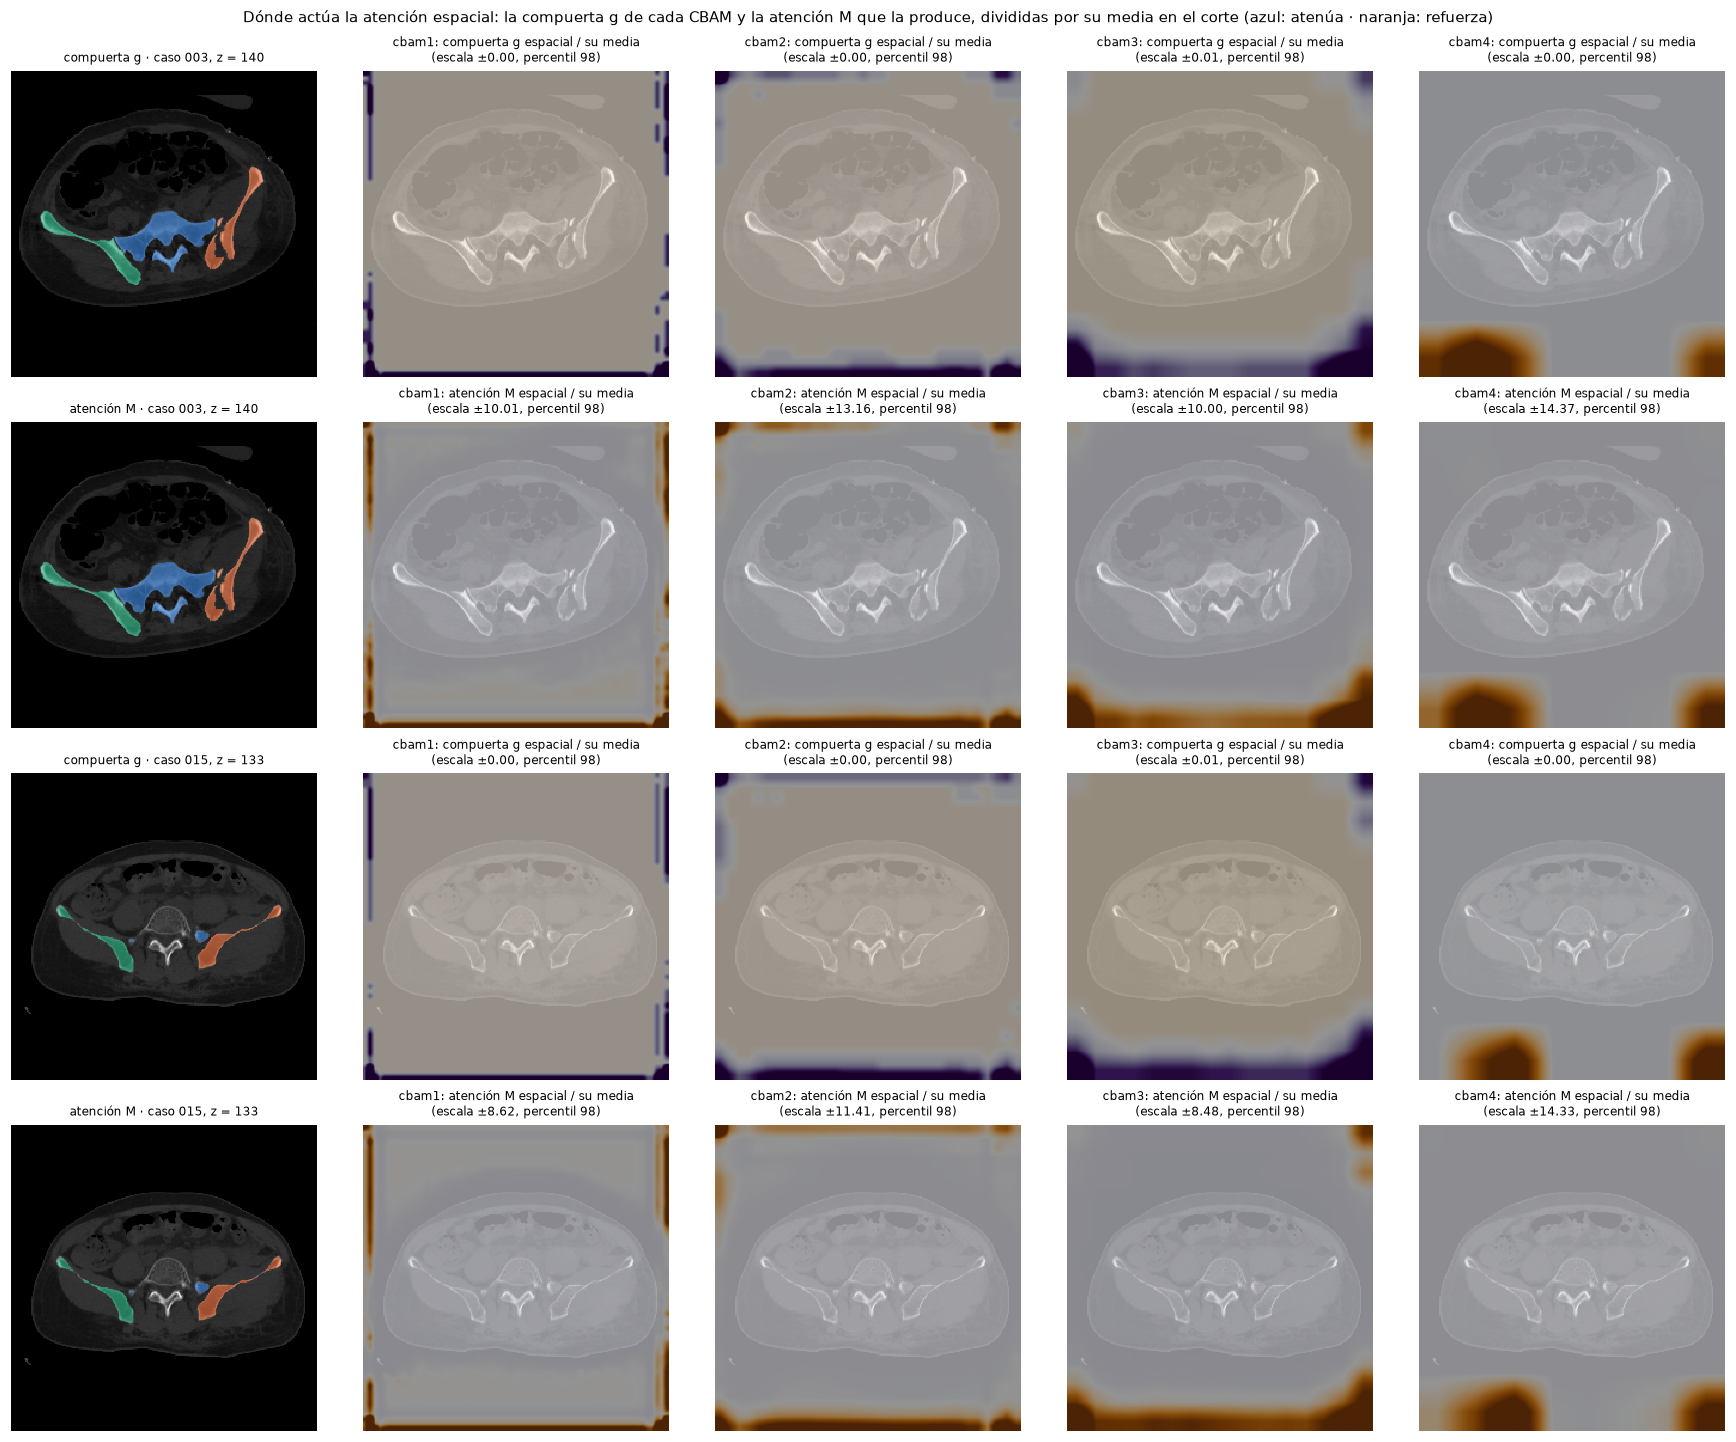

In [90]:
vistos, ejemplos_g = set(), []                 # dos cortes con las tres regiones y algún hueso roto, de pacientes distintos
for i, f in enumerate(muestra_g):
    if indice.n_regions.iat[f] == 3 and indice.n_frag_total.iat[f] >= 4 and indice.case_id.iat[f] not in vistos:
        ejemplos_g.append(i)
        vistos.add(indice.case_id.iat[f])
ejemplos_g = (ejemplos_g + [i for i in range(len(muestra_g)) if i not in ejemplos_g])[:2]
fig, axs = plt.subplots(2 * len(ejemplos_g), 5, figsize=(16, 13), layout="constrained")
for fila_fig, (cual, rotulo) in enumerate(((1, "compuerta g"), (3, "atención M"))):
    for e, i in enumerate(ejemplos_g):
        r = 2 * e + fila_fig
        hu = np.asarray(hu_cache[muestra_g[i]])
        mostrar_corte(axs[r, 0], hu, np.asarray(lab_cache[muestra_g[i]]), titulo=f"{rotulo} · caso "
                      f"{indice.case_id.iat[muestra_g[i]]}, z = {indice.z.iat[muestra_g[i]]}")
        for j, b in enumerate(BLOQUES, 1):
            gs = F.interpolate(capt_final[b][cual][i][None, None], size=hu.shape, mode="bilinear", align_corners=False)[0, 0]
            relativa = (gs / gs.mean()).numpy()
            d = max(float(np.percentile(np.abs(relativa - 1), 98)), 1e-3)      # escala robusta: un borde no la acapara
            mostrar_corte(axs[r, j], hu, titulo=f"{b}: {rotulo} espacial / su media\n(escala ±{d:.2f}, percentil 98)")
            axs[r, j].imshow(relativa, cmap="PuOr_r", vmin=1 - d, vmax=1 + d, alpha=0.6)
fig.suptitle("Dónde actúa la atención espacial: la compuerta g de cada CBAM y la atención M que la produce, divididas por su "
             "media en el corte (azul: atenúa · naranja: refuerza)", fontsize=10)
plt.show()

Tres lecturas:

- **La red abrió las compuertas, sobre todo en los bloques profundos**: γ = 0,33 (canal) y 0,43 (espacial) en el bloque 4; −0,31 y −0,44 en el 3; entre −0,28 y −0,10 en el 1 y el 2. Una γ negativa no apaga el bloque: invierte su efecto.
- **La atención espacial se apagó.** La M espacial que calcula cada bloque vale prácticamente 0 en toda la anatomía —el 95 % de sus valores está por debajo de 0,01— y solo se enciende en el borde del mapa (en la figura, los mapas de M son lisos salvo en el marco), un efecto del relleno de su convolución 7×7. Con M ≈ 0, la compuerta efectiva es 1 − γ, una constante en todo el corte: 1,28, 1,16, 1,44 y 0,57 en los cuatro bloques, con una variación dentro del corte de menos del 0,3 %. No decide dónde mirar: multiplica el mapa entero por un número.
- **La atención de canal sí calcula pesos distintos, y la compuerta los suaviza.** La M de canal es casi binaria (de 0 a 1 entre canales, σ/μ de 0,9 a 1,5); con γ entre −0,31 y 0,33, la compuerta efectiva solo varía entre un 4 % y un 19 % de un canal a otro, y casi nada de un corte a otro (σ ≤ 0,016): un reajuste fijo de la importancia de cada canal más que una atención que mire cada imagen.

La red **usa** el CBAM, porque sus compuertas no son cero, pero como una escala casi fija por canal y por bloque.

### ¿El modelo depende de ella? Apagar el CBAM en inferencia

La segunda prueba no entrena nada: toma el modelo final, pone a 0 las compuertas de uno o de todos los CBAM —el bloque pasa a devolver su entrada— y vuelve a medir en validación.

In [ ]:
@contextmanager
def compuertas(modelo, valores: dict):
    # Fija temporalmente las compuertas de algunos CBAM, {"cbam3": (γ canal, γ espacial)}, y las restaura al salir
    bloques = {n.split(".")[-1]: m for n, m in modelo.named_modules() if isinstance(m, CBAM)}
    antes = {b: (bloques[b].gamma_canal.item(), bloques[b].gamma_espacial.item()) for b in valores}
    try:
        with torch.no_grad():
            for b, (c, s) in valores.items():
                bloques[b].gamma_canal.fill_(c)
                bloques[b].gamma_espacial.fill_(s)
        yield modelo
    finally:
        with torch.no_grad():
            for b, (c, s) in antes.items():
                bloques[b].gamma_canal.fill_(c)
                bloques[b].gamma_espacial.fill_(s)


def evaluar_validacion(modelo) -> tuple[dict, list]:
    # Las siete métricas del  5 en validación (4.2) y el reconocimiento de fragmentos (2.4)
    salida, etiquetas = inferir_completo(modelo, filas_val)
    s5, frag_ = metricas_seccion5(salida, etiquetas, filas_val)
    r = resumen_fragmentos(frag_)
    return {**s5, "F1 de reconocimiento": r["F1 de reconocimiento"],
            "no encontrados": r["no encontrados"] / r["fragmentos reales"]}, frag_


APAGADO = (0.0, 0.0)
t0 = time.perf_counter()
apagar = {"modelo final, tal cual": evaluar_validacion(modelo3)[0]}
for b in BLOQUES:
    with compuertas(modelo3, {b: APAGADO}):
        apagar[f"sin {b}"] = evaluar_validacion(modelo3)[0]
with compuertas(modelo3, dict.fromkeys(BLOQUES, APAGADO)):
    apagar["sin ningún CBAM"] = evaluar_validacion(modelo3)[0]
apagar = pd.DataFrame(apagar).T
print(f"{len(apagar)} evaluaciones de los {len(filas_val):,} cortes de validación en {time.perf_counter() - t0:.0f} s")
apagar.round(4)

6 evaluaciones de los 2,364 cortes de validación en 196 s


,F1 macro,AUC macro,IoU promedio,"mAP@0,50","mAP@[0,50:0,95]",Dice de fragmento,IoU de fragmento,F1 de reconocimiento,no encontrados
"modelo final, tal cual",0.9915,0.9994,0.8833,0.9788,0.7655,0.8553,0.8089,0.9349,0.0768
sin cbam1,0.9867,0.9990,0.8682,0.9785,0.7334,0.8492,0.8021,0.9290,0.0830
sin cbam2,0.9916,0.9994,0.8792,0.9784,0.7578,0.8504,0.8042,0.9335,0.0827
sin cbam3,0.9886,0.9993,0.8518,0.9703,0.6996,0.8415,0.7902,0.9217,0.0812
sin cbam4,0.9907,0.9991,0.8423,0.9629,0.6786,0.8263,0.7765,0.9260,0.1014
sin ningún CBAM,0.9646,0.9916,0.6984,0.8600,0.4072,0.7691,0.7028,0.8828,0.1256


**Depende, y mucho, pero eso no demuestra que le sirva.** Apagar los cuatro CBAM del modelo final hunde la detección (IoU de 0,883 a 0,698; mAP@[0,50:0,95] de 0,766 a 0,407) y la segmentación (Dice de fragmento de 0,855 a 0,769). Uno a uno, pesan los profundos: sin el del bloque 4, el Dice baja a 0,826 y el mAP@[0,50:0,95] a 0,679; sin el del bloque 3, a 0,842 y 0,700. El primero también pesa algo —sin él, el IoU baja a 0,868 y el mAP@[0,50:0,95] a 0,733—, y el segundo apenas mueve nada (0,008 de mAP y 0,005 de Dice).

Que dependa tanto de unas compuertas casi constantes tiene una explicación sencilla. Al apagarlas cambia la escala de las activaciones, y las BatchNorm de las capas siguientes, que en inferencia usan las medias y varianzas aprendidas con el CBAM puesto, dejan de normalizar bien. Es el caso del que avisaba la entrada de esta sección: una red entrenada depende de cada pieza con la que se entrenó, sirva o no. Para saber si el CBAM le **sirve** hay que entrenar sin él.

### ¿Le sirve? La ablación

La única prueba que responde si una pieza mejora el modelo es entrenar otro sin ella y comparar: la ablación del  7, con y sin CBAM y con y sin transfer learning. Cada brazo repite exactamente el entrenamiento de 3.2 —30 épocas, mismos datos, misma pila de 5 cortes, misma selección de la época, misma decodificación— y cambia **una sola cosa** respecto al modelo final con la misma semilla, incluidos sus λ:

**Dos semillas en los brazos que importan.** El entrenamiento en GPU no es reproducible bit a bit, y con otra semilla cambian además la inicialización de las partes nuevas, el orden de los lotes y la augmentación. Si la diferencia entre dos brazos no supera la que hay entre dos entrenamientos idénticos con distinta semilla, no se puede atribuir a lo que cambia. Por eso el modelo final y el brazo sin CBAM tienen dos semillas, la 42 y la 7. El modelo de la semilla 7 recalibró sus λ con esa semilla (3.1), y el brazo sin CBAM de la semilla 7 usa esos mismos λ: cada brazo cambia una sola cosa respecto a su referencia. Además, la diferencia entre dos brazos se acompaña de un intervalo de confianza por *bootstrap* sobre los 15 pacientes de validación.

La comparación se hace en **validación**: la prueba ya se abrió una vez (4.5) y no se usa para decidir nada.

**Celda larga si falta algún brazo: un entrenamiento de una hora por brazo**, con el mismo `entrenar_completo()` de 3.2. Se guardan en `checkpoints/experimentos/` y, si el archivo ya existe y está completo, se carga en lugar de reentrenar.

In [ ]:
EXPERIMENTOS = CHECKPOINTS / "experimentos"
RUTA_S7 = EXPERIMENTOS / "modelo_final_semilla7.pth"
BRAZOS = {                     # nombre: (checkpoint, cómo entrenarlo si falta; "s42"/"s7" = los λ del modelo final con esa semilla)
    "modelo final · semilla 42": (RUTA_COMPLETO, None),
    "modelo final · semilla 7": (RUTA_S7, dict(semilla=7)),
    "sin CBAM · semilla 42": (EXPERIMENTOS / "sin_cbam_s42.pth", dict(cbam=False, semilla=42, calibracion="s42")),
    "sin CBAM · semilla 7": (EXPERIMENTOS / "sin_cbam_s7.pth", dict(cbam=False, semilla=7, calibracion="s7")),
    "sin ImageNet · semilla 42": (EXPERIMENTOS / "sin_imagenet_s42.pth", dict(imagenet=False, semilla=42, calibracion="s42")),
}
REENTRENAR_ABLACION = False
for nombre, (ruta, argumentos) in BRAZOS.items():
    incompleto = ruta.exists() and len(torch.load(ruta, map_location="cpu", weights_only=False)["historial"]) < EPOCAS3
    if argumentos is not None and (REENTRENAR_ABLACION or not ruta.exists() or incompleto):
        argumentos = dict(argumentos)
        if "calibracion" in argumentos:
            referencia = RUTA_COMPLETO if argumentos["calibracion"] == "s42" else RUTA_S7
            argumentos["calibracion"] = torch.load(referencia, map_location="cpu", weights_only=False)["calibracion"]
        print(f"\nEntrenando el brazo «{nombre}»")
        entrenar_completo(ruta, DESP, **argumentos)


def evaluar_brazo(ruta) -> dict:
    # Un brazo en validación: las métricas del  5 y del reconocimiento, el Dice por paciente para el bootstrap, y su registro
    modelo = cargar_modelo(ruta)
    metricas, frag_ = evaluar_validacion(modelo)
    g = torch.load(ruta, map_location="cpu", weights_only=False)
    mejor_f = max(g["historial"], key=lambda f: f["puntuacion"])
    del modelo
    torch.cuda.empty_cache()
    return {"métricas": metricas, "dice por paciente": dice_por_paciente(frag_, filas_val), "época guardada": mejor_f["epoca"],
            "minutos": g["minutos"], "config": g["config"], "lambdas": g["calibracion"]["lambdas"]}


t0 = time.perf_counter()
brazos = {nombre: evaluar_brazo(ruta) for nombre, (ruta, _) in BRAZOS.items()}
ablacion = pd.DataFrame({n: {**b["métricas"], "época guardada": b["época guardada"], "minutos de entrenamiento": b["minutos"]}
                         for n, b in brazos.items()}).T
assert brazos["sin CBAM · semilla 7"]["lambdas"] == brazos["modelo final · semilla 7"]["lambdas"]
assert brazos["sin CBAM · semilla 42"]["lambdas"] == brazos["modelo final · semilla 42"]["lambdas"]
print(f"{len(brazos)} brazos evaluados en los {len(filas_val):,} cortes de validación en {time.perf_counter() - t0:.0f} s; "
      f"cada brazo usa los λ de su referencia ✓")
ablacion.round(4).astype({"época guardada": int})

5 brazos evaluados en los 2,364 cortes de validación en 162 s; cada brazo usa los λ de su referencia ✓


,F1 macro,AUC macro,IoU promedio,"mAP@0,50","mAP@[0,50:0,95]",Dice de fragmento,IoU de fragmento,F1 de reconocimiento,no encontrados,época guardada,minutos de entrenamiento
modelo final · semilla 42,0.9915,0.9994,0.8833,0.9788,0.7655,0.8553,0.8089,0.9349,0.0768,27,63.6165
modelo final · semilla 7,0.9929,0.9996,0.8817,0.9778,0.7613,0.8589,0.8131,0.9375,0.0743,29,64.3791
sin CBAM · semilla 42,0.9927,0.9996,0.8798,0.9764,0.7510,0.8539,0.8072,0.9337,0.0773,30,69.3406
sin CBAM · semilla 7,0.9937,0.9996,0.8770,0.9750,0.7484,0.8594,0.8124,0.9376,0.0721,22,69.3518
sin ImageNet · semilla 42,0.9953,0.9996,0.8935,0.9789,0.7869,0.8553,0.8060,0.9323,0.0737,26,71.7363


Con CBAM − sin CBAM, media de las dos semillas, frente a la diferencia entre semillas del mismo brazo:
  IoU promedio           +0.0041   (entre semillas: hasta 0.0028)
  mAP@[0,50:0,95]        +0.0137   (entre semillas: hasta 0.0043)
  Dice de fragmento      +0.0004   (entre semillas: hasta 0.0055)
  IoU de fragmento       +0.0012   (entre semillas: hasta 0.0052)
  F1 de reconocimiento   +0.0006   (entre semillas: hasta 0.0039)


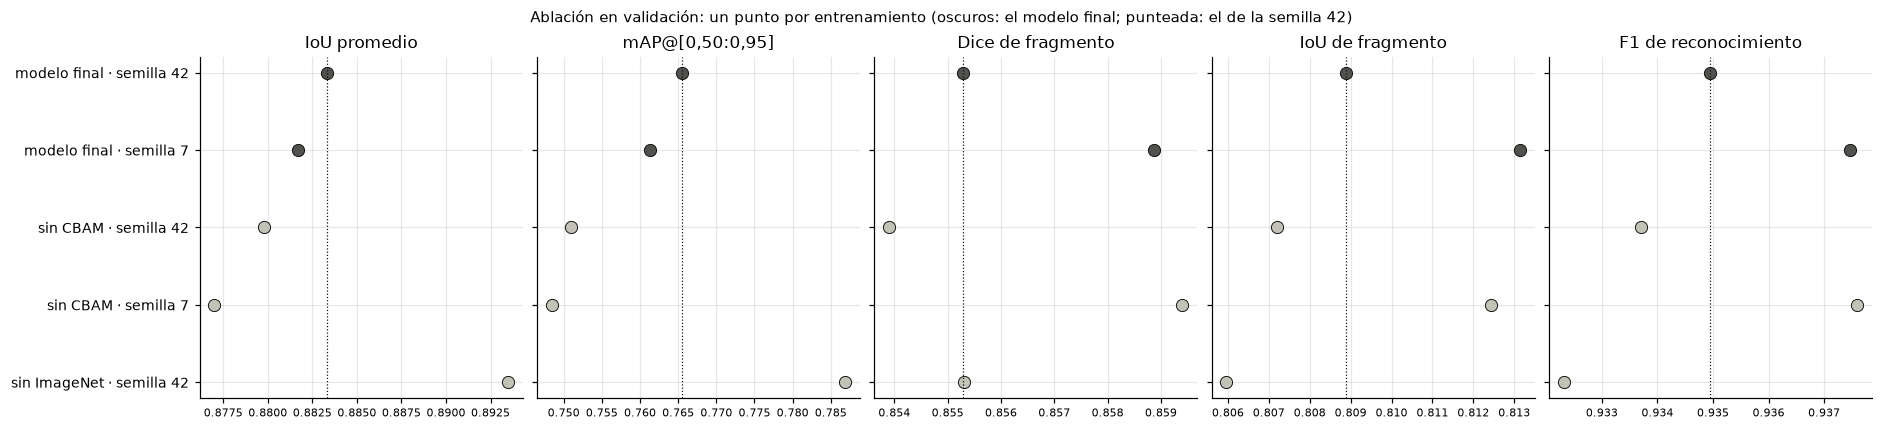

,IoU promedio,"mAP@[0,50:0,95]",Dice de fragmento,IoU de fragmento,F1 de reconocimiento,Dice por paciente: media e IC 95 %
"ruido: modelo final, semilla 42 − semilla 7",0.0016,0.0043,-0.0036,-0.0043,-0.0025,"-0.0032 [-0.0118, +0.0052]"
"ruido: sin CBAM, semilla 42 − semilla 7",0.0028,0.0025,-0.0055,-0.0052,-0.0039,"-0.0054 [-0.0106, +0.0002]"
CBAM: con − sin (semilla 42),0.0036,0.0146,0.0014,0.0017,0.0012,"+0.0018 [-0.0031, +0.0067]"
CBAM: con − sin (semilla 7),0.0047,0.0128,-0.0005,0.0007,-0.0001,"-0.0004 [-0.0082, +0.0069]"
transfer: con − sin ImageNet (semilla 42),-0.0102,-0.0213,-0.0000,0.0029,0.0026,"-0.0000 [-0.0101, +0.0104]"


In [93]:
METRICAS_ABL = ["IoU promedio", "mAP@[0,50:0,95]", "Dice de fragmento", "IoU de fragmento", "F1 de reconocimiento"]
COMPARACIONES = {
    "ruido: modelo final, semilla 42 − semilla 7": ("modelo final · semilla 42", "modelo final · semilla 7"),
    "ruido: sin CBAM, semilla 42 − semilla 7": ("sin CBAM · semilla 42", "sin CBAM · semilla 7"),
    "CBAM: con − sin (semilla 42)": ("modelo final · semilla 42", "sin CBAM · semilla 42"),
    "CBAM: con − sin (semilla 7)": ("modelo final · semilla 7", "sin CBAM · semilla 7"),
    "transfer: con − sin ImageNet (semilla 42)": ("modelo final · semilla 42", "sin ImageNet · semilla 42"),
}
diferencias = pd.DataFrame({c: {m: ablacion.loc[a, m] - ablacion.loc[b, m] for m in METRICAS_ABL}
                            for c, (a, b) in COMPARACIONES.items()}).T
diferencias["Dice por paciente: media e IC 95 %"] = [
    "{:+.4f} [{:+.4f}, {:+.4f}]".format(*ic_bootstrap(brazos[a]["dice por paciente"], brazos[b]["dice por paciente"]))
    for a, b in COMPARACIONES.values()]

con, sin = ["modelo final · semilla 42", "modelo final · semilla 7"], ["sin CBAM · semilla 42", "sin CBAM · semilla 7"]
media_con, media_sin = ablacion.loc[con, METRICAS_ABL].mean(), ablacion.loc[sin, METRICAS_ABL].mean()
ruido = (ablacion.loc[[con[0], sin[0]], METRICAS_ABL].to_numpy() - ablacion.loc[[con[1], sin[1]], METRICAS_ABL].to_numpy())
print("Con CBAM − sin CBAM, media de las dos semillas, frente a la diferencia entre semillas del mismo brazo:")
for j, m in enumerate(METRICAS_ABL):
    print(f"  {m:<22} {media_con[m] - media_sin[m]:+.4f}   (entre semillas: hasta {np.abs(ruido[:, j]).max():.4f})")

fig, axs = plt.subplots(1, 5, figsize=(17, 3.8), layout="constrained", sharey=True)
orden = list(BRAZOS)[::-1]
for ax, m in zip(axs, METRICAS_ABL):
    for y, n in enumerate(orden):
        ax.plot(ablacion.loc[n, m], y, "o", ms=8, color=NEUTRO if n.startswith("modelo final") else GRIS, mec=TINTA, mew=0.6)
    ax.axvline(ablacion.loc["modelo final · semilla 42", m], color=TINTA, lw=0.8, ls=":")
    ax.set(title=m, yticks=range(len(orden)), yticklabels=orden)
    ax.tick_params(axis="x", labelsize=7)
fig.suptitle("Ablación en validación: un punto por entrenamiento (oscuros: el modelo final; punteada: el de la semilla 42)", fontsize=10)
plt.show()
diferencias.round(4)

Las dos semillas del modelo final difieren en 0,0016 de IoU, 0,004 de mAP@[0,50:0,95] y 0,004 de Dice: esa es la vara de medir. Contra ella:

- **El CBAM sirve a la detección, y no a la segmentación.** Con las dos semillas, el modelo con CBAM ajusta mejor las cajas: +0,015 y +0,013 de mAP@[0,50:0,95], el triple de la diferencia entre semillas de un mismo brazo (como mucho 0,004), y +0,004 y +0,005 de IoU, por encima de ese ruido (0,003). En los fragmentos no se distingue nada: +0,001 y −0,001 de Dice, frente a una diferencia entre semillas de hasta 0,006, y un intervalo por paciente que cruza el 0 en las dos semillas. Encaja con lo que contaron las compuertas: una atención que actúa como una escala por canal reajusta los rasgos que usa la detección, pero no ayuda a encontrar los centros de los fragmentos, que es lo que limita la segmentación (4.4).
- **El transfer learning no ayudó** (una semilla). El tronco entrenado desde cero detecta mejor —IoU +0,010 y mAP@[0,50:0,95] +0,021, de tres a cinco veces el ruido— y segmenta igual (el mismo Dice; el IoU de fragmento y el F1 de reconocimiento, 0,003 por debajo, dentro del ruido). Con un matiz: el optimizador da a los pesos de ImageNet la décima parte del learning rate (3.1), y sin ImageNet no hay ninguno, así que todo el tronco aprende al lr completo. El brazo compara «ImageNet con lr reducido» con «desde cero con lr completo»: las fotografías naturales quedan lejos de una TC, y con diez mil cortes el tronco aprende bien desde cero.

**La respuesta a «¿sirve el CBAM?»**: la red lo **usa**, como una escala casi fija; el modelo **depende** de él, porque se entrenó con él; y le **sirve**, pero solo para ajustar las cajas (+0,014 de mAP@[0,50:0,95] de media con dos semillas), no para separar fragmentos. Se mantiene: lo pide el  4.1, cuesta el 0,4 % de los parámetros y mejora la detección. Del transfer learning queda una mejora probable para el futuro: entrenar el tronco desde cero, o con ImageNet al lr completo.

## 4.9 · Latencia por imagen en CPU y en GPU

El  4.3 pide que el pipeline de inferencia funcione en GPU y en CPU, priorizando la GPU, y que se mida la latencia por imagen en los dos escenarios. Se mide en dos tramos sobre 50 cortes de prueba con hueso, uno a uno (lote de 1):

- **La red**: de la pila ya ventaneada a los mapas de las tres cabezas.
- **El pipeline completo de un corte** (`pipeline_pila`): desde las unidades Hounsfield de su pila hasta los fragmentos etiquetados y coloreados por su hueso, con el ventaneo, la red, la decodificación de las cajas con su NMS, la compuerta y las instancias.

En GPU, con precisión mixta bf16 (como en todo el notebook) y `torch.cuda.synchronize()` antes de parar el reloj: la GPU trabaja de forma asíncrona y, sin sincronizar, se mediría cuándo se encargó el trabajo y no cuándo terminó. En CPU, en fp32, con los hilos que PyTorch usa por defecto. Las primeras pasadas se descartan como calentamiento. El enlace 3D y la separación no son por imagen sino por paciente: se miden aparte.

La celda define también `inferir_volumen()`, el pipeline sobre un volumen sin etiquetas, el que reproduce la app (capítulo 5): forma la pila de cada corte **dentro del volumen**, con el mismo recorte en los bordes que `filas_vecinas()`, y la pasa por el modelo en lotes de 16. Y comprueba los dos caminos frente a la inferencia de prueba de 4.5 con `concordancia()`, la fracción de vóxeles de hueso con la misma etiqueta. No se exige igualdad exacta porque en bf16 la GPU no da bit a bit el mismo resultado para un corte si va en un lote con otros cortes distintos (reparte las sumas de otra manera), y alguna probabilidad cercana al umbral puede cambiar de lado.


#### D25 · Inferencia reproducible, y caminos comparados por concordancia

 Para evaluar, `cudnn.deterministic`: las cifras del texto se reproducen. Dos caminos de inferencia distintos (otro tamaño de lote, otro orden) se comparan por la fracción de vóxeles de hueso con la misma etiqueta (≥ 99 %), no por igualdad exacta.

In [ ]:
import platform


@torch.no_grad()
def inferir_volumen(modelo, hu, tam: int = LOTE) -> tuple[np.ndarray, list]:
    # El pipeline del  6 sobre los cortes de un volumen (Z, 256, 256) en HU, sin mirar ninguna etiqueta: la pila 2.5D de
    # cada corte dentro del volumen (con el mismo recorte en los bordes que filas_vecinas), su ventaneo (como preparar_lote),
    # la red, detección → NMS → compuerta → instancias. Devuelve las etiquetas 2D y las cajas
    dispositivo = next(modelo.parameters()).device
    orden = np.array(orden_central(modelo.desplazamientos))
    etiquetas, cajas = [], []
    for a in range(0, len(hu), tam):
        zs = np.arange(a, min(a + tam, len(hu)))
        pilas_ = np.asarray(hu)[np.clip(zs[:, None] + orden[None], 0, len(hu) - 1)]
        x = torch.from_numpy(np.stack([ventanear_pila(p) for p in pilas_])).to(dispositivo).contiguous(memory_format=torch.channels_last)
        salida, seg = predecir(modelo, x)
        for i in range(len(zs)):
            c = cajas_del_corte(salida, i)
            cajas.append(c)
            etiquetas.append(instancias(seg[0][i], seg[1][i], seg[2][i], c if COMPUERTA else None,
                                        torch.sigmoid(salida["cls"][i]).numpy(), UMBRAL_CENTRO))
    return np.stack(etiquetas), cajas


@torch.no_grad()
def pipeline_pila(modelo, pila: np.ndarray) -> np.ndarray:
    # El pipeline de un corte a partir de su pila en HU (S, 256, 256), el central primero: ventaneo, red, NMS, compuerta, instancias
    x = torch.from_numpy(ventanear_pila(pila))[None].to(next(modelo.parameters()).device).contiguous(memory_format=torch.channels_last)
    salida, seg = predecir(modelo, x)
    c = cajas_del_corte(salida, 0)
    return instancias(seg[0][0], seg[1][0], seg[2][0], c if COMPUERTA else None, torch.sigmoid(salida["cls"][0]).numpy(), UMBRAL_CENTRO)


def concordancia(a: np.ndarray, b: np.ndarray) -> float:
    # Fracción de los vóxeles de hueso (en a o en b) con la misma etiqueta. Dos inferencias del mismo modelo no tienen por
    # qué coincidir bit a bit si los cortes van en lotes distintos: en bf16, la GPU no da exactamente lo mismo con otra
    # composición del lote
    m = (a > 0) | (b > 0)
    return float((a[m] == b[m]).mean()) if m.any() else 1.0


def nombre_cpu() -> str:
    try:
        import winreg
        with winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0") as k:
            return winreg.QueryValueEx(k, "ProcessorNameString")[0].strip()
    except OSError:
        return platform.processor()


def medir_latencia(modelo, pilas, calentar: int) -> dict:
    # Mediana y p95 por imagen de la red sola y del pipeline completo de un corte (lote de 1)
    dispositivo = next(modelo.parameters()).device
    sincronizar = (lambda: torch.cuda.synchronize()) if dispositivo.type == "cuda" else (lambda: None)
    red, pipeline = [], []
    for j, pila in enumerate(pilas):
        x = torch.from_numpy(ventanear_pila(pila))[None].to(dispositivo).contiguous(memory_format=torch.channels_last)
        sincronizar()
        t0 = time.perf_counter()
        with torch.no_grad(), precision_mixta():
            modelo(x)
        sincronizar()
        t1 = time.perf_counter()
        pipeline_pila(modelo, pila)
        t2 = time.perf_counter()
        if j >= calentar:
            red.append(t1 - t0)
            pipeline.append(t2 - t1)
    red, pipeline = 1000 * np.array(red), 1000 * np.array(pipeline)
    return {"red: mediana (ms)": np.median(red), "red: p95 (ms)": np.percentile(red, 95),
            "pipeline: mediana (ms)": np.median(pipeline), "pipeline: p95 (ms)": np.percentile(pipeline, 95),
            "imágenes por segundo (pipeline)": 1000 / pipeline.mean(), "medidas": len(red)}


con_hueso_test = filas_test[indice.has_bone.to_numpy()[filas_test] == 1]
filas_lat = np.sort(np.random.default_rng(0).choice(con_hueso_test, 50, replace=False))
pilas_lat = [np.asarray(hu_cache[filas_vecinas(f)]) for f in filas_lat]
modelo_cpu = cargar_modelo(RUTA_COMPLETO, torch.device("cpu"))
torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = True, False      # lo más rápido, como en producción
latencia = {}
if DISPOSITIVO.type == "cuda":
    latencia[f"GPU · {torch.cuda.get_device_name(0)} · bf16"] = medir_latencia(modelo3, pilas_lat[:10] + pilas_lat, calentar=10)
latencia[f"CPU · {nombre_cpu()} · {torch.get_num_threads()} hilos · fp32"] = medir_latencia(modelo_cpu, pilas_lat[:3] + pilas_lat, calentar=3)
torch.backends.cudnn.benchmark, torch.backends.cudnn.deterministic = False, True

# Lo que no es por imagen: el enlace 3D y la separación de un paciente entero; y los dos caminos de inferencia —el del
# volumen y el de una pila suelta— frente a la inferencia de prueba de 4.5
caso_lat = splits["test"][0]
filas_c = indice.row.to_numpy()[indice.case_id.to_numpy() == caso_lat]
etiquetas_c, _ = inferir_volumen(modelo3, np.asarray(hu_cache[filas_c[0]:filas_c[-1] + 1]))
acuerdo_vol = concordancia(etiquetas_c, etiquetas_test[caso_test == caso_lat])
acuerdo_pila = concordancia(pipeline_pila(modelo3, pilas_lat[0]), etiquetas_test[np.searchsorted(filas_test, filas_lat[0])])
assert acuerdo_vol > 0.99 and acuerdo_pila > 0.99, "inferir_volumen o pipeline_pila no reproducen la inferencia de 4.5"
t0 = time.perf_counter()
fragmentos_del_caso(enlazar_3d(etiquetas_c, *ENLACES[ENLACE]), caso_lat)
t_3d = time.perf_counter() - t0
latencia = pd.DataFrame(latencia).T
if len(latencia) == 2:
    print(f"La GPU es {latencia.iloc[1, 2] / latencia.iloc[0, 2]:.0f} veces más rápida en el pipeline completo de un corte")
print(f"Por paciente (caso {caso_lat}, {len(filas_c)} cortes): enlace 3D y separación de sus fragmentos, {t_3d:.1f} s")
print(f"Frente a la inferencia de prueba de 4.5, vóxeles de hueso con la misma etiqueta: inferir_volumen {acuerdo_vol:.3%} · "
      f"pipeline_pila {acuerdo_pila:.3%} ✓")
latencia.round(1).astype({"medidas": int})

La GPU es 3 veces más rápida en el pipeline completo de un corte
Por paciente (caso 004, 136 cortes): enlace 3D y separación de sus fragmentos, 0.4 s
Frente a la inferencia de prueba de 4.5, vóxeles de hueso con la misma etiqueta: inferir_volumen 100.000% · pipeline_pila 100.000% ✓


,red: mediana (ms),red: p95 (ms),pipeline: mediana (ms),pipeline: p95 (ms),imágenes por segundo (pipeline),medidas
GPU · NVIDIA GeForce RTX 5060 Ti · bf16,10.3,12.4,22.6,25.9,44.3,50
CPU · AMD Ryzen 7 8700F 8-Core Processor · 8 hilos · fp32,60.5,66.0,74.1,79.8,13.5,50


**La GPU es casi seis veces más rápida en la red y tres en el pipeline completo.** En GPU, la red tarda 10,3 ms por imagen (mediana; p95 de 12,4 ms) y el pipeline completo de un corte, 22,6 ms (25,9): 44 imágenes por segundo. En CPU (AMD Ryzen 7 8700F, 8 hilos), 60,5 ms la red y 74,1 ms el pipeline: 13,5 imágenes por segundo. La diferencia entre los dos tramos —el ventaneo de la pila y la decodificación, que van en CPU en los dos casos— son unos 13 ms: en GPU es más de la mitad del pipeline, y es lo primero que habría que llevar a la GPU para ir más rápido. Un paciente de unos 140 cortes sale en unos 3 s en GPU y unos 10 s en CPU, más medio segundo de enlace 3D y separación: los dos permiten un uso interactivo, y la app funciona también sin GPU. Los dos caminos de inferencia coinciden con la inferencia de 4.5 en el 100 % de los vóxeles de hueso.

### Resultados del capitulo 4

- Se cumple el requisito 5, en validación, en los siete objetivos; en prueba, seis: el Dice de fragmento queda en 0,8475, a 0,0025 del objetivo

- La detección falla en los extremos de los huesos y en las cajas pequeñas; sobre todo el sacro, junto al cóccix y a L5 

- La segmentación falla en los fragmentos secundarios que tocan a otro: falta su centro (61 % encontrados frente al 99,6 % de los principales) 

- El 94 % de los conminutos medidos se lee bien como pegado o desplazado, la media del error es 0 mm 

- SAM compite ligeramente en la silueta (0,865 frente a 0,946) y pierde mucho en los fragmentos (0,658 frente a 0,847) 

- CBAM termina sirviendo para ajustar las cajas (+0,014 de mAP@[0,50:0,95]), pero no para segmentar 

- Usar persos de imagenet no aportó, al entrenar desde cero la detección sale mejor 

- Los resultados finales en latencia son 22,6 ms por corte en GPU y 74,1 ms en CPU 

Y cuatro decisiones: la decodificación (D22), la mejor caja por región (D23), el enlace 3D (D24) y la inferencia reproducible (D25).

---

# Capítulo 5 · Del modelo a la app

La implementación de este proyecto es una aplicación web, en la carpeta `app/`, pensada para que cualquiera **suba un `.mha` y vea el resultado**: no muestra pacientes ya calculados, procesa el archivo que le den, con todo el pipeline de este notebook.

```text
app/
├── servidor.py          el servidor web (Starlette + uvicorn): subida en trozos, cola de trabajos, resultados
├── motor/               el pipeline, sin interfaz
│   ├── preprocesado.py  leer y validar el archivo; orientar, remuestrear y recortar (los pasos de build_cache.py)
│   ├── red.py           PelvisNetCompleta, la misma arquitectura de este notebook
│   ├── pipeline.py      pila 2.5D, red, NMS, compuerta, instancias, enlace 3D, separación y evaluación
│   ├── visual.py        los datos de los visualizadores: MIP rotatoria, cortes y mallas
│   └── servicio.py      el motor completo, etapa por etapa
└── web/                 la página: HTML, CSS y JavaScript, con Plotly.js local
```

La app es un programa aparte por las mismas razones que `build_cache.py` (1.10): es un servidor que tiene que estar siempre en marcha y atender a un navegador, y no puede vivir dentro de un notebook. Pero no puede divergir de él: este capítulo fija lo que la app necesita del notebook (5.1), **comprueba que su motor da exactamente los mismos resultados** (5.2), lo prueba sobre lo que de verdad recibirá (volúmenes crudos enteros) (5.3) y describe los tres visualizadores (5.4).

## 5.1 · Lo que la app necesita del notebook

Los pesos viajan en el checkpoint, con la pila de cortes dentro. Pero las decisiones que se tomaron mirando datos de validación —la decodificación de 4.1, el enlace de 4.6 y el umbral de volumen de 1.13— son resultados de celdas, no código. Se guardan aquí, en `checkpoints/configuracion_inferencia.json`, junto a los pesos que las acompañan:

In [95]:
CONFIGURACION = CHECKPOINTS / "configuracion_inferencia.json"
CONFIGURACION.write_text(json.dumps({
    "modelo": RUTA_COMPLETO.relative_to(CHECKPOINTS).as_posix(), "desplazamientos": list(DESP), "compuerta": bool(COMPUERTA),
    "umbral_centro": float(UMBRAL_CENTRO), "enlace": ENLACE, "umbral_mm3": float(umbral_mm3),
    "casos_prueba": list(splits["test"]),
    "origen": "pengwin_desarrollo.ipynb: 3.3 (pila de cortes), 4.1 (decodificación), 4.6 (enlace 3D) y 1.13 (umbral de volumen)",
}, indent=2, ensure_ascii=False), encoding="utf-8")
print(CONFIGURACION.read_text(encoding="utf-8"))

{
  "modelo": "modelo_final_25d.pth",
  "desplazamientos": [
    -4,
    -2,
    0,
    2,
    4
  ],
  "compuerta": true,
  "umbral_centro": 0.3,
  "enlace": "parejas + una pieza conexa",
  "umbral_mm3": 1600.0,
  "casos_prueba": [
    "004",
    "005",
    "008",
    "009",
    "019",
    "025",
    "027",
    "031",
    "036",
    "038",
    "068",
    "073",
    "080",
    "095",
    "100"
  ],
  "origen": "pengwin_desarrollo.ipynb: 3.3 (pila de cortes), 4.1 (decodificación), 4.6 (enlace 3D) y 1.13 (umbral de volumen)"
}


## 5.2 · El motor de la app reproduce el notebook

El motor de la app tiene su propia copia del código —la arquitectura, el preprocesado y el pipeline—, para no depender de este notebook en ejecución ni de que alguien lo edite. Es la decisión correcta para un programa que se despliega, y tiene un riesgo: que las dos copias diverjan. Se descarta con cuatro comprobaciones sobre un paciente de prueba, todas de **igualdad exacta**:

1. **Preprocesado.** El `.mha` crudo, por el motor de la app, da bit a bit los mismos cortes que el caché con el que se entrenó el modelo, con el mismo centro de recorte.
2. **Red.** Con los mismos pesos y la misma entrada, la red de la app da exactamente las mismas salidas que `PelvisNetCompleta`.
3. **Pipeline.** Sobre el mismo volumen, la app da las mismas etiquetas de fragmentos en cada corte que `inferir_volumen()` (4.9), y el mismo volumen 3D tras el enlace.
4. **Separación.** Y las mismas distancias, fragmento a fragmento.

In [96]:
import gzip
import importlib

sys.path.insert(0, str(RAIZ / "app"))
from motor import pipeline as app_pipeline, preprocesado as app_pre, red as app_red, visual as app_visual  # noqa: E402
from motor import servicio as app_servicio  # noqa: E402

for m in (app_pre, app_red, app_pipeline, app_visual, app_servicio):
    importlib.reload(m)
config_app = app_pipeline.Config.leer(CONFIGURACION)
CASO_APP = str(f_.caso)                         # el paciente de prueba de 4.6, el del conminuto más desplazado
info_c = informe.loc[CASO_APP]
filas_c = indice.row.to_numpy()[indice.case_id.to_numpy() == CASO_APP]
hu_c = np.asarray(hu_cache[filas_c[0]:filas_c[-1] + 1])

# 1 · Preprocesado: el .mha crudo por el motor de la app, frente a las filas del caché
t0 = time.perf_counter()
prep = app_pre.preparar_imagen(app_pre.leer(IMAGES / f"{CASO_APP}.mha"))
t_prep = time.perf_counter() - t0
assert np.array_equal(prep.hu[info_c.z0:info_c.z1], hu_c), "el preprocesado de la app no da los cortes del caché"
assert tuple(prep.centro) == (info_c.centro_y, info_c.centro_x)

# 2 · La red: las mismas salidas con los mismos pesos
modelo_app, info_app = app_red.cargar_modelo(RUTA_COMPLETO, DISPOSITIVO)
lote_app = preparar_lote_completo(filas_c[60:76])["imagen"]
with torch.no_grad(), precision_mixta():
    a, b = modelo3(lote_app), modelo_app(lote_app)
assert all(torch.equal(a[k], b[k]) for k in a), "la red de la app no da las mismas salidas"

# 3 · El pipeline sobre el volumen, y el enlace 3D
etiquetas_nb, _ = inferir_volumen(modelo3, hu_c)
inf_app = app_pipeline.inferir_volumen(modelo_app, hu_c, config_app)
assert np.array_equal(etiquetas_nb, inf_app["etiquetas"]), "el pipeline de la app no da las mismas etiquetas"
vol_nb = enlazar_3d(etiquetas_nb, *ENLACES[ENLACE])
vol_app = app_pipeline.enlazar_3d(inf_app["etiquetas"], *config_app.modo_enlace(), umbral_mm3=config_app.umbral_mm3)
assert np.array_equal(vol_nb, vol_app), "el enlace 3D de la app no da el mismo volumen"

# 4 · Las separaciones
sep_nb = {f["etiqueta"]: f["separacion_mm"] for f in fragmentos_del_caso(vol_nb, CASO_APP)}
sep_app = {f["etiqueta"]: f["separacion_mm"] for f in app_pipeline.fragmentos_del_caso(vol_app)}
assert sep_nb == sep_app, "la app no mide las mismas separaciones"

print(f"Caso {CASO_APP}: el .mha crudo ({' × '.join(map(str, info_c[['nz', 'ny', 'nx']]))} vóxeles) preparado por la app en "
      f"{t_prep:.1f} s → {prep.hu.shape[0]} cortes; los {info_c.z1 - info_c.z0} del caché, idénticos bit a bit ✓")
print("La red de la app: salidas idénticas en un lote de 16 pilas ✓")
print(f"El pipeline: las mismas etiquetas en los {len(hu_c)} cortes, el mismo volumen 3D y las mismas "
      f"{len(sep_app)} separaciones ✓")
pd.DataFrame({"separación (notebook, mm)": sep_nb, "separación (app, mm)": sep_app}).rename_axis("fragmento").round(2)

Caso 005: el .mha crudo (312 × 512 × 512 vóxeles) preparado por la app en 0.8 s → 208 cortes; los 143 del caché, idénticos bit a bit ✓
La red de la app: salidas idénticas en un lote de 16 pilas ✓
El pipeline: las mismas etiquetas en los 143 cortes, el mismo volumen 3D y las mismas 8 separaciones ✓


,"separación (notebook, mm)","separación (app, mm)"
fragmento,,
1,0.00,0.00
11,0.00,0.00
12,1.50,1.50
13,1.50,1.50
14,19.03,19.03
21,0.00,0.00
22,1.50,1.50
23,25.94,25.94


Las cuatro comprobaciones pasan con igualdad exacta: la app ejecuta el mismo modelo que este notebook, y no una aproximación.

 #### D26 · El motor de la app tiene su propio código, comprobado aquí contra el notebook

 Las decisiones de validación viajan en `configuracion_inferencia.json`, junto a los pesos; el código del motor no depende del notebook ni de que esté en ejecución, y cada ejecución del notebook vuelve a comprobar que los dos dan lo mismo.

## 5.3 · Del `.mha` crudo al resultado: el volumen entero

El modelo se entrenó y se evaluó sobre el caché, que solo guarda los cortes con pelvis y siete negativos a cada lado (1.6). Pero un `.mha` subido trae **el volumen entero**: abdomen por arriba, muslos por abajo. La app no tiene etiqueta con la que recortarlo, así que pasa por el modelo todos los cortes. ¿Inventa hueso donde no hay pelvis?

Se responde con lo que de verdad hará la app: el motor completo, `Motor.analizar()` —leer, validar, preparar, inferir, enlazar, medir, MIP y mallas—, sobre los `.mha` crudos de los 15 pacientes de prueba, con su etiqueta para evaluar. Por paciente: cuántos cortes tiene el volumen frente a los que guardaba el caché, cuántos vóxeles predice fuera de la pelvis —más allá de los siete cortes de margen de la etiqueta—, y el Dice de fragmento, junto al que dio el mismo paciente en 4.5 sobre el caché.